# FRENCH QUBIT TEAM : PORTFOLIO OPTIMIZATION
============================================================================

Leschallier de Lisle Alban \
Mahieu Théo \
D'Alençon Oriane \
Bou Serhal Jimmy \
Abi Aad Anthony

# 📚 Table of contents

- [Portfolio Optimization using QAOA](#portfolio-optimization-using-qaoa)
- [Problem definiton](#1️⃣-problem-definition)
- [Comparison of classical and quantum methods](#2️⃣-comparison-of-classical-and-quantum-methods)
- [Deep dive into QAOA variants: MA-QAOA, Fermionic QAOA, Warm Start QAOA, etc](#3️⃣--deep-dive-into-qaoa--variants--ma-qaoa-fermionic-qaoa-warm-start-qaoa-etc)
- [Warm start with generation of an arbitrary quantum state](#4️⃣-warm-start-with-generation-of-an-arbitrary-quantum-state)
- [General pipeline for porfolio optimization, actual objective](#5️⃣general-pipeline-for-portfolio-optimization--actual-objective)
- [Quantum kernel for first pre-selection](#6️⃣-quantum-kernel-for-first-pre-selection)
- [AI Module](#7️⃣-ai-module)
- [Real Backend](#8️⃣-Real-Backend)
- [Appendix](#9️⃣-appendix)

#  Portfolio Optimization using QAOA

---

## Introduction  

Financial markets are inherently uncertain and volatile, forcing investors to make complex decisions when constructing a portfolio. The central challenge is **portfolio optimization**:  
- How can one allocate assets to **maximize return** while simultaneously **minimizing risk**?  
- How do we handle the **correlations** between assets, where diversification may reduce exposure to market shocks?  
- And, most importantly: can **quantum algorithms** provide an advantage over classical optimization techniques for such problems?  

In this project, we choose to explore **Quantum Approximate Optimization Algorithm (QAOA)** as a quantum computing approach to tackle the **portfolio optimization problem**, one of the most studied applications of quantum finance.  

---

##  The Core Problem  

### 1. Portfolio Selection  
An investor wants to build a portfolio of assets from a universe of available securities (e.g., stocks, bonds, ETFs , cryptocurrencies).  
- Each asset has an **expected return**.  
- Assets are correlated, introducing **risk** when chosen together.  
- The goal is to select a subset of assets (or allocate weights) to maximize a **risk-adjusted return**.  

This naturally leads to a **combinatorial optimization problem**: finding the best set of assets under constraints such as budget, diversification, or regulatory limits.  

### 2. Mathematical Formulation  
At its heart, portfolio optimization can be expressed as a **quadratic unconstrained binary optimization (QUBO)** problem:  
$$
\max_{\vec{x}} \; \vec{x}^T \mu - \lambda \, \vec{x}^T \Sigma \vec{x}
$$

- $\vec{x}$ : binary decision vector (choose asset or not)  
- $\mu$ : vector of expected returns  
- $\Sigma$ : covariance matrix encoding risk (asset correlations)  
- $\lambda$ : risk-aversion parameter (controls trade-off between risk \& return)  


Such QUBO formulations are **NP-hard** when we add more realistic constraints, and scale poorly with the number of assets.  

---

##  Why Quantum?  

Classical algorithms (e.g., Markowitz mean-variance optimization, mixed-integer programming, metaheuristics) can solve portfolio problems for small systems. But as the problem size grows:  
- The **search space** grows exponentially.  
- Classical solvers struggle with **global optima** and scaling constraints.  

Quantum computing offers a fundamentally new approach:  
- The Quantum algorithm encodes the optimization problem into a Hamiltonian.  
- Quantum states explore the solution space in **superposition**.  
- Variational circuits allow fine-tuning between exploration (mixing) and exploitation (cost function minimization).  

In principle, this provides a new pathway to **approximate high-quality solutions faster** than purely classical approaches.  

---



## Objectives of the Hackathon  

Our objectives are:  

- **Formulate a realistic QUBO problem** representing portfolio optimization.  
- **Implement and compare several quantum algorithms**, including:  
  - Grover’s search algorithm,  
  - Trotterization for **adiabatic quantum computing simulation**,  
  - Variational Quantum Eigensolver (VQE),  
  - Quantum Approximate Optimization Algorithm (QAOA).  

*Spoiler*: Among all tested approaches, **QAOA emerges as the most effective method** for our portfolio optimization problem.  

To fully benchmark the QAOA performance, we plan to  focuses on **pushing QAOA to its limits** by exploring multiple **variants and improvements** That will be described later.

- Benchmark their performance against each other and against classical optimization methods.  
- Analyze scalability, quality of solutions, and practical limitations on current **Noisy Intermediate-Scale Quantum (NISQ)** devices.  
- Define a global pipeline to tackle actual modern portfolio optimization with quantum kernel, machine learning and QAOA

---

##  Impact & Relevance  

Portfolio optimization is not only an academic challenge:  
- Financial institutions manage **trillions of dollars** in assets.  
- Risk management directly impacts the **stability of economies**.  
- Quantum computing for finance is a **key frontier**, attracting major investment from banks, hedge funds, and quantum startups.  

By exploring QAOA in this context, our hackathon project contributes to bridging the gap between **quantum algorithms** and **real-world financial applications**.  

---
 





--- 




# 1️⃣. Problem Definition



As introduced before, the Markowitz portfolio optimization problem can be formulated as:

$$
\max_{\vec{x}} \; \vec{x}^T \mu - \lambda \, \vec{x}^T \Sigma \vec{x}
$$

where:
- $\vec{x} \in \{0,1\}^N$ is the binary decision vector (select asset or not),
- $\mu$ is the expected return vector,
- $\Sigma$ is the covariance matrix (risk),
- $\lambda$ is the risk-aversion parameter.

---

## 2. From QUBO to Ising

Quantum algorithms typically require the problem to be expressed as an **Ising Hamiltonian**:

$$
H_{\text{Ising}} = \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j
$$

### Step 1: Binary to spin variables

We transform the binary variable $x_i \in \{0,1\}$ to a spin variable $s_i \in \{-1,+1\}$ using:

$$
x_i = \frac{1 - s_i}{2} \quad \text{or equivalently} \quad s_i = 1 - 2 x_i
$$

### Step 2: Express QUBO as spin Hamiltonian

Starting from the Markowitz formulation:

$$
\text{maximize} \quad \vec{x}^T \mu - \lambda \, \vec{x}^T \Sigma \vec{x}
$$

we first rewrite it in QUBO form (binary quadratic form):

$$
\text{maximize} \quad -\lambda \sum_{i,j} x_i \Sigma_{ij} x_j + \sum_i \mu_i x_i
$$

Next, we transform binary variables $x_i \in \{0,1\}$ into spin variables $s_i \in \{-1,+1\}$ using:

$$
x_i = \frac{1 - s_i}{2} \quad \Rightarrow \quad s_i = 1 - 2x_i
$$

Substituting this into the QUBO gives an **Ising Hamiltonian**:

$$
H_{\text{Ising}} = \sum_i h_i s_i + \sum_{i<j} J_{ij} s_i s_j + \text{constant}
$$

with the coefficients expressed in terms of $\mu$ and $\Sigma$:

$
\begin{aligned}
h_i &= \frac{1}{2} \sum_j \lambda \Sigma_{ij} - \frac{1}{2} \mu_i \\
J_{ij} &= \frac{1}{4} \lambda \Sigma_{ij}
\end{aligned}
$

- With the **constant term** given by:

$
\text{constant} = \frac{\lambda}{4} \sum_{i,j} \Sigma_{ij} - \frac{1}{2} \sum_i \mu_i
$

- This Hamiltonian is now **ready to be implemented on a quantum computer** using Pauli-Z operators:

$$
s_i \rightarrow Z_i, \quad s_i s_j \rightarrow Z_i Z_j
$$

---

## 3. Quantum Hamiltonian Form

Finally, we map spins to **Pauli Z operators** to make it compatible with a quantum computer:

$$
s_i \rightarrow Z_i, \quad s_i s_j \rightarrow Z_i Z_j
$$

Thus the Hamiltonian becomes:

$$
\hat{H} = \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j + \text{constant}
$$


- This Hamiltonian can now be directly used in **QAOA**, **VQE**, or other quantum optimization algorithms.
- The constant term can be ignored for the purpose of optimization since it only shifts the energy baseline.

---

## 4. Summary of Transformations

| Step | Representation | Equation |
|------|---------------|----------|
| Original | Binary Markowitz | $\displaystyle \max_{\vec{x} \in \{0,1\}^N} \vec{x}^T \mu - \lambda \, \vec{x}^T \Sigma \vec{x}$ |
| QUBO | Quadratic binary | $\displaystyle \max_{\vec{x}} -\lambda \sum_{i,j} x_i \Sigma_{ij} x_j + \sum_i \mu_i x_i$ |
| Spin (Ising) | Spins $s_i \in \{-1,1\}$ | $\displaystyle H_{\text{Ising}} = \sum_i h_i s_i + \sum_{i<j} J_{ij} s_i s_j + \text{constant}, \quad h_i = \frac{\lambda}{2}\sum_j \Sigma_{ij} - \frac{\mu_i}{2}, \; J_{ij} = \frac{\lambda}{4} \Sigma_{ij}$ |
| Quantum | Pauli-Z operators | $\displaystyle \hat{H} = \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j + \text{constant}$ |

This chain of transformations shows how the **classical portfolio problem** is converted into a **quantum Hamiltonian** that can be solved with variational algorithms like **QAOA**.



In [44]:
# All import necessary for the project and simulation

# créer environnement python avec conda, en important qiskit, qiskit_algorithms, matplotlib , qiskit_aer
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import SPSA, COBYLA, NELDER_MEAD , L_BFGS_B
from qiskit.quantum_info import Pauli, SparsePauliOp , Statevector
from qiskit.primitives import BaseSamplerV1
from qiskit.primitives import StatevectorSampler as Sampler
import matplotlib.pyplot as plt
from qiskit.circuit.library import RZZGate, RZGate, RXGate
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Kraus, SuperOp
from qiskit.visualization import plot_histogram
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_aer import AerSimulator
from qiskit import transpile
from qiskit.circuit import Instruction

import pandas as pd
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit_finance.data_providers import RandomDataProvider
from qiskit_ibm_runtime import EstimatorV2
from qiskit_aer import AerSimulator
from scipy.optimize import minimize
from collections import Counter
import datetime

from qiskit.circuit import ParameterVector

from qiskit.visualization import plot_histogram

# Quantum Kernel for pre-selection
import yfinance as yf
from qiskit.circuit.library import ZZFeatureMap
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_algorithms.utils import algorithm_globals

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.svm import SVC

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score, accuracy_score
 
# AI module
from tqdm import tqdm
import sys
import os

from pathlib import Path
sys.path.append(str(Path().resolve().parent))
from extract_tickers import get_all_tickers

# Import from Qiskit Aer noise module
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)
import numpy as np
import math
import random
#from itertools import product, combinations

In [45]:
# This cell as for objective to encode the hamiltonian of the problem

#xi = (1-Z_i) /2

def construct_cost_hamiltonian_simplist(n, mu, sigma, q,):
    acc = {}
        
    # Rendement : -mu_i * x_i  ->  -mu_i*(1 - Z_i)/2 = (-mu_i/2) * I  + (+mu_i/2) * Z_i
    for i in range(n):
        acc['I'*n] = acc.get('I'*n, 0.0) + (-mu[i]/2)
        label = ['I']*n; label[i] = 'Z'; lbl = ''.join(label)
        acc[lbl] = acc.get(lbl, 0.0) + (mu[i]/2)

    # Risque : q * x^T Sigma x = q * sum_{i,j} sigma_ij x_i x_j
    # x_i x_j = (1 - Z_i - Z_j + Z_i Z_j)/4
    for i in range(n):
        for j in range(n):
            coeff = q * sigma[i, j] / 4.0
            # Identity
            acc['I'*n] = acc.get('I'*n, 0.0) + coeff
            # -Z_i
            lbl_i = ['I']*n; lbl_i[i] = 'Z'; acc[''.join(lbl_i)] = acc.get(''.join(lbl_i), 0.0) - coeff
            # -Z_j
            lbl_j = ['I']*n; lbl_j[j] = 'Z'; acc[''.join(lbl_j)] = acc.get(''.join(lbl_j), 0.0) - coeff
            # +Z_i Z_j
            lbl_ij = ['I']*n; lbl_ij[i] = 'Z'; lbl_ij[j] = 'Z'; acc[''.join(lbl_ij)] = acc.get(''.join(lbl_ij), 0.0) + coeff

    

Now we want to encode a true cost hamiltonian which is actually realist for portfolio optimization




$$
\begin{aligned}
H_C &= \underbrace{-\sum_{i=1}^{n} \mu_i x_i}_{\text{rendement}}
     + \underbrace{\sum_{i,j=1}^{n} \sigma_{ij} x_i x_j}_{\text{risque}}
     + \underbrace{A \left( \sum_{i=1}^{n} x_i - B \right)^2}_{\text{Cardinal -> nb actions a choisir}}
     + \underbrace{ \lambda_l \sum_{i=1}^{n} (1-L_i) x_i}_{\text{liquidité}}
     + \underbrace{\sum_{i=1}^{n} C_i x_i}_{\text{frais fixes}}
     + \underbrace{\sum_{i,j=1}^{n} M_{ij} x_i x_j}_{\text{impact de marché}} \\[2mm]
&= \sum_{i=1}^{n} \mu_i \frac{1 - Z_i}{2} 
 + \sum_{i,j=1}^{n} \sigma_{ij} \frac{(1 - Z_i)(1 - Z_j)}{4} 
 + A \left( \sum_{i=1}^{n} \frac{1 - Z_i}{2} - B \right)^2 \\
&\quad + \sum_{i=1}^{n} L_i \frac{1 - Z_i}{2} 
 + \sum_{i=1}^{n} C_i \frac{1 - Z_i}{2} 
 + \sum_{i,j=1}^{n} M_{ij} \frac{(1 - Z_i)(1 - Z_j)}{4}
\end{aligned}
$$


In [46]:
from qiskit.quantum_info import SparsePauliOp
import numpy as np

def construct_cost_hamiltonian(n, mu, sigma, q, B, A, C_fix, lambda_l, liq):
    """
    Construct the reinforced cost Hamiltonian for the problem.

    Args:
        n : int
            Number of assets (qubits)
        mu : array_like
            Expected returns
        sigma : 2D array
            Covariance matrix
        q : float
            Risk coefficient
        B : float
            Budget constraint
        A : float
            Penalty coefficient for budget constraint
        C_fix : array_like
            Fixed costs
        lambda_l : float
            Liquidity/volatility penalty coefficient
        liq : array_like
            Liquidity of assets
    Returns:
        H_C : SparsePauliOp
            Constructed cost Hamiltonian
    """
    
    acc = {}

    # ----------------------
    # Fixed costs term: C_fix
    # ----------------------
    for i in range(n):
        # Identity term
        acc['I'*n] = acc.get('I'*n, 0.0) + C_fix[i]
        # Z_i term
        lbl = ['I']*n
        lbl[i] = 'Z'
        acc[''.join(lbl)] = acc.get(''.join(lbl), 0.0) + C_fix[i]

    # ----------------------
    # Return term: -mu_i * x_i = (-mu_i/2) * I + (mu_i/2) * Z_i
    # ----------------------
    for i in range(n):
        acc['I'*n] = acc.get('I'*n, 0.0) - mu[i]/2
        lbl = ['I']*n
        lbl[i] = 'Z'
        acc[''.join(lbl)] = acc.get(''.join(lbl), 0.0) + mu[i]/2

    # ----------------------
    # Risk term: q * x^T Sigma x
    # x_i x_j = (1 - Z_i - Z_j + Z_i Z_j)/4
    # ----------------------
    for i in range(n):
        for j in range(n):
            coeff = q * sigma[i,j] / 4.0
            # Identity
            acc['I'*n] = acc.get('I'*n, 0.0) + coeff
            # -Z_i
            lbl_i = ['I']*n; lbl_i[i] = 'Z'
            acc[''.join(lbl_i)] = acc.get(''.join(lbl_i), 0.0) - coeff
            # -Z_j
            lbl_j = ['I']*n; lbl_j[j] = 'Z'
            acc[''.join(lbl_j)] = acc.get(''.join(lbl_j), 0.0) - coeff
            # +Z_i Z_j
            lbl_ij = ['I']*n; lbl_ij[i] = 'Z'; lbl_ij[j] = 'Z'
            acc[''.join(lbl_ij)] = acc.get(''.join(lbl_ij), 0.0) + coeff

    # ----------------------
    # Budget constraint: A * (sum_i x_i - B)^2
    # Expand: sum_i x_i = (n - sum_i Z_i)/2
    # Resulting Hamiltonian: ZZ terms, Z terms, and constant term
    # ----------------------
    coefZZ = A / 2
    for i in range(n):
        for j in range(i+1, n):
            lbl = ['I']*n
            lbl[i] = 'Z'; lbl[j] = 'Z'
            acc[''.join(lbl)] = acc.get(''.join(lbl), 0.0) + coefZZ

    coefZ = -A * (n/2 - B)
    for i in range(n):
        lbl = ['I']*n
        lbl[i] = 'Z'
        acc[''.join(lbl)] = acc.get(''.join(lbl), 0.0) + coefZ

    # Constant term from budget constraint
    coef = A*((n**2 + n)/4 - n*B + B**2)
    acc['I'*n] = acc.get('I'*n, 0.0) + coef

    # ----------------------
    # Liquidity/volatility penalty: lambda_l * sum_i (1 - liq_i) * x_i
    # x_i = (1 - Z_i)/2 -> Identity and Z_i contributions have opposite signs
    # ----------------------
    for i in range(n):
        identity_term = lambda_l * (1 - liq[i]) / 2
        z_term = - lambda_l * (1 - liq[i]) / 2
        acc['I'*n] = acc.get('I'*n, 0.0) + identity_term
        lbl = ['I']*n
        lbl[i] = 'Z'
        acc[''.join(lbl)] = acc.get(''.join(lbl), 0.0) + z_term

    # ----------------------
    # Convert dictionary to SparsePauliOp
    # ----------------------
    H_C = SparsePauliOp.from_list([(k, v) for k, v in acc.items() if abs(v) > 1e-12]).simplify()
    
    print("Constructed cost Hamiltonian:", H_C)
    return H_C


# 2️⃣ Comparison of Classical and Quantum Methods




In our hackathon, we aim to benchmark **different optimization approaches** for the portfolio problem, including both classical and quantum algorithms.  

---

## 🔹 Classical Methods

Typical classical approaches include:

- **Greedy algorithms** – Fast, but often stuck in local optima.  
- **Simulated annealing** – Can escape local minima, but scales poorly with the number of assets \(N\).  
- **Exact solvers (mixed-integer programming)** – Guarantee global optimum, but become **intractable for \(N > 30-40\)** due to exponential search space.  

Classical algorithms are limited by **exponential scaling** in combinatorial optimization, motivating exploration of **quantum methods**.  

---

## 🔹 Quantum Methods

We consider several quantum algorithms:

| Method | Description | Gate Complexity | Notes |
|--------|-------------|----------------|-------|
| **Grover's Search** | Quadratic speedup for unstructured search | $O(\sqrt{2^N})$ | Requires deep circuits and many multi-qubit controlled gates, impractical on NISQ |
| **V-QITE (Variational Quantum Imaginary Time Evolution)** | Approximates adiabatic evolution variationally | $O(\mathrm{poly}(N))$ per step, but many steps needed | Circuit depth grows quickly with problem size |
| **Quantum Adiabatic (Trotterization)** | Simulates adiabatic evolution using trotterized unitaries | $O(N^2 \cdot \text{Trotter steps})$ 1- and 2-qubit gates | Circuit depth too high for NISQ hardware |
| **VQE (Variational Quantum Eigensolver)** | Hybrid variational approach | $O(p \cdot \text{depth})$, where $p$ = number of parameters/layers | NISQ-friendly, can tune ansatz depth to hardware |
| **QAOA (Quantum Approximate Optimization Algorithm)** | Specialized for combinatorial optimization | O(p $\cdot$ N) for 1- and 2-qubit gates per layer | Efficient on NISQ, scalable for moderate $N$, good performance on QUBO problems |

---

## 🔹 Key Observations

1. Methods like **Grover** or **trotterized adiabatic evolution** require **very deep circuits** with many controlled gates.  
   - Example: Grover search for \(N=20\) requires ~1 million multi-qubit gates → impossible on current NISQ.  

2. **Variational hybrid algorithms (VQE, QAOA)** are **NISQ-friendly**:  
   - Gate depth can be limited by choosing ansatz or number of layers \(p\).  
   - Only 1- and 2-qubit gates are required, compatible with real hardware.  
   - Allow use of **classical optimization loop** to reduce quantum resources.  

3. Therefore, **for practical NISQ implementations**, we focus on:  
   - **VQE** – Flexible, can be adapted to different Hamiltonians.  
   - **QAOA** – Tailored for combinatorial problems like QUBO/Ising, shows excellent approximation performance.  

---

### 🔹 QAOA or VQE ?

After reading the article PO-QA: A framework for portfolio opimization using Quantum Algorithms https://arxiv.org/abs/2407.19857 , we observe that the VQE algorithm is too dependant of the entanglement scheme, and usually gives a little worse results.

Then, after this article, we choose to use the QAOA framework to tackle the optimization problem

In [47]:
def analyze_circuit(qc, backend=None, verbose=True):  # Here is the cell that we used to analyse a random quantum circuit : 1QBIT gate, 2QBIT gates, etc etc
    tqc = transpile(qc, backend) if backend else transpile(qc)
    ops = tqc.count_ops()
    
    n_1q, n_2q, n_more = 0, 0, 0
    non_unitaries = 0

    for instr in tqc.data:
        op = instr.operation
        qargs = instr.qubits

        # On ignore les non-unitaires pour le comptage physique
        if op.name in ["measure", "barrier", "reset"]:
            non_unitaries += 1
            continue

        if len(qargs) == 1:
            n_1q += 1
        elif len(qargs) == 2:
            n_2q += 1
        else:
            n_more += 1

    stats = {
        "depth": tqc.depth(),
        "n_1q": n_1q,
        "n_2q": n_2q,
        "n_more": n_more,
        "non_unitaries": non_unitaries,
        "detail": ops
    }

    if verbose:
        print("---- Analyse du circuit ----")
        print(f"Profondeur totale : {stats['depth']}")
        print(f"Portes 1-qubit : {stats['n_1q']}")
        print(f"Portes 2-qubits : {stats['n_2q']}")
        if stats['n_more'] > 0:
            print(f"Portes >2 qubits : {stats['n_more']}")
        print(f"Opérations non-unitaires (measure/reset/barrier) : {stats['non_unitaries']}")
        print("Détail par type :", stats["detail"])
    
    return stats


# 3️⃣  Deep Dive into QAOA & Variants – MA-QAOA, Fermionic QAOA, Warm-start QAOA, etc.  



## Quantum Approximate Optimization Algorithm (QAOA) – Detailed Explanation

The **Quantum Approximate Optimization Algorithm (QAOA)** is a quantum algorithm designed to find approximate solutions to **combinatorial optimization problems**. It combines **classical optimization** and **quantum evolution** to prepare a quantum state that encodes high-quality solutions.

---

### 1. Problem formulation

Consider an optimization problem:

$$
\text{maximize } C(z) \quad \text{subject to } z \in \{0,1\}^n
$$

- $C(z)$ is a classical **cost function** (objective function).  
- $z$ is a bit string representing a candidate solution.  

In QAOA, we map the cost function to a **cost Hamiltonian** $H_C$ acting on qubits:

$$
H_C |z\rangle = C(z) |z\rangle
$$

- Each computational basis state $|z\rangle$ corresponds to a candidate solution.
- The eigenvalue of $H_C$ for $|z\rangle$ is exactly the classical cost $C(z)$.

---

### 2. The QAOA Ansatz

QAOA prepares a **parameterized quantum state**:

$$
|\psi(\boldsymbol{\gamma}, \boldsymbol{\beta})\rangle = \prod_{l=1}^p \Big( e^{-i \beta_l H_M} e^{-i \gamma_l H_C} \Big) |+\rangle^{\otimes n}
$$

Where:

- $p$ = **depth** of the QAOA circuit (number of alternating layers).  
- $H_C$ = **cost Hamiltonian** encoding the objective.  
- $H_M = \sum_{i=1}^n X_i$ = **mixer Hamiltonian** (Pauli-X operators).  
- $|+\rangle^{\otimes n} = H^{\otimes n}|0\rangle^{\otimes n}$ = uniform superposition over all bitstrings.  
- $\boldsymbol{\gamma} = (\gamma_1, \dots, \gamma_p)$, $\boldsymbol{\beta} = (\beta_1, \dots, \beta_p)$ = **classical parameters** to optimize.

**Intuition**:

1. **Cost unitary** $e^{-i \gamma_l H_C}$ rotates the phase of each computational basis state proportionally to its cost.  
2. **Mixer unitary** $e^{-i \beta_l H_M}$ spreads amplitude between states, allowing exploration of the solution space.  
3. Repeating $p$ times increases expressiveness and allows interference patterns that favor high-cost solutions.

---

### 3. Constructing the Cost Hamiltonian $H_C$

The Cost Hamiltonian is actually the hamiltonian that we defined in the precedent section

---

### 4. Mixer Hamiltonian $H_M$

- Standard choice: $H_M = \sum_i X_i$ (Pauli-X on each qubit).  
- **Purpose**: induces transitions between computational basis states, allowing exploration of the solution space.  
- Applying $e^{-i \beta H_M}$ is equivalent to **rotating each qubit around the X-axis** by angle $\beta$:

$$
e^{-i \beta X} |0\rangle = \cos(\beta) |0\rangle - i \sin(\beta) |1\rangle
$$



---

### 5. The Variational Loop

QAOA is a **hybrid quantum-classical algorithm**:

1. **Initialize** parameters $\boldsymbol{\gamma}, \boldsymbol{\beta}$.  
2. **Prepare state** $|\psi(\boldsymbol{\gamma}, \boldsymbol{\beta})\rangle$ on a quantum computer.  
3. **Measure expectation value** of the cost Hamiltonian:

$$
F(\boldsymbol{\gamma}, \boldsymbol{\beta}) = \langle \psi(\boldsymbol{\gamma}, \boldsymbol{\beta}) | H_C | \psi(\boldsymbol{\gamma}, \boldsymbol{\beta}) \rangle
$$

4. **Update parameters** using a classical optimizer to **maximize $F$**.  
5. Repeat until convergence or maximum iterations.  

- This yields a **probability distribution biased towards high-quality solutions**.  
- The final solution is obtained by **sampling the quantum state** multiple times.

---

### 6. Depth $p$ and Expressiveness

- $p=1$ → simplest QAOA, may give a rough approximation.  
- Increasing $p$ → more layers → more flexibility to interfere amplitudes → better approximation.  
- In the limit $p \to \infty$, QAOA can reproduce the exact adiabatic algorithm:

$$
\lim_{p \to \infty} |\psi(\boldsymbol{\gamma}, \boldsymbol{\beta})\rangle = \text{ground state of } H_C
$$

- Trade-off: deeper circuits are harder to implement on noisy quantum devices.

---

### 7. Advantages of QAOA

- **Quantum advantage potential**: can explore superpositions and interference patterns impossible classically.  
- **Flexibility**: applicable to many combinatorial optimization problems (Max-Cut, Max-3SAT, portfolio optimization).  
- **Hybrid**: classical optimizer allows adapting to problem-specific cost landscapes.  
- **Noise resilience**: low-depth QAOA can tolerate some gate noise.

---

### 8. Limitations

- Requires **good classical optimizers** to find optimal parameters.  
- **Performance depends on depth $p$**: shallow circuits may give poor approximations.  
- Sampling-based → **many measurements** may be needed to extract solutions.  
- Parameter landscapes can be **barren plateaus**, making optimization difficult in large systems.

---

### 9. Summary of QAOA Workflow

1. Define classical cost function $C(z)$.  
2. Map $C(z)$ to cost Hamiltonian $H_C$.  
3. Choose a mixer Hamiltonian $H_M$ (usually sum of X operators).  
4. Initialize parameters $(\boldsymbol{\gamma}, \boldsymbol{\beta})$.  
5. Prepare the QAOA state: $|\psi(\boldsymbol{\gamma}, \boldsymbol{\beta})\rangle$.  
6. Measure expectation value $\langle H_C \rangle$.  
7. Update parameters using classical optimizer.  
8. Repeat until convergence.  
9. Sample final quantum state to extract approximate solutions.

---

### 10. Reference

1. E. Farhi, J. Goldstone, S. Gutmann, “A Quantum Approximate Optimization Algorithm”, [arXiv:1411.4028](https://arxiv.org/abs/1411.4028)  



μ = [ 1.50853605 -0.46831852  0.25824922]
Σ = [[ 3.58457682  0.02644389 -0.00498238]
 [ 0.02644389  0.13601206  0.01938691]
 [-0.00498238  0.01938691  0.19505931]]
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[10.35010288+0.j,  4.84739307+0.j,  4.70892233+0.j,  5.07315751+0.j,
  5.01322194+0.j,  4.99750881+0.j,  5.00969346+0.j])
Optimal value (energy): 2.7084175675828677
Optimal parameters: {ParameterVectorElement(β[0]): 5.912515218520667, ParameterVectorElement(β[1]): 3.7825581624160955, ParameterVectorElement(β[2]): 5.347173791969867, ParameterVectorElement(γ[0]): 3.476462727387087, ParameterVectorElement(γ[1]): -5.1046341996932005, ParameterVectorElement(γ[2]): 5.948647613687723}
State distribution: {'011': 0.701171875, '111': 0.125, '110': 0.0234375, '001': 0.0341796875, '101': 0.0810546875, '010': 0.0078125, '100': 0.0068359375, '000': 0.0205078125}
Most likely optimal configuration: 011
Energy for 000: 40.0
En

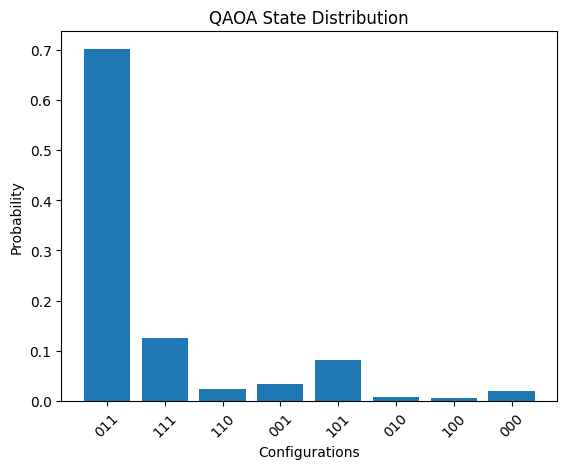

In [48]:
# firstly we need to use some data to generate a cost hamiltonian. For that, we actually use the qiskit-finance module

set_asset=["AAPL", "GOOG", "IBM"]#, "MSFT","TSLA",'CSCO']#,'INTC','AMZN','NVDA','AMD']


provider = RandomDataProvider(
    tickers=set_asset,             
    start=datetime.datetime(2016, 1, 1),
    end=datetime.datetime(2017, 1, 1),
    seed=42
)
provider.run()

mu = provider.get_period_return_mean_vector() * 250
sigma = provider.get_period_return_covariance_matrix() * 250

print("μ =", mu)
print("Σ =", sigma)


# Paramètres fixes du problème
num_assets = 3
p = 5
q = 1
C_fix = np.zeros(num_assets)      # max 3 assets
lambda_l = 0
liq = np.zeros(num_assets)
B = 2                        # we want to have exactly 2 assets in the portfolio            
A = 10                       # quantify the importance of the cardinaly constraints


hamiltonian = construct_cost_hamiltonian(num_assets, mu, sigma, q, B, A, C_fix, lambda_l, liq)


# now that we have created our hamiltonian to minimize, let's define the qaoa. We are actually lucky enough, qiskit-algorithm actually provides a already functionnal qaoa

p = 3  # Number of QAOA layers
optimizer = COBYLA(maxiter=5000)  # COBYLA optimizer with more iterations
sampler = Sampler()  # Initialize sampler
# initial_point = np.array([0.5, 0.5] * p)  # Optional initial parameters
qaoa = QAOA(sampler=sampler, optimizer=optimizer, reps=p)

# Run QAOA
result = qaoa.compute_minimum_eigenvalue(hamiltonian)

# Print results
print("Optimal value (energy):", result.eigenvalue)
print("Optimal parameters:", result.optimal_parameters)
print("State distribution:", result.eigenstate)

# Most probable configuration
most_likely_config = max(result.eigenstate.items(), key=lambda x: x[1])[0]
print("Most likely optimal configuration:", most_likely_config)

# Compute classical energy of a configuration
def compute_energy(config, H_C):
    bits = [int(c) for c in config]
    e = 0.0
    for pauli, coeff in zip(H_C.paulis, H_C.coeffs):
        val = coeff
        for i, p in enumerate(pauli.to_label()):
            if p == 'Z':
                val *= (1 if bits[i] == 0 else -1)
        e += val
    return float(e.real)

# Energies of all 3-qubit configurations  ( since the portfolio contains few assets, we can plot the value of the energy for each bitstring )
configs = ['000', '001', '010', '011', '100', '101', '110', '111']
for config in configs:
    print(f"Energy for {config}: {compute_energy(config, hamiltonian)}")

# Visualize state probabilities
states = list(result.eigenstate.keys())
probs = list(result.eigenstate.values())
plt.bar(states, probs)
plt.xlabel("Configurations")
plt.ylabel("Probability")
plt.title("QAOA State Distribution")
plt.xticks(rotation=45)
plt.show()


## Advanced QAOA Techniques – Detailed Explanation

This document explains the **advanced methods implemented in the provided QAOA code**, including alternative mixers, multi-angle QAOA, Fourier parameterization, genetic optimization, fermionic QAOA, noise modeling, and flexible circuit construction.

---

### 1. Alternative Mixer Hamiltonians

In QAOA, the **mixer Hamiltonian $H_M$** is applied between cost Hamiltonian layers to explore the solution space. Advanced mixers allow **better exploration, respect problem constraints, or encode physical structure**.

#### 1.1 Standard X Mixer
- **Definition**:  
$H_M = \sum_{i=1}^{n} X_i$  
- **Circuit Implementation**: Single-qubit rotations:  
$U_M(\beta) = \prod_{i} e^{-i \beta X_i}$  
- **Purpose**: Provides uniform mixing over all computational basis states.  
- **When to use**: Unconstrained combinatorial optimization, e.g., Max-Cut.

#### 1.2 Fermionic Mixer
- **Definition**:  
$H_M^{fermionic} = \sum_{i<j} (X_i X_j + Y_i Y_j)$  
- **Circuit Implementation**:  
Applies **XX+YY gates** between qubit pairs using a native decomposition.  
- **Purpose**: Preserves **particle number** or other symmetries.  
- **Use cases**: Quantum chemistry problems, constrained portfolio optimization.  

**Advantages**: Explores the Hilbert space along physically meaningful directions; respects problem constraints.

#### 1.3 Cat Map Mixer
- **Definition**: Inspired by classical chaotic maps.  
- **Circuit Implementation**: Hadamard + Z rotations on each qubit:  
$U_M^{cat}(\beta) = H \cdot R_z(2 \beta)$  
- **Purpose**: Introduces strong entangling and mixing patterns.  
- **Benefit**: Can escape **local minima** in rugged landscapes.

### 1.4 Mixer Selection
- The `get_mixer()` function dynamically selects the mixer type:  
  - `"x"` → standard X-mixer  
  - `"fermionic"` → fermionic mixer  
  - `"cat_map"` → cat map mixer  

This allows the QAOA algorithm to **adapt the mixer to the problem type**.

---

### 2. Multi-Angle QAOA (MA-QAOA)

- Standard QAOA assigns **one $\gamma$ per Hamiltonian term and one $\beta$ per layer**.  
- MA-QAOA assigns **distinct $\gamma_{i,j}$ per Pauli term and $\beta_i$ per qubit**.  

**Mathematical expression**:  
$|\psi(\boldsymbol{\gamma}, \boldsymbol{\beta})\rangle = \prod_{l=1}^{p} \left( e^{-i \sum_{k} \gamma_{l,k} P_k} e^{-i \sum_{i} \beta_{l,i} X_i} \right) |+\rangle^{\otimes n}$  

- **Advantages**:  
  - Higher expressivity of the quantum state.  
  - Can encode **anisotropic cost landscapes**.  
  - Improves solution quality for **heterogeneous interactions**.  

- **Trade-off**: More parameters → more difficult optimization; motivates **Fourier parameterization or global optimizers**.

---

### 3. Fourier-Parameterized Angles

- Instead of optimizing $p \cdot n$ parameters independently, use a **Fourier series expansion**:

$\gamma_l = \sum_{k=0}^{K} d_k \cos\left(\frac{2 \pi k l}{p}\right) + f_k \sin\left(\frac{2 \pi k l}{p}\right)$  
$\beta_l = \sum_{k=0}^{K} q_k \cos\left(\frac{2 \pi k l}{p}\right) + r_k \sin\left(\frac{2 \pi k l}{p}\right)$  

- **Benefits**:  
  - Smooth parameter variation across layers.  
  - Reduces number of independent parameters (from $p \cdot n$ to $(K+1) \cdot n$).  
  - Helps mitigate **barren plateaus**.  
- **Integration**: Works naturally with **multi-angle QAOA** to reduce optimization complexity.

---




### 4. Genetic Optimization

- Classical optimizers sometimes **struggle with non-smooth or noisy landscapes**.  
- Genetic Algorithm (GA) procedure:  
  1. Initialize a **population of parameters** randomly.  
  2. Evaluate **fitness** (QAOA energy).  
  3. Select top individuals.  
  4. Apply **mutation** to generate new population.  
  5. Repeat over multiple generations.  

- **Advantages**:
  - Escapes **local minima**.  
  - Works with **multi-angle or Fourier QAOA**.  
  - Handles **noisy cost functions**.

---

### 5. Noise Modeling

After a discussion with our mentor about the modelisation of the noise on the quantum computer, a good approximation of the noise that does not increases the depth and the complexity of the circuit is too add a gaussian noise on the energy measure at the end of the circuit

- Optional Gaussian noise simulates **hardware imperfections**:  
$E_{noisy} = E + \text{amplitude} \cdot \mathcal{N}(0, \sigma^2)$  
- **Parameters**:
  - `sigma`: standard deviation of noise  
  - `amplitude`: scaling factor  
- **Purpose**: Tests **robustness of optimized parameters** for NISQ devices.

---


### 6. Flexible Circuit Construction

- Initial states can be **uniform superposition** $(|+\rangle^{\otimes n})$ or **custom states**.  
- Circuit supports:
  - Arbitrary number of layers $p$  
  - Multi-angle or Fourier angles  
  - Custom mixers and connectivity (via `coupling_map`)  
- Allows QAOA to be **problem-adaptive and highly modular**.

---

### 7. Optimizer Wrapper

- Unified function `optimize_qaoa()` handles:  
  - Qiskit classical optimizers: COBYLA, SPSA, Nelder-Mead, L_BFGS_B  
  - Genetic algorithm for global search  
  - MA-QAOA and Fourier angles  
  - Noise, custom mixers, initial states, and coupling maps  

- **Purpose**: Provides **one-line integration** of all advanced techniques.

---

### 8. Summary Table

| Advanced Feature | Description | Benefit |
|-----------------|-------------|--------|
| Fermionic Mixer | XX+YY interactions between qubits | Preserves symmetries, optimal for cardinality constraint
| Cat Map Mixer | Hadamard + Z rotations | Escapes local minima, improves mixing |
| Multi-Angle QAOA | Distinct $\gamma$, $\beta$ per qubit/term | High expressivity, handles anisotropic landscapes |
| Fourier Parameterization | Angles as truncated Fourier series | Smooth parameters, fewer variables, mitigates barren plateaus |
| Genetic Algorithm | Population-based search | Escapes local minima, handles noise |
| Noise Modeling | Add Gaussian noise to cost | Tests robustness on NISQ hardware |
| Arbitrary Pauli Support | Supports X, Y, Z, ZZ gates | Handles any Hamiltonian, portfolio or chemistry problems |

---

## References




In [49]:
# This cell gives the general code that allows the user to do every test he wants wth advanced features of QAOA 

# -------------------------------
# Mixer definitions
# ------------------------------

def x_mixer(n_qubits, beta_vec):
    qc = QuantumCircuit(n_qubits)
    for q in range(n_qubits):
        qc.rx(2*beta_vec[q], q)
    return qc

def xx_plus_yy_native(qc, q1, q2, theta):
    qc.rz(np.pi/2, q2)
    qc.cx(q1, q2)
    qc.ry(theta, q2)
    qc.cx(q1, q2)
    qc.rz(-np.pi/2, q2)

def fermionic_mixer(n_qubits, beta, coupling_map=None):
    qc = QuantumCircuit(n_qubits)
    if coupling_map is None:
        pairs = [(i,j) for i in range(n_qubits) for j in range(i+1, n_qubits)]
    else:
        pairs = coupling_map.get_edges()
    for (i,j) in pairs:
        xx_plus_yy_native(qc, i, j, beta)
    return qc

def cat_map_mixer(n_qubits, beta):
    # Exemple simple : appliquer un Hadamard + rotations pour simuler "cat map"
    qc = QuantumCircuit(n_qubits)
    for q in range(n_qubits):
        qc.h(q)
        qc.rz(2*beta, q)
    return qc

def get_mixer(mixer_type, n_qubits, beta, coupling_map=None):
    if mixer_type == "x":
        beta_vec = np.array(beta).flatten()
        return x_mixer(n_qubits, beta_vec)
    elif mixer_type == "fermionic":
        # beta peut être un scalaire ou array
        beta_val = float(beta) if np.size(beta)==1 else float(beta[0])
        return fermionic_mixer(n_qubits, beta_val, coupling_map)
    elif mixer_type == "cat_map":
        beta_val = float(beta) if np.size(beta)==1 else float(beta[0])
        return cat_map_mixer(n_qubits, beta_val)
    else:
        raise ValueError("Mixer inconnu")


# -------------------------------
# Fourier angles
# -------------------------------

def generate_angles_fourier(q_coeffs, d_coeffs, p, num_qubits, num_terms):
    """
    q_coeffs: shape (K+1, num_qubits)
    d_coeffs: shape (K+1, num_terms)
    """
    K = q_coeffs.shape[0]-1
    gamma_vec, beta_vec = [], []
    
    for layer in range(p):
        gamma_layer = np.zeros(num_terms)
        beta_layer = np.zeros(num_qubits)
        for k in range(K+1):
            phase = np.cos(2*np.pi*k*layer/p) + np.sin(2*np.pi*k*layer/p)
            gamma_layer += d_coeffs[k,:] * phase
            beta_layer  += q_coeffs[k,:] * phase
        gamma_vec.append([float(np.real(g)) for g in gamma_layer])
        beta_vec.append([float(np.real(b)) for b in beta_layer])
    return gamma_vec, beta_vec

# -------------------------------
# Apply Pauli term
# -------------------------------

def apply_pauli_term(qc, pauli_label, coeff, gamma):
    qubits = [i for i, p in enumerate(pauli_label) if p != 'I']
    coeff = float(np.real(coeff))
    gamma = float(np.real(gamma))
    
    if pauli_label.count('Z') == 2 and len(qubits) == 2:
        qc.append(RZZGate(2 * gamma * coeff), qubits)
    elif pauli_label.count('Z') == 1:
        qc.rz(2 * gamma * coeff, qubits[0])
    elif pauli_label.count('X') == 1:
        qc.rx(2 * gamma * coeff, qubits[0])
    elif pauli_label.count('Y') == 1:
        qc.ry(2 * gamma * coeff, qubits[0])
    return qc


# -------------------------------
# Build QAOA circuit
# -------------------------------

def build_qaoa_circuit(num_qubits, p, hamiltonian, gamma_vec, beta_vec, mixer_type="x", coupling_map=None, init_state=None):
    qc = QuantumCircuit(num_qubits)
    
    if init_state is None:
        qc.h(range(num_qubits))
    else:
        qc.compose(init_state, inplace=True)
    
    num_terms = len(hamiltonian.coeffs)
    
    for layer in range(p):
        for idx, (pauli_term, coeff) in enumerate(zip(hamiltonian.paulis, hamiltonian.coeffs)):
            qc = apply_pauli_term(qc, pauli_term.to_label(), coeff, gamma_vec[layer][idx])
        mixer_circ = get_mixer(mixer_type, num_qubits, beta_vec[layer], coupling_map)
        qc = qc.compose(mixer_circ)
    
    return qc

# -------------------------------
# Unpack parameters
# -------------------------------

def unpack_params(params, num_qubits, p, hamiltonian, use_ma_qaoa=True, use_fourier=True, K=2):
    num_terms = len(hamiltonian.coeffs)
    
    if use_ma_qaoa and use_fourier:
        num_beta_params  = (K+1) * num_qubits
        num_gamma_params = (K+1) * num_terms
        total_params = num_beta_params + num_gamma_params
        
        if len(params) != total_params:
            raise ValueError(f"Params length {len(params)} != expected {total_params}")
        
        q_coeffs = np.array(params[:num_beta_params]).reshape((K+1, num_qubits))
        d_coeffs = np.array(params[num_beta_params: num_beta_params+num_gamma_params]).reshape((K+1, num_terms))
        
        gamma_vec, beta_vec = generate_angles_fourier(q_coeffs, d_coeffs, p, num_qubits, num_terms)
    
    elif use_ma_qaoa:
        gamma_vec = [params[:num_terms] for _ in range(p)]
        beta_vec  = [params[num_terms:num_terms+num_qubits] for _ in range(p)]
    
    else:
        gamma_vec = [[params[0]]*num_terms for _ in range(p)]
        beta_vec  = [[params[1]]*num_qubits for _ in range(p)]
    
    return gamma_vec, beta_vec

# -------------------------------
# QAOA cost function
# -------------------------------

def qaoa_cost(params, num_qubits, p, hamiltonian, use_ma_qaoa=True, use_fourier=True, K=2, mixer_type="x",
              init_state=None, add_noise=False, sigma=0.01, amplitude=1.0, coupling_map=None):
    
    gamma_vec, beta_vec = unpack_params(params, num_qubits, p, hamiltonian, use_ma_qaoa, use_fourier, K)
    qc = build_qaoa_circuit(num_qubits, p, hamiltonian, gamma_vec, beta_vec, mixer_type, coupling_map, init_state)
    qc.save_statevector()
    backend = AerSimulator()
    result = backend.run(qc).result()
    state = result.get_statevector()
    energy = np.real(Statevector(state).expectation_value(hamiltonian))
    
    if add_noise:
        energy += amplitude*np.random.normal(0, sigma)
    
    return energy

# -------------------------------
# Genetic optimizer
# -------------------------------

def genetic_optimizer(cost_fn, num_params, pop_size=50, generations=100, mutation_rate=0.1):
    # Initialisation aléatoire de la population
    population = [np.random.randn(num_params) for _ in range(pop_size)]
    best_params = None
    best_value = float("inf")

    for gen in range(generations):
        # Évaluer chaque individu
        fitness = [cost_fn(ind) for ind in population]

        # Trouver le meilleur de la génération
        gen_best_idx = np.argmin(fitness)
        gen_best_value = fitness[gen_best_idx]
        gen_best_params = population[gen_best_idx]

        # Mettre à jour le meilleur global
        if gen_best_value < best_value:
            best_value = gen_best_value
            best_params = gen_best_params

        # Affichage génération + énergie
        print(f"Generation {gen+1}/{generations}, Best Energy = {best_value:.6f}")

        # Sélection + mutation (exemple simple)
        selected = population[:pop_size//2]  # simple sélection top50%
        new_population = []
        while len(new_population) < pop_size:
            parent = selected[np.random.randint(len(selected))]
            child = parent + mutation_rate * np.random.randn(num_params)
            new_population.append(child)
        population = new_population

    return best_params, best_value

# -------------------------------
# Optimizer wrapper
# -------------------------------

def optimize_qaoa(num_qubits, p, hamiltonian, K=2, use_ma_qaoa=True, use_fourier=True, mixer_type="x",
                  optimizer_type="qiskit", qiskit_optimizer="COBYLA", maxiter=50, lr=0.1,
                  init_params=None, add_noise=True, sigma=0.01, amplitude=1.0, coupling_map=None,verbose=False):
    
    num_terms = len(hamiltonian.coeffs)
    
    if use_ma_qaoa and use_fourier:
        num_beta_params  = (K+1) * num_qubits
        num_gamma_params = (K+1) * num_terms
        num_params = num_beta_params + num_gamma_params
    elif use_ma_qaoa:
        num_params = num_terms + num_qubits
    else:
        num_params = p*num_terms + p*num_qubits
    
    if init_params is None:
        params = 0.1*np.random.randn(num_params)
    else:
        params = init_params.copy()
    
    def cost_fn(x):
        return qaoa_cost(x, num_qubits, p, hamiltonian, use_ma_qaoa, use_fourier, K, mixer_type,
                         add_noise=add_noise, sigma=sigma, amplitude=amplitude, coupling_map=coupling_map)
    
    if optimizer_type=="qiskit":
        if qiskit_optimizer.upper()=="COBYLA":
            optimizer = COBYLA(maxiter=maxiter)
        elif qiskit_optimizer.upper()=="SPSA":
            optimizer = SPSA(maxiter=maxiter)
        elif qiskit_optimizer.upper()=="NELDER_MEAD":
            optimizer = NELDER_MEAD(maxiter=maxiter)
        elif qiskit_optimizer.upper()=="L_BFGS_B":
            optimizer = L_BFGS_B(maxiter=maxiter)
        else:
            raise ValueError("Optimizer non reconnu")
        result = optimizer.minimize(cost_fn, x0=params)
        return result.x
    
    elif optimizer_type=="genetic":
        best_params, best_value = genetic_optimizer(
            cost_fn,
            num_params,
            pop_size=50,
            generations=maxiter,
            mutation_rate=0.6,
             # <- ajout pour afficher chaque génération
        )
        return np.array(best_params)
    
    else:
        raise ValueError("Optimizer non reconnu")


In [50]:
# -------------------------
# FUNCTION TO ANALYZE GENERALISED QAOA OUTPUT
# -------------------------

# -------------------------
# Compute the expected return of a bitstring
# bitstring: string of 0/1 representing portfolio selection
# mu: vector of expected returns
# -------------------------

def bitstring_rendement(bitstring, mu):
    return sum(int(b)*m for b, m in zip(bitstring, mu))

# -------------------------
# Compute the true Sharpe ratio for a bitstring
# w = bitstring as 0/1 vector
# mu = expected returns vector
# Sigma = covariance matrix
# Rf = risk-free rate (default 0)
# -------------------------

def bitstring_sharpe(bitstring, mu, Sigma, Rf=0.0):
    w = np.array([int(b) for b in bitstring])
    if w.sum() == 0:  # avoid division by zero
        return 0.0
    w = w / w.sum()  # normalize weights to sum to 1
    R_p = np.dot(w, mu)  # portfolio return
    sigma_p = np.sqrt(w @ Sigma @ w)  # portfolio volatility
    return (R_p - Rf) / sigma_p if sigma_p > 0 else 0.0

# -------------------------
# Full analysis function using true Sharpe ratio
# counts: dictionary of bitstring counts from QAOA
# mu: expected returns
# Sigma: covariance matrix
# top_k: number of top bitstrings to highlight
# Rf: risk-free rate
# title: plot title
# -------------------------

def plot_qaoa_bitstrings(counts, mu, Sigma, top_k=3, Rf=0.0, title="QAOA Portfolios"):
    bitstrings = list(counts.keys())
    counts_vals = np.array(list(counts.values()))
    probs = counts_vals / counts_vals.sum()
    
    # Identify top_k most probable bitstrings
    top_indices = np.argsort(probs)[-top_k:][::-1]
    top_bitstrings = [bitstrings[i] for i in top_indices]
    
    # 1️⃣ Histogram of all bitstrings
    colors = ['orange']*len(bitstrings)
    for idx in top_indices:
        colors[idx] = 'red'
    plt.figure(figsize=(10,5))
    plt.bar(bitstrings, counts_vals, color=colors, alpha=0.7)
    plt.xlabel("Bitstrings")
    plt.ylabel("Counts")
    plt.title(f"{title} : Bitstring distribution (Top {top_k} in red)")
    plt.show()
    
    # 2️⃣ Expected return of top_k portfolios
    R_top = [bitstring_rendement(bs, mu) for bs in top_bitstrings]
    plt.figure(figsize=(8,5))
    plt.bar(top_bitstrings, R_top, color='green', alpha=0.7)
    plt.ylabel("Expected Return")
    plt.title(f"{title} : Expected return of top {top_k} most probable portfolios")
    for i, r in enumerate(R_top):
        plt.text(i, r+0.005, f"{r:.3f}", ha='center')
    plt.show()
    
    # 3️⃣ True Sharpe ratio of top_k portfolios
    S_top = [bitstring_sharpe(bs, mu, Sigma, Rf) for bs in top_bitstrings]
    plt.figure(figsize=(8,5))
    plt.bar(top_bitstrings, S_top, color='blue', alpha=0.7)
    plt.ylabel("Sharpe Ratio")
    plt.title(f"{title} : Sharpe ratio of top {top_k} most probable portfolios")
    for i, s in enumerate(S_top):
        plt.text(i, s+0.01, f"{s:.3f}", ha='center')
    plt.show()
    
    return top_bitstrings, R_top, S_top, probs[top_indices]

# -------------------------
# Convert a bitstring to a portfolio of selected assets
# bitstring: string of 0/1
# assets: list of asset names
# -------------------------

def bitstring_to_portfolio(bitstring, assets):
    return [assets[i] for i, bit in enumerate(bitstring) if bit == "1"]


μ = [ 1.50853605 -0.46831852  0.25824922  0.27260626 -1.02826933 -0.44285189]
Σ = [[ 3.58457682e+00  2.64438870e-02 -4.98237604e-03 -4.09011224e-02
  -4.07177950e-03  2.02007560e-01]
 [ 2.64438870e-02  1.36012063e-01  1.93869140e-02 -1.02882427e-02
  -1.36657183e-02 -8.82663479e-03]
 [-4.98237604e-03  1.93869140e-02  1.95059306e-01 -2.70148491e-02
  -5.13514562e-03  3.08963728e-02]
 [-4.09011224e-02 -1.02882427e-02 -2.70148491e-02  5.22632396e-01
  -1.74357272e-02 -1.78533102e-01]
 [-4.07177950e-03 -1.36657183e-02 -5.13514562e-03 -1.74357272e-02
   8.55151095e-01 -9.56585282e-03]
 [ 2.02007560e-01 -8.82663479e-03  3.08963728e-02 -1.78533102e-01
  -9.56585282e-03  1.50639451e+01]]
Constructed cost Hamiltonian: SparsePauliOp(['IIIIII', 'ZIIIII', 'IZIIII', 'IIZIII', 'IIIZII', 'IIIIZI', 'IIIIIZ', 'ZZIIII', 'ZIZIII', 'ZIIZII', 'ZIIIZI', 'ZIIIIZ', 'IZZIII', 'IZIZII', 'IZIIZI', 'IZIIIZ', 'IIZZII', 'IIZIZI', 'IIZIIZ', 'IIIZZI', 'IIIZIZ', 'IIIIZZ'],
              coeffs=[20.01852538+0.j, -0.231

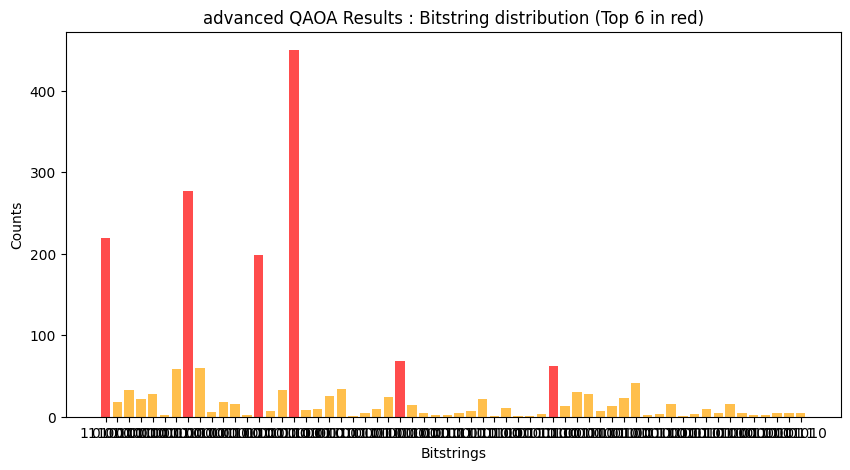

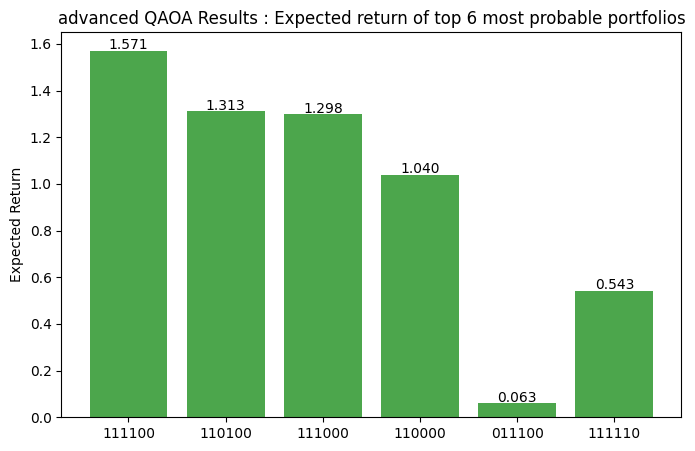

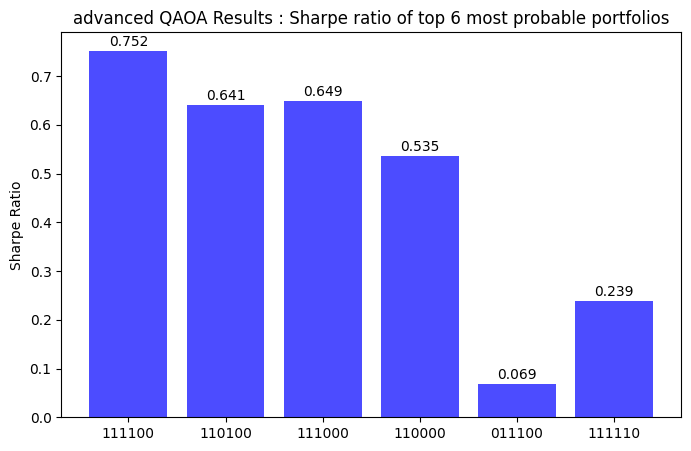

['AAPL', 'GOOG', 'IBM', 'MSFT']


In [51]:
# -------------------------
# Define the set of assets for portfolio optimization
# -------------------------

set_asset = ["AAPL", "GOOG", "IBM", "MSFT","TSLA",'CSCO']  # Asset tickers

# -------------------------
# Initialize a random data provider for historical returns
# -------------------------

provider = RandomDataProvider(
    tickers=set_asset,             # Tick labels
    start=datetime.datetime(2016, 1, 1),  # Start date for data
    end=datetime.datetime(2017, 1, 1),    # End date for data
    seed=42                             # Random seed for reproducibility
)
provider.run()  # Generate random historical price data

# Compute annualized expected returns μ and covariance Σ
mu = provider.get_period_return_mean_vector() * 250        # Annualized mean returns
sigma = provider.get_period_return_covariance_matrix() * 250  # Annualized covariance

print("μ =", mu)
print("Σ =", sigma)

# -------------------------
# Fixed parameters for the QAOA problem
# -------------------------

num_assets = 6     # Number of assets (number of qubits)
p = 3              # QAOA depth (number of layers)
K = 6              # Number of Fourier modes if Fourier angles used
q = 1              # Risk-aversion parameter in Hamiltonian
C_fix = np.zeros(num_assets)  # Fixed contributions to cost
lambda_l = 0       # Liquidity penalty weight
liq = np.zeros(num_assets)    # Liquidity vector
B = 3              # Budget constraint (max number of assets to select)
A = 10             # Penalty strength for budget constraint
maxiter = 3000     # Maximum iterations for classical optimization

# -------------------------
# Construct the QAOA Hamiltonian for portfolio optimization
# -------------------------

hamiltonian = construct_cost_hamiltonian(num_assets, mu, sigma, q, B, A, C_fix, lambda_l, liq)
num_terms = len(hamiltonian)  # Number of Pauli terms in the Hamiltonian

# -------------------------
# Example of QAOA usage
# -------------------------

use_ma_qaoa = False         # Multi-angle QAOA disabled
use_fourier = False         # Fourier parameterization disabled
mixer_type = "cat_map"      # Mixer type: "x", "fermionic", or "cat_map"
optimizer_type = "genetic"  # Classical optimizer: "qiskit" or "genetic"
qiskit_optimizer = "SPSA"   # Ignored if optimizer_type="genetic"

num_qubits = num_assets     # One qubit per asset

# -------------------------
# Run QAOA optimization
# Returns optimal parameters (gamma/beta)
# -------------------------

optimal_params = optimize_qaoa(
    num_qubits=num_qubits,
    p=p,
    hamiltonian=hamiltonian,
    K=K,
    use_ma_qaoa=use_ma_qaoa,
    use_fourier=use_fourier,
    mixer_type=mixer_type,
    optimizer_type=optimizer_type,
    qiskit_optimizer=qiskit_optimizer,
    maxiter=50,       # Number of iterations / generations
    add_noise=True,   # Add stochastic noise to simulate hardware
    amplitude=10,     # Noise amplitude
    sigma=0.1,        # Standard deviation of Gaussian noise
    verbose=True      # Print progress
)

# -------------------------
# Unpack gamma and beta from the optimal parameters
# -------------------------

gamma_vec, beta_vec = unpack_params(optimal_params, num_qubits, p, hamiltonian,
                                   use_ma_qaoa, use_fourier, K=K)

# Ensure real floats (in case of complex numbers)
gamma_vec = [[float(np.real(g)) for g in layer] for layer in gamma_vec]
beta_vec  = [[float(np.real(b)) for b in layer] for layer in beta_vec]

# -------------------------
# Build the QAOA quantum circuit
# -------------------------

qc = build_qaoa_circuit(num_qubits, p, hamiltonian, gamma_vec, beta_vec, mixer_type)
qc.measure_all()  # Add measurement to all qubits

# -------------------------
# Simulate the circuit using the Aer simulator
# -------------------------

backend = AerSimulator()
result = backend.run(qc, shots=2000).result()  # 2000 measurement shots
counts = result.get_counts()                   # Measurement counts
print(counts)

# -------------------------
# Visualize the QAOA results
# -------------------------

from qiskit.visualization import plot_histogram

print(optimal_params)          # Print optimized gamma/beta values
plot_histogram(counts)         # Plot histogram of measured bitstrings

# Analyze top bitstrings with portfolio metrics
plot_qaoa_bitstrings(counts, mu, sigma, top_k=6, title="advanced QAOA Results")

# Identify best bitstring (highest probability) and convert to portfolio
best_bitstring = max(counts, key=counts.get)  # Example: "101010"
portfolio = bitstring_to_portfolio(best_bitstring, assets=set_asset)
print(portfolio)  # Display selected assets


---- Analyse du circuit ----
Profondeur totale : 26
Portes 1-qubit : 24
Portes 2-qubits : 45
Opérations non-unitaires (measure/reset/barrier) : 7
Détail par type : OrderedDict([('rzz', 45), ('u2', 24), ('measure', 6), ('barrier', 1)])


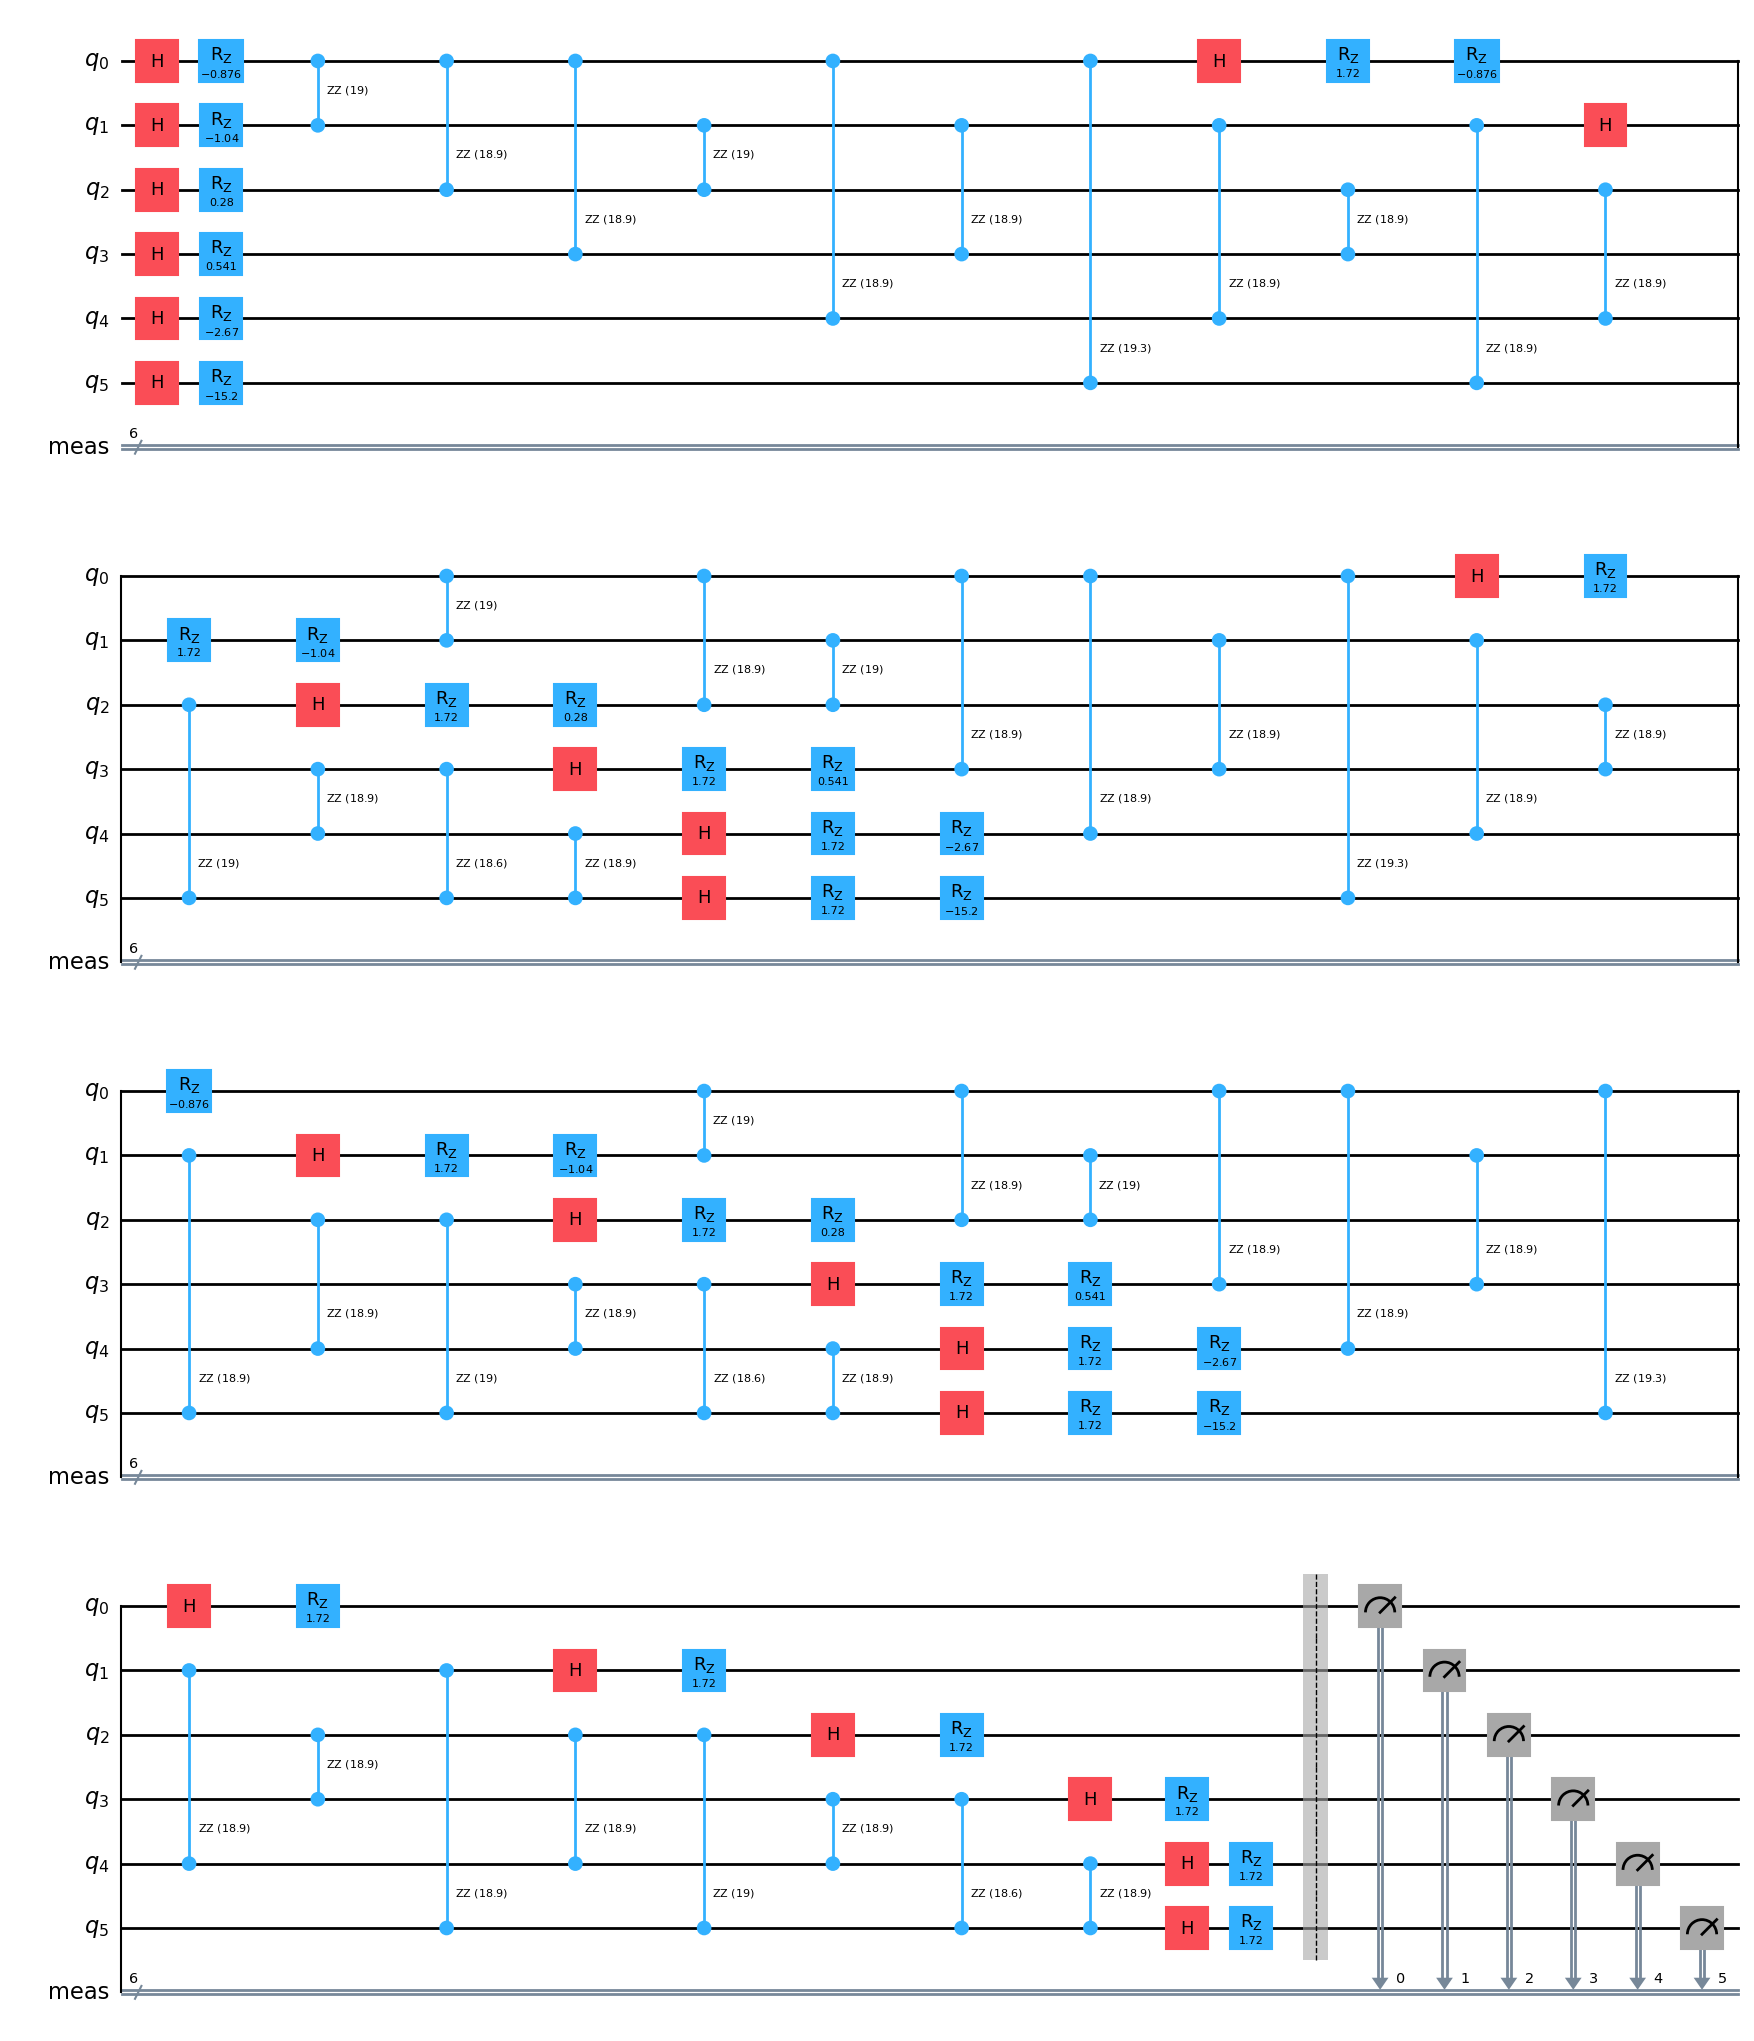

In [52]:
analyze_circuit(qc,backend=None)
qc.draw('mpl')

let's show some other circuits generated by this function 

Generation 1/50, Best Energy = 12.405318
Generation 2/50, Best Energy = 12.405318
Generation 3/50, Best Energy = 12.405318
Generation 4/50, Best Energy = 12.405318
Generation 5/50, Best Energy = 12.405318
Generation 6/50, Best Energy = 10.829683
Generation 7/50, Best Energy = 10.829683
Generation 8/50, Best Energy = 10.829683
Generation 9/50, Best Energy = 10.829683
Generation 10/50, Best Energy = 10.829683
Generation 11/50, Best Energy = 10.829683
Generation 12/50, Best Energy = 10.829683
Generation 13/50, Best Energy = 10.829683
Generation 14/50, Best Energy = 10.829683
Generation 15/50, Best Energy = 10.829683
Generation 16/50, Best Energy = 10.829683
Generation 17/50, Best Energy = 10.829683
Generation 18/50, Best Energy = 10.829683
Generation 19/50, Best Energy = 10.829683
Generation 20/50, Best Energy = 10.829683
Generation 21/50, Best Energy = 10.829683
Generation 22/50, Best Energy = 10.829683
Generation 23/50, Best Energy = 10.829683
Generation 24/50, Best Energy = 10.829683
G

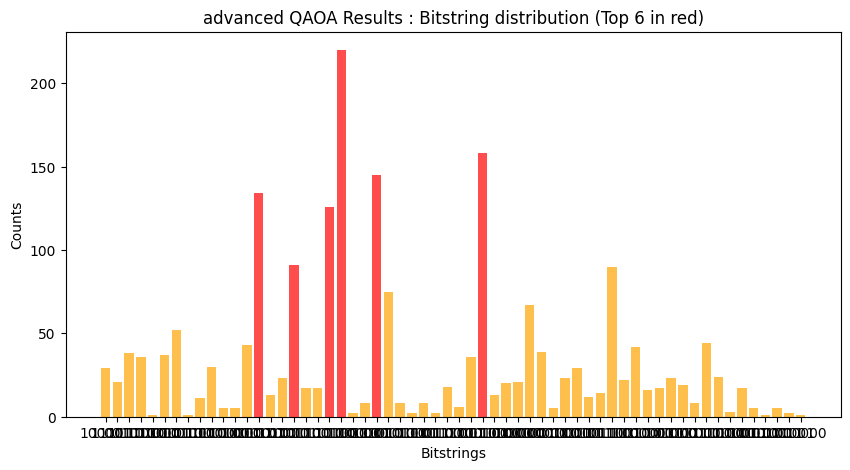

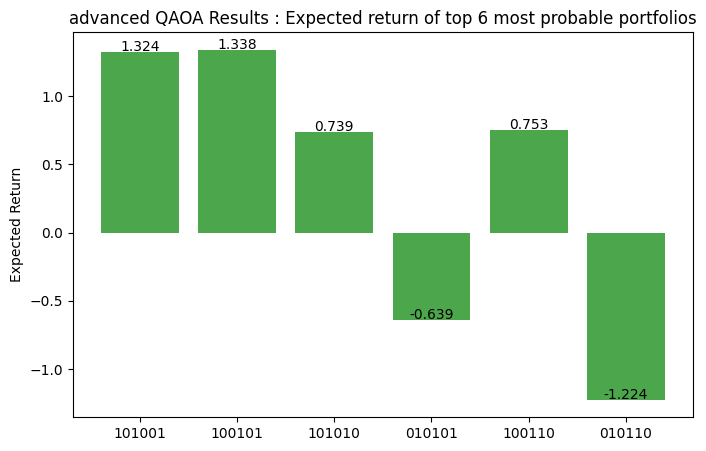

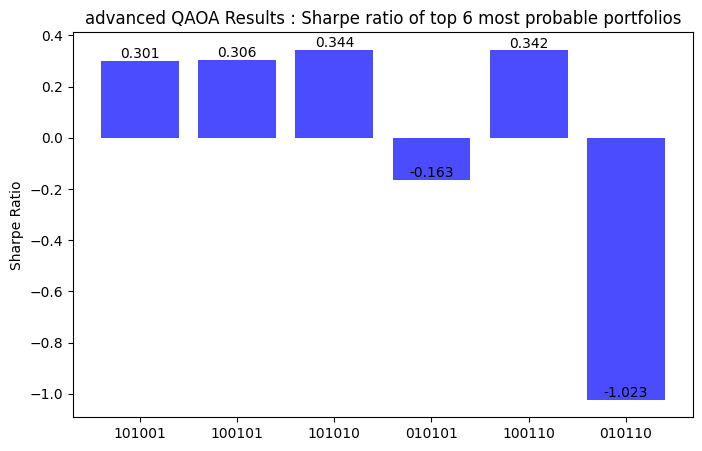

['AAPL', 'IBM', 'CSCO']


In [53]:

use_ma_qaoa = False         # Multi-angle QAOA disabled
use_fourier = False         # Fourier parameterization disabled
mixer_type = "fermionic"      # Mixer type: "x", "fermionic", or "cat_map"
optimizer_type = "genetic"  # Classical optimizer: "qiskit" or "genetic"
qiskit_optimizer = "SPSA"   # Ignored if optimizer_type="genetic"

num_qubits = num_assets     # One qubit per asset

# -------------------------
# Run QAOA optimization
# Returns optimal parameters (gamma/beta)
# -------------------------

optimal_params = optimize_qaoa(
    num_qubits=num_qubits,
    p=p,
    hamiltonian=hamiltonian,
    K=K,
    use_ma_qaoa=use_ma_qaoa,
    use_fourier=use_fourier,
    mixer_type=mixer_type,
    optimizer_type=optimizer_type,
    qiskit_optimizer=qiskit_optimizer,
    maxiter=50,       # Number of iterations / generations
    add_noise=True,   # Add stochastic noise to simulate hardware
    amplitude=10,     # Noise amplitude
    sigma=0.1,        # Standard deviation of Gaussian noise
    verbose=True      # Print progress
)

# -------------------------
# Unpack gamma and beta from the optimal parameters
# -------------------------

gamma_vec, beta_vec = unpack_params(optimal_params, num_qubits, p, hamiltonian,
                                   use_ma_qaoa, use_fourier, K=K)

# Ensure real floats (in case of complex numbers)
gamma_vec = [[float(np.real(g)) for g in layer] for layer in gamma_vec]
beta_vec  = [[float(np.real(b)) for b in layer] for layer in beta_vec]

# -------------------------
# Build the QAOA quantum circuit
# -------------------------

qc = build_qaoa_circuit(num_qubits, p, hamiltonian, gamma_vec, beta_vec, mixer_type)
qc.measure_all()  # Add measurement to all qubits

# -------------------------
# Simulate the circuit using the Aer simulator
# -------------------------

backend = AerSimulator()
result = backend.run(qc, shots=2000).result()  # 2000 measurement shots
counts = result.get_counts()                   # Measurement counts
print(counts)

# -------------------------
# Visualize the QAOA results
# -------------------------

from qiskit.visualization import plot_histogram

print(optimal_params)          # Print optimized gamma/beta values
plot_histogram(counts)         # Plot histogram of measured bitstrings

# Analyze top bitstrings with portfolio metrics
plot_qaoa_bitstrings(counts, mu, sigma, top_k=6, title="advanced QAOA Results")

# Identify best bitstring (highest probability) and convert to portfolio
best_bitstring = max(counts, key=counts.get)  # Example: "101010"
portfolio = bitstring_to_portfolio(best_bitstring, assets=set_asset)
print(portfolio)  # Display selected assets


---- Analyse du circuit ----
Profondeur totale : 99
Portes 1-qubit : 83
Portes 2-qubits : 135
Opérations non-unitaires (measure/reset/barrier) : 7
Détail par type : OrderedDict([('cx', 90), ('rzz', 45), ('ry', 45), ('rz', 32), ('u2', 6), ('measure', 6), ('barrier', 1)])


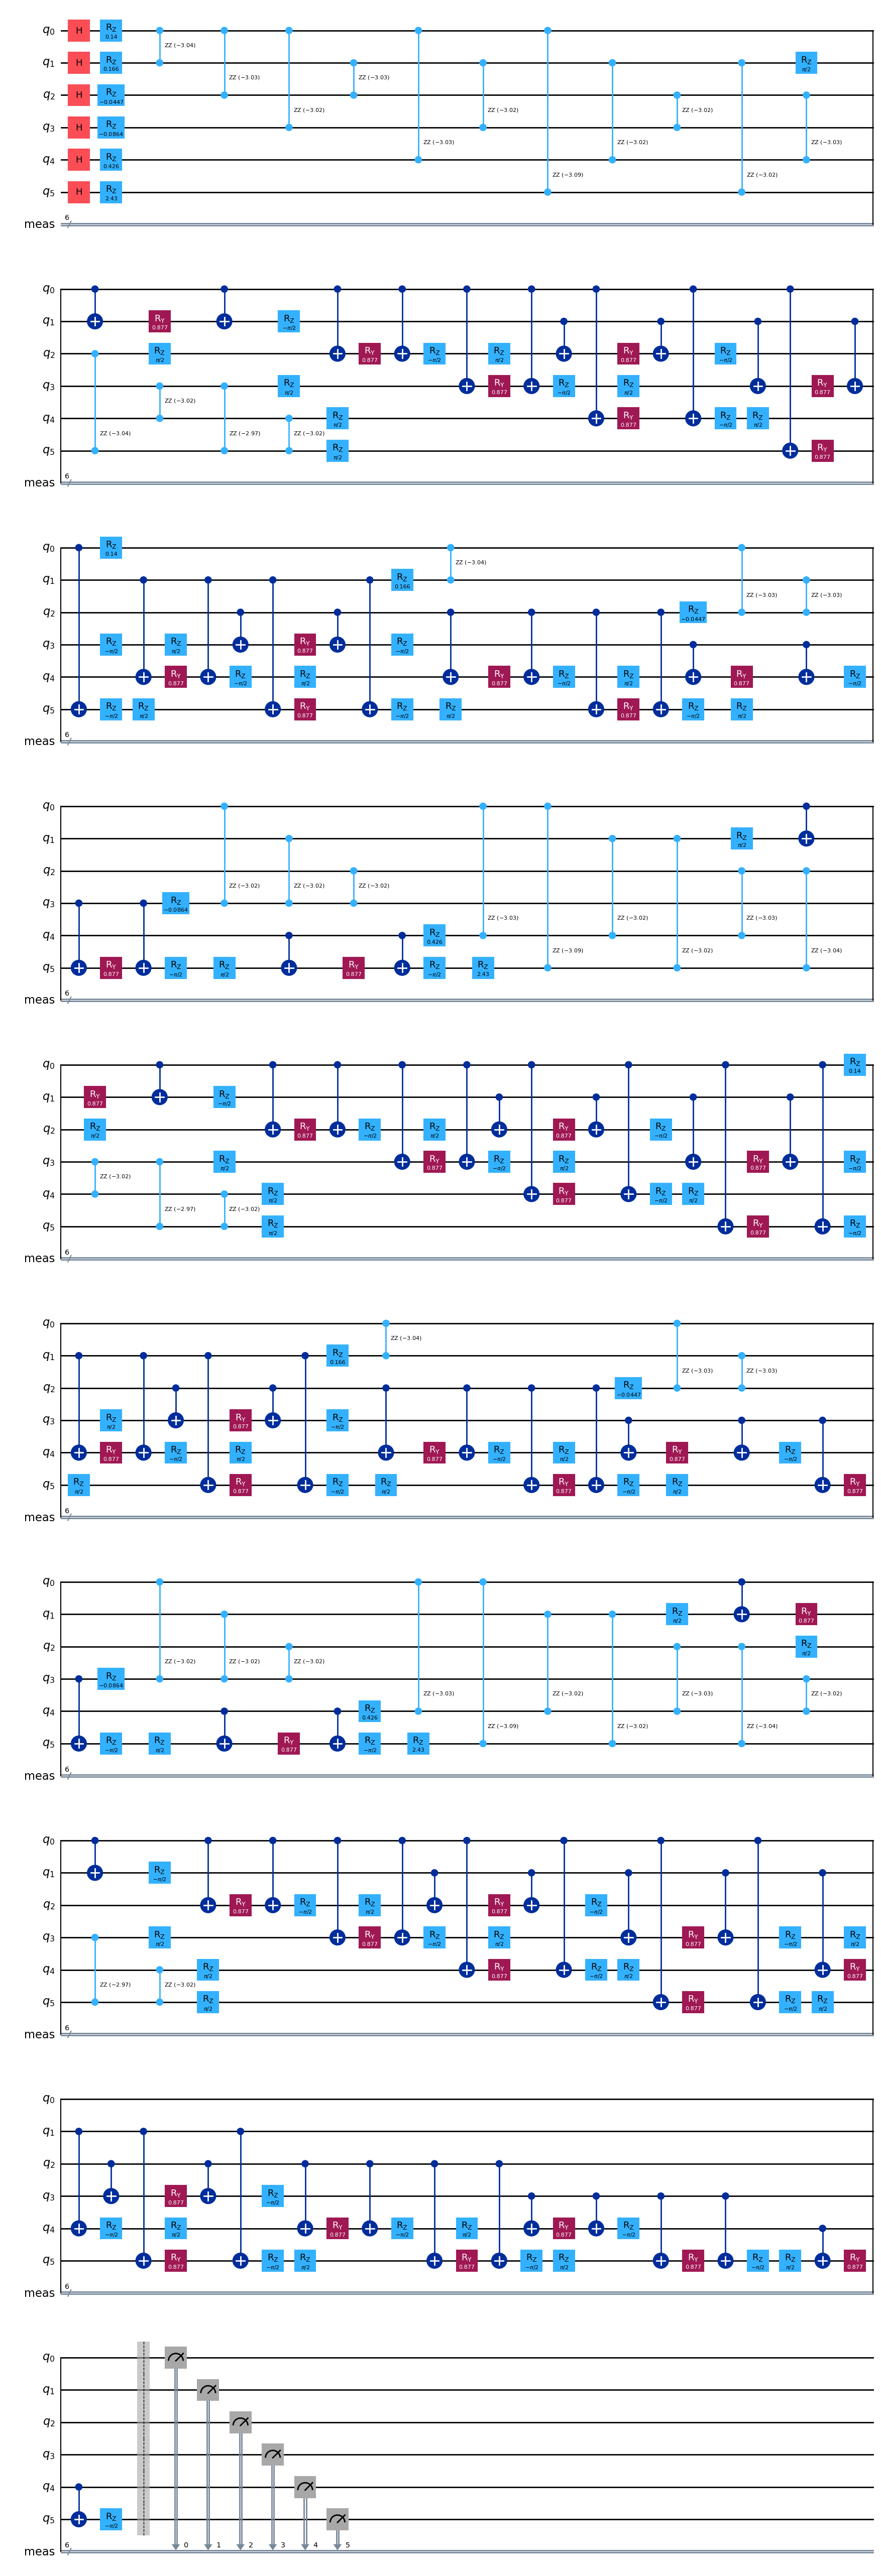

In [54]:
analyze_circuit(qc,backend=None)
qc.draw('mpl')

{'110001': 13, '000110': 69, '101111': 78, '011101': 69, '100000': 31, '110111': 6, '000000': 15, '110110': 4, '101010': 40, '000001': 98, '101101': 32, '000100': 9, '110011': 19, '111000': 35, '001110': 1, '111011': 16, '100101': 17, '110100': 1, '000011': 5, '101100': 40, '011010': 19, '001100': 24, '100011': 6, '111101': 60, '101001': 55, '101000': 85, '100111': 23, '010001': 71, '010011': 58, '011111': 18, '001101': 4, '111100': 5, '100100': 183, '001111': 90, '100110': 30, '111010': 35, '110000': 1, '000111': 36, '000010': 8, '110101': 5, '011100': 81, '010111': 17, '000101': 71, '110010': 60, '001000': 28, '011011': 6, '011110': 89, '010101': 11, '010010': 10, '001001': 4, '100001': 14, '001010': 7, '111111': 29, '100010': 9, '111110': 12, '001011': 57, '010100': 19, '011000': 33, '010110': 14, '111001': 7, '010000': 3, '011001': 5}
[ 0.62591148 -1.09535312  0.56926967 -2.16488126 -2.16006523  0.10972945
 -1.43924135  0.98079632  0.22157135 -0.1871194   1.01738034  3.73595202
 -0

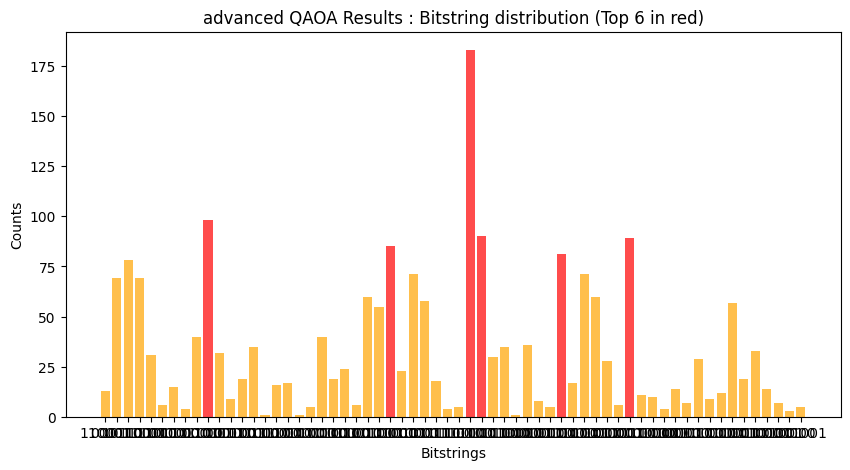

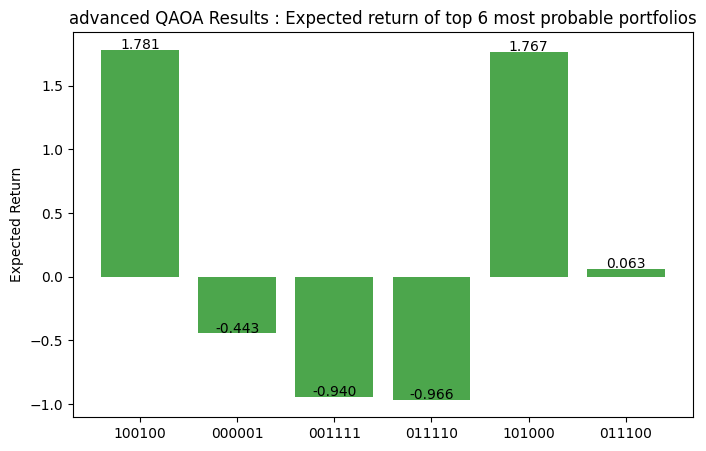

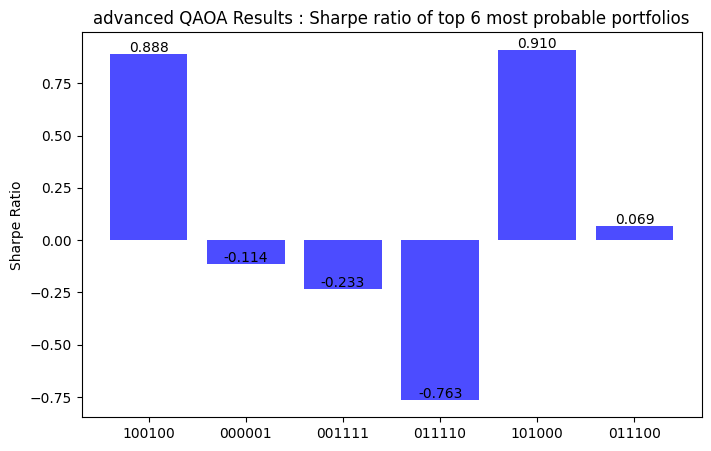

['AAPL', 'MSFT']


In [55]:

use_ma_qaoa = True        # Multi-angle QAOA disabled
use_fourier = False         # Fourier parameterization disabled
mixer_type = "x"      # Mixer type: "x", "fermionic", or "cat_map"
optimizer_type = "qiskit"  # Classical optimizer: "qiskit" or "genetic"
qiskit_optimizer = "SPSA"   # Ignored if optimizer_type="genetic"

num_qubits = num_assets     # One qubit per asset

# -------------------------
# Run QAOA optimization
# Returns optimal parameters (gamma/beta)
# -------------------------

optimal_params = optimize_qaoa(
    num_qubits=num_qubits,
    p=p,
    hamiltonian=hamiltonian,
    K=K,
    use_ma_qaoa=use_ma_qaoa,
    use_fourier=use_fourier,
    mixer_type=mixer_type,
    optimizer_type=optimizer_type,
    qiskit_optimizer=qiskit_optimizer,
    maxiter=1000,       # Number of iterations / generations
    add_noise=False,   # Add stochastic noise to simulate hardware
    amplitude=10,     # Noise amplitude
    sigma=0.1,        # Standard deviation of Gaussian noise
    verbose=True      # Print progress
)

# -------------------------
# Unpack gamma and beta from the optimal parameters
# -------------------------

gamma_vec, beta_vec = unpack_params(optimal_params, num_qubits, p, hamiltonian,
                                   use_ma_qaoa, use_fourier, K=K)

# Ensure real floats (in case of complex numbers)
gamma_vec = [[float(np.real(g)) for g in layer] for layer in gamma_vec]
beta_vec  = [[float(np.real(b)) for b in layer] for layer in beta_vec]

# -------------------------
# Build the QAOA quantum circuit
# -------------------------

qc = build_qaoa_circuit(num_qubits, p, hamiltonian, gamma_vec, beta_vec, mixer_type)
qc.measure_all()  # Add measurement to all qubits

# -------------------------
# Simulate the circuit using the Aer simulator
# -------------------------

backend = AerSimulator()
result = backend.run(qc, shots=2000).result()  # 2000 measurement shots
counts = result.get_counts()                   # Measurement counts
print(counts)

# -------------------------
# Visualize the QAOA results
# -------------------------

from qiskit.visualization import plot_histogram

print(optimal_params)          # Print optimized gamma/beta values
plot_histogram(counts)         # Plot histogram of measured bitstrings

# Analyze top bitstrings with portfolio metrics
plot_qaoa_bitstrings(counts, mu, sigma, top_k=6, title="advanced QAOA Results")

# Identify best bitstring (highest probability) and convert to portfolio
best_bitstring = max(counts, key=counts.get)  # Example: "101010"
portfolio = bitstring_to_portfolio(best_bitstring, assets=set_asset)
print(portfolio)  # Display selected assets


---- Analyse du circuit ----
Profondeur totale : 26
Portes 1-qubit : 24
Portes 2-qubits : 45
Opérations non-unitaires (measure/reset/barrier) : 7
Détail par type : OrderedDict([('rzz', 45), ('u3', 12), ('u2', 6), ('rx', 6), ('measure', 6), ('barrier', 1)])


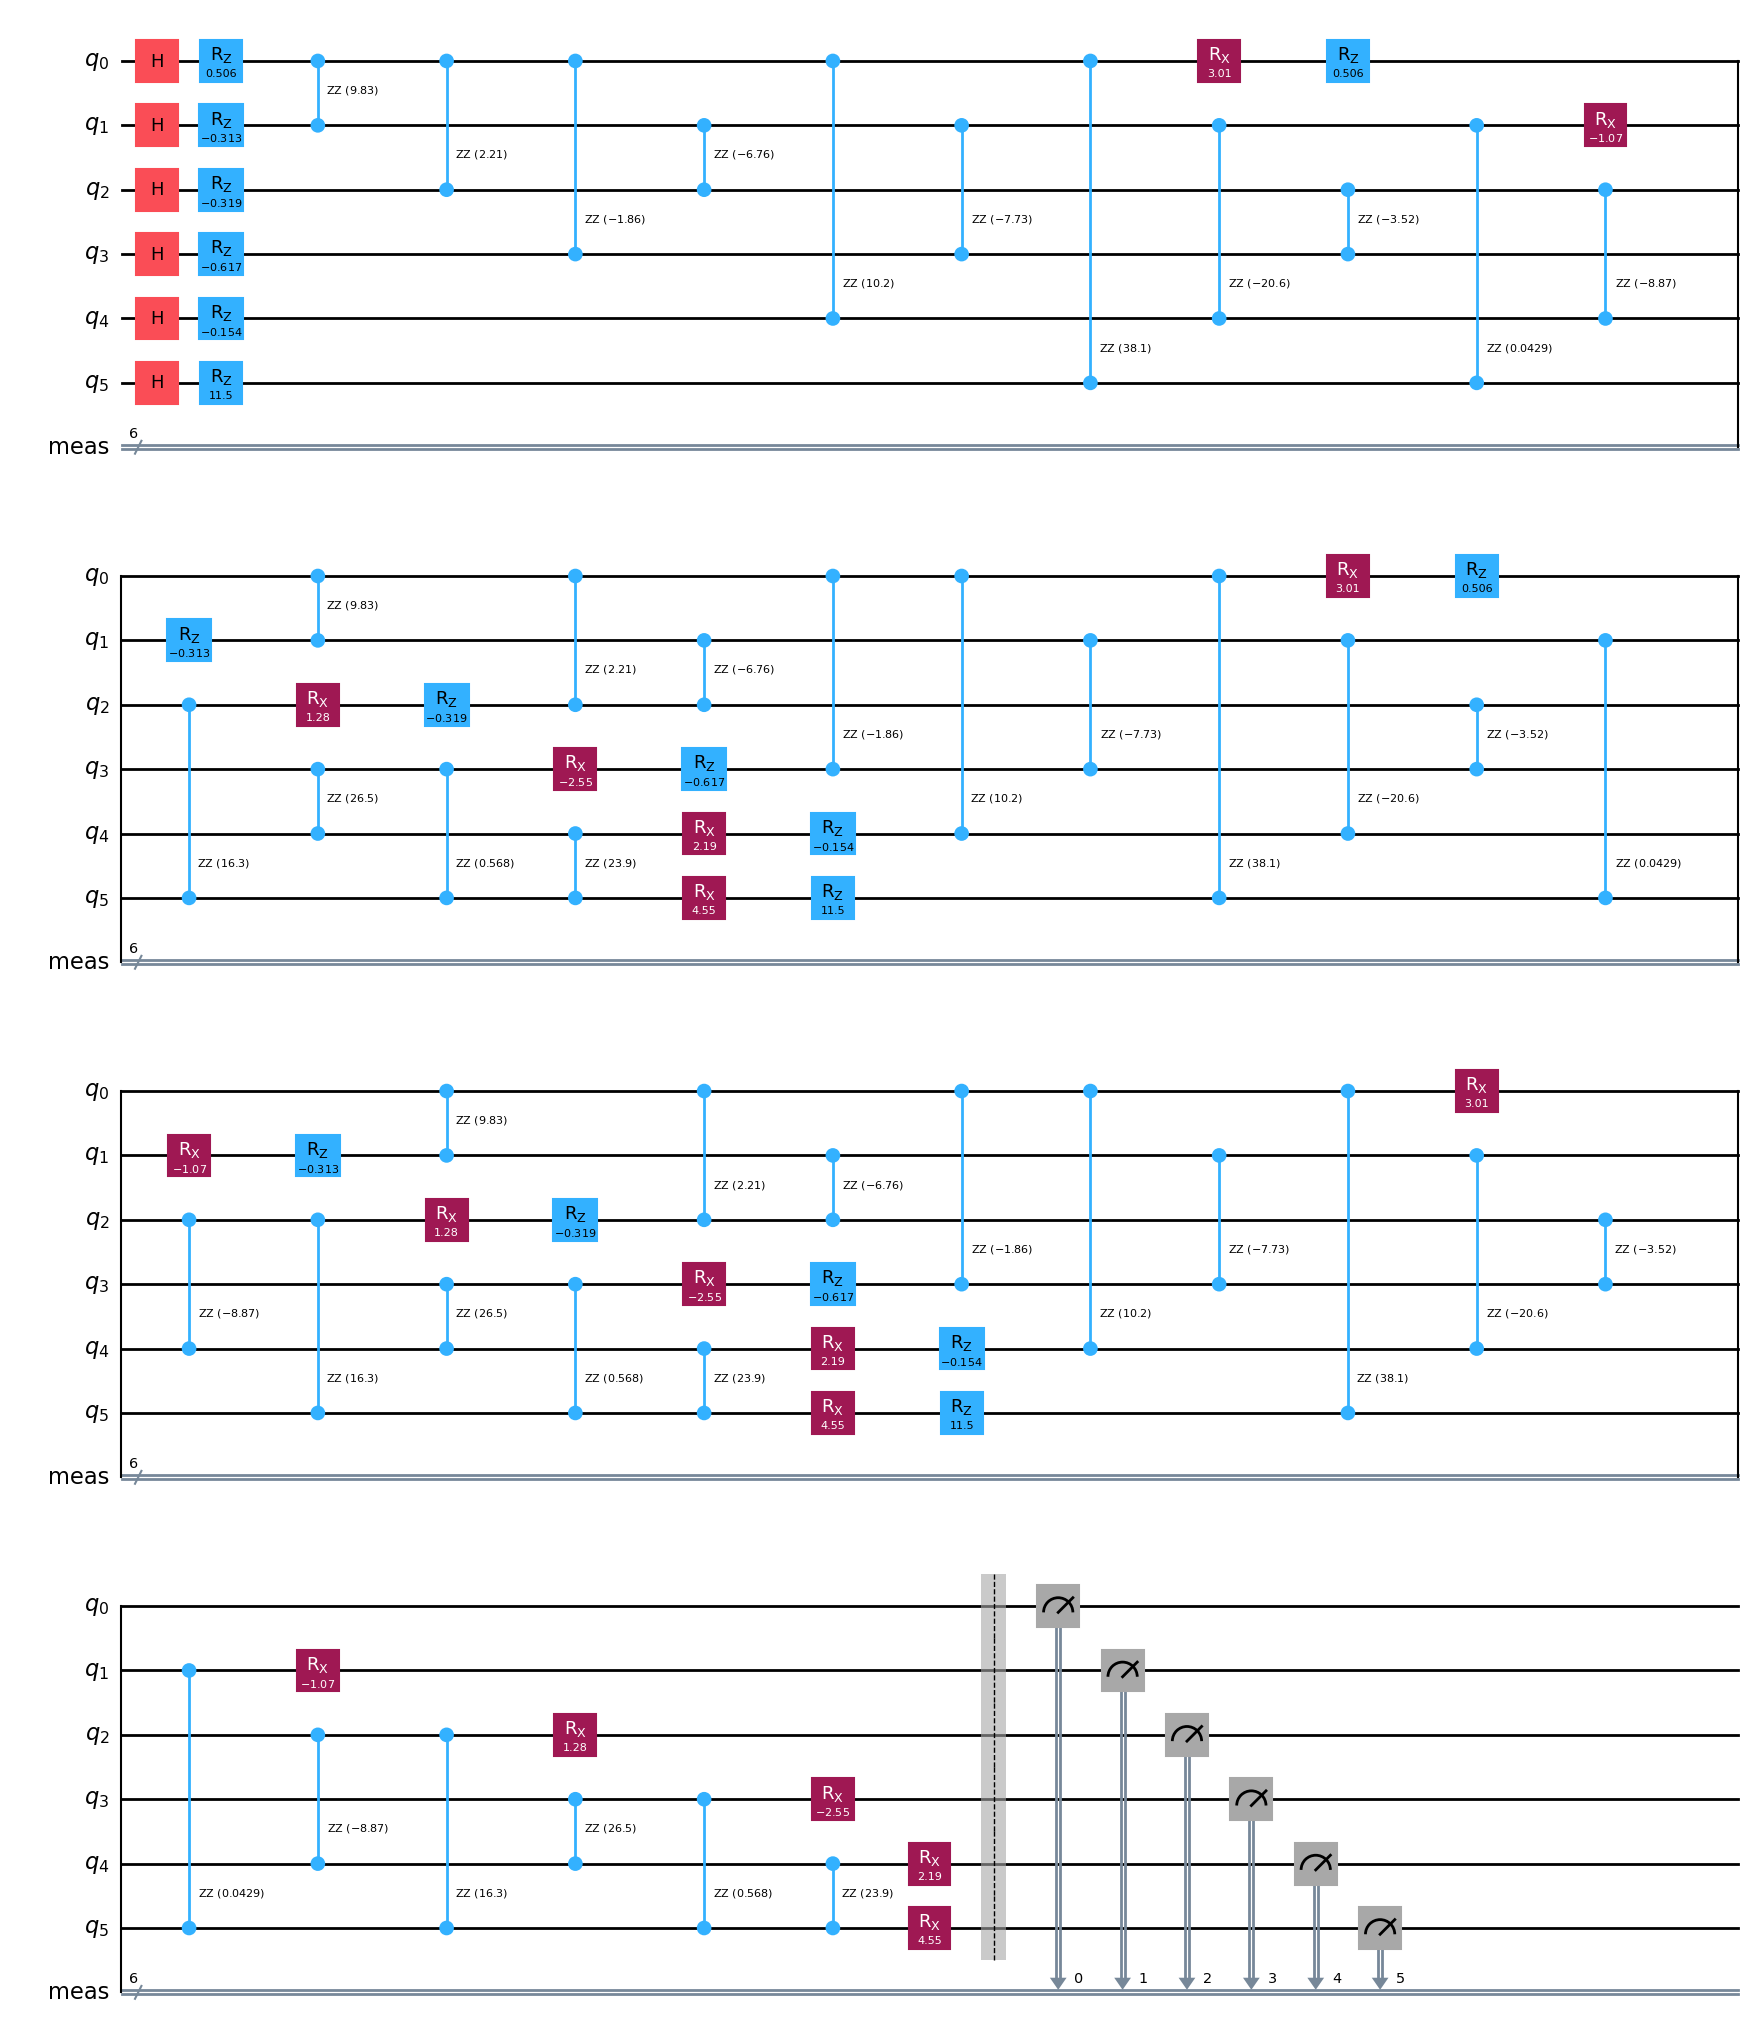

In [56]:
analyze_circuit(qc,backend=None)
qc.draw('mpl')

as we can see, the result actually does not converge in general. It is usually known that the result is dependant of the init state, and specifically for the fermionic qaoa. So now, let's introduce the fourth part, the generation of an arbitrary quantum state 

## Optimizers in QAOA: Overview

Qiskit provides several optimization methods for variational algorithms like **VQE** or **QAOA**. Each optimizer has its own advantages and limitations. Below is a detailed explanation of the four common Qiskit optimizers and a custom **Genetic Optimizer**, which has unique strengths for challenging landscapes.

---

### 1. COBYLA (Constrained Optimization BY Linear Approximations)

- **Type**: Derivative-free optimizer based on linear approximations.  
- **Principle**:  
  1. Successively approximate the objective function by linear polynomials in a local neighborhood.  
  2. Solve linear subproblems to propose a new candidate point.  
  3. Iterate until convergence or maximum number of iterations is reached.
- **Characteristics**:
  - Does not require derivatives.
  - Can handle nonlinear constraints.
  - Good for noisy or non-differentiable functions.
- **Disadvantages**:
  - Convergence can be slow.
  - Sensitive to initial parameters.

---

### 2. SPSA (Simultaneous Perturbation Stochastic Approximation)

- **Type**: Stochastic optimizer based on gradient approximation.  
- **Principle**:  
  1. At each iteration, simultaneously perturb all parameters with small random variations.  
  2. Estimate the gradient from only two function evaluations, regardless of the number of parameters.  
  3. Update the parameters according to a stochastic gradient-like rule.
- **Characteristics**:
  - Efficient for functions with many parameters.
  - Resistant to noise (ideal for real quantum devices).  
- **Disadvantages**:
  - Slower convergence on smooth functions.
  - Sensitive to hyperparameters (step size, perturbation schedule).

---

### 3. Nelder-Mead

- **Type**: Simplex-based derivative-free method.  
- **Principle**:  
  1. Define a **simplex** (a set of points in the parameter space).  
  2. At each iteration, transform the simplex via reflection, expansion, contraction, or shrinkage to approach the minimum.
- **Characteristics**:
  - Does not require derivatives.
  - Easy to implement.
  - Suitable for noisy functions and low-dimensional problems.  
- **Disadvantages**:
  - Inefficient in high dimensions (>10–20 parameters).
  - Can get stuck in local minima.

---

### 4. L_BFGS_B (Limited-memory Broyden–Fletcher–Goldfarb–Shanno with Bound constraints)

- **Type**: Quasi-Newton derivative-based optimizer.  
- **Principle**:  
  1. Approximate the **inverse Hessian matrix** to estimate the gradient and descent direction.  
  2. Use limited memory to handle large dimensions.  
  3. Can handle bound constraints on parameters.
- **Characteristics**:
  - Fast and accurate for smooth functions.
  - Suitable for medium-to-large dimensional problems.
  - Supports parameter bounds (`bounds`).  
- **Disadvantages**:
  - Requires the function to be differentiable.
  - Sensitive to noise, less suitable for noisy experimental outputs.

---

### 5. Genetic Optimizer (Custom)

- **Type**: Population-based stochastic optimizer inspired by evolutionary algorithms.  
- **Principle**:  
  1. Initialize a population of candidate parameter vectors randomly.  
  2. Evaluate each individual using the cost function.  
  3. Select the top-performing individuals (selection).  
  4. Create new candidates by adding small random variations (mutation).  
  5. Iterate for a fixed number of generations to evolve toward better solutions.
- **Characteristics & Strengths**:
  - **Exceptional global exploration**: Can escape local minima where gradient-based or simplex methods fail.  
  - **Highly noise-resistant**: Performs reliably even when the cost function is stochastic, as in real quantum hardware.  
  - **Flexible and scalable**: Population size, mutation rate, and selection pressure can be tuned for various problem sizes.  
  - **Parallelizable**: Each individual in the population can be evaluated independently, making it efficient on HPC or cloud simulators.  
  - **Adaptable to complex landscapes**: Works well on non-convex, high-dimensional, or multimodal cost surfaces where classical optimizers struggle.
- **Disadvantages**:
  - Requires more function evaluations than gradient-based methods.
  - Performance depends on careful tuning of population and mutation parameters.

---

### 🔑 Summary Table

| Optimizer       | Gradient | Noise Resistance | Global Exploration | High Dimension | Constraints | Notes |
|-----------------|----------|-----------------|-----------------|----------------|------------|-------|
| COBYLA          | No       | Medium          | Low              | Medium         | Yes        | Derivative-free, sometimes slow |
| SPSA            | Approx.  | Very good       | Medium           | Very good      | No         | Ideal for real QPU runs |
| Nelder-Mead     | No       | Good            | Low              | Low            | No         | Simplex, easy to use |
| L_BFGS_B        | Yes      | Low             | Low              | Good           | Yes        | Fast and precise for smooth functions |
| Genetic (custom)| No       | Very good       | Excellent        | Medium         | No         | Stochastic, escapes local minima, highly parallelizable |

---



# 4️⃣ WARM-START with generation of an arbitrary quantum state

Following our discusion with Gines Carrascal, we decided to implement an **arbitrary quantum state preparation (AQSP)** circuit to prepare warm states for our algorithms. Our goal is to build a quantum circuit with easily-implementable gates (Rx, Ry, Rz) to obtain a quantum state with a defined probability distribution. 

## 🔹 Circuit



The circuit is made up of Rx and Ry gates with angles form the angle matrice $\gamma$ of dimension $(2n) \times p$ with $n$ the total number of qubits and $p$ the depth of the circuit (cf. MA-QAOA). We want the output state to have the same distribution than a reference distribution. To do so, we minimize the Kullback-Leiber divergence between the two distrubtions by optmizing $\gamma$ with optimizers as SPSA or Genetic.
The Kullback-Leiber divergence, also called relative entropy, is a measure of how much an approximating probability distribution $Q$ is different from a true probability distribution $P$. The full formula reads:

$$
D_{\text{KL}}(P \parallel Q) = \sum_{x \in \mathcal{X}} P(x) \log \frac{P(x)}{Q(x)}.
$$

This value can be easily calculated using *scipy.stats.entropy*.

The quantum circuit is detailed below. 

In [57]:
# AQSP Circuit implementation

def aqsp_circuit(num_qubits, p, gamma_vec, init_state=None):
    qc = QuantumCircuit(num_qubits)

    # AQSP layers
    for layer in range(p):
        for term_id in range(num_qubits):
            qc.rx(gamma_vec[layer][term_id], term_id)
        if num_qubits % 2 == 0:
            for term_id in range(1,num_qubits,2):
                qc.cx(term_id-1,term_id) 
        if num_qubits % 2 != 0:
            for term_id in range(1, num_qubits-1,2):
                qc.cx(term_id-1,term_id)
        qc.barrier()
        for term_id in range(num_qubits, 2*num_qubits):
            qc.ry(gamma_vec[layer][term_id], term_id-num_qubits)
        if num_qubits % 2 == 0:
            for term_id in range(1,num_qubits,2):
                qc.cx(term_id-1,term_id)
        if num_qubits % 2 != 0:
            for term_id in range(2, num_qubits,2):
                qc.cx(term_id-1,term_id)
        qc.barrier()


    return qc

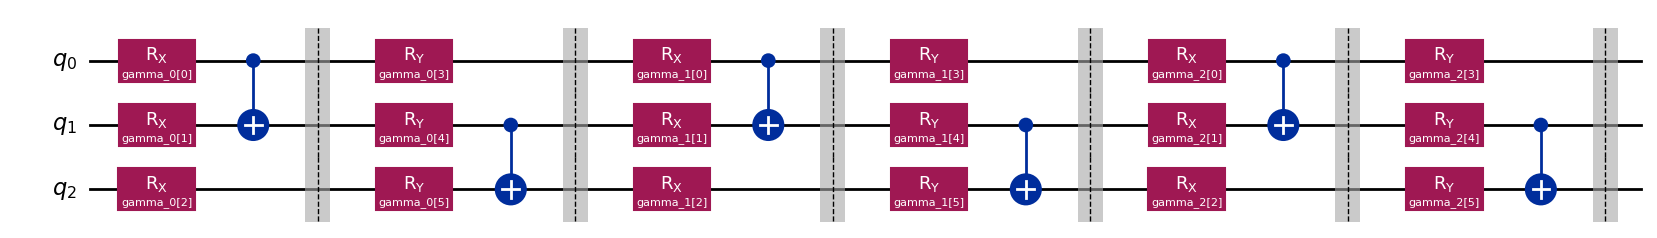

In [58]:
# Exemple 
from qiskit.circuit import ParameterVector
from scipy.stats import entropy
p = 3
num_qubits = 3
gamma_vec = [ParameterVector(f"gamma_{i}", num_qubits*2) for i in range(p)]
qc = aqsp_circuit(num_qubits, p, gamma_vec)
qc.draw("mpl")

## 🔹 Optimization

As mentionned earlier, we use the Kallback-Leibner divergence as our cost function and we will use different optimizers to find the angles matrice $\gamma$ that minimize the function. 


In [59]:
# Cost function

def cost_fn(gamma_vec_flat):
    gamma_vec = gamma_vec_flat.reshape((p, 2*num_qubits)) # the parameters are reshaped into a 2D array of shape (p, 2*num_qubits)
    qc = aqsp_circuit(num_qubits, p, gamma_vec)
    qc.measure_all()
    qc_t = transpile(qc, backend)
    result = backend.run(qc_t, shots=2048).result()
    counts = result.get_counts()

    # Converts counts into a probability vector of length 2**num_qubits
    probs_current = np.zeros(2**num_qubits) 
    for bitstring, c in counts.items():
        idx = int(bitstring, 2)
        probs_current[idx] = c / 2048
    
    # Computes the KL divergence between the circuit’s output distribution
    kl = entropy(probs_current + 1e-10, target_probs + 1e-10)
    return kl

For our algorithims, we need to generate two types of states:
- states that follow a **reference distrubution** corresponding to the probability to find each asset in the return portefolio based on classical approach for an application in QAOA or MA-QAOA;
- **Dicke states** that are states with a given Hamming weight k, for example $
|D^3_2\rangle = \frac{1}{\sqrt{3}}\Big(|011\rangle + |101\rangle + |110\rangle\Big)
$ for an application in Fermionic QAOA.

## 1. AQSP for a reference distribution

Let's try our AQSP optimization feedline on the reference distribution reference_probs [0.12, 0.18, 0.10, 0.14, 0.08, 0.09, 0.15, 0.14]. The associated histogram is reported below.

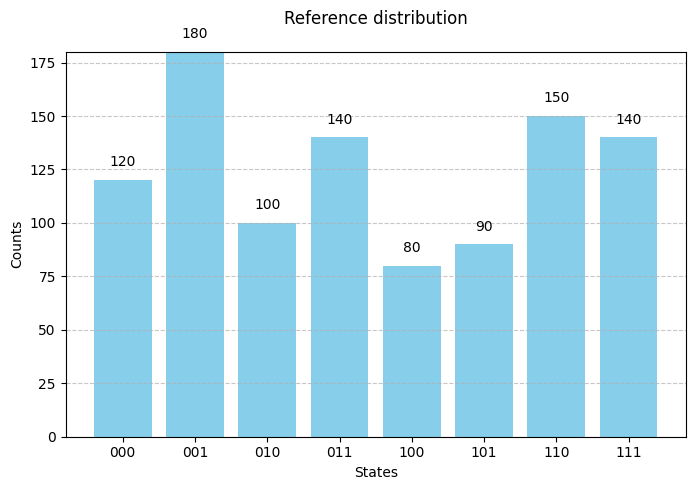

In [60]:
reference_probs = [0.12, 0.18, 0.10, 0.14, 0.08, 0.09, 0.15, 0.14]
reference_probs = [i*1000 for i in reference_probs]

# Corresponding states 

states = ['000', '001', '010', '011', '100', '101', '110', '111']

# Histogram 

plt.figure(figsize=(8,5))
bars = plt.bar(states, reference_probs, color='skyblue')
plt.xlabel('States')
plt.ylabel('Counts')
plt.ylim(0, max(reference_probs) + 0.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.title("Reference distribution", pad = 20)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,  
        height + 5,                       
        f"{height:.0f}",                  
        ha='center', va='bottom'
    )

plt.show()

### 1. SPSA approach

We first implement the SPSA approach for our optimization problem. We redefine the SPSA optimizer for our use and generate an example for $n = 3$, $p = 12$ and maxiter $= 100$.

In [61]:
def spsa_optimizer(cost_fn, x0, maxiter, a=0.05, c=0.05, alpha=0.602, gamma=0.101): #a,c,alpha,gamma: usual values for SPSA
    x = x0.copy()
    for k in range(1, maxiter + 1):
        ak = a / (k + 1)**alpha
        ck = c / (k + 1)**gamma
        
        # Perturbation aléatoire ±1 pour chaque paramètre
        delta = 2 * np.random.randint(0, 2, size=x.shape) - 1
        
        # Évaluer la fonction aux deux points perturbés
        y_plus = cost_fn(x + ck * delta)
        y_minus = cost_fn(x - ck * delta)
        
        # Estimation du gradient
        gk = (y_plus - y_minus) / (2 * ck * delta)
        
        # Mise à jour
        x = x - ak * gk
        
        if k % 10 == 0:
            print(f"Iteration {k}, cost = {cost_fn(x)}")
    
    return x

In [62]:
reference_probs = [0.12, 0.18, 0.10, 0.14, 0.08, 0.09, 0.15, 0.14]

In [63]:
backend = AerSimulator()

# Initial parameters

num_qubits = 3      
p = 12
gamma_vec = np.random.uniform(0, 2*np.pi, size=(p, 2*num_qubits))
target_probs = np.array(reference_probs) # The target distribution 
gamma_vec_flat = gamma_vec.flatten()
gamma_opt_flat = spsa_optimizer(cost_fn, gamma_vec_flat, maxiter=100)

# Convert gamma_opt_flat in a (2n)*p matrice for lecture

gamma_opt = gamma_opt_flat.reshape((p, 2*num_qubits))

Iteration 10, cost = 0.11152464116429912
Iteration 20, cost = 0.0520385779972737
Iteration 30, cost = 0.020765909786154235
Iteration 40, cost = 0.027388703219848494
Iteration 50, cost = 0.012909345655482206
Iteration 60, cost = 0.011374192740234363
Iteration 70, cost = 0.014955718785280538
Iteration 80, cost = 0.0039674067673339895
Iteration 90, cost = 0.008744239932074845
Iteration 100, cost = 0.005954823140392104


The histogram built with the optimal angles matrice $\gamma_{opt}$ given by the SPSA optimizer is reported below.

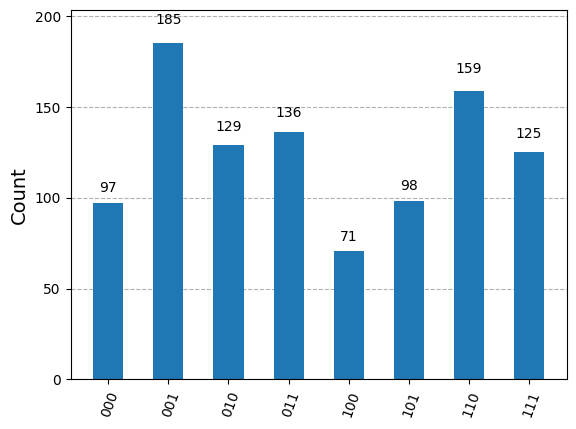

In [64]:
gamma_vec = gamma_opt
qc = aqsp_circuit(num_qubits, p, gamma_vec)
qc.measure_all()
backend = AerSimulator()
qc = transpile(qc, backend)
result = backend.run(qc, shots=1000).result()
counts = result.get_counts()
plot_histogram(counts)


### 2. Genetic approach

Now we implement the Genetic approach for our optimization problem. We redefine the Genetic optmizer for our use and generate an example for $n=3$ , $p=12$, population $=30$, generations $=10$ and mutation rate $0.2$.

In [65]:
def genetic_optimizer(cost_fn, num_params, pop_size, generations, mutation_rate, bounds=(-np.pi, np.pi)):
    low, high = bounds
    population = np.random.uniform(low, high, size=(pop_size, num_params))

    for gen in range(generations):
        fitness = np.array([cost_fn(ind) for ind in population])
        sorted_idx = np.argsort(fitness)
        population = population[sorted_idx]
        fitness = fitness[sorted_idx]

        best_params, best_value = population[0], fitness[0]
        print(f"Gen {gen:03d} | Best energy = {best_value:.6f}")

        new_population = [best_params.copy()]
        while len(new_population) < pop_size:
            parents = population[np.random.choice(pop_size//2, 2, replace=False)]
            cross_point = np.random.randint(1, num_params-1)
            child = np.concatenate((parents[0][:cross_point], parents[1][cross_point:]))
            for i in range(num_params):
                if np.random.rand() < mutation_rate:
                    child[i] += np.random.normal(0, 0.2)
            child = np.clip(child, low, high)
            new_population.append(child)

        population = np.array(new_population)

    return best_params, best_value 

In [66]:
reference_probs = [0.12, 0.18, 0.10, 0.14, 0.08, 0.09, 0.15, 0.14]

In [67]:
backend = AerSimulator()

# Initial parameters

num_qubits = 3       
p = 12      
gamma_vec = np.random.uniform(0, 2*np.pi, size=(p, 2*num_qubits))
probs_target = np.array(reference_probs)
num_params = p * 2 * num_qubits  

best_params_flat, best_kl = genetic_optimizer(
    cost_fn,
    num_params=num_params,
    pop_size=30,
    generations=10,
    mutation_rate=0.2
)
gamma_opt = best_params_flat.reshape((p, 2*num_qubits))

print("\nOptimized angles (gamma_opt) :")
print(gamma_opt)
print("\nFinal KL =", best_kl)


Gen 000 | Best energy = 0.136402
Gen 001 | Best energy = 0.061224
Gen 002 | Best energy = 0.050608
Gen 003 | Best energy = 0.063590
Gen 004 | Best energy = 0.051826
Gen 005 | Best energy = 0.033183
Gen 006 | Best energy = 0.046816
Gen 007 | Best energy = 0.057760
Gen 008 | Best energy = 0.054402
Gen 009 | Best energy = 0.036847

Optimized angles (gamma_opt) :
[[-2.12703399  0.41109848 -0.62900236  2.95745858 -1.69203044  2.98006945]
 [-2.66914492 -1.77048283 -0.31629559  2.62187813 -1.08742683 -1.92028231]
 [ 1.16788137 -1.9760848   1.87486317 -0.55332447 -2.40826193 -2.73763504]
 [ 0.43355171  0.35331119  0.21822292  1.08505379  1.39252185  1.11754678]
 [-2.95309934 -0.47623945 -2.20579264  1.79507059  2.58422688 -2.3563521 ]
 [ 2.13523278 -2.81353677  3.14159265  1.68910445 -0.34413552  0.16754075]
 [ 0.13508141  1.60517947  3.14159265 -1.89470099 -1.1828733   2.34241279]
 [ 1.64269688  1.62045103  3.08229512  0.77116477  0.35945665 -2.82123914]
 [-2.06301223 -0.61330248 -1.35563876 

The histogram built with the optical angles matrice $\gamma_{opt}$ given by the Genetic optimizer is reported below.

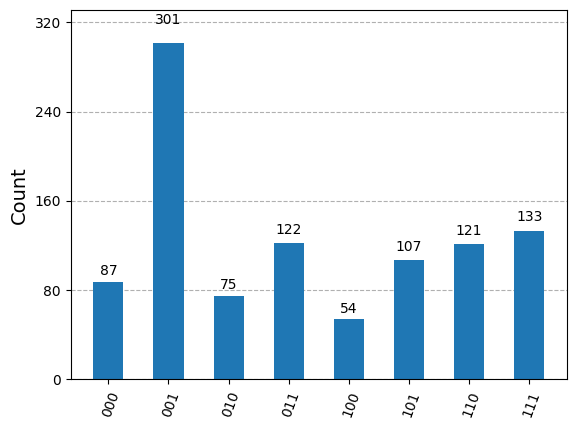

In [68]:
gamma_vec = gamma_opt
qc = aqsp_circuit(num_qubits, p, gamma_vec)
qc.measure_all()
backend = AerSimulator()
qc = transpile(qc, backend)
result = backend.run(qc, shots=1000).result()
counts = result.get_counts()
plot_histogram(counts)

## 2. AQSP for a Dicke state

Now we want to try our AQSP optimization feedline for the Dicke state $
|D^3_2\rangle = \frac{1}{\sqrt{3}}\Big(|011\rangle + |101\rangle + |110\rangle\Big)
$ i.e the reference distribution reference_probs = [0.0, 0.0, 0.0, 0.3333, 0.0, 0.3333, 0.3333, 0.0]. The associated histrogram is reported below. 

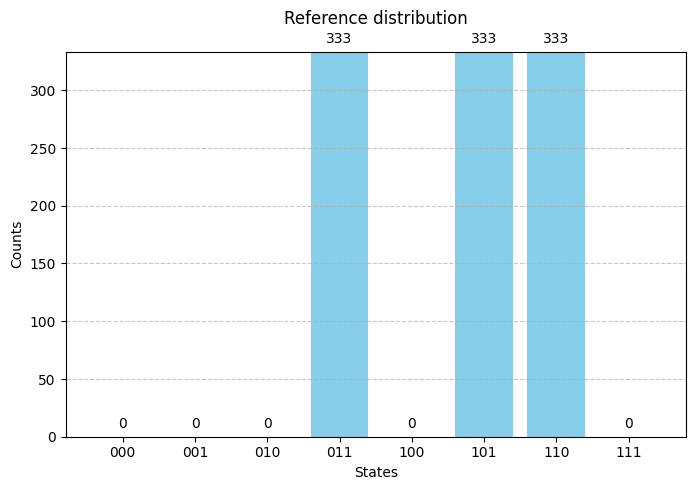

In [69]:
reference_probs = [0.0, 0.0, 0.0, 0.3333, 0.0, 0.3333, 0.3333, 0.0]
reference_probs = [i*1000 for i in reference_probs]

# Corresponding states 

states = ['000', '001', '010', '011', '100', '101', '110', '111']

# Histogram 

plt.figure(figsize=(8,5))
bars = plt.bar(states, reference_probs, color='skyblue')
plt.xlabel('States')
plt.ylabel('Counts')
plt.ylim(0, max(reference_probs) + 0.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.title("Reference distribution", pad = 20)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,  
        height + 5,                       
        f"{height:.0f}",                  
        ha='center', va='bottom'
    )

plt.show()

### 1. SPSA approach

We implement the SPSA optimizer for $n = 3$, $p = 12$ and maxiter $= 100$.

In [70]:
reference_probs = [0.0, 0.0, 0.0, 0.3333, 0.0, 0.3333, 0.3333, 0.0]

In [71]:
backend = AerSimulator()

# Initial parameters

num_qubits = 3      
p = 12
gamma_vec = np.random.uniform(0, 2*np.pi, size=(p, 2*num_qubits))
target_probs = np.array(reference_probs) # The target distribution 
gamma_vec_flat = gamma_vec.flatten()
gamma_opt_flat = spsa_optimizer(cost_fn, gamma_vec_flat, maxiter=100)

# Convert gamma_opt_flat in a (2n)*p matrice for lecture

gamma_opt = gamma_opt_flat.reshape((p, 2*num_qubits))

Iteration 10, cost = 8.263878834587192
Iteration 20, cost = 4.423292846108773
Iteration 30, cost = 3.986418702819653
Iteration 40, cost = 2.5019805602718996
Iteration 50, cost = 6.3128914980227595
Iteration 60, cost = 4.156880715385615
Iteration 70, cost = 4.1195038154043875
Iteration 80, cost = 1.591638767769437
Iteration 90, cost = 1.1274882023537232
Iteration 100, cost = 1.4476652332064137


The histogram built with the optimal angles matrice $\gamma_{opt}$ given by the SPSA optimizer is reported below.

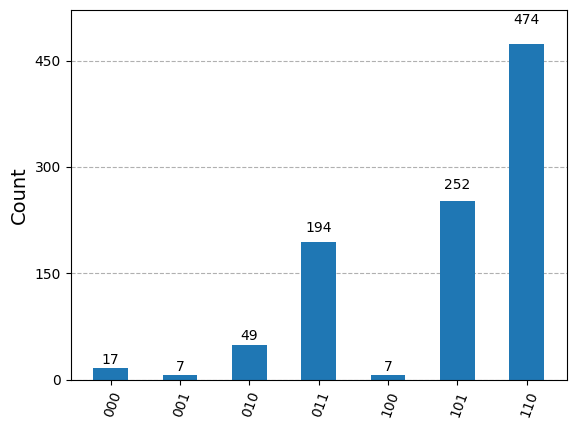

In [72]:
gamma_vec = gamma_opt
qc = aqsp_circuit(num_qubits, p, gamma_vec)
qc.measure_all()
backend = AerSimulator()
qc = transpile(qc, backend)
result = backend.run(qc, shots=1000).result()
counts = result.get_counts()
plot_histogram(counts)

### 2. Genetic approach

Now we implement the Genetic approach for our optimization problem. We redefine the Genetic optmizer for our use and generate an example for $n=3$ , $p=12$, population $=30$, generations $=10$ and mutation rate $0.2$.

In [73]:
reference_probs = [0.0, 0.0, 0.0, 0.3333, 0.0, 0.3333, 0.3333, 0.0]

In [74]:
backend = AerSimulator()

# Initial parameters

num_qubits = 3       
p = 12      
gamma_vec = np.random.uniform(0, 2*np.pi, size=(p, 2*num_qubits))
probs_target = np.array(reference_probs)
num_params = p * 2 * num_qubits  

best_params_flat, best_kl = genetic_optimizer(
    cost_fn,
    num_params=num_params,
    pop_size=30,
    generations=10,
    mutation_rate=0.2
)
gamma_opt = best_params_flat.reshape((p, 2*num_qubits))

print("\nOptimized angles (gamma_opt) :")
print(gamma_opt)
print("\nFinal KL =", best_kl)


Gen 000 | Best energy = 6.929301
Gen 001 | Best energy = 4.095819
Gen 002 | Best energy = 4.239490
Gen 003 | Best energy = 3.254381
Gen 004 | Best energy = 3.335244
Gen 005 | Best energy = 3.341585
Gen 006 | Best energy = 3.239935
Gen 007 | Best energy = 3.316234
Gen 008 | Best energy = 3.687861
Gen 009 | Best energy = 3.348279

Optimized angles (gamma_opt) :
[[-1.54627196 -0.25571139  1.34166672  0.85710725 -0.57772019  0.62825079]
 [ 0.48076076  1.12151284  3.02330568  2.33973439 -2.96947363 -0.07082127]
 [ 1.85825437 -0.52098311  1.43159902 -0.5641973   0.03121475 -1.06277264]
 [ 0.50966013  0.85462261 -0.33210375  1.45997415 -2.94333943 -1.55650095]
 [ 2.38446648 -1.63514735 -1.76755409 -1.25211857  0.42836064  0.78933875]
 [-2.80740279 -0.14515129 -2.46461075  1.91469889  1.72946421 -1.83124355]
 [-0.47566013  1.48687704 -2.17761082 -2.37559437  0.90423656  2.33980405]
 [-0.49028097  2.28604557 -2.20154075  1.201157    0.56840353  2.76401495]
 [ 0.51572109  3.01626664  2.90151516 

The histogram built with the optimal angles matrice $\gamma_{opt}$ given by the Genetic optimizer is reported below.

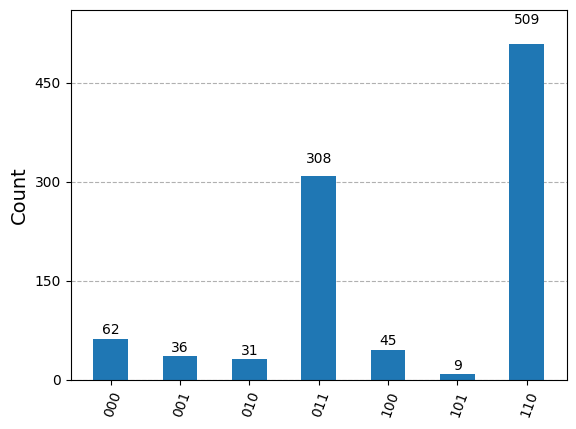

In [75]:
gamma_vec = gamma_opt
qc = aqsp_circuit(num_qubits, p, gamma_vec)
qc.measure_all()
backend = AerSimulator()
qc = transpile(qc, backend)
result = backend.run(qc, shots=1000).result()
counts = result.get_counts()
plot_histogram(counts)

# 5️⃣General Pipeline for Portfolio Optimization : ACTUAL OBJECTIVE

Now that we have both the **Warm State Generator** and a fully integrated **QAOA optimization module**, our next step is to address the **real-world constraints** of portfolio construction. In practice, we cannot randomly select the best-performing assets from the beginning, nor do we typically have access to a sufficiently large number \(N\) of assets to directly exploit quantum advantages. To overcome this, we introduce a **preprocessing stage** that reduces the dimensionality of the problem and performs a **pre-selection of promising assets**. This ensures that the subsequent quantum pipeline operates not only on a computationally tractable set but also on assets that are more likely to contribute to meaningful portfolio optimization. By combining preprocessing, dimensionality reduction, warm state preparation, and QAOA, we aim to bridge the gap between theoretical quantum algorithms and practical financial applications.


## Global Hackathon Pipeline

```text
┌─────────────────────┐
│   Input: N Assets   │
└─────────┬───────────┘
          │
          ▼
┌───────────────────────┐
│ Classical Preprocessing│
│ - Normalization        │
│ - Feature Engineering  │
└─────────┬─────────────┘
          │
          ▼
┌─────────────────────────────┐
│ Quantum Kernel Embedding     │
│ - Map data to Hilbert space  │
│ - Capture correlations       │
└─────────┬───────────────────┘
          │
          ▼
┌───────────────────────────────┐
│ Asset Reduction (N → n)        │
│ - Dimensionality reduction     │
│ - Quantum kernel optimization  │
└─────────┬─────────────────────┘
          │
          ▼
┌──────────────────────────────────────┐
│ Warm State Preparation (with AI)     │
│ - Learn efficient initializations    │
│ - Improve convergence of algorithms  │
└─────────┬───────────────────────────┘
          │
          ▼
┌──────────────────────────────┐
│   QAOA Optimization           │
│ - Optimize allocations        │
│ - Quantum-enhanced solutions  │
└─────────┬────────────────────┘
          │
          ▼
┌─────────────────────────────┐
│     Portfolio Analysis       │
│ - Risk metrics & clustering │
│ - Performance evaluation    │
└─────────────────────────────┘


# 6️⃣ Quantum Kernel for first pre-selection

## Quantum Kernels & ZZ Feature Map — Detailed Explanation for Asset Selection


## Quick Explanation

A **quantum kernel** measures the similarity between data points after encoding them into a high-dimensional **Hilbert space** using a **quantum feature map** (e.g., `ZZFeatureMap`).  
Once the similarity matrix (the **Gram matrix**) is computed, it can be used by classical machine learning models (e.g., SVM or Kernel Ridge Regression).  

For asset selection, this means we can:  
- Encode each asset as a feature vector (returns, volatility, Sharpe ratio, etc.).  
- Compute a quantum kernel matrix that captures both linear and **nonlinear correlations** between assets.  
- Train a classifier/regressor to distinguish "interesting" vs. "non-interesting" assets.  
- Select the **top-$n$** assets based on the scores.  

---

## 1. What is a Quantum Kernel?

### Classical Kernel Idea
In classical machine learning, a **kernel** is a function $k(x, x')$ that measures similarity between two input vectors $x$ and $x'$.  
For example:  
- Linear kernel: $k(x, x') = x^\top x'$  
- RBF kernel: $k(x, x') = \exp\left(-\gamma \|x - x'\|^2\right)$  

These kernels allow algorithms like **SVMs** to operate in an implicit **feature space**, where data can become more separable.

---

### Quantum Kernel Idea
In the **quantum setting**, data is mapped into a **Hilbert space** using a **quantum feature map** $U_\phi(x)$, which encodes $x$ into a quantum state:

$$
|\phi(x)\rangle = U_\phi(x)|0\rangle
$$

The kernel is then defined as the **fidelity** between two encoded quantum states:

$$
k(x, x') = |\langle \phi(x) | \phi(x') \rangle|^2
$$

Thus, a **quantum kernel** measures how similar two classical data points are after being mapped into a quantum state space.

---

## 2. The Gram Matrix

The **Gram matrix** $K$ is the collection of all pairwise kernel values:

$$
K_{ij} = k(x_i, x_j)
$$

- **Interpretation**: $K$ encodes how similar each asset $x_i$ is to every other asset $x_j$.  
- **In asset selection**: This tells us whether two assets behave similarly (e.g., correlated returns) or differently.  
- **In ML algorithms**:  
  - For SVM: $K$ defines the decision boundary.  
  - For Kernel Ridge Regression: $K$ is inverted to compute regression weights.  
  - For clustering: $K$ serves as a similarity matrix.  

The **quality** of the kernel (and thus the Gram matrix) determines how well we can distinguish between interesting and non-interesting assets.

---

## 3. Why Use Quantum Kernels Instead of Classical Kernels?

While classical kernels (linear, polynomial, RBF) are powerful, they can **struggle with complex dependencies** in data.  
Quantum kernels bring several advantages:

1. **High-dimensional embedding**  
   - Quantum states live in a Hilbert space of dimension $2^n$ (for $n$ qubits).  
   - This exponential scaling allows richer feature representations than classical kernels.  

2. **Nonlinear correlations captured via entanglement**  
   - Quantum feature maps like the ZZFeatureMap naturally encode **pairwise interactions** between features.  
   - Example: If asset $A$'s return only becomes significant when combined with asset $B$'s volatility, entanglement captures this.  

3. **Potential quantum advantage**  
   - Some problems may be efficiently separable in quantum Hilbert space but not in classical feature spaces.  

4. **Noise resilience in financial contexts**  
   - Real financial data is noisy. Quantum kernels, especially with stochastic optimizers, can sometimes generalize better than classical ones.

---

## 4. The ZZ Feature Map

The **ZZFeatureMap** is one of the most widely used quantum feature maps in finance and chemistry applications.  

It works as follows:
1. **Single-qubit rotations**:  
   Each feature $x_i$ is encoded via a $R_Z(x_i)$ rotation.  

2. **Entangling RZZ gates**:  
   Features are correlated by applying entangling gates:  
   $$
   e^{-i \beta x_i x_j Z_i Z_j}
   $$  
   This ensures that **pairwise products of features** are included in the mapping.  

3. **Layer repetition (`reps`)**:  
   Repeating the structure increases expressiveness (but also circuit depth).  

**Mathematically for one layer**:

$$
U_{\text{layer}}(x)=\left(\prod_{i} e^{-i \alpha x_i Z_i}\right)\left(\prod_{(i,j)\in E} e^{-i \beta\, x_i x_j Z_i Z_j}\right)
$$

- $E$: entanglement pattern (linear, full, or custom).  
- `reps`: number of repeated layers (more reps = more powerful embedding).  

---

## 5. Why Use the ZZ Feature Map?

- **Captures correlations** between asset features (returns, volatility, momentum, etc.).  
- **Flexible entanglement**: choose linear (shallow) or full (expressive).  
- **Proven performance**: ZZFeatureMap has been used in quantum ML experiments for finance, chemistry, and portfolio optimization.  
- **Good trade-off**: balances expressiveness with hardware feasibility.  

In finance, where **correlation between assets** is key, ZZFeatureMap is particularly suitable.

---

## 6. Workflow: From Data to Selecting $n$ Assets

1. **Feature engineering**  
   - Compute asset-level features (returns, volatility, Sharpe ratio).  

2. **Preprocessing**  
   - Normalize features into $[-\pi, \pi]$ (important for rotation encoding).  
   - Reduce dimensionality if too many features (since #features = #qubits).  

3. **Encoding with ZZFeatureMap**  
   - Build feature map with chosen depth and entanglement.  

4. **Compute Gram matrix with Quantum Kernel**  
   - Use `QuantumKernel.evaluate()` to get $K_{ij}$.  

5. **Train classical model**  
   - Use SVM or Kernel Ridge Regression with precomputed $K$.  

6. **Select assets**  
   - Rank by score/probability.  
   - Select top-$n$ for portfolio inclusion.  

---



In [76]:
# CONSTANTS AND PARAMETERS

algorithm_globals.random_seed = 42 # Set the seed
new_ticker = 0 # Number of additional tickers (for supervised labels and visualisation of clusters containing promising stoks)
risk_free_rate = 0 # Risk-free rate for Sharpe ratio
nb_to_select = 20 # Number of final stocks selected

# Types of tests
cluster_base = True
qsvm = True

# Parameters for optimising the results
    # Quantum Kernel
entanglement = 'full' # defines how qubits are entangled (linear, reverse_linear, full, circular, pairwise, sca, star)
reps = 25 # number of repetitions (layers) of the feature map (quantum kernel) to increase circuit expressiveness
    # t-SNE
perplexity = 10 # Perplexity parameter for t-SNE (controls the balance between local and global aspects)

In [77]:
def add_ticker(tickers, returns, n, volatility_std):
    """
    Adds n synthetic stocks, with volatility given by volatility_std
    volatility_std = 5.0: Low volatility (small fluctuations)
    volatility_std = 15.0: Medium volatility (more pronounced variations)
    volatility_std = 30.0: High volatility (significant variations)
    """
    name_ticker = 'ZZORIANE'
    for k in range (n):
        base_prices = np.linspace(100, 200, len(returns) + 1)[:-1] # Linear base sequence
        noise = np.random.normal(0, volatility_std[k], len(base_prices)) # Random noise with standard deviation volatility_std
        fake_prices = base_prices + noise # Add noise to create fluctuations
        fake_prices = np.clip(fake_prices, 50, 250) # Clip values to avoid negative or extreme prices (optional)
        
        fake_returns = pd.Series(fake_prices, index=returns.index).pct_change().fillna(0)
        fake_returns = fake_returns.reindex(returns.index, fill_value=0)
        returns[name_ticker] = fake_returns
        tickers.append(name_ticker)
        name_ticker = 'Z' + name_ticker

Circuit ZZFeatureMap :


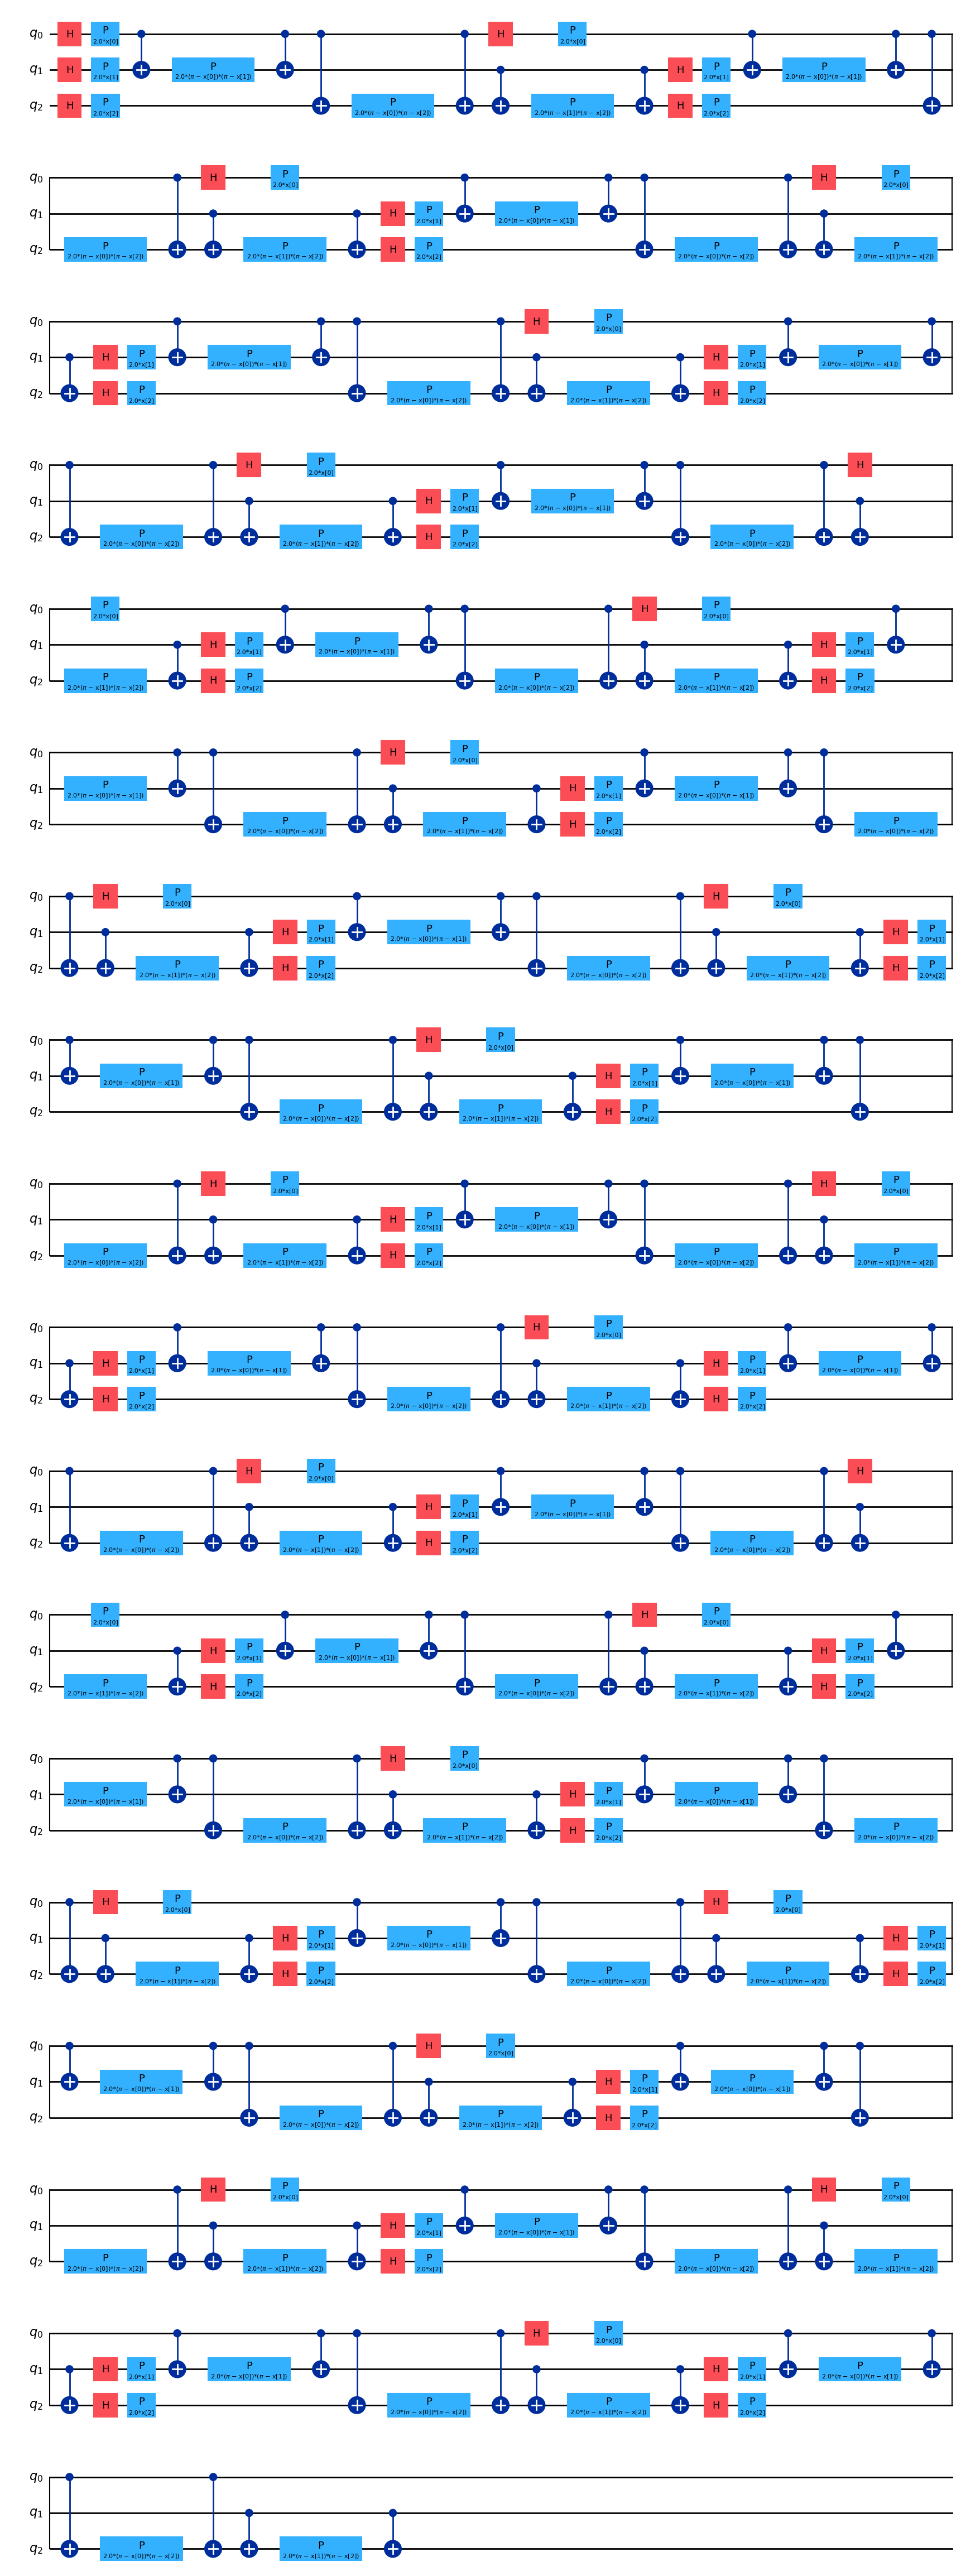

In [78]:
# PREPARING THE DATA AND THE QUANTUM KERNEL

# Fetch data
all_tickers = ['A', 'AAPL', 'ABBV', 'ABNB', 'ABT', 'ACGL', 'ACN', 'ADBE', 'ADI', 'ADM', 'ADP', 'ADSK', 'AEE', 'AEP', 'AES', 'AFL', 'AIG', 'AIZ', 'AJG', 'AKAM', 'ALB', 'ALGN', 'ALL', 'ALLE', 'AMAT', 'AMCR', 'AMD', 'AME', 'AMGN', 'AMP', 'AMT', 'AMZN', 'ANET', 'AON', 'AOS', 'APA', 'APD', 'APH', 'APO', 'APP', 'APTV', 'ARE', 'ASML', 'ATO', 'AVB', 'AVGO', 'AVY', 'AWK', 'AXON', 'AXP', 'AZN', 'AZO', 'BA', 'BAC', 'BALL', 'BAX', 'BBY', 'BDX', 'BEN', 'BF-B', 'BG', 'BIIB', 'BK', 'BKNG', 'BKR', 'BLDR', 'BLK', 'BMY', 'BR', 'BRK-B', 'BRO', 'BSX', 'BX', 'BXP', 'C', 'CAG', 'CAH', 'CARR', 'CAT', 'CB', 'CBOE', 'CBRE', 'CCEP', 'CCI', 'CCL', 'CDNS', 'CDW', 'CEG', 'CF', 'CFG', 'CHD', 'CHRW', 'CHTR', 'CI', 'CINF', 'CL', 'CLX', 'CMCSA', 'CME', 'CMG', 'CMI', 'CMS', 'CNC', 'CNP', 'COF', 'COIN', 'COO', 'COP', 'COR', 'COST', 'CPAY', 'CPB', 'CPRT', 'CPT', 'CRL', 'CRM', 'CRWD', 'CSCO', 'CSGP', 'CSX', 'CTAS', 'CTRA', 'CTSH', 'CTVA', 'CVS', 'CVX', 'D', 'DAL', 'DASH', 'DAY', 'DD', 'DDOG', 'DE', 'DECK', 'DELL', 'DG', 'DGX', 'DHI', 'DHR', 'DIS', 'DLR', 'DLTR', 'DOC', 'DOV', 'DOW', 'DPZ', 'DRI', 'DTE', 'DUK', 'DVA', 'DVN', 'DXCM', 'EA', 'EBAY', 'ECL', 'ED', 'EFX', 'EG', 'EIX', 'EL', 'ELV', 'EME', 'EMN', 'EMR', 'EOG', 'EPAM', 'EQIX', 'EQR', 'EQT', 'ERIE', 'ES', 'ESS', 'ETN', 'ETR', 'EVRG', 'EW', 'EXC', 'EXE', 'EXPD', 'EXPE', 'EXR', 'F', 'FANG', 'FAST', 'FCX', 'FDS', 'FDX', 'FE', 'FFIV', 'FI', 'FICO', 'FIS', 'FITB', 'FOX', 'FOXA', 'FRT', 'FSLR', 'FTNT', 'FTV', 'GD', 'GDDY', 'GE', 'GEHC', 'GEN', 'GFS', 'GILD', 'GIS', 'GL', 'GLW', 'GM', 'GNRC', 'GOOG', 'GOOGL', 'GPC', 'GPN', 'GRMN', 'GS', 'GWW', 'HAL', 'HAS', 'HBAN', 'HCA', 'HD', 'HIG', 'HII', 'HLT', 'HOLX', 'HON', 'HOOD', 'HPE', 'HPQ', 'HRL', 'HSIC', 'HST', 'HSY', 'HUBB', 'HUM', 'HWM', 'IBKR', 'IBM', 'ICE', 'IDXX', 'IEX', 'IFF', 'INCY', 'INTC', 'INTU', 'INVH', 'IP', 'IPG', 'IQV', 'IR', 'IRM', 'ISRG', 'IT', 'ITW', 'IVZ', 'J', 'JBHT', 'JBL', 'JCI', 'JKHY', 'JNJ', 'JPM', 'K', 'KDP', 'KEY', 'KEYS', 'KHC', 'KIM', 'KKR', 'KLAC', 'KMB', 'KMI', 'KMX', 'KO', 'KR', 'L', 'LDOS', 'LEN', 'LH', 'LHX', 'LII', 'LIN', 'LKQ', 'LLY', 'LMT', 'LNT', 'LOW', 'LRCX', 'LULU', 'LUV', 'LVS', 'LW', 'LYB', 'LYV', 'MA', 'MAA', 'MAR', 'MAS', 'MCD', 'MCHP', 'MCK', 'MCO', 'MDLZ', 'MDT', 'MELI', 'MET', 'META', 'MGM', 'MHK', 'MKC', 'MLM', 'MMC', 'MMM', 'MNST', 'MO', 'MOH', 'MOS', 'MPC', 'MPWR', 'MRK', 'MRNA', 'MRVL', 'MS', 'MSCI', 'MSFT', 'MSI', 'MSTR', 'MTB', 'MTCH', 'MTD', 'MU', 'NCLH', 'NDAQ', 'NDSN', 'NEE', 'NEM', 'NFLX', 'NI', 'NKE', 'NOC', 'NOW', 'NRG', 'NSC', 'NTAP', 'NTRS', 'NUE', 'NVDA', 'NVR', 'NWS', 'NWSA', 'NXPI', 'O', 'ODFL', 'OKE', 'OMC', 'ON', 'ORCL', 'ORLY', 'OTIS', 'OXY', 'PANW', 'PAYC', 'PAYX', 'PCAR', 'PCG', 'PDD', 'PEG', 'PEP', 'PFE', 'PFG', 'PG', 'PGR', 'PH', 'PHM', 'PKG', 'PLD', 'PLTR', 'PM', 'PNC', 'PNR', 'PNW', 'PODD', 'POOL', 'PPG', 'PPL', 'PRU', 'PSA', 'PSKY', 'PSX', 'PTC', 'PWR', 'PYPL', 'QCOM', 'RCL', 'REG', 'REGN', 'RF', 'RJF', 'RL', 'RMD', 'ROK', 'ROL', 'ROP', 'ROST', 'RSG', 'RTX', 'RVTY', 'SBAC', 'SBUX', 'SCHW', 'SHOP', 'SHW', 'SJM', 'SLB', 'SMCI', 'SNA', 'SNPS', 'SO', 'SPG', 'SPGI', 'SRE', 'STE', 'STLD', 'STT', 'STX', 'STZ', 'SW', 'SWK', 'SWKS', 'SYF', 'SYK', 'SYY', 'T', 'TAP', 'TDG', 'TDY', 'TEAM', 'TECH', 'TEL', 'TER', 'TFC', 'TGT', 'TJX', 'TKO', 'TMO', 'TMUS', 'TPL', 'TPR', 'TRGP', 'TRI', 'TRMB', 'TROW', 'TRV', 'TSCO', 'TSLA', 'TSN', 'TT', 'TTD', 'TTWO', 'TXN', 'TXT', 'TYL', 'UAL', 'UBER', 'UDR', 'UHS', 'ULTA', 'UNH', 'UNP', 'UPS', 'URI', 'USB', 'V', 'VICI', 'VLO', 'VMC', 'VRSK', 'VRSN', 'VRTX', 'VST', 'VTR', 'VTRS', 'VZ', 'WAB', 'WAT', 'WBD', 'WDAY', 'WDC', 'WEC', 'WELL', 'WFC', 'WM', 'WMB', 'WMT', 'WRB', 'WSM', 'WST', 'WTW', 'WY', 'WYNN', 'XEL', 'XOM', 'XYL', 'XYZ', 'YUM', 'ZBH', 'ZBRA', 'ZS', 'ZTS']
tickers = [all_tickers[i] for i in range(0, len(all_tickers), 5)] # Reducing the number of stocks to analyse to shorten computation time
tickers.sort() # Alphabetical order
data = yf.download(tickers, start = "2022-01-01", end="2023-01-01", threads=True)['Close'] # Download daily closing prices between the specified dates
returns = data.pct_change().dropna() # Compute daily returns (percentage change) and remove the first row (which contains NaN values)

if new_ticker!=0:
 add_ticker(tickers=tickers, returns=returns, n=new_ticker, volatility_std=np.random.rand(new_ticker) * 5)

mu = returns.mean() * 252 # Annualized return
sigma = returns.std() * np.sqrt(252) # Annualized volatility
sharpe = (mu - risk_free_rate) / sigma

# Prepare features
features = np.column_stack([mu, sigma, sharpe])
features = MinMaxScaler().fit_transform(features) # Normalize between 0 and 1
labels = ((mu > 0.5) & (sharpe >= 1) & (sigma < 1)).astype(int)

# ZZFeatureMap et QuantumKernel
num_features = features.shape[1]  # 3 features

feature_map = ZZFeatureMap(feature_dimension=num_features, reps=reps, entanglement=entanglement)
quantum_kernel = FidelityQuantumKernel(feature_map=feature_map)
print("Circuit ZZFeatureMap :")
feature_map.decompose().draw('mpl')

In [79]:
# CONSTRUCTION OF THE GRAM MATRIX

num_features = features.shape[1] # Number of features
num_samples = features.shape[0] # Number of samples (~252 days)

# Gram matrix
kernel_matrix = quantum_kernel.evaluate(x_vec = features)

# Convert similarity matrix to distance matrix
distance_matrix = np.sqrt(np.maximum(1 - kernel_matrix, 0))  # d_ij = sqrt(1 - s_ij)
np.fill_diagonal(distance_matrix, 0)  # Set the diagonal to 0

## Clustering in Machine Learning — Detailed Explanation


---

## 1. What is Clustering?

- **Definition**: Clustering is an **unsupervised learning technique** where the goal is to group a set of data points into clusters such that:
  - Points **within the same cluster** are similar to each other.
  - Points **from different clusters** are dissimilar.

- **Use cases**:
  - Grouping customers in marketing (customer segmentation).  
  - Grouping assets in finance (stocks with similar return patterns).  
  - Image compression (grouping similar pixels).  
  - Anomaly detection (points far from all clusters).  

---

## 2. The General Idea of Clustering

Clustering relies on a **distance (or similarity) measure** between data points, such as:

- **Euclidean distance**:  
  $$
  d(x, y) = \sqrt{\sum_i (x_i - y_i)^2}
  $$

- **Cosine similarity**:  
  $$
  \cos(\theta) = \frac{x \cdot y}{\|x\|\|y\|}
  $$

- **Kernel similarity** (e.g., with a **Gram matrix**):  
  $$
  k(x, y) = \phi(x)^\top \phi(y)
  $$

The algorithm then groups points based on these measures.

---

## 3. Major Clustering Algorithms

### 3.1. **K-Means Clustering**

- **Idea**: Partition data into $k$ clusters by minimizing variance within each cluster.  
- **Steps**:
  1. Initialize $k$ centroids randomly.  
  2. Assign each point to the nearest centroid.  
  3. Recompute centroids as the mean of points in each cluster.  
  4. Repeat until convergence.  

- **Mathematical objective**:  
  Minimize the **within-cluster sum of squares** (WCSS):

  $$
  \min_{C_1,\dots,C_k} \sum_{i=1}^k \sum_{x \in C_i} \|x - \mu_i\|^2
  $$

- **Advantages**:
  - Simple and fast.
  - Works well with spherical clusters.  

- **Disadvantages**:
  - Requires knowing $k$ in advance.  
  - Sensitive to initialization and outliers.  

---

### 3.2. **Hierarchical Clustering**

- **Idea**: Build a hierarchy of clusters either:
  - **Agglomerative**: Start with each point as its own cluster and merge step by step.  
  - **Divisive**: Start with one cluster and split iteratively.  

- **Produces** a **dendrogram** (tree of clusters).  

- **Linkage criteria**:
  - Single linkage: distance between closest points.  
  - Complete linkage: distance between farthest points.  
  - Average linkage: average distance between points.  

- **Advantages**:
  - Does not require $k$ in advance.  
  - Produces interpretable dendrogram.  

- **Disadvantages**:
  - Computationally expensive ($O(n^3)$ for naive version).  
  - Sensitive to noise.  

---

### 3.3. **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)**

- **Idea**: Clusters are defined as areas of high density separated by low-density regions.  
- **Parameters**:
  - $\epsilon$: neighborhood radius.  
  - `minPts`: minimum number of points required to form a dense region.  

- **Advantages**:
  - Finds clusters of arbitrary shape.  
  - Automatically detects outliers.  
  - Does not require knowing $k$.  

- **Disadvantages**:
  - Performance depends on parameters $\epsilon$ and `minPts`.  
  - Not ideal when clusters have very different densities.  

---

### 3.4. **Spectral Clustering**

- **Idea**: Uses the **eigenvalues of a similarity matrix (Gram matrix)** to reduce dimensions before clustering.  
- **Steps**:
  1. Build similarity graph between points.  
  2. Compute graph Laplacian.  
  3. Compute eigenvectors of Laplacian.  
  4. Run K-means in reduced space.  

- **Advantages**:
  - Very powerful for non-linear cluster structures.  
  - Works with kernels (classical or quantum).  

- **Disadvantages**:
  - Computationally expensive (requires eigen-decomposition).  

---

## 4. Choosing the Number of Clusters ($k$)

Several methods help to choose $k$:

- **Elbow method**: Plot WCSS vs $k$ and pick the "elbow."  
- **Silhouette score**: Measures how well points fit within their cluster vs the next nearest cluster.  
  $$
  s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}
  $$  
  where $a(i)$ is the average distance within a cluster and $b(i)$ the average distance to the nearest other cluster.  

---

## 5. Workflow: Clustering Assets

1. **Feature engineering**  
   - Represent each asset by features (returns, volatility, correlations).  

2. **Preprocessing**  
   - Normalize/scale features.  

3. **Apply clustering algorithm**  
   - Choose between K-means, DBSCAN, Hierarchical, etc.  

4. **Evaluate cluster quality**  
   - Use silhouette score, visualization, or domain-specific criteria.  

5. **Interpretation**  
   - Each cluster may represent a "group" of similar assets.  
   - Select representative or diverse assets from clusters.  

---




## 6. K-Means Clustering Choices in the Stock Analysis Code

The **K-Means algorithm** was selected for clustering the **distance matrix** in the provided code due to its superior **computational efficiency** compared to hierarchical clustering, DBSCAN, and spectral clustering, which are significantly slower for analysing up to 500 stocks. 

The distance matrix is **derived from the Gram matrix**, which encodes pairwise similarities between stocks based on their return data, typically computed via a quantum kernel. Specifically, it is obtained using the formula $ d_{ij} = \sqrt{K_{ii} + K_{jj} - 2K_{ij}} $, where $ K_{ii} $ and $ K_{jj} $ are diagonal elements representing self-similarities, and $ K_{ij} $ is the similarity between stocks $ i $ and $ j $. This produces a **symmetric matrix of Euclidean-like distances**, ideal for K-Means, which processes it swiftly to group stocks effectively. 

The **optimal number of clusters** is determined by evaluating **silhouette scores** across a range of cluster counts (2 to 10), selecting the number yielding the highest score to ensure robust stock grouping.

---

Best number of clusters: 10
Silhouette score for 10 clusters: 0.095

Cluster 0 - Best stocks (top 2 by Sharpe) :
       Ticker        Mu     Sigma    Sharpe
Ticker                                     
CBOE     CBOE  0.025532  0.254936  0.100151
PFE       PFE -0.033508  0.267061 -0.125468

Cluster 1 - Best stocks (top 2 by Sharpe) :
       Ticker        Mu     Sigma    Sharpe
Ticker                                     
SLB       SLB  0.664371  0.495890  1.339754
AFL       AFL  0.266143  0.236081  1.127334

Cluster 2 - Best stocks (top 2 by Sharpe) :
       Ticker        Mu     Sigma    Sharpe
Ticker                                     
CVX       CVX  0.502257  0.329552  1.524058
TKO       TKO  0.368175  0.284632  1.293512

Cluster 3 - Best stocks (top 2 by Sharpe) :
       Ticker        Mu     Sigma    Sharpe
Ticker                                     
VRTX     VRTX  0.313085  0.317398  0.986411
FICO     FICO  0.424103  0.510430  0.830874

Cluster 4 - Best stocks (top 2 by Sharpe) :
   

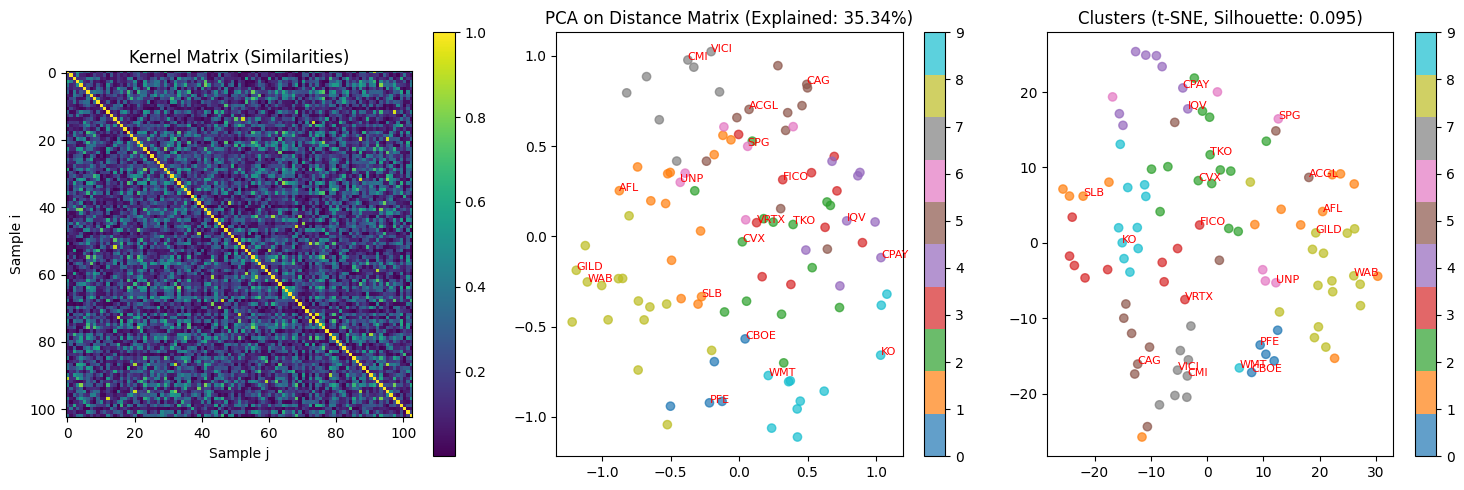

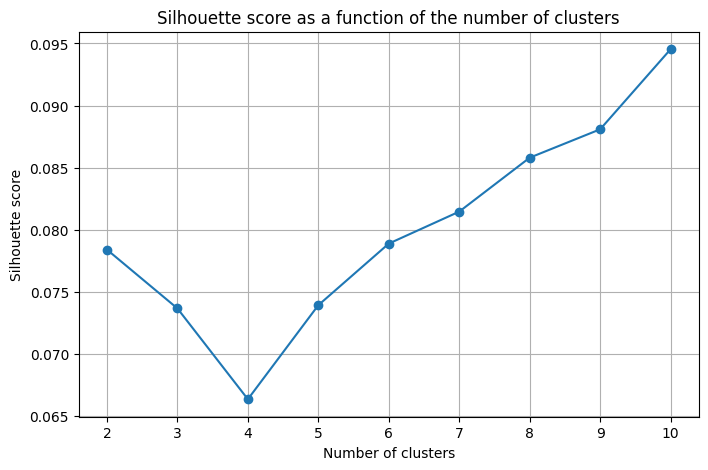

Quantum Kernel Analysis:
- Dimension of the data: 3
- Size of the kernel matrix: (103, 103)
- Variance explained by PCA (2 components): 35.34%
- Cluster labels: [8 5 3 1 8 7 9 2 3 3] (first 10 samples)


In [80]:
# CLUSTER_BASE METHOD

selection_cluster_base = []

# Choose number of clusters
cluster_range = range(2, 11)
silhouette_scores = []
for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(distance_matrix)
    sil_score = silhouette_score(distance_matrix, cluster_labels, metric='precomputed')
    silhouette_scores.append(sil_score)
    # print(f"Silhouette score for {n_clusters} clusters: {sil_score:.3f}")

# Select the best number of clusters
best_n_clusters = cluster_range[np.argmax(silhouette_scores)]
print(f"Best number of clusters: {best_n_clusters}")
print(f"Silhouette score for {best_n_clusters} clusters: {silhouette_scores[best_n_clusters-2]:.3f}")

# Clustering with KMeans
kmeans = KMeans(n_clusters=best_n_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(distance_matrix)

# Determine the best stocks (top k per cluster by Sharpe ratio)
top_stocks = (nb_to_select + new_ticker) // best_n_clusters
cluster_df = pd.DataFrame({'Ticker': returns.columns, 'Cluster': cluster_labels, 'Mu': mu, 'Sigma': sigma, 'Sharpe': sharpe})
promising_stocks = []
for cluster in range(best_n_clusters):
    cluster_group = cluster_df[cluster_df['Cluster'] == cluster]
    top_promising = cluster_group.sort_values(by='Sharpe', ascending=False).head(top_stocks)  # Top k par Sharpe
    promising_stocks.append(top_promising)
    print(f"\nCluster {cluster} - Best stocks (top {top_stocks} by Sharpe) :")
    print(top_promising[['Ticker', 'Mu', 'Sigma', 'Sharpe']])

# Visualisation
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
im1 = axes[0].imshow(kernel_matrix, cmap='viridis')
axes[0].set_title('Kernel Matrix (Similarities)')
axes[0].set_xlabel('Sample j')
axes[0].set_ylabel('Sample i')
plt.colorbar(im1, ax=axes[0])

# Analysis of clusters in 2D with PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(distance_matrix)

scatter1 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='tab10', alpha=0.7)
for i, ticker in enumerate(returns.columns):
    if ticker in pd.concat(promising_stocks)['Ticker'].values:
        selection_cluster_base.append(i)
        if 'ORIANE' not in ticker:
            axes[1].annotate(ticker, (X_pca[i, 0], X_pca[i, 1]), fontsize=8, color='red')
        else:
            axes[1].annotate('ZZZ', (X_pca[i, 0], X_pca[i, 1]), fontsize=8, color='red')
axes[1].set_title(f'PCA on Distance Matrix (Explained: {pca.explained_variance_ratio_.sum():.2%})')
plt.colorbar(scatter1, ax=axes[1])

# Analysis of clusters in 2D with t-SNE
tsne = TSNE(n_components=2, random_state=42, metric='precomputed', perplexity=min(perplexity, num_samples-1), init='random')
X_tsne = tsne.fit_transform(distance_matrix)

scatter2 = axes[2].scatter(X_tsne[:, 0], X_tsne[:, 1], c=cluster_labels, cmap='tab10', alpha=0.7)
for i, ticker in enumerate(returns.columns):
    if ticker in pd.concat(promising_stocks)['Ticker'].values:
        if 'ORIANE' not in ticker:
            axes[2].annotate(ticker, (X_tsne[i, 0], X_tsne[i, 1]), fontsize=8, color='red')
        else:
            axes[2].annotate('ZZZ', (X_tsne[i, 0], X_tsne[i, 1]), fontsize=8, color='red')
    elif 'ORIANE' in ticker: # Identify synthetic tickers (ZZORIANE, ZZZORIANE, etc.)
        axes[2].annotate('ZZZ', (X_tsne[i, 0], X_tsne[i, 1]), fontsize=8, color='blue')
axes[2].set_title(f'Clusters (t-SNE, Silhouette: {sil_score:.3f})')
plt.colorbar(scatter2, ax=axes[2])

plt.tight_layout()
plt.show()

# Visualise the silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(cluster_range, silhouette_scores, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')
plt.title('Silhouette score as a function of the number of clusters')
plt.grid(True)
plt.show()

# Verification
print("Quantum Kernel Analysis:")
print(f"- Dimension of the data: {num_features}")
print(f"- Size of the kernel matrix: {kernel_matrix.shape}")
print(f"- Variance explained by PCA (2 components): {pca.explained_variance_ratio_.sum():.2%}")
print(f"- Cluster labels: {cluster_labels[:10]} (first 10 samples)")

## Dimensionality Reduction for Quantum Machine Learning — PCA and t-SNE with Quantum Kernels




---

## 1. Why Dimensionality Reduction in Quantum Kernel Methods?

- **Quantum kernel idea**:  
  Given data points $x_i, x_j$, encode them into quantum states $|\phi(x_i)\rangle$ and compute the **kernel matrix (Gram matrix)**:

  $$
  K_{ij} = |\langle \phi(x_i) | \phi(x_j) \rangle|^2
  $$

- **Problem**: The Gram matrix is high-dimensional ($N \times N$ for $N$ assets).  
  It contains rich information about pairwise similarities, but is **hard to interpret directly**.  

- **Solution**: Apply **dimensionality reduction** to the Gram matrix:  
  - PCA extracts global directions of variance in the similarity structure.  
  - t-SNE highlights local neighborhoods, revealing clusters of assets.  

---

## 2. Principal Component Analysis (PCA) on Quantum Kernels

### 2.1. Intuition
- PCA finds the **most informative directions** in the kernel-induced space.  
- Instead of raw features, we use the **Gram matrix** $K$.  
- This allows us to find **principal components of quantum similarity** between assets.  

### 2.2. Kernel PCA (mathematical form)

Given the Gram matrix $K \in \mathbb{R}^{N \times N}$:

1. **Center the kernel matrix**:  
   $$
   \tilde{K} = K - \mathbf{1}K - K\mathbf{1} + \mathbf{1}K\mathbf{1}
   $$
   where $\mathbf{1}$ is the centering matrix $\frac{1}{N} \mathbf{11}^\top$.  

2. **Eigen-decomposition**:  
   Solve:
   $$
   \tilde{K} v = \lambda v
   $$
   where $\lambda$ are eigenvalues (variance explained) and $v$ eigenvectors.  

3. **Projection**:  
   The projection of asset $i$ on component $j$ is:
   $$
   z_{ij} = \frac{1}{\sqrt{\lambda_j}} v_j(i)
   $$  

### 2.3. Why PCA on quantum kernels?
- Captures **global variance structure** of assets based on **quantum similarity**.  
- Helps identify **dominant market trends** encoded by the ZZFeatureMap.  
- Provides features for **clustering or visualization**.  

---

## 3. t-SNE on Quantum Kernels

### 3.1. Intuition
- PCA is **linear**, while **t-SNE is nonlinear**.  
- t-SNE is ideal for **visualizing clusters of assets** in 2D/3D from the Gram matrix.  
- It preserves **local neighborhoods**: assets that are similar in quantum space remain close.  

### 3.2. Steps

1. Start with Gram matrix $K$.  
2. Compute **pairwise probabilities** of similarity from $K$:  
   $$
   p_{ij} \propto \exp\left(-\frac{\|K_i - K_j\|^2}{2\sigma^2}\right)
   $$  

3. Embed in low dimension (2D or 3D) by minimizing **KL divergence** between high-dimensional and low-dimensional similarities.  

### 3.3. Why t-SNE with quantum kernels?
- Reveals **clusters of assets** that classical methods might miss.  
- Captures **nonlinear market relationships** (e.g., correlated sectors, hidden patterns).  
- Useful for **exploratory data analysis** and **asset selection**.  

---

## 4. Comparison: PCA vs t-SNE for Quantum Kernels

| Property                     | PCA on Gram Matrix          | t-SNE on Gram Matrix                |
|-------------------------------|-----------------------------|-------------------------------------|
| Type                          | Linear                      | Nonlinear                           |
| Preserves                     | Global variance structure   | Local neighborhoods                 |
| Interpretability              | High (variance explained)   | Visualization only                   |
| Use Case                      | Feature extraction, clustering | Visualization, exploratory analysis |

---




Selected stocks (cluster):  ['ACGL', 'AFL', 'CAG', 'CBOE', 'CMI', 'CPAY', 'CVX', 'FICO', 'GILD', 'IQV', 'KO', 'PFE', 'SLB', 'SPG', 'TKO', 'UNP', 'VICI', 'VRTX', 'WAB', 'WMT']


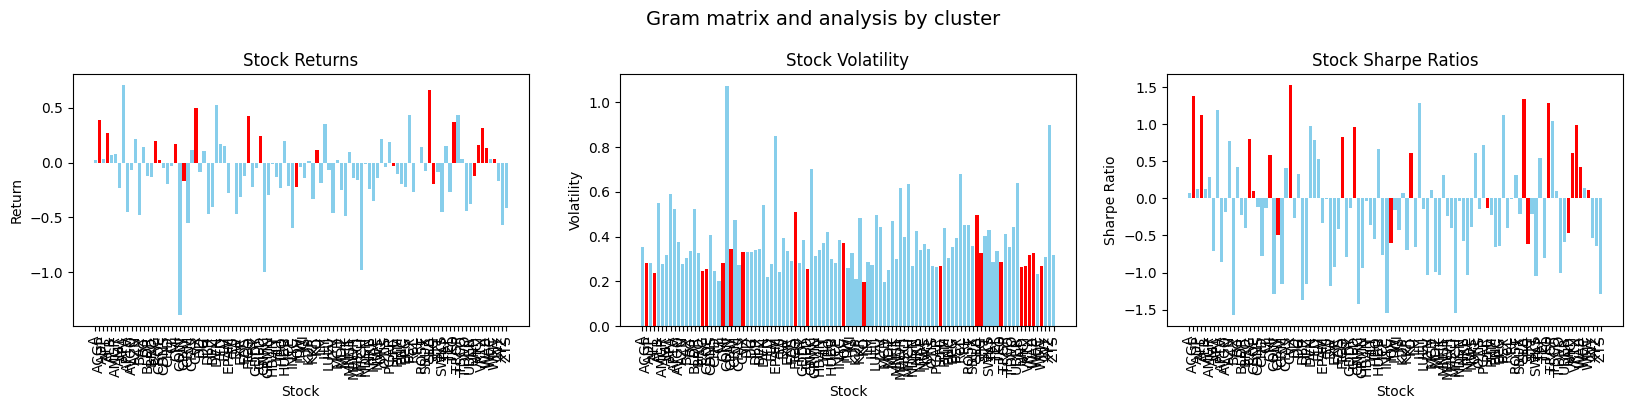

In [81]:
# Results of cluster

selection_cluster_base_names = []

colour_cluster = ['skyblue']*len(tickers)
        
for i in selection_cluster_base:
    colour_cluster[i]='red'
    selection_cluster_base_names.append(tickers[i])

print("Selected stocks (cluster): ", selection_cluster_base_names)

fig, axes = plt.subplots(1, 3, figsize=(20, 3))
fig.text(0.5, 1.1, 'Gram matrix and analysis by cluster', ha='center', va='bottom', fontsize=14)

# Visualization of clustering
if new_ticker!=0:
    im1 = axes[0].bar(tickers[:-new_ticker], mu[:-new_ticker], color=colour_cluster[:-new_ticker])
else:
    im1 = axes[0].bar(tickers, mu, color=colour_cluster)
axes[0].set_title('Stock Returns')
axes[0].set_xlabel('Stock')
axes[0].set_ylabel('Return')
axes[0].tick_params(axis='x', rotation=90)

im2 = axes[1].bar(tickers, sigma, color=colour_cluster)
axes[1].set_title('Stock Volatility')
axes[1].set_xlabel('Stock')
axes[1].set_ylabel('Volatility')
axes[1].tick_params(axis='x', rotation=90)

if new_ticker!=0:
    im3 = axes[2].bar(tickers[:-new_ticker], sharpe[:-new_ticker], color=colour_cluster[:-new_ticker])
else: 
    im3 = axes[2].bar(tickers, sharpe, color=colour_cluster)
axes[2].set_title('Stock Sharpe Ratios')
axes[2].set_xlabel('Stock')
axes[2].set_ylabel('Sharpe Ratio')
axes[2].tick_params(axis='x', rotation=90)

fig.subplots_adjust(hspace=1.2,top=0.95) 
plt.show()

# 7️⃣ AI module 

##  Stock Clustering and Visualization Module

This module is designed to be  **analyze, cluster, and visualize stock market data** to help identify correlations between assets and provide a **reduced-dimension representation** for further processing, such as quantum optimization.

The cluster part is there to be complementary with the quantum kernel one, and explore both of their solution to select assets

---

## 1.  Objective

The goal is to extract the **structural relationships between assets** using historical price data and graph-based methods.  

- Input: **Open and Close prices** for $N$ stocks over $T$ days  
- Compute: **daily variations** 

$$
\Delta P^{(i)}_t = P^{(i)}_{\text{close}, t} - P^{(i)}_{\text{open}, t}, \quad i=1,\dots,N
$$

- Standardize across assets to remove scale differences.

---

## 2. Data Collection & Preprocessing

1. **Select tickers**: e.g., `TICKERS = selection_cluster_base_names`  
2. **Download historical data** using `yfinance`:

   - Either via a fixed `period` (e.g., `"3mo"`)  
   - Or via `start` / `end` dates

3. **Align time indices**:

   - **Intersection**: keep only dates common to all assets  
   - **Union**: outer join all dates and fill missing values with forward/backward fill  

4. **Compute daily variation matrix**:

$$
X = \Delta P = 
\begin{bmatrix}
\Delta P^{(1)}_1 & \Delta P^{(1)}_2 & \dots & \Delta P^{(1)}_T \\
\vdots & \vdots & & \vdots \\
\Delta P^{(N)}_1 & \Delta P^{(N)}_2 & \dots & \Delta P^{(N)}_T
\end{bmatrix} \in \mathbb{R}^{N \times T}
$$

This variation matrix carries the most information for **correlation analysis**.

---

## 3.  Graphical Lasso for Precision Matrix Estimation

We aim to estimate the **partial correlation network** between assets:

1. Compute the **standardized variation matrix**:

$$
\tilde{X} = \frac{X^\top}{\sigma}, \quad \sigma = \text{std}(X, \text{axis}=1)
$$

2. Fit **GraphicalLassoCV** to estimate the **precision matrix** $\Theta = \Sigma^{-1}$:

$$
\Theta = \arg\min_\Theta \big\{ -\log \det \Theta + \text{tr}(S \Theta) + \alpha \|\Theta\|_1 \big\}, 
$$

where $S$ is the sample covariance and $\alpha$ controls sparsity.

- The **partial correlation** between assets $i$ and $j$ is:

$$
\rho_{ij}^{\text{partial}} = - \frac{\Theta_{ij}}{\sqrt{\Theta_{ii} \Theta_{jj}}}
$$

- This defines a **graph of assets**, where edges represent significant conditional dependencies.

---

## 4.  Clustering

- **Affinity Propagation** is applied to the **covariance matrix** to identify **clusters of similar assets**:

$$
\text{Cluster}(i) = k \quad \text{if asset } i \text{ belongs to cluster } k
$$

- Output: labels for each asset and the number of clusters $K$.

---

## 5.  Low-Dimensional Embedding

For visualization, we embed high-dimensional data into 2D or 3D:

- **t-SNE** is used to map stocks to coordinates:

$$
\text{Embedding}: X \in \mathbb{R}^{N \times T} \longrightarrow Y \in \mathbb{R}^{d \times N}, \quad d=2 \text{ or } 3
$$

- In the 2D case: $Y = [x_i, y_i]_{i=1}^N$  
- In the 3D case: $Y = [x_i, y_i, z_i]_{i=1}^N$

- Node size is proportional to $d_i = 1/\sqrt{\Theta_{ii}}$ (self-precision)  
- Node color encodes the cluster label

---

## 6. Visualization

- **Nodes**: represent assets  
- **Edges**: represent significant partial correlations ($|\rho_{ij}^{\text{partial}}| > 0.05$)  
- **Labels**: positioned to minimize overlap  
- **3D embedding**: optional, for interactive exploration

- Edge width and color encode the strength of correlation.

---

## 7. Role in the Global Pipeline

This module provides:

1. **Structural insight**: understanding correlations among assets  
2. **Dimensionality reduction**: from $N$ stocks to clusters or graph topology  
3. **Preselection input**: clusters and relationships inform the **CNN module** and later **quantum optimization**

$$
\text{Raw OHLC Data} \;\xrightarrow{\text{Graphical Lasso + Clustering}}\; \text{Clusters \& Embedding} \;\xrightarrow{\text{CNN / QAOA}}\; \text{Optimized Asset Selection}
$$

It bridges **classical statistical methods** and **quantum-enhanced optimization**.

---

## Summary

- Collect OHLC prices and compute daily variations  
- Estimate **partial correlations** using **Graphical Lasso**  
- Cluster assets with **Affinity Propagation**  
- Embed in 2D/3D using **t-SNE** for visualization  
- Output informs **CNN preselection** and **quantum optimization stages**

This module ensures the **input universe is structured**, interpretable, and ready for **advanced hybrid AI + Quantum workflows**.


**1. Finding clusters in ticker evolution**

Cluster 1: ACGL, AFL, WMT
Cluster 2: CBOE
Cluster 3: CPAY, FICO, VICI, VRTX
Cluster 4: CVX, SLB
Cluster 5: GILD, TKO
Cluster 6: CAG, IQV, KO, PFE, SPG
Cluster 7: CMI, UNP, WAB


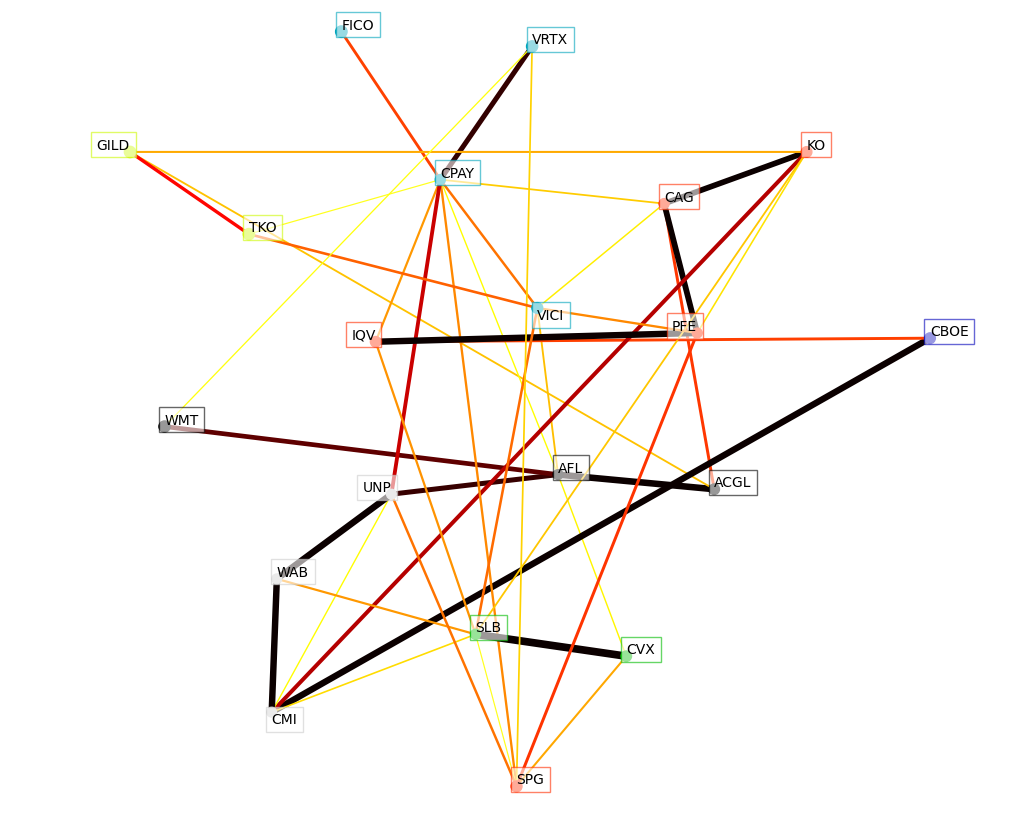

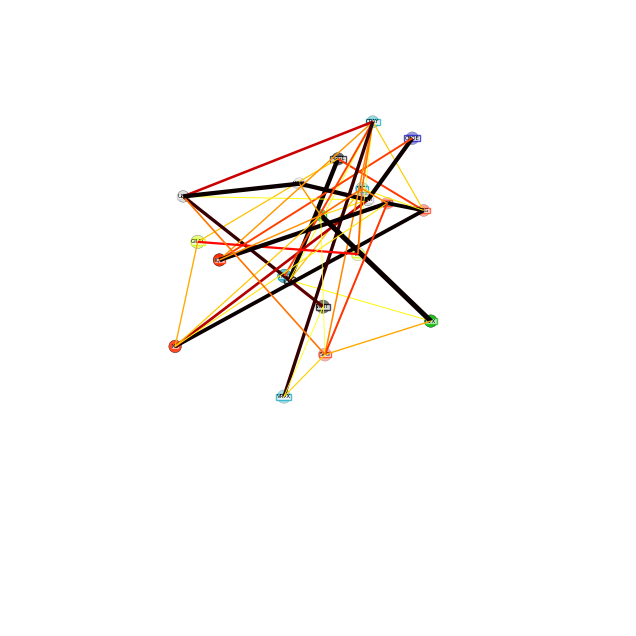

In [82]:
# all_tickers = get_all_tickers()
# print(len(all_tickers), "tickers collectés")
# TICKERS = all_tickers

TICKERS = selection_cluster_base_names

symbol_dict = {ticker: ticker for ticker in TICKERS}

# Ordered arrays 
symbols, names = np.array(sorted(symbol_dict.items())).T

# User-configurable options
start = "2021-01-01"   # or set None and use period below
end = "2023-12-31"     # e.g. "2023-12-31" or None
# 1d, 5d, 1mo, 3mo, 6mo, 1y, 2y, 5y, 10y, ytd, max
period = "3mo"         # e.g. "5y" - if not None, start/end are ignored
align = "intersection" # "intersection" (common dates) or "union" (outer join, may contain NaNs)
save_csv = False        # save each ticker history as CSV

# outdir = "clustering_stock_market/quotes_yf"   # directory to save CSVs
# os.makedirs(outdir, exist_ok=True)

dfs = []   # list of (symbol, df) for successfully downloaded tickers
failed = []

# Download loop (using tqdm for progress)
for symbol in tqdm(symbols, desc="Downloading"):
    try:
        # yfinance download: either interval + period, or start/end
        if period is not None:
            df = yf.download(symbol, period=period, progress=False, auto_adjust=False)
        else:
            df = yf.download(symbol, start=start, end=end, progress=False, auto_adjust=False)

        # df can be empty if ticker not found or no data
        if df is None or df.shape[0] == 0:
            print(f"Warning: no data for {symbol}", file=sys.stderr)
            failed.append(symbol)
            continue

        # Normalize column names to lowercase to match your code
        df.columns = [c[0].lower() for c in df.columns]

        # Keep at least 'open' and 'close' columns if available
        if "open" not in df.columns or "close" not in df.columns:
            print(f"Warning: missing open/close for {symbol}, columns: {df.columns}", file=sys.stderr)
            failed.append(symbol)
            continue

        # Optionally save CSV
        if save_csv:
            csv_path = os.path.join(outdir, f"{symbol}.csv")
            # Save index (dates) as a column
            df.to_csv(csv_path)

        # Keep the df (with date index)
        dfs.append((symbol, df[["open", "close"]].copy()))

    except Exception as e:
        print(f"Error downloading {symbol}: {e}", file=sys.stderr)
        failed.append(symbol)

print(f"Downloaded {len(dfs)} tickers, failed {len(failed)} tickers.", file=sys.stderr)
if failed:
    print("Failed tickers:", failed, file=sys.stderr)

if len(dfs) == 0:
    raise SystemExit("No data downloaded. Aborting.")

# Align time indices
if align == "intersection":
    common_index = dfs[0][1].index
    # for symbol, df in dfs[1:]:
    #     common_index = common_index.intersection(df.index)

    for sym, df in dfs[1:]:
        old = len(common_index)
        common_index = common_index.intersection(df.index)
        if len(common_index) != old:
            print(f"Intersection reduced by {old-len(common_index)} when adding {sym}")

    common_index = common_index.sort_values()
    print(f"Using intersection of dates -> {len(common_index)} dates", file=sys.stderr)

    # Build matrices in the same date order
    close_prices = np.vstack([df.loc[common_index, "close"].values for _, df in dfs])
    open_prices = np.vstack([df.loc[common_index, "open"].values for _, df in dfs])
    dates = common_index

elif align == "union":
    # Outer join all dfs on the date index
    all_df = None
    for symbol, df in dfs:
        tmp = df.rename(columns={"open": f"open_{symbol}", "close": f"close_{symbol}"})
        if all_df is None:
            all_df = tmp
        else:
            all_df = all_df.join(tmp, how="outer")
    # Option: forward-fill/backfill or drop rows with NaN
    all_df = all_df.sort_index().ffill().bfill()  # fill missing values
    # Extract back to matrices
    close_cols = [c for c in all_df.columns if c.startswith("close_")]
    open_cols = [c for c in all_df.columns if c.startswith("open_")]
    close_prices = all_df[close_cols].values.T
    open_prices = all_df[open_cols].values.T
    dates = all_df.index
    print(f"Using union of dates -> {len(dates)} dates (filled NaNs).", file=sys.stderr)

else:
    raise ValueError("align must be 'intersection' or 'union'")

# The daily variations of the quotes are what carry the most information
variation = close_prices - open_prices
print(f"Variation matrix shape: {variation.shape} (stocks, days)", file=sys.stderr)
print(f"Dates from {dates[0]} to {dates[-1]}", file=sys.stderr)

from sklearn import covariance

# Candidate values for the regularisation parameter tested by GraphicalLassoCV
# A larger alpha results in a sparser estimated precision matrix (more zero elements), leading to fewer edges in the graph
alphas = np.logspace(-1, 2, num=20)
# Objective: Estimate the precision matrix Θ=Σ⁻¹ (inverse of the covariance matrix).
edge_model = covariance.GraphicalLassoCV(alphas=alphas)

# standardize the time series: using correlations rather than covariance
# former is more efficient for structure recovery
X = variation.copy().T  # shape (n_samples, n_features) = (days, stocks)
X /= X.std(axis=0) # standardize features (stocks)
edge_model.fit(X)

from sklearn import cluster

# Cluster using affinity propagation
_, labels = cluster.affinity_propagation(edge_model.covariance_, random_state=0)
n_labels = labels.max()

for i in range(n_labels + 1):
    print(f"Cluster {i + 1}: {', '.join(names[labels == i])}")

# Finding a low-dimension embedding for visualization: find the best position of
# the nodes (the stocks) on a 2D plane

from sklearn import manifold

# node_position_model = manifold.LocallyLinearEmbedding(n_components=2, eigen_solver="dense", n_neighbors=10)
# another option: manifold.MDS
# node_position_model = manifold.MDS(n_components=2, random_state=0)
# node_position_model = manifold.SpectralEmbedding(n_components=2, random_state=0)
# t-SNE
node_position_model = manifold.TSNE(n_components=2, random_state=0,init="random", perplexity=15,max_iter=400)
# (perplexity=30)
embedding = node_position_model.fit_transform(X.T).T

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

plt.figure(1, facecolor="w", figsize=(10, 8))
plt.clf()
ax = plt.axes([0.0, 0.0, 1.0, 1.0])
plt.axis("off")

# Plot the graph of partial correlations
partial_correlations = edge_model.precision_.copy()
# normalize the precision matrix to a correlation matrix
# partial correlation between i and j is -Θ_ij / sqrt(Θ_ii * Θ_jj)
d = 1 / np.sqrt(np.diag(partial_correlations))
partial_correlations *= d
partial_correlations *= d[:, np.newaxis]
non_zero = np.abs(np.triu(partial_correlations, k=1)) > 0.05

# Plot the nodes using the coordinates of our embedding
plt.scatter(
    embedding[0], embedding[1], s=70 * d**2, c=labels, cmap=plt.cm.nipy_spectral
)

# Plot the edges
start_idx, end_idx = non_zero.nonzero()
# a sequence of (*line0*, *line1*, *line2*), where::
#            linen = (x0, y0), (x1, y1), ... (xm, ym)
segments = [
    [embedding[:, start], embedding[:, stop]] for start, stop in zip(start_idx, end_idx)
]
values = np.abs(partial_correlations[non_zero])
lc = LineCollection(
    segments, zorder=0, cmap=plt.cm.hot_r, norm=plt.Normalize(0, 0.7 * values.max())
)
lc.set_array(values)
lc.set_linewidths(15 * values)
ax.add_collection(lc)

# Add a label to each node. The challenge here is that we want to
# position the labels to avoid overlap with other labels
for index, (name, label, (x, y)) in enumerate(zip(names, labels, embedding.T)):
    dx = x - embedding[0]
    dx[index] = 1
    dy = y - embedding[1]
    dy[index] = 1
    this_dx = dx[np.argmin(np.abs(dy))]
    this_dy = dy[np.argmin(np.abs(dx))]
    if this_dx > 0:
        horizontalalignment = "left"
        x = x + 0.002
    else:
        horizontalalignment = "right"
        x = x - 0.002
    if this_dy > 0:
        verticalalignment = "bottom"
        y = y + 0.002
    else:
        verticalalignment = "top"
        y = y - 0.002
    plt.text(
        x,
        y,
        name,
        size=10,
        horizontalalignment=horizontalalignment,
        verticalalignment=verticalalignment,
        bbox=dict(
            facecolor="w",
            edgecolor=plt.cm.nipy_spectral(label / float(n_labels)),
            alpha=0.6,
        ),
    )

plt.xlim(
    embedding[0].min() - 0.15 * np.ptp(embedding[0]),
    embedding[0].max() + 0.10 * np.ptp(embedding[0]),
)
plt.ylim(
    embedding[1].min() - 0.03 * np.ptp(embedding[1]),
    embedding[1].max() + 0.03 * np.ptp(embedding[1]),
)

plt.show()

# -------------------------------------------- 3D --------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (nécessaire pour la projection)
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from sklearn import manifold

# --- embedding 3D (t-SNE) ---
node_position_model = manifold.TSNE(
    n_components=3,
    random_state=0,
    init="random",
    perplexity=15, #30,
    max_iter=400,
)

# Assumes X has dimensions (n_features, n_samples)
embedding = node_position_model.fit_transform(X.T).T  # shape (3, n_nodes)

# --- Preparation of 3D figure ---
fig = plt.figure(figsize=(10, 8), facecolor="w")
ax = fig.add_subplot(111, projection="3d")
plt.axis("off")

# --- Partial correlation matrix ---
partial_correlations = edge_model.precision_.copy()
d = 1.0 / np.sqrt(np.diag(partial_correlations))
partial_correlations *= d
partial_correlations *= d[:, np.newaxis]
non_zero = np.abs(np.triu(partial_correlations, k=1)) > 0.05

# --- Scatter of nodes ---
# sizes: reusing your idea s = 70 * d**2 (d depends on variances)
sizes = 100.0 * (d ** 2)
sc = ax.scatter(
    embedding[0],
    embedding[1],
    embedding[2],
    s=sizes,
    c=labels,
    cmap=plt.cm.nipy_spectral,
    depthshade=True,
    edgecolor="k",
    linewidth=0.3,
)

# --- Edges (3D segments) ---
start_idx, end_idx = non_zero.nonzero()
segments = [
    [(embedding[0, s], embedding[1, s], embedding[2, s]),
     (embedding[0, e], embedding[1, e], embedding[2, e])]
    for s, e in zip(start_idx, end_idx)
]
values = np.abs(partial_correlations[non_zero])

# --- Colormap + norm ---
norm = Normalize(vmin=0, vmax=0.7 * values.max() if values.size else 1.0)
cmap = cm.get_cmap("hot_r")
colors = cmap(norm(values))

# Create the 3D collection and add it
if len(segments) > 0:
    lc = Line3DCollection(segments, colors=colors, linewidths=(10.0 * values))
    ax.add_collection(lc)

# --- Labels (3D approximation) ---
# Bounding box edge colour based on label, with a semi-transparent white background as before
for idx, (name, label) in enumerate(zip(names, labels)):
    x, y, z = embedding[:, idx]
    box_edge_color = plt.cm.nipy_spectral(label / float(n_labels))
    ax.text(
        x,
        y,
        z,
        name,
        size=4,
        horizontalalignment="center",
        verticalalignment="center",
        bbox=dict(facecolor="w", edgecolor=box_edge_color, alpha=0.7, pad=0.3),
    )

xpad = 0.15 * np.ptp(embedding[0]) if np.ptp(embedding[0]) != 0 else 0.1
ypad = 0.03 * np.ptp(embedding[1]) if np.ptp(embedding[1]) != 0 else 0.1
zpad = 0.03 * np.ptp(embedding[2]) if np.ptp(embedding[2]) != 0 else 0.1

ax.set_xlim(embedding[0].min() - xpad, embedding[0].max() + xpad)
ax.set_ylim(embedding[1].min() - ypad, embedding[1].max() + ypad)
ax.set_zlim(embedding[2].min() - zpad, embedding[2].max() + zpad)

ax.grid(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

plt.show()


**2. CNN Network to predict best returns**

## CNN-Based Asset Preselection Module

As part of our **Hybrid AI + Quantum pipeline**, we developed a **Convolutional Neural Network (CNN) module** for **asset preselection**.  
This module acts as an **intelligent filter**, selecting the most promising assets before the **quantum optimization stage**.

---

## 1.  Objective

The goal is to predict the next-day return $r_{t+1}$ using historical signals:  
- **Past returns** $(r_t)$  
- **Normalized volatilities** $(\sigma_t)$  

Each sample is defined as a temporal window of size $W$:

$$
X_t =
\begin{bmatrix}
r_{t-W} & r_{t-W+1} & \dots & r_{t-1} \\
\sigma_{t-W} & \sigma_{t-W+1} & \dots & \sigma_{t-1}
\end{bmatrix} \in \mathbb{R}^{2 \times W}
$$

and the **target** is the next-day return:

$$
y_t = r_{t+1}.
$$

---

## 2. Data Preprocessing

1. **Download OHLCV data** (Open, High, Low, Close, Volume).  
2. Compute **daily returns**:

$$
r_t = \frac{P_t - P_{t-1}}{P_{t-1}} \times 100
$$

where $P_t$ is the closing price.  

3. Normalize volumes using **z-score**:

$$
\sigma_t = \frac{V_t - \mu_V}{\sigma_V}
$$

where $V_t$ is the volume, $\mu_V$ its mean, and $\sigma_V$ its standard deviation.

These features form the input for the CNN.

---

## 3.  CNN Architecture

We use a **multi-stage CNN** to capture temporal dependencies:

- **Input**: $X_t \in \mathbb{R}^{2 \times W}$  
- **Dilated convolutions**: capture long-range dependencies efficiently  
- **Residual stages**: $(64, 128, 256)$ filters with $(2,2,4)$ blocks  
- **Dropout (0.1)** for regularization  
- **Output**: scalar $\hat{y}_t$ predicting the next-day return  

Formally, the model learns a nonlinear function:

$$
f_\theta : \mathbb{R}^{2 \times W} \longrightarrow \mathbb{R}, \quad \hat{y}_t = f_\theta(X_t)
$$

with parameters $\theta$.

---

## 4.  Training

- **Loss function**: Mean Squared Error  

$$
\mathcal{L}(\theta) = \frac{1}{N} \sum_{t=1}^N (y_t - \hat{y}_t)^2
$$

- **Optimizer**: Adam, learning rate $\eta = 10^{-3}$  
- **Evaluation metric**: $R^2$ score  

$$
R^2 = 1 - \frac{\sum_t (y_t - \hat{y}_t)^2}{\sum_t (y_t - \bar{y})^2}
$$

Training is done for **20 epochs** with batch size 32.

---

## 5.  Asset Recommendation

Once trained, we construct the **recent feature matrix** for all assets at the last available date:

$$
X^{(i)}_{\text{last}}, \quad \forall i \in \{1, \dots, N\}
$$

The CNN predicts future returns:

$$
\hat{y}^{(i)} = f_\theta(X^{(i)}_{\text{last}})
$$

The **Top-$K$ assets** are selected as:

$$
\text{Top-}K = \arg\max_i \hat{y}^{(i)}
$$

---

## 6.  Evaluation

We compare the **predicted Top-$K$ assets** with the **actual best performers** the next day:

- Actual returns:

$$
r^{(i)}_{t+1} = \frac{P^{(i)}_{t+1} - P^{(i)}_{t}}{P^{(i)}_{t}} \times 100
$$

- Metric: **number of correct hits in Top-$K$**.

---

## 7.  Role in the Global Pipeline

The CNN module acts as a **front-end filter**, ensuring:

- the best assets in the selectionned asset by the quantum kernel are selectionned to give a probability to obtain an asset in the portfolio
- We can encode a good warm start with this method 

It effectively bridges **classical statistical analysis** and **quantum portfolio optimization**.

---




In [83]:
pip install torch

Note: you may need to restart the kernel to use updated packages.


Dataset class

In [84]:
import torch
from torch.utils.data import Dataset


class CNNStocksDataset(Dataset):
    """
    Dataset who provides samples for CNN training.
    Each sample consists of a window of past returns and volatilities for a given stock,
    """
    def __init__(self, closes, vols_z, returns, window_length):
        self.closes = closes
        self.vols_z = vols_z
        self.returns = returns
        self.window_length = window_length
        self.tickers = closes.columns.tolist()
        self.dates = closes.index.tolist()
        self.samples = []  # list (date, ticker) 

        for ticker in self.tickers:
            for i in range(window_length, len(self.dates) - 1):  # -1 because we predict next day
                date = self.dates[i]
                if not (closes[ticker].iloc[i - window_length:i + 1].isna().any() or
                        vols_z[ticker].iloc[i - window_length:i + 1].isna().any() or
                        returns[ticker].iloc[i + 1] is np.nan):
                    self.samples.append((date, ticker))
        
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        date, ticker = self.samples[idx]
        date_idx = self.dates.index(date)
        
        return_window = self.returns[ticker].iloc[date_idx - self.window_length:date_idx].values.astype(np.float32)
        vol_window = self.vols_z[ticker].iloc[date_idx - self.window_length:date_idx].values.astype(np.float32)
        features = np.stack([return_window, vol_window], axis=0)  # shape (2, window_length)
        
        target = self.returns[ticker].iloc[date_idx + 1].astype(np.float32)  # return next day
        
        return features, target

Model

In [85]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ResidualBlock1D(nn.Module):
    """
    Residual block 1D that preserves temporal length.
    - Supports change of channels via a projection (1x1 conv) on the residual.
    - Uses separate paddings for conv with dilation and conv without dilation.
    - Initializes the second BatchNorm weight to zero (ResNet trick).
    """
    def __init__(self, in_channels, out_channels, kernel_size=3, dilation=1, dropout=0.1):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.dilation = dilation

        # padding preserving length for conv with given dilation
        pad1 = ((kernel_size - 1) // 2) * dilation
        # padding for conv with dilation=1
        pad2 = (kernel_size - 1) // 2

        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size,
                               padding=pad1, dilation=dilation, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.drop = nn.Dropout(dropout)

        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size,
                               padding=pad2, dilation=1, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)

        # projection if channels change (1x1 conv, keep length)
        if in_channels != out_channels:
            self.proj = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm1d(out_channels)
            )
        else:
            self.proj = None

        # ResNet trick: start residual branch as near-identity
        # set bn2 gamma to zero so the block initially behaves like identity
        nn.init.zeros_(self.bn2.weight)

    def forward(self, x):
        # x shape: (B, in_channels, L)
        identity = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.drop(out)

        out = self.conv2(out)
        out = self.bn2(out)
        # projection if needed
        if self.proj is not None:
            identity = self.proj(identity)

        out = self.relu(out + identity)
        return out


class CNNStocksModule(nn.Module):
    """
    Deep 1D CNN for stock regression.
    Input: (B, 2, L)
    Output: (B,) single scalar
    """
    def __init__(
        self,
        window_length: int,
        in_channels: int = 2,
        stage_channels = (64, 128, 256),  # channels per stage
        blocks_per_stage = (2, 2, 4),     # number of residual blocks per stage
        kernel_size: int = 3,
        dropout: float = 0.1,
        use_dilation: bool = True
    ):
        super().__init__()
        assert window_length >= kernel_size

        # initial stem conv (raise channels)
        pad0 = (kernel_size - 1) // 2
        self.stem = nn.Sequential(
            nn.Conv1d(in_channels, stage_channels[0], kernel_size=kernel_size, padding=pad0, bias=False),
            nn.BatchNorm1d(stage_channels[0]),
            nn.ReLU(inplace=True)
        )

        # build stages
        stages = []
        for stage_idx, out_ch in enumerate(stage_channels):
            nblocks = blocks_per_stage[stage_idx] if stage_idx < len(blocks_per_stage) else blocks_per_stage[-1]
            for b in range(nblocks):
                # calculate dilation: escalate per block if use_dilation
                if use_dilation:
                    # progressive dilation inside a stage (1,2,4,...) but keep small initial dilations
                    dilation = 2 ** (stage_idx + b // max(1, nblocks//2))
                else:
                    dilation = 1

                in_ch = stage_channels[stage_idx-1] if (stage_idx>0 and b==0) else out_ch
                # if first block of a stage and not the first stage, in_ch is previous stage channels
                if stage_idx == 0 and b == 0:
                    in_ch = stage_channels[0]  # stem already set to stage_channels[0]
                elif stage_idx > 0 and b == 0:
                    in_ch = stage_channels[stage_idx-1]

                stages.append(ResidualBlock1D(in_ch, out_ch, kernel_size=kernel_size, dilation=dilation, dropout=dropout))

        self.res_layers = nn.Sequential(*stages)

        # conv to mix channels
        self.mix = nn.Sequential(
            nn.Conv1d(stage_channels[-1], stage_channels[-1], kernel_size=1, bias=False),
            nn.BatchNorm1d(stage_channels[-1]),
            nn.ReLU(inplace=True)
        )

        # global pooling & head
        self.pool = nn.AdaptiveAvgPool1d(1)  # (B, C, 1)
        self.head = nn.Sequential(
            nn.Flatten(),  # (B, C)
            nn.Dropout(dropout),
            nn.Linear(stage_channels[-1], stage_channels[-1] // 4),
            nn.ReLU(inplace=True),
            nn.Linear(stage_channels[-1] // 4, 1)
        )

        self._init_weights()

    def _init_weights(self):
        # standard He init for conv/linear, BN ones (but bn2 in blocks already zeroed)
        for m in self.modules():
            if isinstance(m, nn.Conv1d) or isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if getattr(m, "bias", None) is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                # many BN layers: keep gamma=1 except those we explicitly zeroed in blocks
                if m.weight is not None and m.weight.requires_grad:
                    # if it's still zero (we set some to zero in ResidualBlock), keep it
                    if torch.allclose(m.weight.data, torch.zeros_like(m.weight.data)):
                        continue
                    nn.init.ones_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        # x: (B, 2, L)
        out = self.stem(x)           # (B, C0, L)
        out = self.res_layers(out)   # (B, C_last, L)
        out = self.mix(out)          # (B, C_last, L)
        out = self.pool(out)         # (B, C_last, 1)
        out = out.squeeze(-1)        # (B, C_last)
        out = self.head(out)         # (B, 1)
        return out.squeeze(1)        # (B,)

Helpers

In [86]:
from functools import partial

import torch
from torch.utils.data import DataLoader

from machine_learning.cnn_model.dataset import CNNStocksDataset
from machine_learning.cnn_model.model import CNNStocksModule
from matplotlib import pyplot as plt
from scipy.stats import norm
from sklearn.metrics import r2_score


LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-6


def _draw_chart(y_series: pd.Series):
    y_series.plot.hist(bins=50, label='Target Returns')

    # Draw Gaussian curve
    mu, stdev = norm.fit(y_series)
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 50)
    p = norm.pdf(x, mu, stdev)
    p *= y_series.shape[0] / p.sum()

    plt.plot(x, p, 'k', linewidth=2, label='Gaussian Curve')
    plt.legend()


def chart_y_histogram(y_series: pd.Series):
    """
    Create charts that contain the histogram of the inputs and compares them against Normal distributions.
    :param y_series: Data to create charts for.
    """
    _draw_chart(y_series)
    plt.show()

    _draw_chart(y_series)
    xmin, _ = plt.xlim()
    plt.axis([xmin, -0.015, 0, 10])
    plt.show()

def train_one_epoch(model, dataloader, optimizer, loss_fn, device):
    model.train()
    total_loss = 0.0
    preds_all = []
    targets_all = []
    for features, targets in dataloader:
        features = features.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs = model(features)
        loss = loss_fn(outputs, targets)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * features.size(0)

        preds_all.append(outputs.detach().cpu().numpy())
        targets_all.append(targets.detach().cpu().numpy())
    
    preds_all = np.concatenate(preds_all, axis=0)
    targets_all = np.concatenate(targets_all, axis=0)
    r2 = r2_score(targets_all, preds_all)

    avg_loss = total_loss / len(dataloader.dataset)
    return avg_loss, r2

def evaluate(model, dataloader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    preds_all = []
    targets_all = []
    with torch.no_grad():
        for features, targets in dataloader:
            features = features.to(device)
            targets = targets.to(device)

            outputs = model(features)
            loss = loss_fn(outputs, targets)

            total_loss += loss.item() * features.size(0)

            preds_all.append(outputs.detach().cpu().numpy())
            targets_all.append(targets.detach().cpu().numpy())
    
    preds_all = np.concatenate(preds_all, axis=0)
    targets_all = np.concatenate(targets_all, axis=0)
    r2 = r2_score(targets_all, preds_all)

    avg_loss = total_loss / len(dataloader.dataset)
    return avg_loss, r2

def recommend_top_k_per_ticker(model, recent_feature_matrix, tickers,device, k=5):
    """
    recent_feature_matrix: np.array shape (N, feat_dim) for the last available t
    Retourne top-k tickers et valeurs prédites
    """
    model.eval()
    X = torch.from_numpy(recent_feature_matrix.astype(np.float32)).to(device)  # (N, feat_dim)
    with torch.no_grad():
        preds = model(X).cpu().numpy().ravel()   # (N,)
    idx = np.argsort(-preds)[:k]
    return [(tickers[i], preds[i]) for i in idx]

Preprocessor

In [87]:
def download_ohlcv(tickers, period, interval):
    # Download data from yfinance
    df = yf.download(tickers, period=period, interval=interval, group_by='ticker', auto_adjust=True, progress=False)
    # If multiple tickers, df has MultiIndex columns
    if isinstance(df.columns, pd.MultiIndex):
        closes = pd.DataFrame({t: df[t]['Close'] for t in tickers})
        highs = pd.DataFrame({t: df[t]['High'] for t in tickers})
        lows = pd.DataFrame({t: df[t]['Low'] for t in tickers})
        vols = pd.DataFrame({t: df[t]['Volume'] for t in tickers})
    else:
        # case of single ticker
        closes = df['Close'].to_frame()
        highs = df['High'].to_frame()
        lows = df['Low'].to_frame()
        vols = df['Volume'].to_frame()
        closes.columns = ticks = [tickers[0]]
    # Forward/backward fill missing
    closes = closes.ffill().bfill()
    highs = highs.ffill().bfill()
    lows = lows.ffill().bfill()
    vols = vols.ffill().bfill()
    return closes, highs, lows, vols


Main program

In [88]:
import os

import pytz as pytz
import torch
from torch.utils.data import DataLoader
from matplotlib import pyplot as plt

from pathlib import Path
sys.path.append(str(Path().resolve().parent))
from extract_tickers import get_all_tickers

# -------------------------------------------------------------------------------------------------------------
# Collect config    
# all_tickers = get_all_tickers()
# print(len(all_tickers), "tickers collected")
# TICKERS = all_tickers

TICKERS = selection_cluster_base_names

PERIOD = '1y'           # 1d,5d,1mo,3mo,6mo,1y,2y,5y,10y,ytd,max
INTERVAL = '1d'         # 1m,2m,5m,15m,30m,60m,90m,1h,1d,5d,1wk,1mo,3mo
WINDOWS_LENGTH = 30     # INTERVAL is the granularity of the data, window length is how many past data points to use
EPOCHS = 20              # Number of epochs to train the model
BATCH_SIZE = 32         # Size of each training batch
LEARNING_RATE = 0.001     # Learning rate for the optimizer
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)

# -------------------------------------------------------------------------------------------------------------
# data download

print("Downloading OHLCV data...")
closes, highs, lows, vols = download_ohlcv(TICKERS, PERIOD,INTERVAL)
print(f"Closes shape: {closes.shape} ; Highs shape: {highs.shape} ; Lows shape: {lows.shape} ; Vols shape: {vols.shape}")

# ----------------- PRECOMPUTE normalisations -------------------------------------------------
# daily returns in %
returns = closes.pct_change().fillna(0.0) * 100  # en %

# normalization volumes (z-score per ticker)
vol_mean = vols.mean(axis=0)
vol_std = vols.std(axis=0) + 1e-9
vols_z = (vols - vol_mean) / vol_std

    
dataset = CNNStocksDataset(closes, vols_z, returns, WINDOWS_LENGTH)
train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = torch.utils.data.random_split(dataset, [train_size, val_size])
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Dataset len={len(dataset)}, train={len(train_ds)}, val={len(val_ds)}")

# Model, optimizer, loss
model = CNNStocksModule(window_length=WINDOWS_LENGTH,
                        in_channels=2,
                        stage_channels=(64,128,256),
                        blocks_per_stage=(2,2,4),
                        kernel_size=3,
                        dropout=0.1,
                        use_dilation=True).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = torch.nn.MSELoss()

# Training

#run training loop
print("Starting training...")
for epoch in range(EPOCHS):
    train_loss, train_r2 = train_one_epoch(model, train_loader, optimizer, loss_fn, DEVICE)
    val_loss, val_r2 = evaluate(model, val_loader, loss_fn, DEVICE)
    print(f"Epoch {epoch:02d}  train_loss={train_loss:.6f}  val_loss={val_loss:.6f}  train_R2={train_r2:.4f}  val_R2={val_r2:.4f}")


# === Recommendation: predict  ===

# build recent feature matrix for all tickers at the last available date
# shape (N, 2, window_length)
last_idx = len(closes) - 2
recent_features = []
for t in TICKERS:
    return_window = returns[t].iloc[last_idx - WINDOWS_LENGTH:last_idx].values.astype(np.float32)
    vol_window = vols_z[t].iloc[last_idx - WINDOWS_LENGTH:last_idx].values.astype(np.float32)
    features = np.stack([return_window, vol_window], axis=0)  # shape (2, window_length)
    recent_features.append(features)
recent_features = np.stack(recent_features, axis=0)  # shape (N, 2, window_length)

K = 10
print("\nTop prédits (K):")
for t,p in recommend_top_k_per_ticker(model, recent_features, TICKERS, device=DEVICE, k=K):
    print(f"{t}: {p:.6f} %")

# Top-k evaluation
close_t = closes.values[last_idx]
close_tplus1 = closes.values[last_idx+1]
rel = (close_tplus1 - close_t) / (close_t + 1e-9) * 100  # en %
best_idx = np.argsort(-rel)[:K]
print('\nTop réelles meilleures actions:')
for i in best_idx:
    print(f"{TICKERS[i]}: {rel[i]:.4f} %")

pred_topk = set(t for t,_ in recommend_top_k_per_ticker(model, recent_features, TICKERS, device=DEVICE, k=K))
actual_topk = set(TICKERS[i] for i in best_idx)
correct = pred_topk.intersection(actual_topk)
print(f'\nNombre d\'actions correctement prédites dans le top-{K}: {len(correct)} / {K}')

# Save the figure
# os.makedirs('models', exist_ok=True)
# torch.save({'model_state_dict': model.state_dict(), 'tickers': TICKERS}, 'machine_learning/models/per_ticker_cnn.pt')
# print("Modèle sauvegardé -> machine_learning/models/per_ticker_cnn.pt")

Closes shape: (250, 20) ; Highs shape: (250, 20) ; Lows shape: (250, 20) ; Vols shape: (250, 20)
Dataset len=4380, train=3942, val=438
Starting training...
Epoch 00  train_loss=3.822160  val_loss=2.562595  train_R2=-0.0280  val_R2=-0.0413
Epoch 01  train_loss=3.745581  val_loss=2.550969  train_R2=-0.0074  val_R2=-0.0365
Epoch 02  train_loss=3.700979  val_loss=2.605770  train_R2=0.0046  val_R2=-0.0588
Epoch 03  train_loss=3.670598  val_loss=2.594892  train_R2=0.0127  val_R2=-0.0544
Epoch 04  train_loss=3.649111  val_loss=2.536102  train_R2=0.0185  val_R2=-0.0305
Epoch 05  train_loss=3.581944  val_loss=2.763441  train_R2=0.0366  val_R2=-0.1229
Epoch 06  train_loss=3.518247  val_loss=2.548009  train_R2=0.0537  val_R2=-0.0353
Epoch 07  train_loss=3.417831  val_loss=2.647839  train_R2=0.0807  val_R2=-0.0759
Epoch 08  train_loss=3.366530  val_loss=2.699922  train_R2=0.0945  val_R2=-0.0971
Epoch 09  train_loss=3.215971  val_loss=2.674292  train_R2=0.1350  val_R2=-0.0867
Epoch 10  train_loss=3

# 9️⃣ Real Backend

In [90]:
from qiskit_ibm_runtime import QiskitRuntimeService
#QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token="YOUR_IBM_QUANTUM_TOKEN")

from qiskit_ibm_runtime import QiskitRuntimeService

# Supprimer le compte déjà enregistré
QiskitRuntimeService.delete_account()

# Réenregistrer avec le bon channel
QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token="YOUR_IBM_QUANTUM_TOKEN"
)

service = QiskitRuntimeService()
print(service.backends())

backend_eagle_real_payant = service.backend("ibm_brussels")

noise_model_real = NoiseModel.from_backend(backend_eagle_real_payant)
basis_gates = noise_model_real.basis_gates
coupling_map = backend_eagle_real_payant.configuration().coupling_map



backend_eagle_simulator = AerSimulator(
    noise_model=noise_model_real,
    basis_gates=basis_gates,
    coupling_map=coupling_map
)

print(backend_eagle_simulator)

[<IBMBackend('ibm_brussels')>, <IBMBackend('ibm_aachen')>, <IBMBackend('ibm_strasbourg')>]
AerSimulator('aer_simulator'
             noise_model=<NoiseModel on ['reset', 'sx', 'ecr', 'measure', 'x', 'id']>)


In [91]:
# brisbane_simple_noise.py
# -- coding: utf-8 --

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel,
    depolarizing_error,
    thermal_relaxation_error,
    ReadoutError,
)

# === Définition du backend "brisbane-like" ===
basis_gates = ["rz", "sx", "x", "ecr" ]

from qiskit.transpiler import CouplingMap

# Coupling map du backend ibm_brisbane (127 qubits)
coupling_list = [
    [0, 1], [1, 2], [2, 3], [3, 4], [4, 5], [5, 6], [6, 7],
    [7, 8], [8, 9], [9, 10], [10, 11], [11, 12], [12, 13],
    [0, 14], [3, 15], [8, 16], [11, 17],
    [14, 18], [18, 19], [19, 20], [20, 21], [21, 22], [22, 23],
    [23, 24], [24, 25], [25, 26], [26, 27], [27, 28], [28, 29],
    [29, 30], [30, 31], [31, 32],
    [20, 33], [23, 34], [28, 35], [32, 36],
    [33, 37], [37, 38], [38, 39], [39, 40], [40, 41], [41, 42],
    [42, 43], [43, 44], [44, 45], [45, 46], [46, 47], [47, 48],
    [48, 49], [49, 50], [50, 51],
    [37, 52], [41, 53], [45, 54], [49, 55],
    [52, 56], [56, 57], [57, 58], [58, 59], [59, 60], [60, 61],
    [61, 62], [62, 63], [63, 64], [64, 65], [65, 66], [66, 67],
    [67, 68], [68, 69], [69, 70],
    [58, 71], [62, 72], [66, 73], [70, 74],
    [56, 75], [59, 76], [60, 77], [63, 78], [64, 79], [67, 80],
    [68, 81], [71, 82], [72, 83], [73, 84], [74, 85],
    [75, 90], [77, 91], [81, 92], [85, 93],
    [90, 94], [94, 95], [95, 96], [96, 97], [97, 98], [98, 99],
    [99, 100], [100, 101], [101, 102], [102, 103], [103, 104],
    [104, 105], [105, 106], [106, 107], [107, 108],
    [95, 109], [99, 110], [103, 111], [107, 112],
    [109, 113], [113, 114], [114, 115], [115, 116], [116, 117],
    [117, 118], [118, 119], [119, 120], [120, 121], [121, 122],
    [122, 123], [123, 124], [124, 125], [125, 126]
]

brisbane_coupling_map = CouplingMap(couplinglist=coupling_list)



# === Paramètres physiques typiques du backend Brisbane ===
# (valeurs moyennes réalistes d'après les calibrations IBM)
p1q = 0.001       # probabilité d’erreur 1-qubit
p2q = 0.01        # probabilité d’erreur 2-qubits
T1 = 50e-6        # 50 µs
T2 = 70e-6        # 70 µs
gate_time_1q = 35e-9
gate_time_2q = 300e-9
readout_error = 0.02  # 2 % d’erreur de lecture

# === Construction du modèle de bruit ===
noise_model = NoiseModel()

# --- Erreurs de porte 1-qubit ---
err_1q_depol = depolarizing_error(p1q, 1)
err_1q_relax = thermal_relaxation_error(T1, T2, gate_time_1q)
err_1q_total = err_1q_depol.compose(err_1q_relax)

noise_model.add_all_qubit_quantum_error(err_1q_total, ['x', 'sx', 'rz'])

# --- Erreurs de porte 2-qubits (ECR) ---
err_2q_depol = depolarizing_error(p2q, 2)
err_2q_relax = thermal_relaxation_error(T1, T2, gate_time_2q).tensor(
    thermal_relaxation_error(T1, T2, gate_time_2q)
)
err_2q_total = err_2q_depol.compose(err_2q_relax)

noise_model.add_all_qubit_quantum_error(err_2q_total, ['ecr'])

# --- Erreur de lecture ---
ro_confusion = [[1 - readout_error, readout_error],
                [readout_error, 1 - readout_error]]
ro_error = ReadoutError(ro_confusion)
noise_model.add_all_qubit_readout_error(ro_error)

# === Création du simulateur avec ce noise model ===
backend_brisbane = AerSimulator(
    noise_model=noise_model,
    basis_gates=basis_gates,
    coupling_map=brisbane_coupling_map
)

Since we did not have access to the real backend you can see in this code that we created our backend.

Portfolio analysis : 

In [92]:
# -----------------------------
# 1️⃣ Liste des tickers
# -----------------------------
tickers = [
    "AAPL", "MSFT", "GOOGL", "TSLA", "JNJ", "V", "JPM", "NVDA", "AMZN", "XOM",
    "PFE", "KO", "DIS", "CSCO", "INTC", "ADBE", "ORCL", "NKE", "BA", "IBM"
]

# -----------------------------
# 2️⃣ Créer le méga-portefeuille
# -----------------------------
assets = []

for ticker in tickers:
    stock = yf.Ticker(ticker)
    info = stock.info
    
    # Historique pour calcul rendement et risque
    try:
        hist = stock.history(period="1y")["Close"]
        returns = hist.pct_change().dropna()
        expected_return = returns.mean() * 252       # annualisé
        risk = returns.std() * np.sqrt(252)          # volatilité annualisée
    except:
        expected_return = None
        risk = None

    # Attribution ESG fictive (pour l'exemple)
    is_ecoresponsible = random.choice([True, False])
    
    asset = {
        "name": ticker,
        "sector": info.get("sector", "Unknown"),
        "industry": info.get("industry", "Unknown"),
        "market_cap": info.get("marketCap", None),
        "beta": info.get("beta", None),
        "price": info.get("currentPrice", None),
        "dividend_yield": info.get("dividendYield", None),
        "expected_return": expected_return,
        "risk": risk,
        "is_ecoresponsible": is_ecoresponsible
    }
    
    assets.append(asset)

# -----------------------------
# 3️⃣ Convertir en dictionnaire et DataFrame
# -----------------------------
portfolio_dict = {asset["name"]: asset for asset in assets}
portfolio_df = pd.DataFrame(assets)

# -----------------------------
# 4️⃣ Affichage pour vérifier
# -----------------------------
print("Dictionnaire :", portfolio_dict)
print("\nDataFrame :\n", portfolio_df)



assets = []

for ticker in tickers:
    stock = yf.Ticker(ticker)
    info = stock.info
    
    # Historique pour calcul rendement et risque
    try:
        hist = stock.history(period="1y")["Close"]
        returns = hist.pct_change().dropna()
        expected_return = returns.mean() * 252       # annualisé
        risk = returns.std() * np.sqrt(252)          # volatilité annualisée
        momentum = hist[-1]/hist[-63] - 1            # 3 mois (~63 jours)
    except:
        expected_return = risk = momentum = None

    asset = {
        "name": ticker,
        "sector": info.get("sector", "Unknown"),
        "industry": info.get("industry", "Unknown"),
        "region": "US",  # ou selon tes sources
        "market_cap": info.get("marketCap", None),
        "beta": info.get("beta", None),
        "price": info.get("currentPrice", None),
        "dividend_yield": info.get("dividendYield", None),
        "pe_ratio": info.get("trailingPE", None),
        "peg_ratio": info.get("pegRatio", None),
        "pb_ratio": info.get("priceToBook", None),
        "eps": info.get("trailingEps", None),
        "debt_to_equity": info.get("debtToEquity", None),
        "expected_return": expected_return,
        "risk": risk,
        "momentum": momentum,
        "is_ecoresponsible": random.choice([True, False]),
        "investment_style": random.choice(["Growth", "Value", "Dividend"])
    }
    
    assets.append(asset)

portfolio_dict = {asset["name"]: asset for asset in assets}
portfolio_df = pd.DataFrame(assets)

print(portfolio_df)

Dictionnaire : {'AAPL': {'name': 'AAPL', 'sector': 'Technology', 'industry': 'Consumer Electronics', 'market_cap': 4002453389312, 'beta': 1.094, 'price': 269.7, 'dividend_yield': 0.39, 'expected_return': 0.21833796715045692, 'risk': 0.32785473965940776, 'is_ecoresponsible': False}, 'MSFT': {'name': 'MSFT', 'sector': 'Technology', 'industry': 'Software - Infrastructure', 'market_cap': 4025388367872, 'beta': 1.023, 'price': 541.55, 'dividend_yield': 0.67, 'expected_return': 0.26551249652460646, 'risk': 0.24801994344057013, 'is_ecoresponsible': True}, 'GOOGL': {'name': 'GOOGL', 'sector': 'Communication Services', 'industry': 'Internet Content & Information', 'market_cap': 3326000758784, 'beta': 1.0, 'price': 274.57, 'dividend_yield': 0.31, 'expected_return': 0.5169896224561353, 'risk': 0.3274451864183306, 'is_ecoresponsible': True}, 'TSLA': {'name': 'TSLA', 'sector': 'Consumer Cyclical', 'industry': 'Auto Manufacturers', 'market_cap': 1534898864128, 'beta': 2.086, 'price': 461.51, 'divide

     name                  sector                         industry region  \
0    AAPL              Technology             Consumer Electronics     US   
1    MSFT              Technology        Software - Infrastructure     US   
2   GOOGL  Communication Services   Internet Content & Information     US   
3    TSLA       Consumer Cyclical               Auto Manufacturers     US   
4     JNJ              Healthcare     Drug Manufacturers - General     US   
5       V      Financial Services                  Credit Services     US   
6     JPM      Financial Services              Banks - Diversified     US   
7    NVDA              Technology                   Semiconductors     US   
8    AMZN       Consumer Cyclical                  Internet Retail     US   
9     XOM                  Energy             Oil & Gas Integrated     US   
10    PFE              Healthcare     Drug Manufacturers - General     US   
11     KO      Consumer Defensive        Beverages - Non-Alcoholic     US   

In [93]:
def analyze_portfolios(best_portfolios, assets_info):
    """
    Calcule les caractéristiques moyennes de chaque portefeuille.
    Retourne une liste enrichie [(bitstring, actifs, prob, stats), ...]
    """
    analyzed = []
    for bitstring, assets, prob in best_portfolios:
        selected = []
        for a in assets:
            if isinstance(a, dict):
                selected.append(a)
            elif a in assets_info:
                selected.append(assets_info[a])

        if not selected:
            continue

        # Moyennes sur les critères numériques
        avg_market_cap = sum(a.get("market_cap") or 0 for a in selected) / len(selected)
        avg_risk = sum(a.get("risk") or 0 for a in selected) / len(selected)
        avg_return = sum(a.get("expected_return") or 0 for a in selected) / len(selected)
        avg_pe = sum(a.get("pe_ratio") or 0 for a in selected) / len(selected)
        avg_beta = sum(a.get("beta") or 0 for a in selected) / len(selected)

        # Comptage des styles / secteurs
        styles = [a.get("investment_style") for a in selected if a.get("investment_style")]
        sectors = [a.get("sector") for a in selected if a.get("sector")]

        stats = {
            "avg_market_cap": avg_market_cap,
            "avg_risk": avg_risk,
            "avg_return": avg_return,
            "avg_pe": avg_pe,
            "avg_beta": avg_beta,
            "sectors": list(set(sectors)),
            "styles": list(set(styles)),
            "eco_ratio": sum(a.get("is_ecoresponsible", False) for a in selected) / len(selected),
        }

        analyzed.append((bitstring, assets, prob, stats))
    return analyzed


def analyze_portfolios_detailed(best_portfolios, assets_info):
    """
    Retourne une liste [(bitstring, assets, prob, detailed_info), ...]
    où detailed_info contient les caractéristiques complètes de chaque actif.
    Fonction adaptée aux listes mixtes (tickers et dicts).
    """
    analyzed = []
    for bitstring, assets, prob in best_portfolios:
        detailed_info = []
        for a in assets:
            if isinstance(a, dict):
                detailed_info.append(a)
            elif a in assets_info:
                detailed_info.append(assets_info[a])
        
        if not detailed_info:
            continue
        
        analyzed.append((bitstring, assets, prob, detailed_info))
    
    return analyzed


def eco_score(analyzed_portfolios):
    """
    Retourne le score eco-responsable pour chaque portefeuille.
    Fonction compatible avec detailed_info mixte.
    """
    results = []
    for b, a, p, d in analyzed_portfolios:  # b = bitstring, a = assets, p = prob, d = detailed_info
        total_assets = len(d)
        score = sum(asset.get("is_ecoresponsible", False) for asset in d) / total_assets if total_assets > 0 else 0
        results.append((b, a, p, score))
    return results

In [95]:
# ✅ Créer un set/liste de tickers + dictionnaires complets
set_asset = []

for asset_name, asset_info in portfolio_dict.items():
    set_asset.append(asset_name)      # Ajouter le ticker
    set_asset.append(asset_info)      # Ajouter le dictionnaire complet

# Affichage



best_k_noisy = top_k_bitstrings(counts_noisy, k=5, normalize=True)
# print(best_k_noisy)

top_portfolios=top_k_portfolios_prob(counts, assets=set_asset, k=5)
top_portfolios_noisy=top_k_portfolios_prob(counts_noisy, assets=set_asset, k=5)
# print(top_portfolios_noisy)

# print(top_portfolios_noisy)

analyzed = analyze_portfolios_detailed(top_portfolios_noisy, portfolio_dict)
eco_portfolios = eco_score(analyzed)

# print(eco_portfolios)

for bitstring, assets, prob, detailed in analyzed:
    print(f"\n=== Portefeuille {bitstring} (proba = {prob:.3f}) ===")
    for asset in detailed:
        print(f"- {asset['name']}: secteur={asset['sector']}, rendement={asset['expected_return']}, risque={asset['risk']}")


best_portfolios=top_portfolios_noisy
assets_info=portfolio_dict

analyzed = analyze_portfolios(best_portfolios, assets_info)
analyzed_detailed = analyze_portfolios_detailed(best_portfolios, assets_info)
eco_scores = eco_score(analyzed_detailed)

# -----------------------------
# 4️⃣ Affichage lisible
# -----------------------------
print("\n✅ Statistiques moyennes des portefeuilles :\n")
for b, a, p, stats in analyzed:
    print(f"Portefeuille {b} (probabilité {p:.4f})")
    print(f" - Moyenne Return : {stats['avg_return']:.4f}")
    print(f" - Moyenne Risk   : {stats['avg_risk']:.4f}")
    print(f" - Eco ratio      : {stats['eco_ratio']:.2f}")
    print(f" - Secteurs       : {stats['sectors']}")
    print(f" - Styles         : {stats['styles']}")
    print("--------------------------------------------------")

print("\n✅ Score éco-responsable :\n")
for b, a, p, score in eco_scores:
    print(f"Portefeuille {b} (probabilité {p:.4f}) -> Eco score : {score:.2f}")

print("\n✅ Détails complets des portefeuilles :\n")
for b, a, p, detailed in analyzed_detailed:
    print(f"Portefeuille {b} (probabilité {p:.4f})")
    for asset in detailed:
        print(f"   - {asset['name']} | {asset['sector']} | Return: {asset.get('expected_return'):.4f} | Risk: {asset.get('risk'):.4f} | Eco: {asset['is_ecoresponsible']}")
    print("--------------------------------------------------")

    print("\n✅ Détails complets des portefeuilles :\n")
for b, a, p, detailed in analyzed_detailed:
    print(f"Portefeuille {b} (probabilité {p:.4f})")
    for asset in detailed:
        print(f"   - {asset['name']} | {asset['sector']} | Return: {asset.get('expected_return'):.4f} | Risk: {asset.get('risk'):.4f} | Eco: {asset['is_ecoresponsible']}")
    print("--------------------------------------------------")

NameError: name 'top_k_bitstrings' is not defined

# 9️⃣  What about crypto currencies? 



## Cryptocurrencies vs. stocks in portfolio optimization

When comparing portfolio optimization for cryptocurrencies versus stocks, there are several important differences:


| Aspect              | Stocks 📈 | Cryptocurrencies 💻 |
|---------------------|-----------|----------------------|
| **Market Structure** | Traded on regulated exchanges (NYSE, NASDAQ), limited trading hours | Traded on centralized & decentralized exchanges, **24/7** trading |
| **Regulation**      | Strongly regulated, companies must publish audited reports | Often weak or unclear regulation, transparency depends on project |
| **Volatility**      | Generally lower (esp. large-cap) | **Very high**, frequent double-digit daily swings |
| **Correlation**     | Sector-based (tech, finance, etc.) | Often highly correlated with Bitcoin/Ethereum, but regime shifts can happen suddenly |
| **Historical Data** | Decades of reliable data available | Short history (since ~2009), market dynamics evolving quickly |
| **Liquidity**       | High for large-cap stocks | Variable: BTC/ETH liquid, small altcoins may be illiquid |
| **Risk Factors**    | Economic indicators, company fundamentals, interest rates | Protocol updates, hacks, regulation news, adoption cycles |
| **Trading Hours**   | Limited (e.g. 9:30–16:00 EST for NYSE) | **Non-stop 24/7**, no closing time |

---

## Why It’s Interesting to Study Crypto Portfolio Optimization

1. **Emerging Asset Class**  
   Cryptocurrencies represent a relatively new and fast-growing market. Optimizing portfolios in this domain provides insights into how traditional financial methods adapt to novel, digital assets.  

2. **High Volatility = High Opportunity**  
   The same volatility that makes crypto risky also creates opportunities for diversification, hedging, and potentially higher returns compared to traditional stock markets.  

3. **Unique Risk Factors**  
   Crypto markets are affected by factors that don’t exist in traditional finance (e.g., protocol upgrades, regulatory news, hacks, adoption events). Studying them helps develop models that are more robust to unconventional risks.  

4. **Continuous Trading**  
   Since crypto trades 24/7, portfolio optimization must account for constant price evolution, which makes it a rich playground for testing algorithms, machine learning models, and even quantum-inspired optimization.  

5. **Interdisciplinary Value**  
   Crypto lies at the intersection of finance, computer science, and economics. By studying it, one gains a broader perspective on how technology is reshaping financial markets.  

---

**Cryptocurrencies differ from stocks in volatility, market structure, regulation, and data availability. Studying crypto is interesting because it challenges classical optimization methods and offers insights into managing risk in one of the most dynamic financial markets today.**






In [ ]:
# -------------------------
# Assets and data
# -------------------------
assets = ["BTC-USD", "ETH-USD", "SOL-USD"]  # 3 assets
start = datetime.datetime(2023, 1, 1)
end = datetime.datetime.now()

def fetch_crypto_prices(tickers, start, end):
    data = yf.download(tickers, start=start, end=end)
    if "Adj Close" in data:
        return data["Adj Close"]
    elif "Close" in data:
        return data["Close"]
    else:
        raise KeyError("No 'Adj Close' or 'Close' column found.")

def returns_from_prices(price_df):
    return price_df.pct_change().dropna()

price_df = fetch_crypto_prices(assets, start, end)
rets_df = returns_from_prices(price_df)

mu = rets_df.mean().values * 250
sigma = rets_df.cov().values * 250
num_assets = mu.size
p = 3
K = 3
q = 1
maxiter = 3000

# -------------------------
# Example parameter sets
# -------------------------
examples_params = [
    {"B": 3, "A": 10, "C_fix": np.zeros(num_assets), "lambda_l": 0, "liq": np.zeros(num_assets)},
    {"B": 2, "A": 50, "C_fix": np.ones(num_assets), "lambda_l": 0.5, "liq": np.zeros(num_assets)},
    {"B": 1, "A": 50,  "C_fix": np.array([1,0,1]), "lambda_l": 0.2, "liq": np.ones(num_assets)}
]


# -------------------------
# Define configurations
# -------------------------
mixer_types = ["x", "fermionic", "cat_map"]
optimizer_types = ["genetic", "qiskit"]
qiskit_opts = ["SPSA", "L_BFGS_B", "NELDER_MEAD", "COBYLA"]





Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])
Generation 1/50, Best Energy = 16.072530
Generation 2/50, Best Energy = 11.272304
Generation 3/50, Best Energy = 11.272304
Generation 4/50, Best Energy = 11.272304
Generation 5/50, Best Energy = 11.272304
Generation 6/50, Best Energy = 9.838636
Generation 7/50, Best Energy = 9.838636
Generation 8/50, Best Energy = 9.838636
Generation 9/50, Best Energy = 9.838636
Generation 10/50, Best Energy = 9.838636
Generation 11/50, Best Energy = 9.838636
Generation 12/50, Best Energy = 9.838636
Generation 13/50, Best Energy = 9.838636
Generation 14/50, Best Energy = 9.838636
Generation 15/50, Best Energy = 9.838636
Generation 16/50, Best Energy = 9.838636
Generation 17/50, Best Energy = 9.838636
Generation 18/50, Best Energy = 9.588561
Generation 19/50, Best Energ

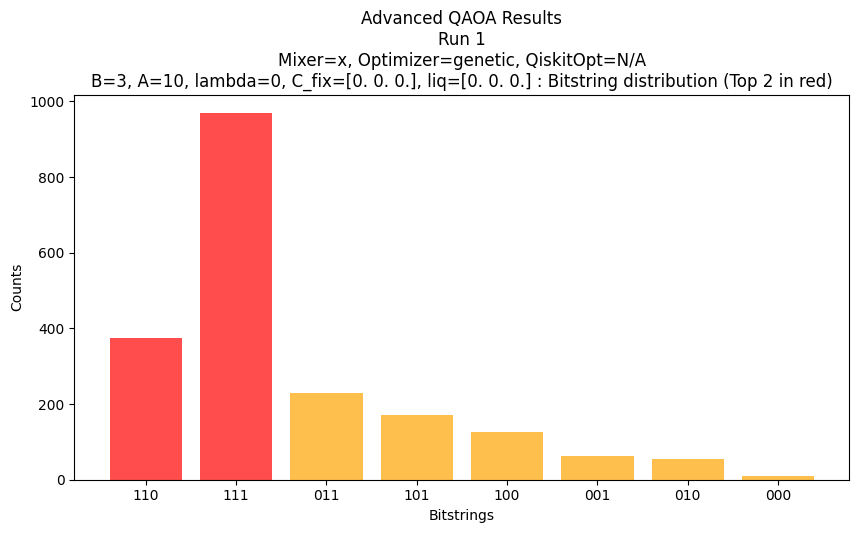

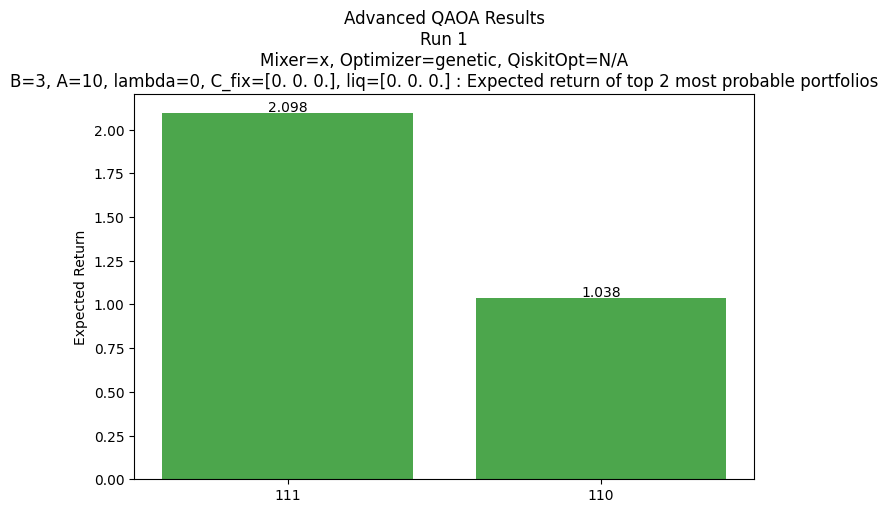

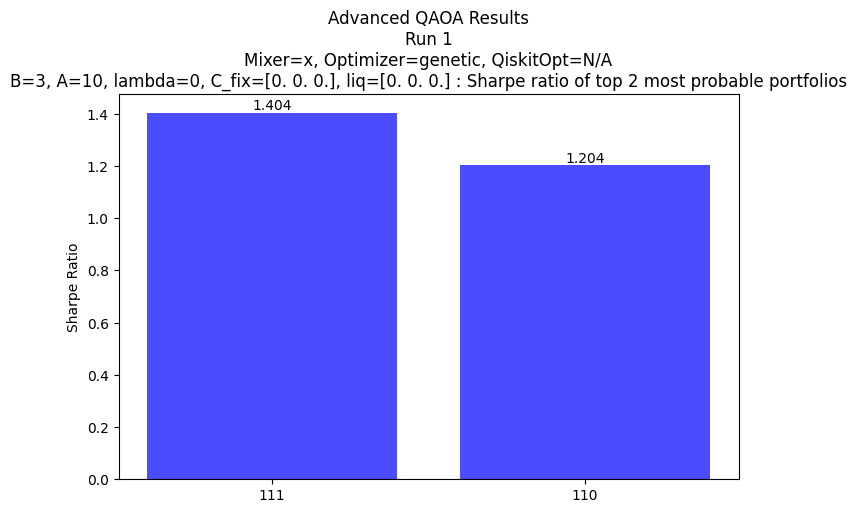

Run 1: best bitstring=111, selected assets=['BTC-USD', 'ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


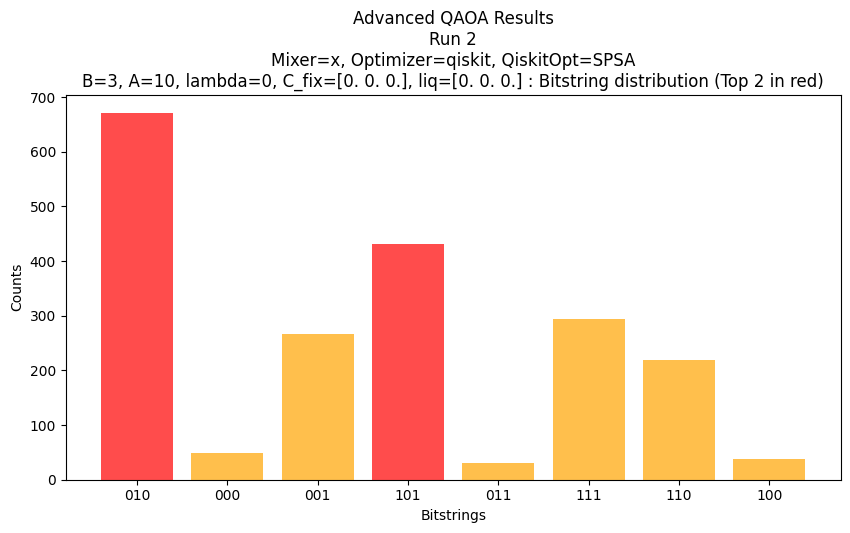

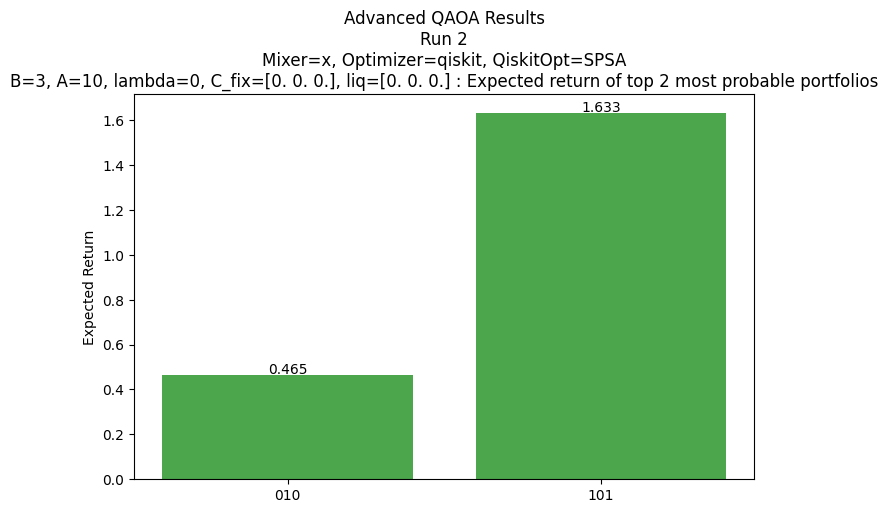

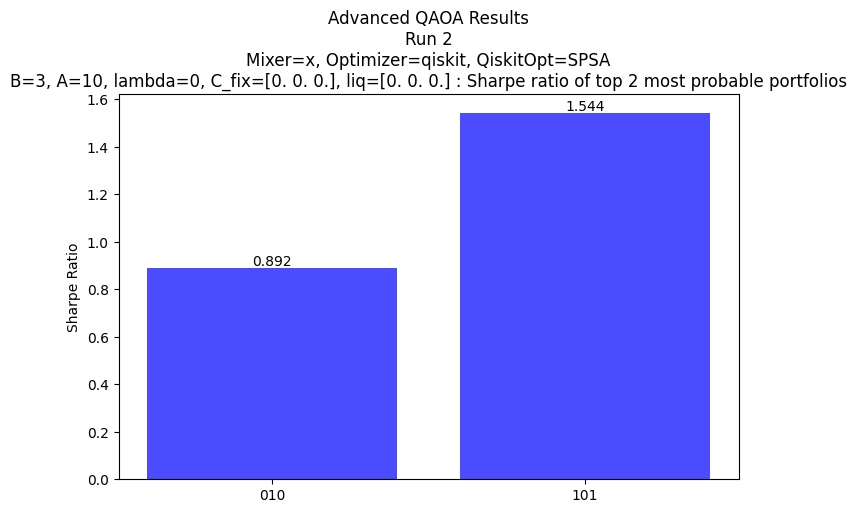

Run 2: best bitstring=010, selected assets=['ETH-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


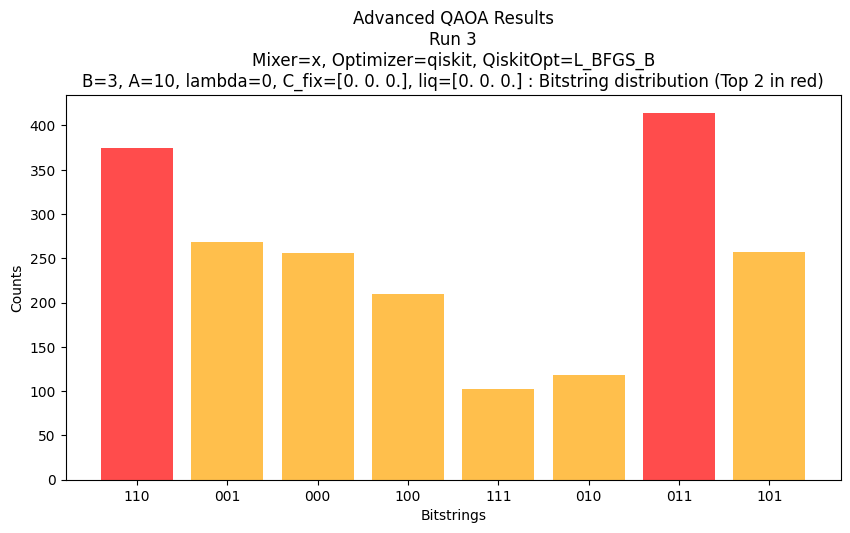

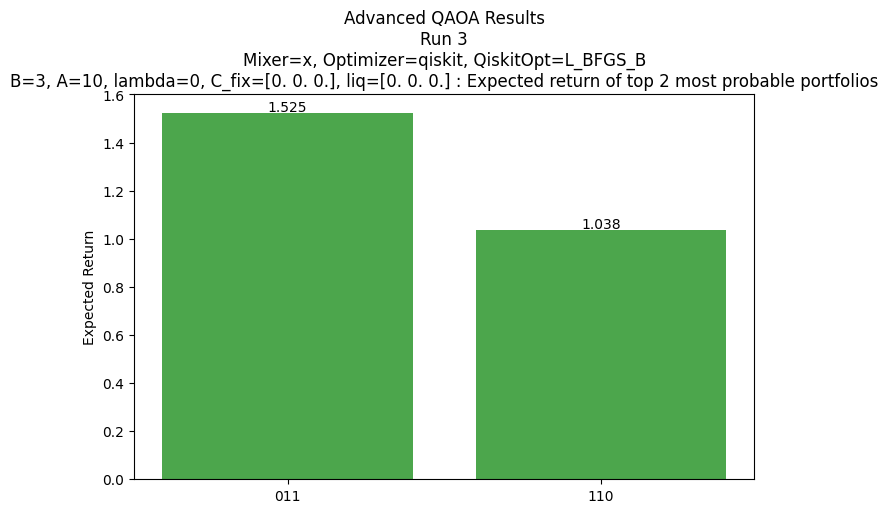

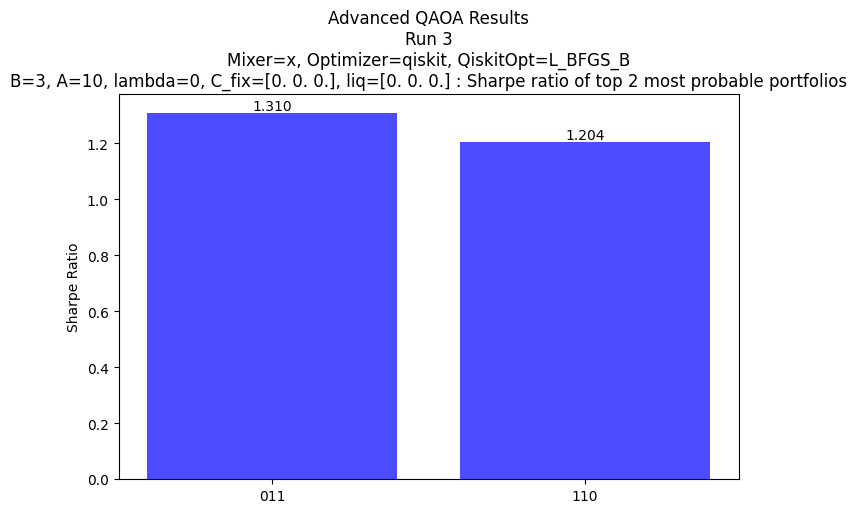

Run 3: best bitstring=011, selected assets=['ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


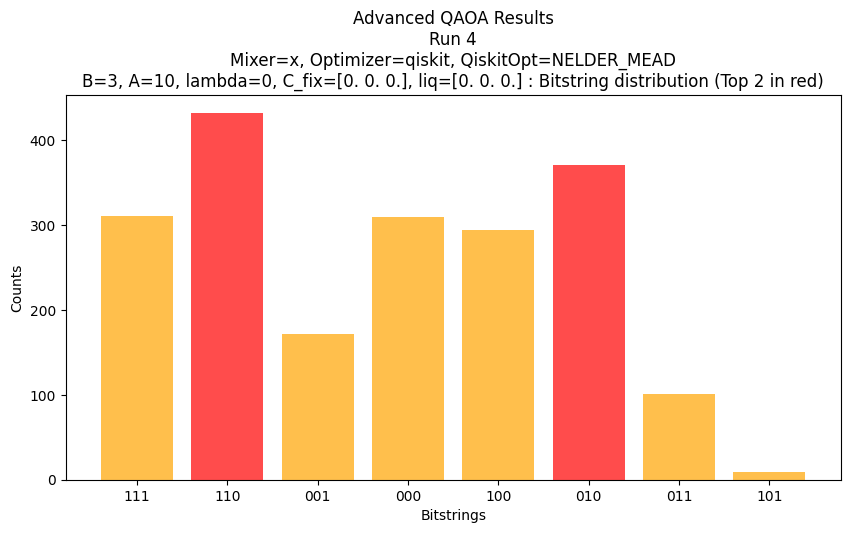

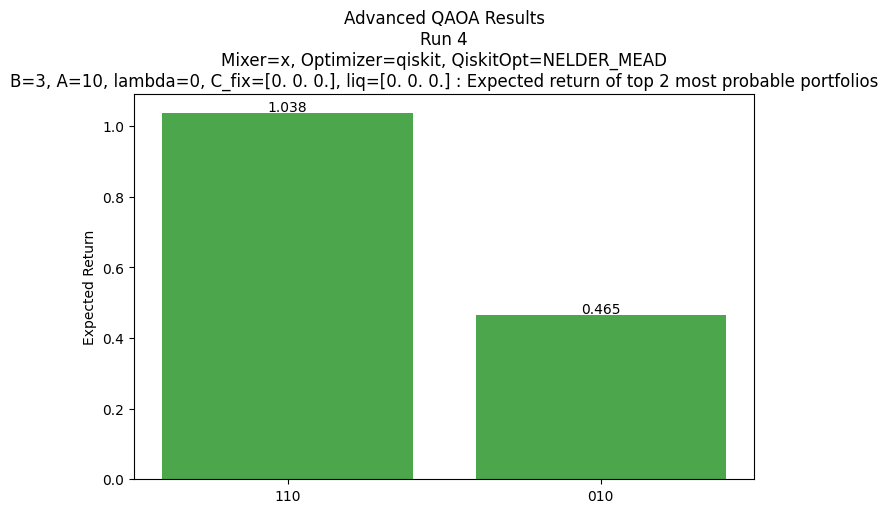

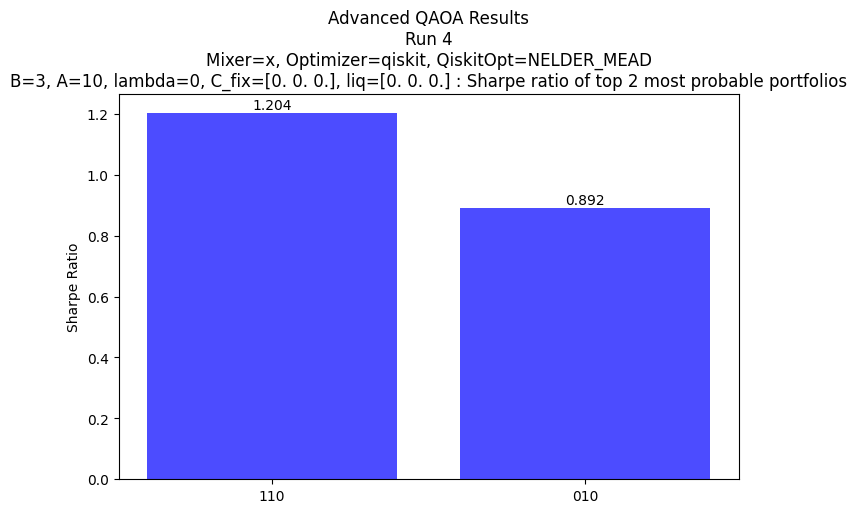

Run 4: best bitstring=110, selected assets=['BTC-USD', 'ETH-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


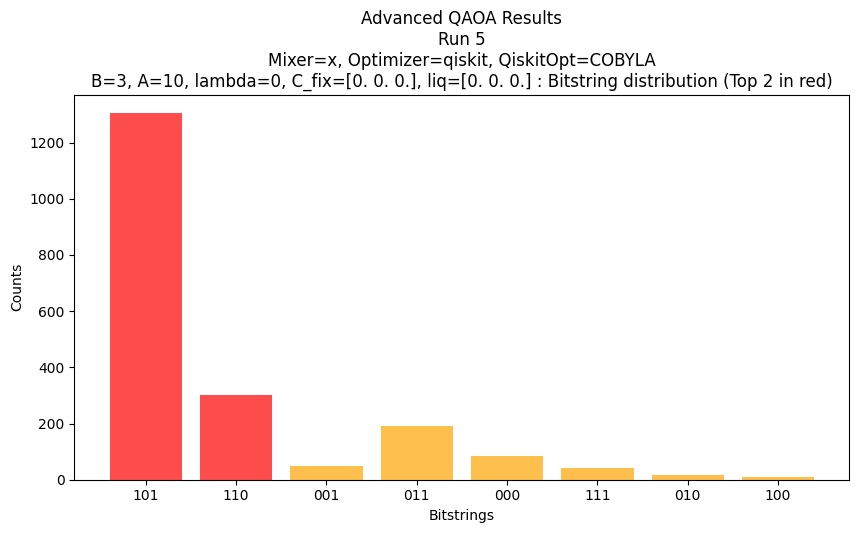

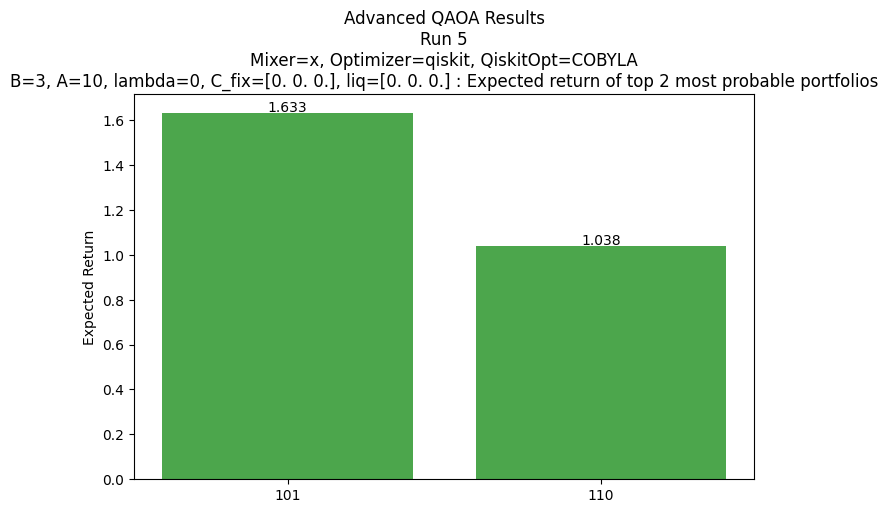

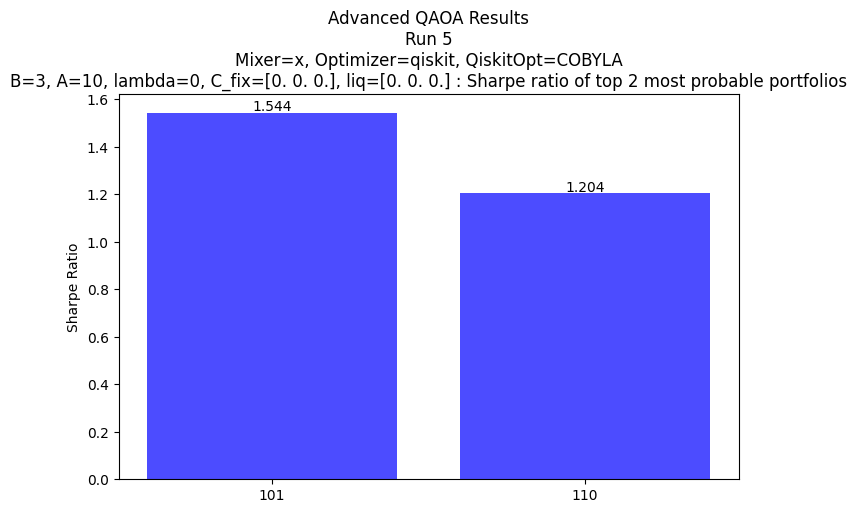

Run 5: best bitstring=101, selected assets=['BTC-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])
Generation 1/50, Best Energy = 11.510229
Generation 2/50, Best Energy = 11.510229
Generation 3/50, Best Energy = 11.510229
Generation 4/50, Best Energy = 11.510229
Generation 5/50, Best Energy = 11.510229
Generation 6/50, Best Energy = 11.510229
Generation 7/50, Best Energy = 11.510229
Generation 8/50, Best Energy = 11.510229
Generation 9/50, Best Energy = 11.510229
Generation 10/50, Best Energy = 11.510229
Generation 11/50, Best Energy = 11.510229
Generation 12/50, Best Energy = 11.510229
Generation 13/50, Best Energy = 11.510229
Generation 14/50, Best Energy = 11.510229
Generation 15/50, Best Energy = 11.370803
Generation 16/50, Best Energy = 11.370803
Generation 17/50, Best Energy = 1

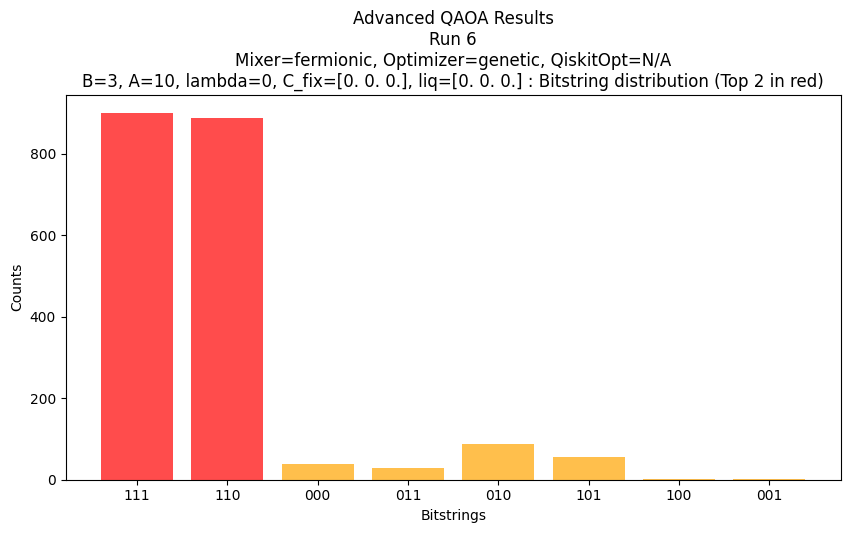

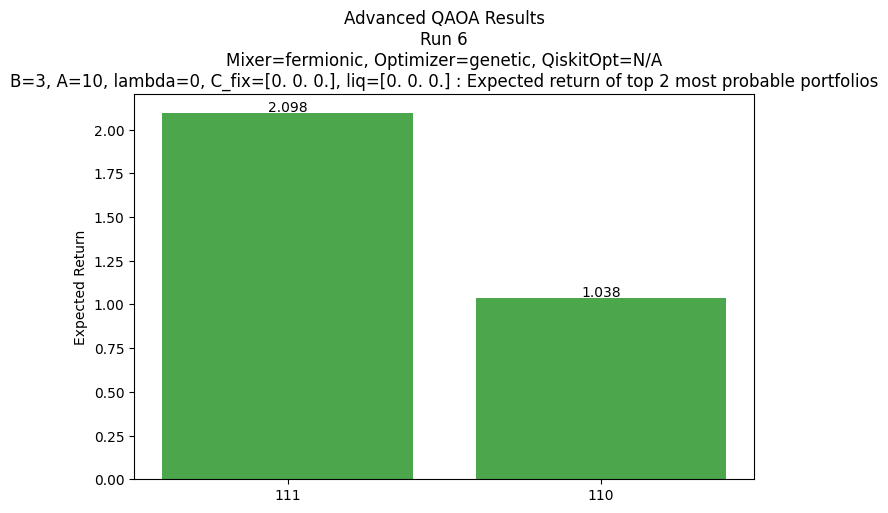

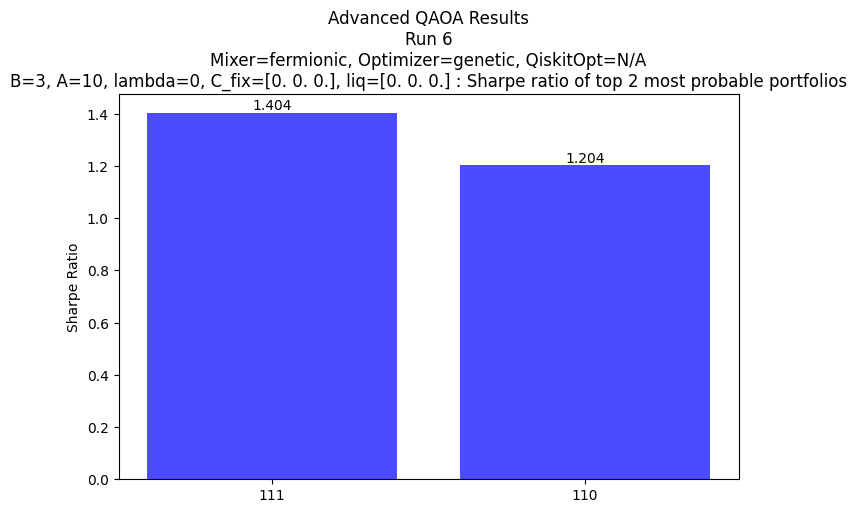

Run 6: best bitstring=111, selected assets=['BTC-USD', 'ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


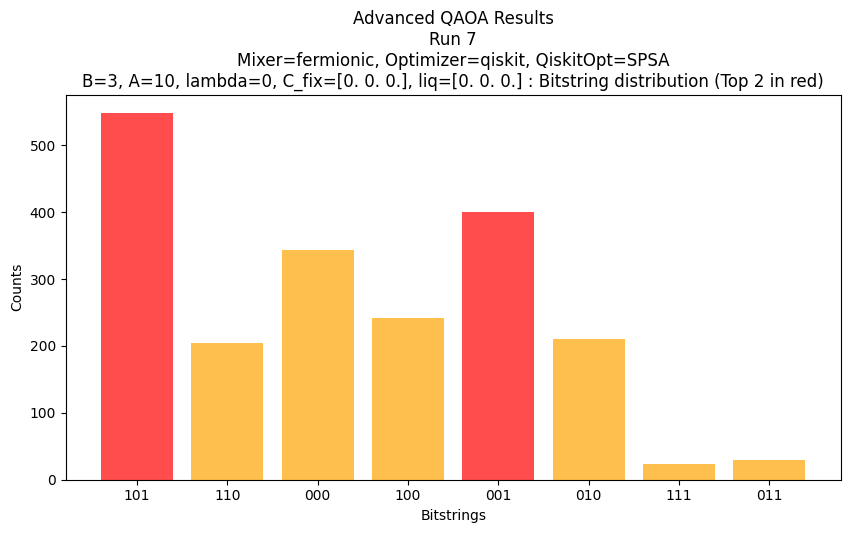

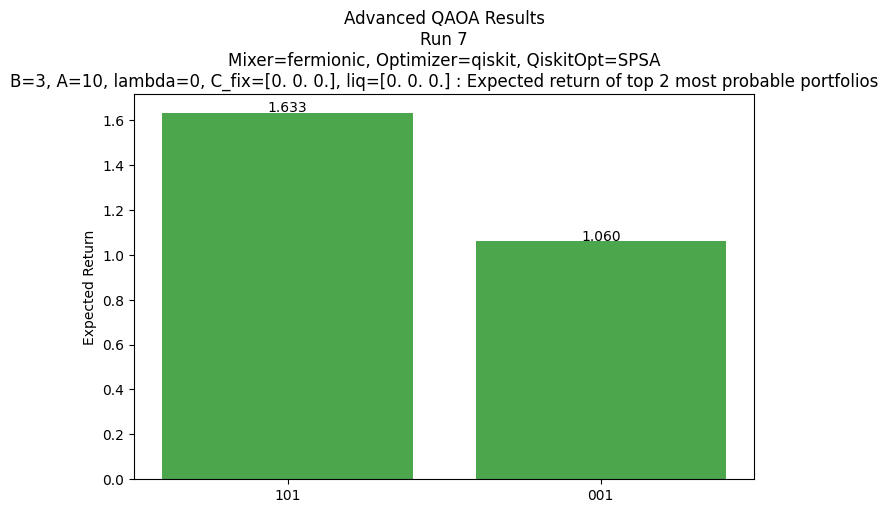

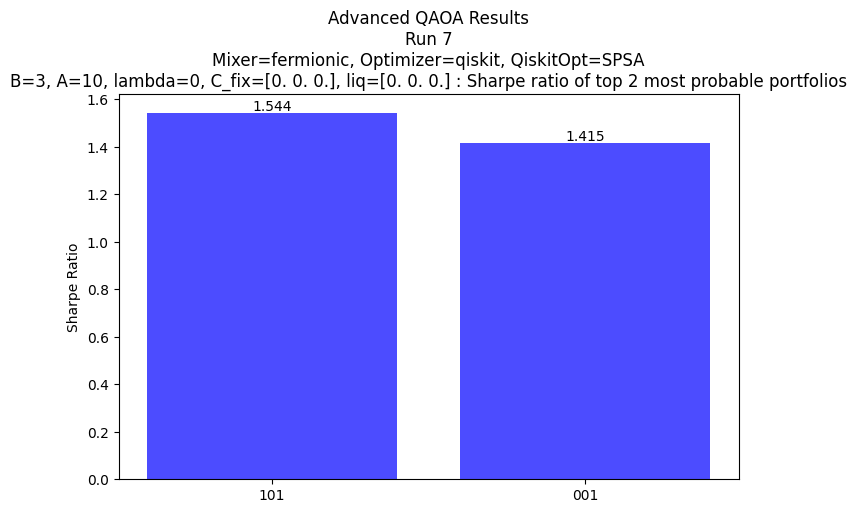

Run 7: best bitstring=101, selected assets=['BTC-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


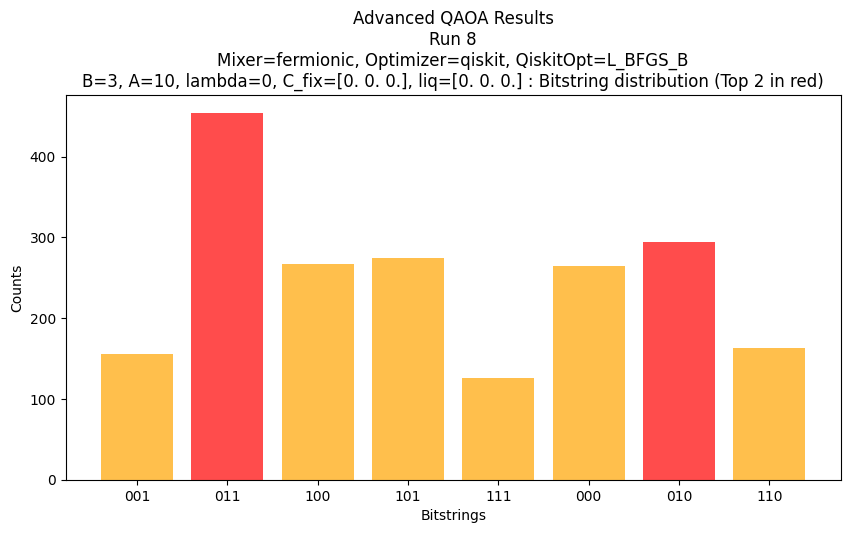

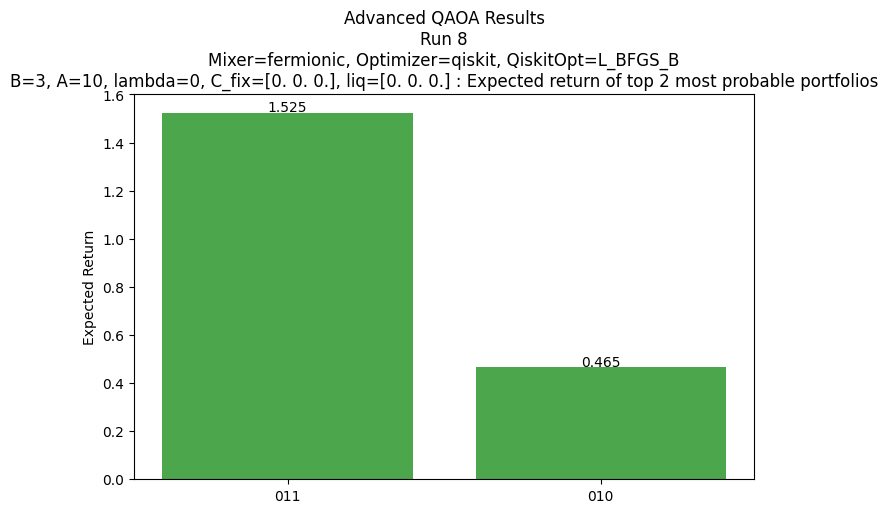

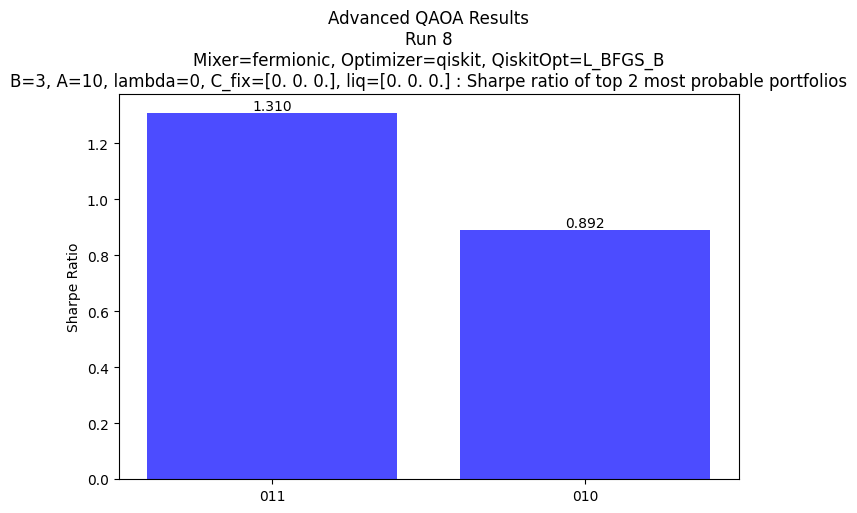

Run 8: best bitstring=011, selected assets=['ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


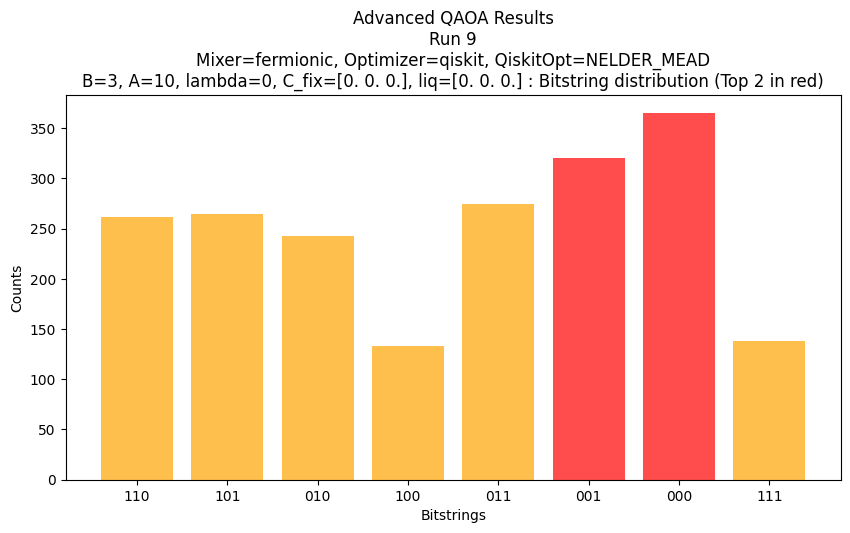

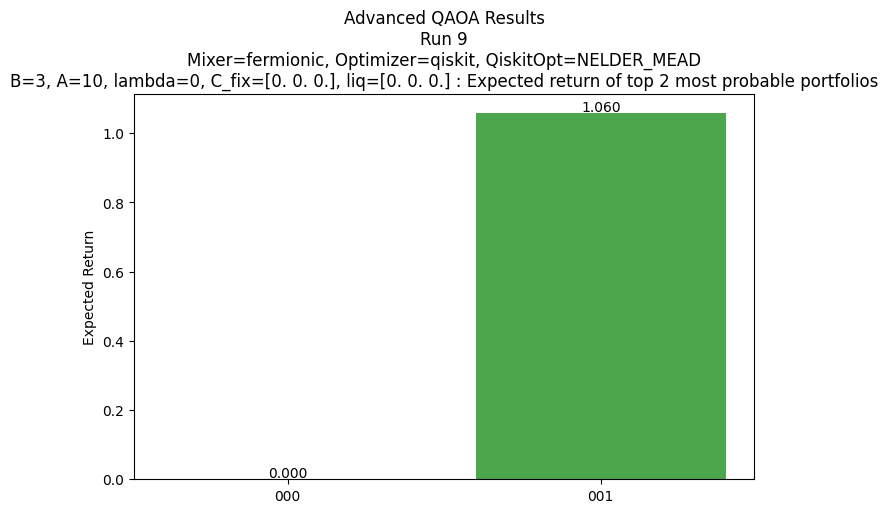

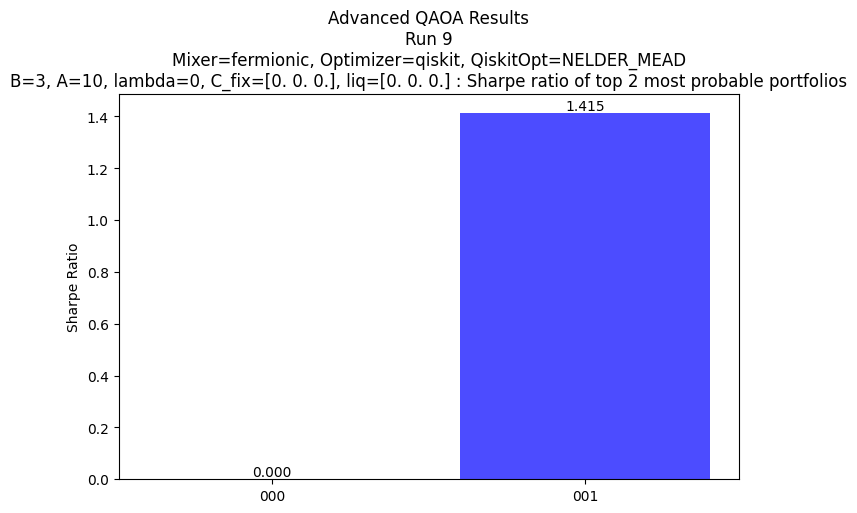

Run 9: best bitstring=000, selected assets=[]
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


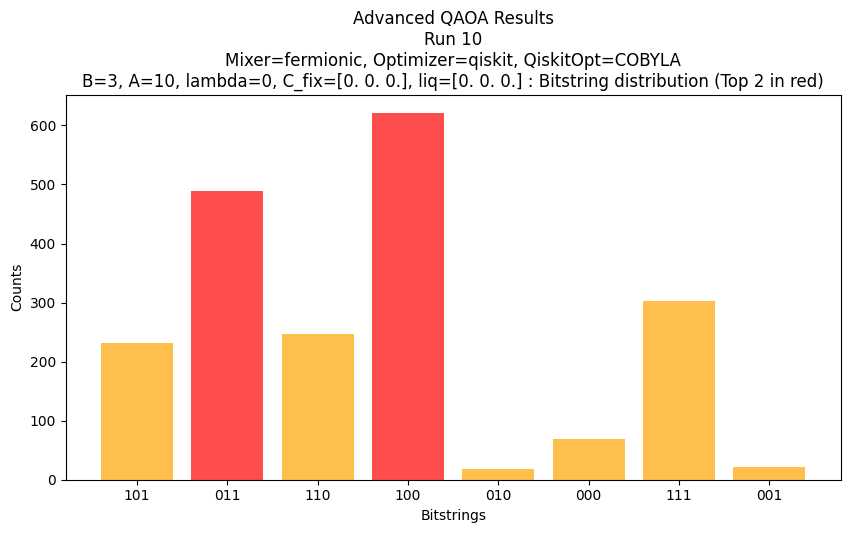

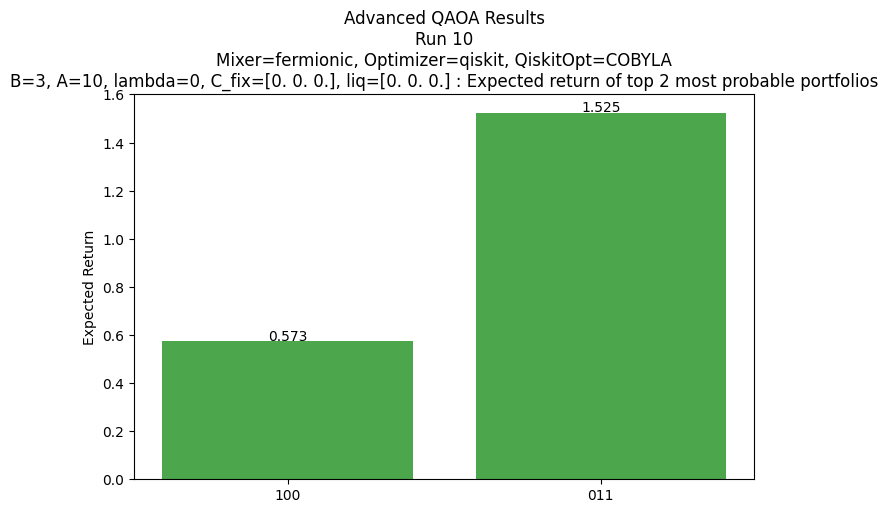

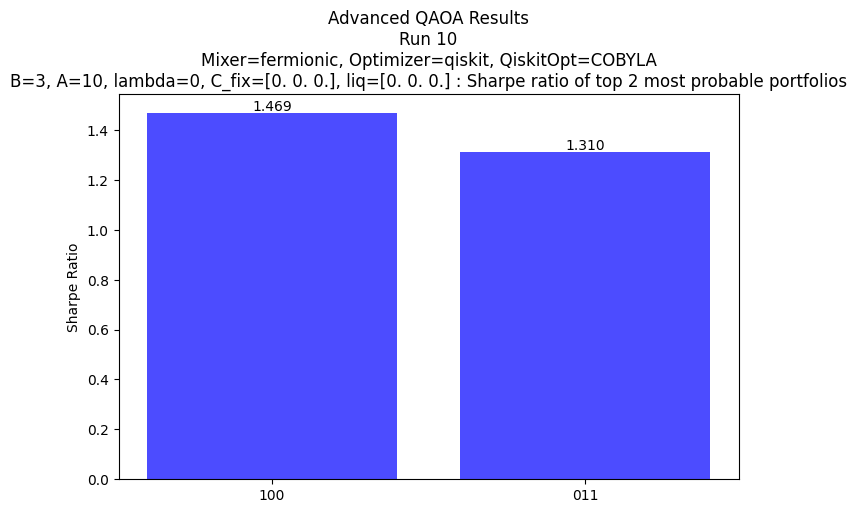

Run 10: best bitstring=100, selected assets=['BTC-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])
Generation 1/50, Best Energy = 13.059997
Generation 2/50, Best Energy = 13.059997
Generation 3/50, Best Energy = 13.059997
Generation 4/50, Best Energy = 11.744168
Generation 5/50, Best Energy = 9.635313
Generation 6/50, Best Energy = 9.635313
Generation 7/50, Best Energy = 9.635313
Generation 8/50, Best Energy = 9.635313
Generation 9/50, Best Energy = 9.635313
Generation 10/50, Best Energy = 9.635313
Generation 11/50, Best Energy = 9.635313
Generation 12/50, Best Energy = 9.635313
Generation 13/50, Best Energy = 9.635313
Generation 14/50, Best Energy = 9.635313
Generation 15/50, Best Energy = 8.622061
Generation 16/50, Best Energy = 8.472342
Generation 17/50, Best Energy = 8.472342
Generation 18/

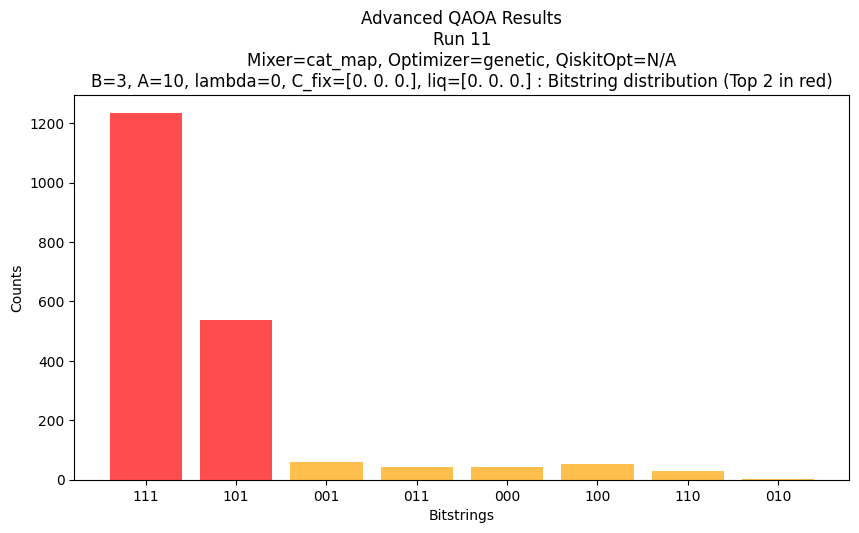

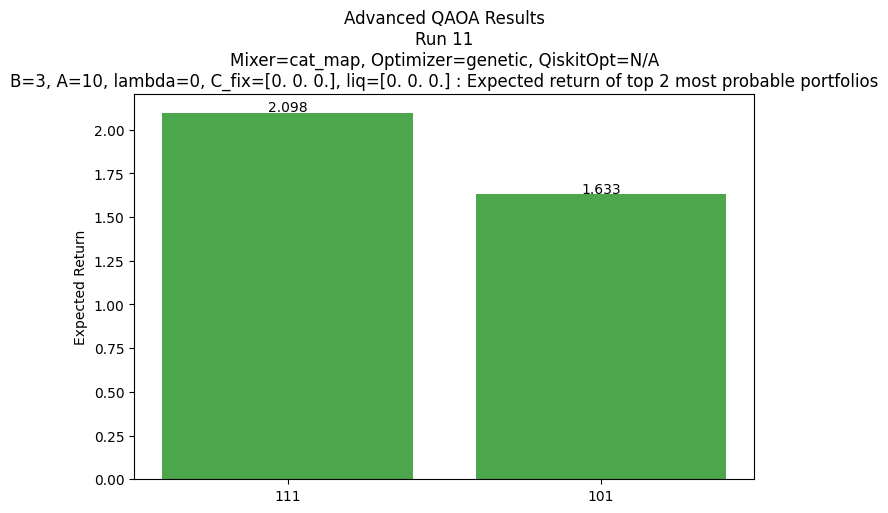

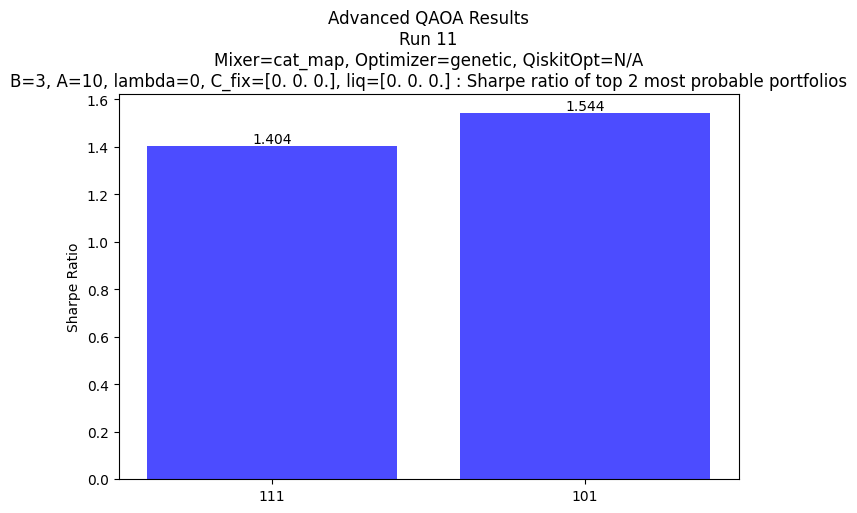

Run 11: best bitstring=111, selected assets=['BTC-USD', 'ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


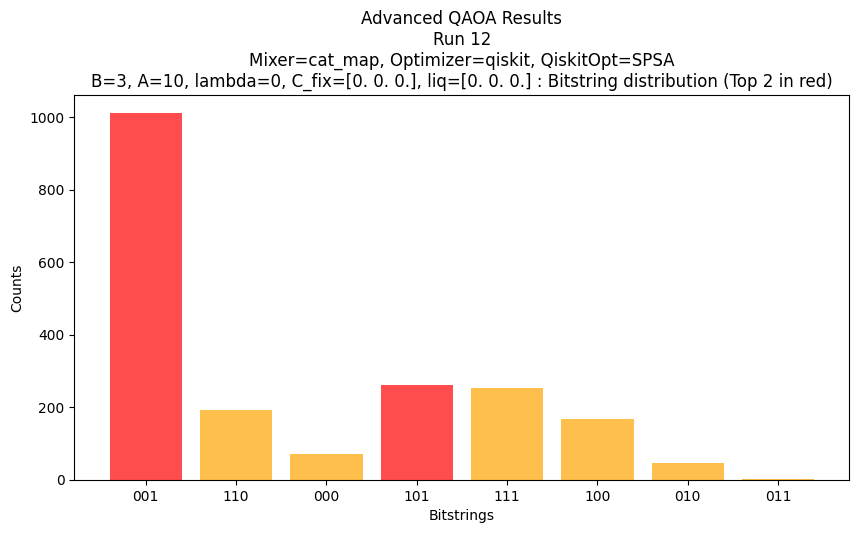

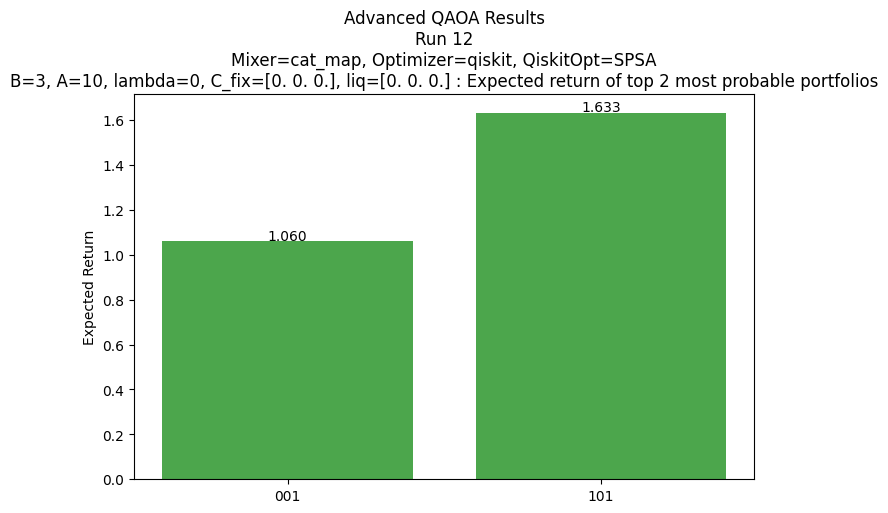

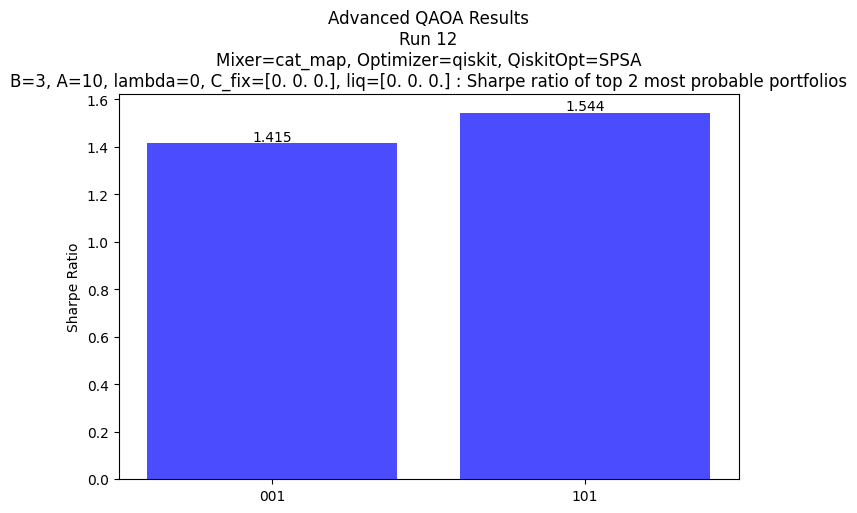

Run 12: best bitstring=001, selected assets=['SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


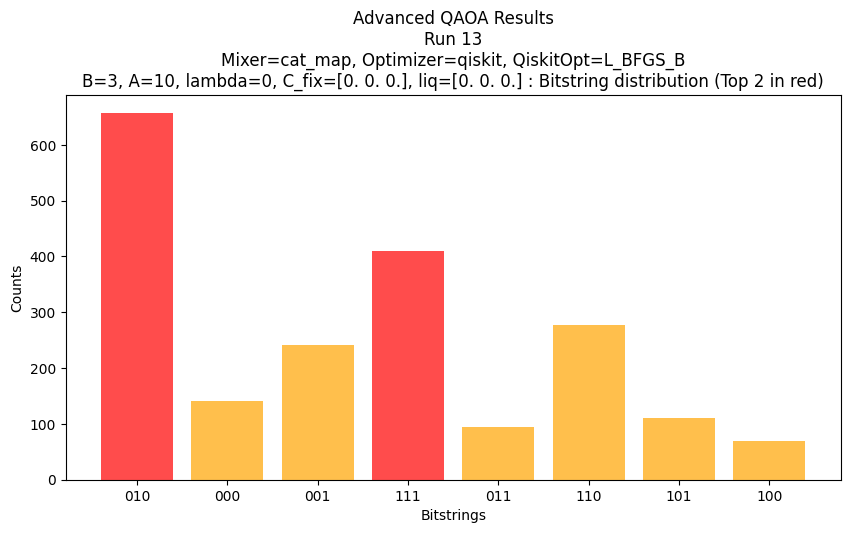

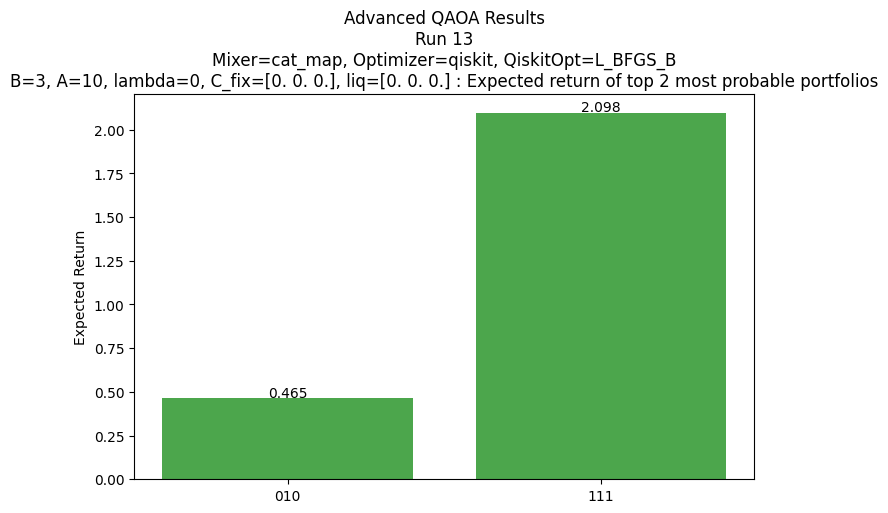

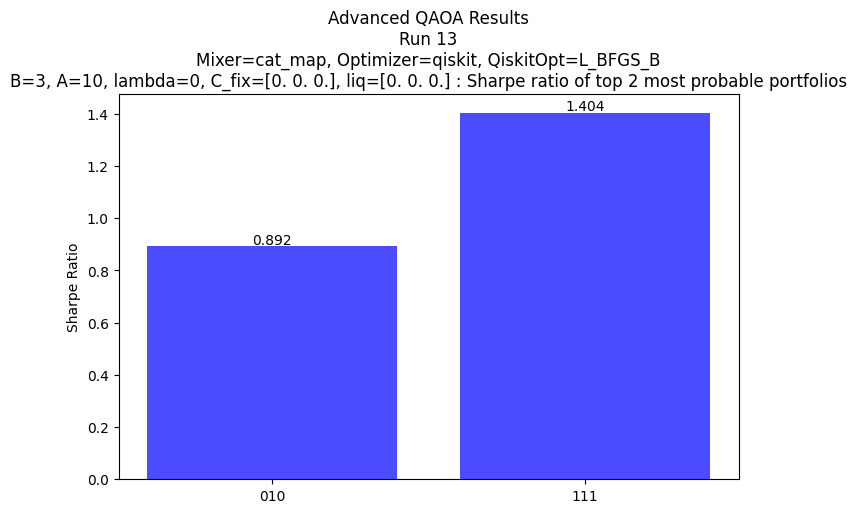

Run 13: best bitstring=010, selected assets=['ETH-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


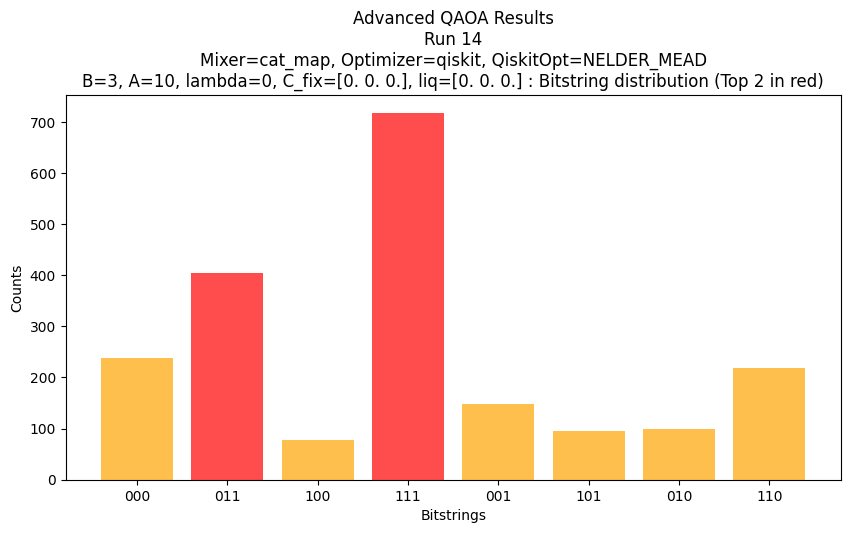

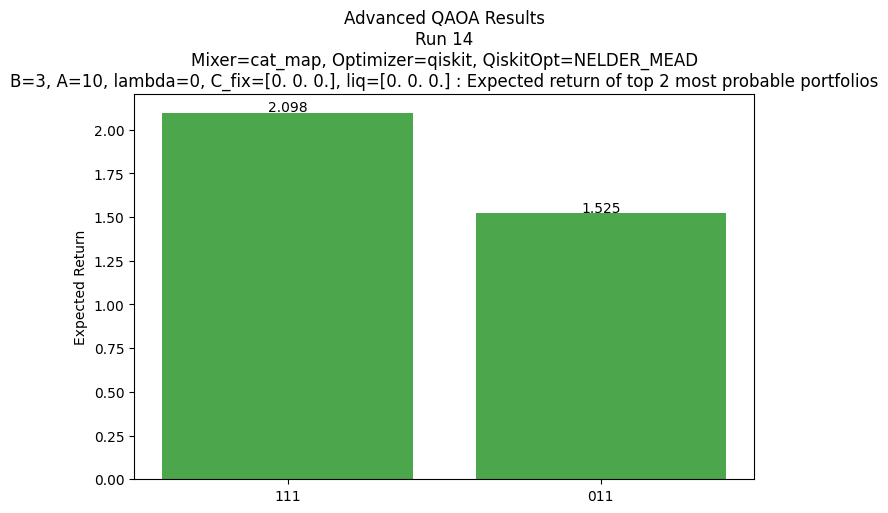

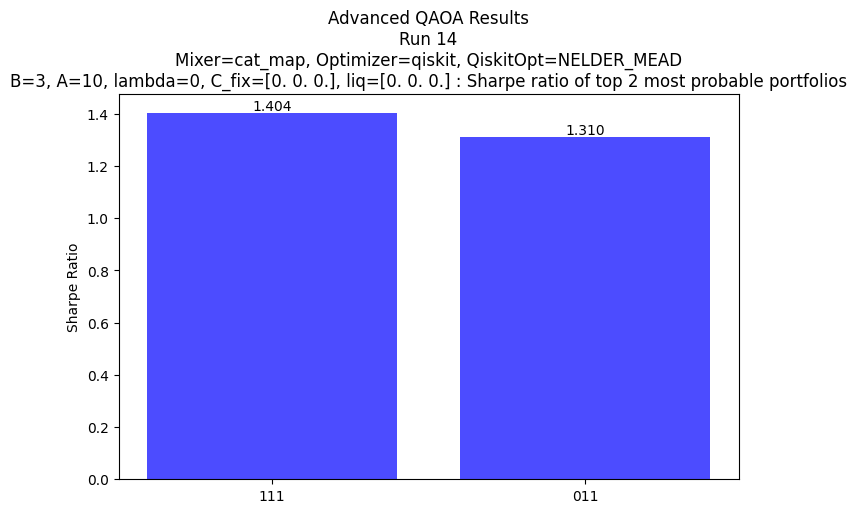

Run 14: best bitstring=111, selected assets=['BTC-USD', 'ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[29.50901863+0.j, 15.06746635+0.j, 14.9540377 +0.j, 15.1578651 +0.j,
  5.07987796+0.j,  5.1011182 +0.j,  5.13061606+0.j])


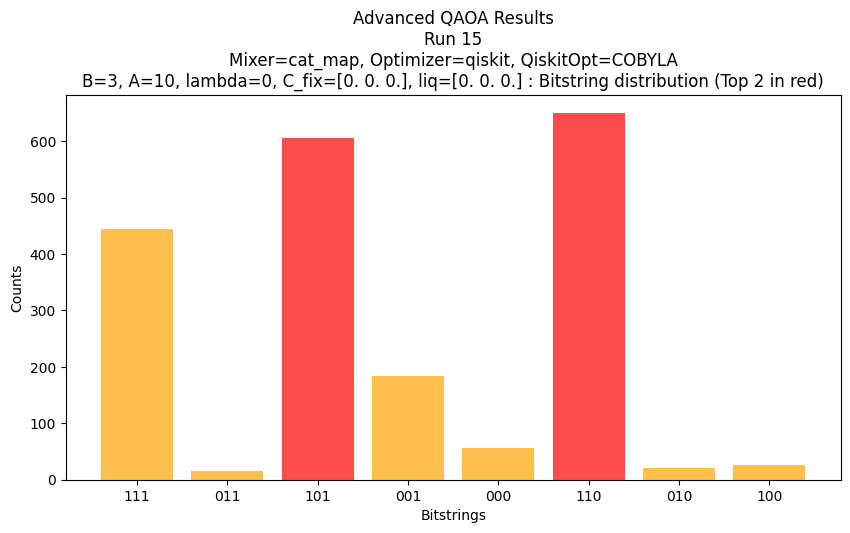

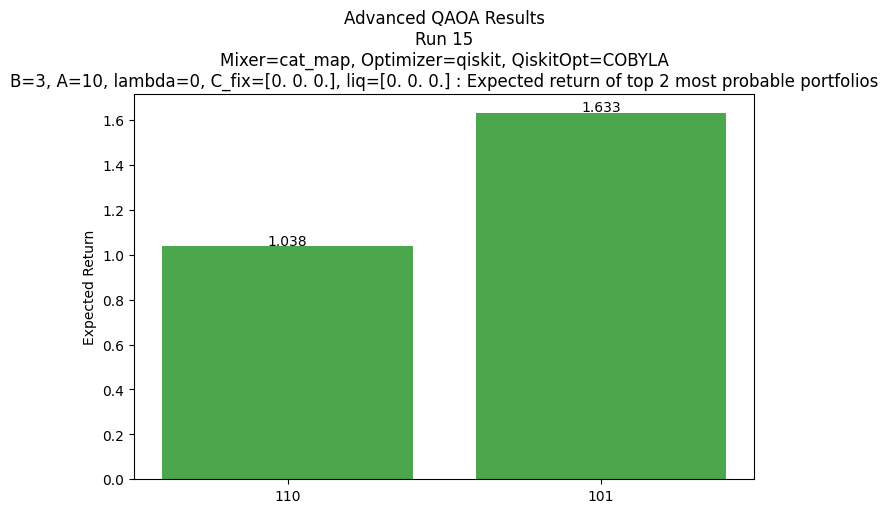

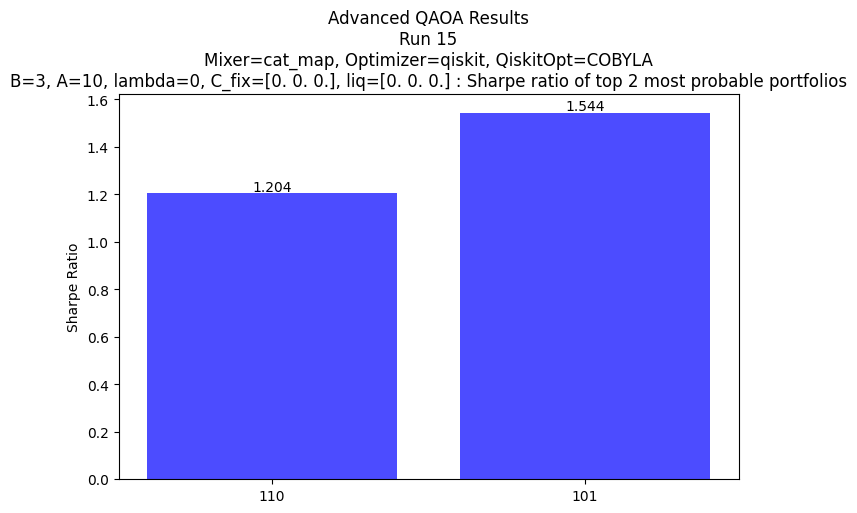

Run 15: best bitstring=110, selected assets=['BTC-USD', 'ETH-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])
Generation 1/50, Best Energy = 20.272787
Generation 2/50, Best Energy = 18.397064
Generation 3/50, Best Energy = 15.631883
Generation 4/50, Best Energy = 15.631883
Generation 5/50, Best Energy = 15.631883
Generation 6/50, Best Energy = 13.983951
Generation 7/50, Best Energy = 13.983951
Generation 8/50, Best Energy = 13.983951
Generation 9/50, Best Energy = 13.983951
Generation 10/50, Best Energy = 13.983951
Generation 11/50, Best Energy = 13.983951
Generation 12/50, Best Energy = 13.983951
Generation 13/50, Best Energy = 13.983951
Generation 14/50, Best Energy = 13.983951
Generation 15/50, Best Energy = 13.983951
Generation 16/50, Best Energy = 13.983951
Generation 17/50, Best Energy = 

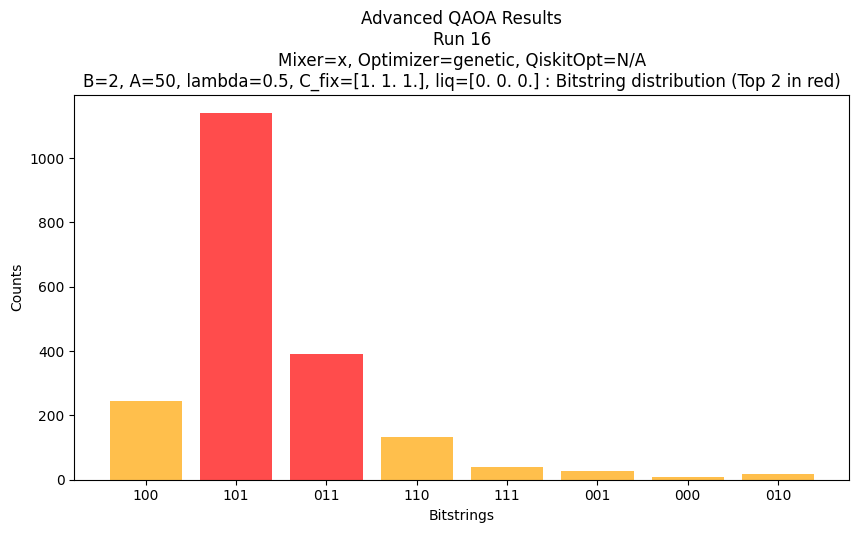

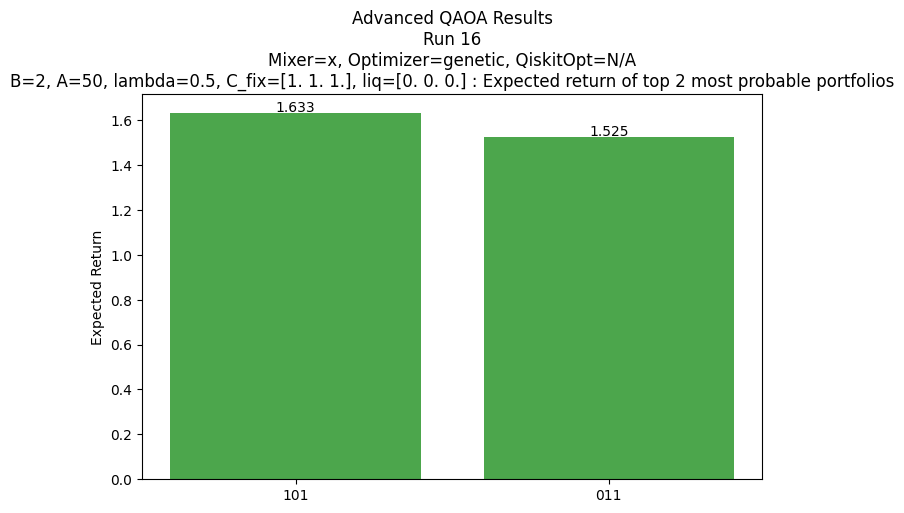

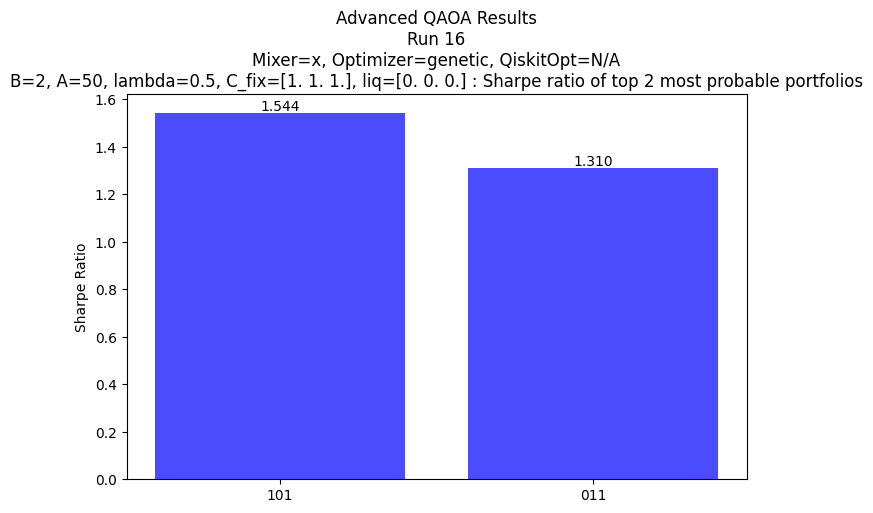

Run 16: best bitstring=101, selected assets=['BTC-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


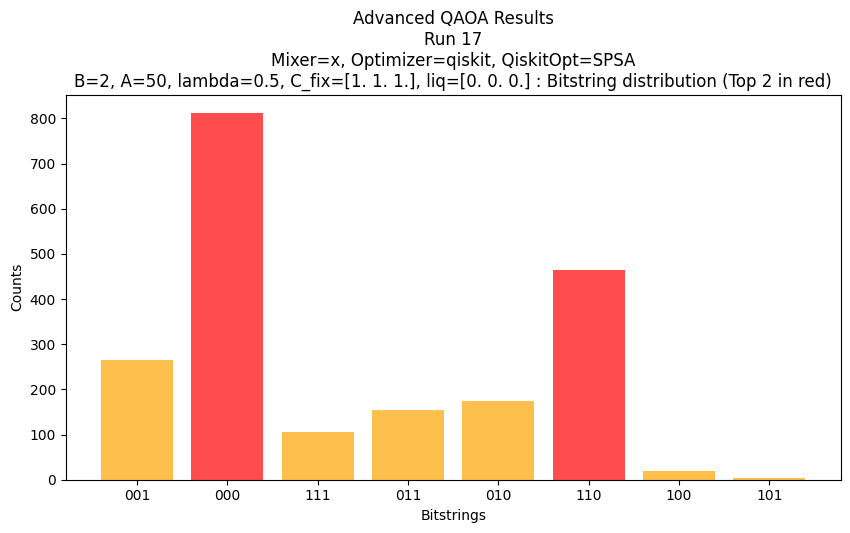

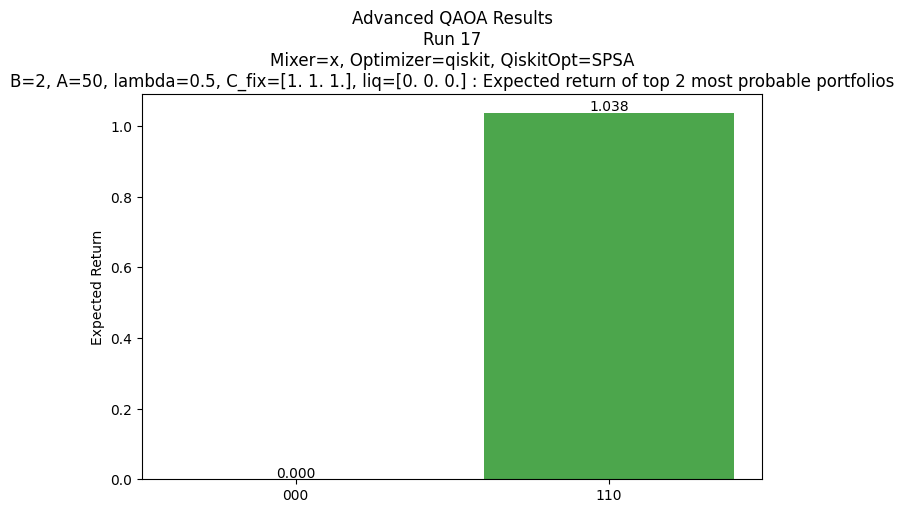

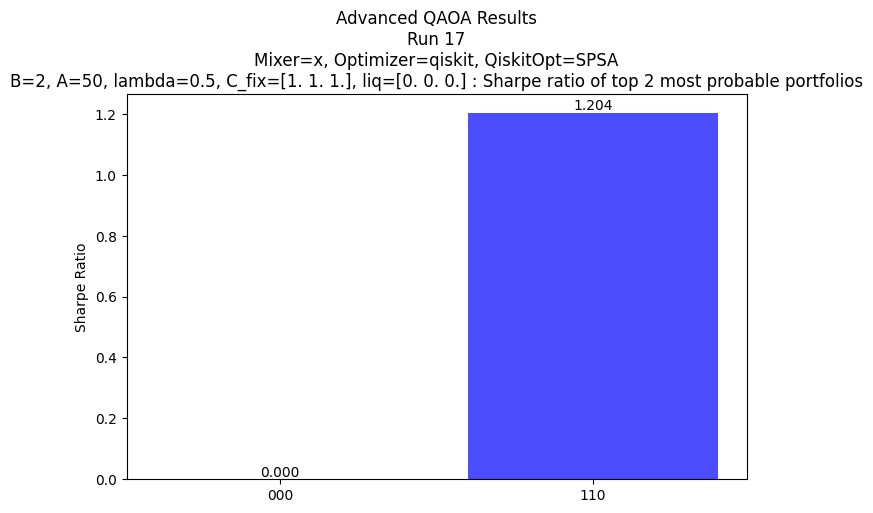

Run 17: best bitstring=000, selected assets=[]
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


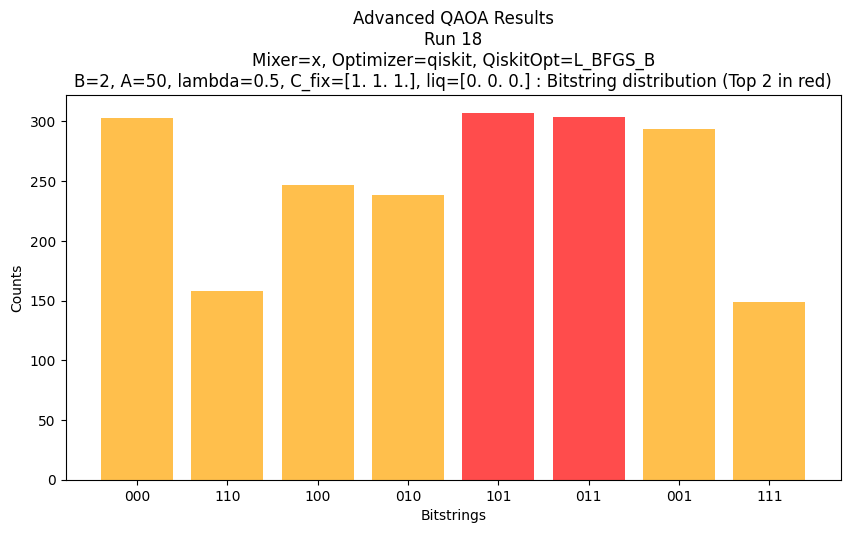

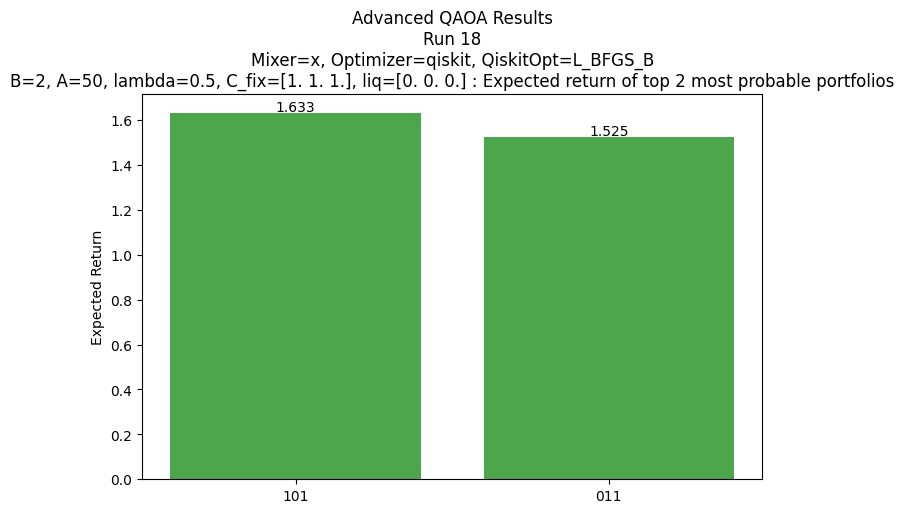

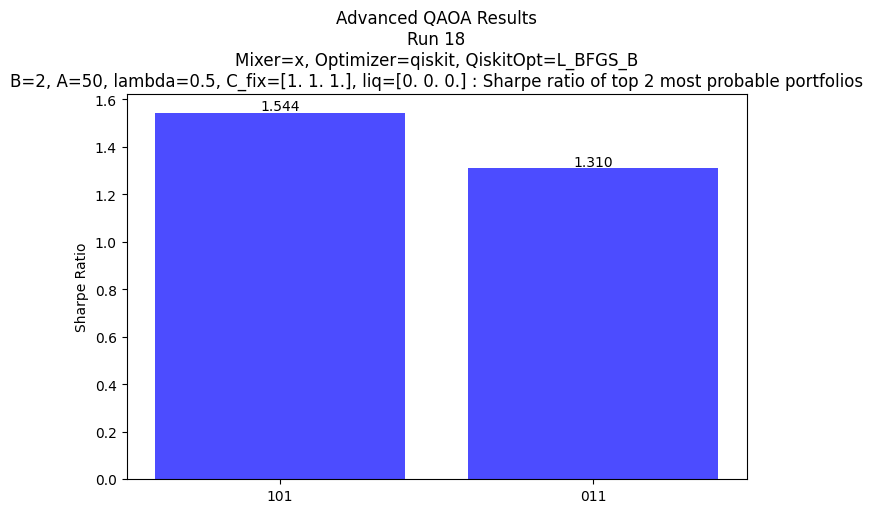

Run 18: best bitstring=101, selected assets=['BTC-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


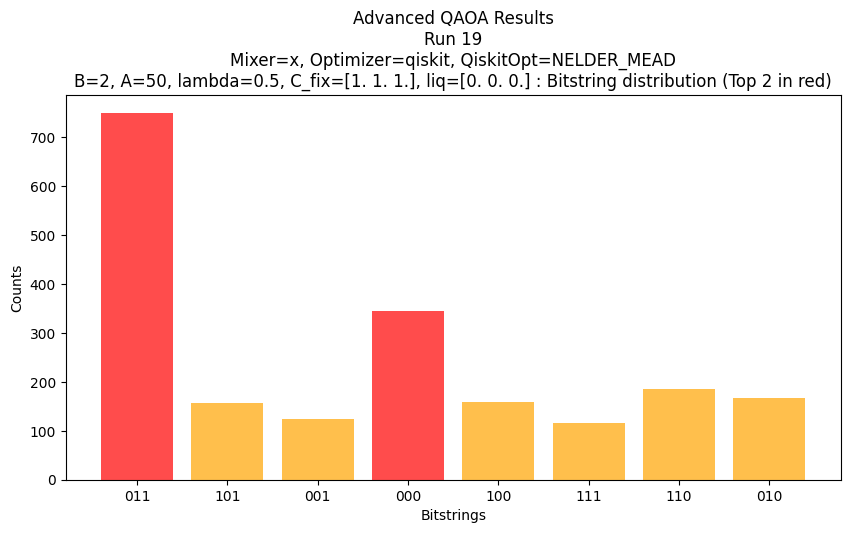

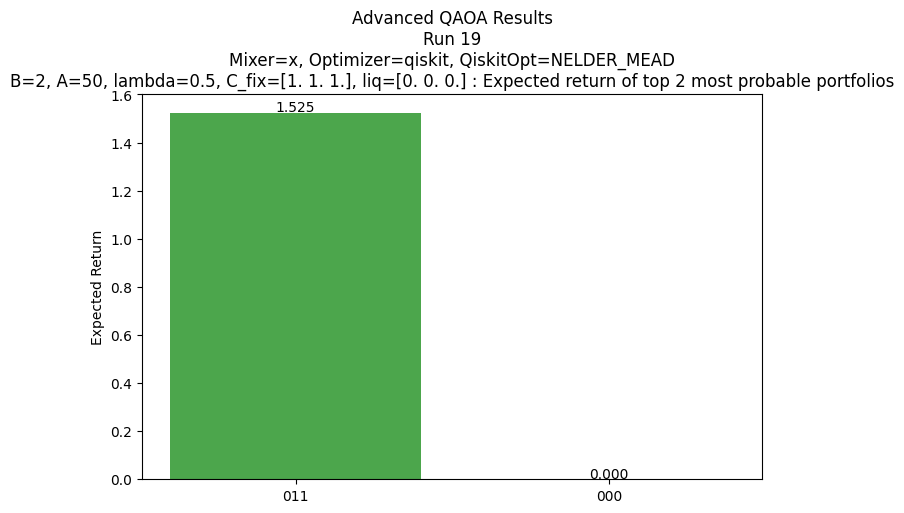

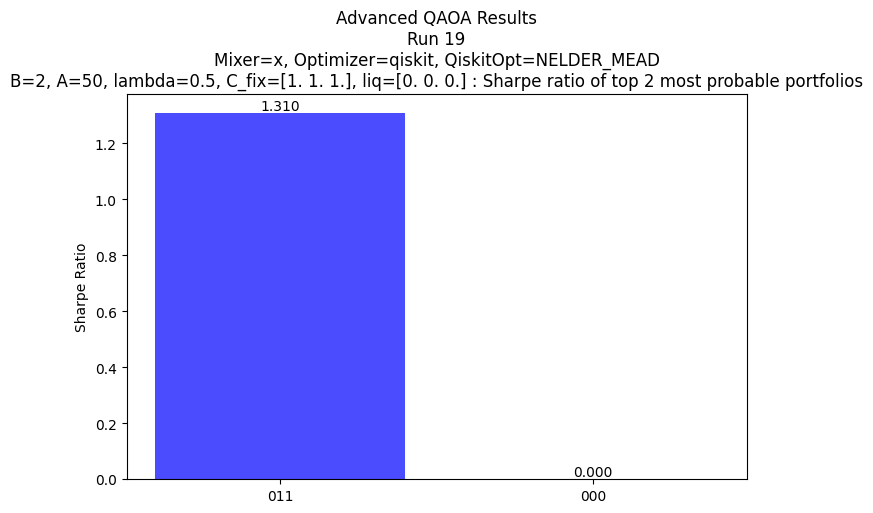

Run 19: best bitstring=011, selected assets=['ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


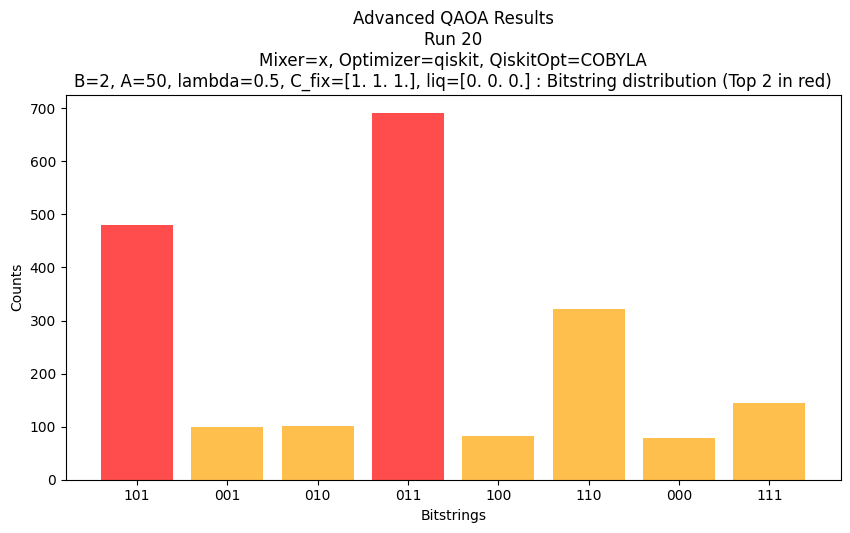

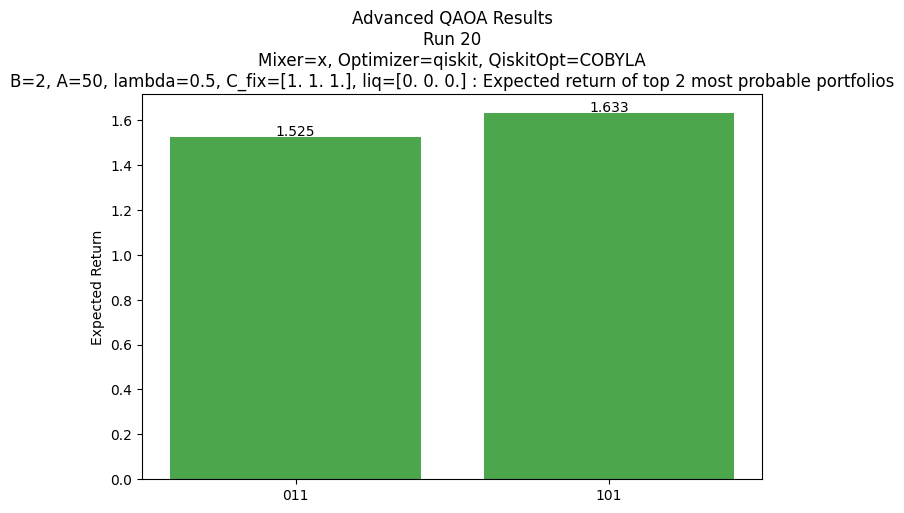

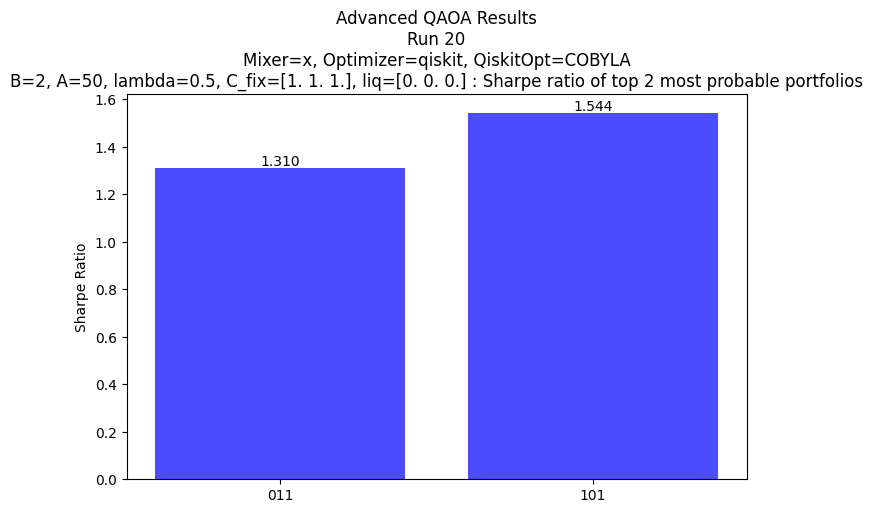

Run 20: best bitstring=011, selected assets=['ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])
Generation 1/50, Best Energy = 22.963724
Generation 2/50, Best Energy = 12.804295
Generation 3/50, Best Energy = 12.804295
Generation 4/50, Best Energy = 12.804295
Generation 5/50, Best Energy = 12.804295
Generation 6/50, Best Energy = 12.804295
Generation 7/50, Best Energy = 12.804295
Generation 8/50, Best Energy = 12.804295
Generation 9/50, Best Energy = 12.804295
Generation 10/50, Best Energy = 12.804295
Generation 11/50, Best Energy = 12.804295
Generation 12/50, Best Energy = 12.804295
Generation 13/50, Best Energy = 12.804295
Generation 14/50, Best Energy = 12.386115
Generation 15/50, Best Energy = 12.386115
Generation 16/50, Best Energy = 12.386115
Generation 17/50, Best Energy = 

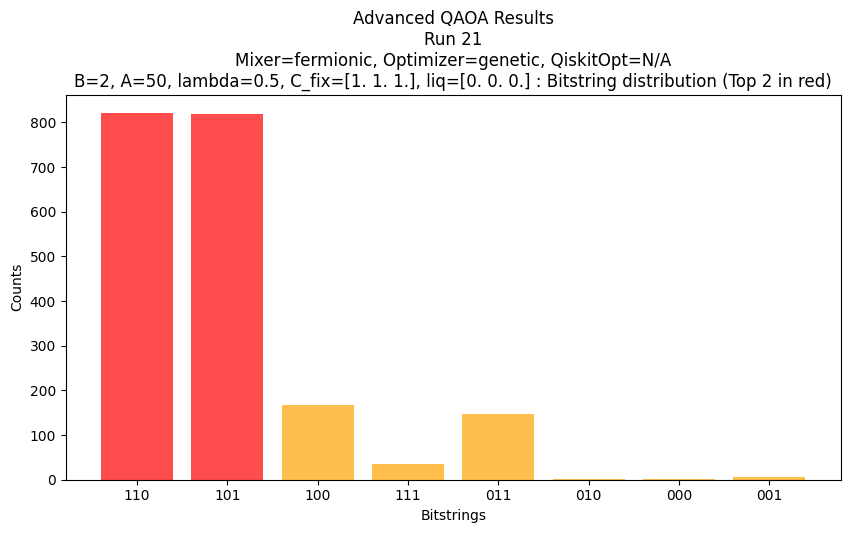

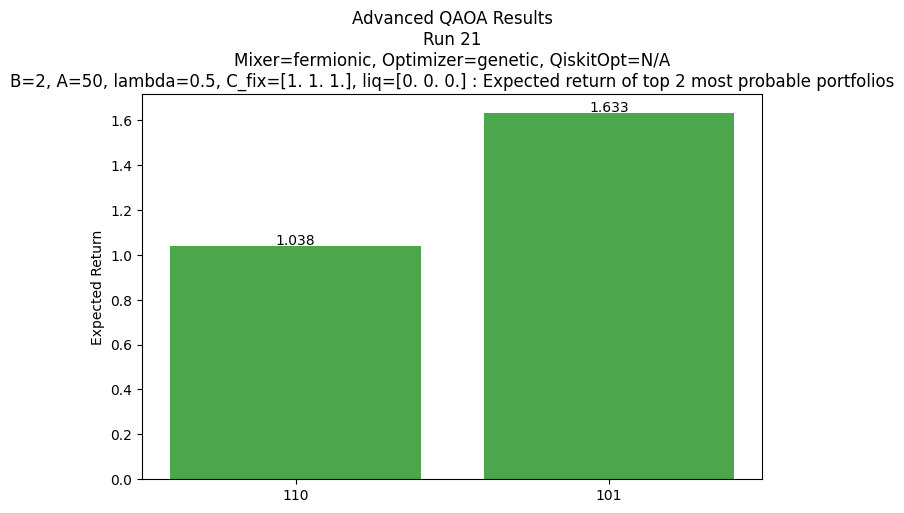

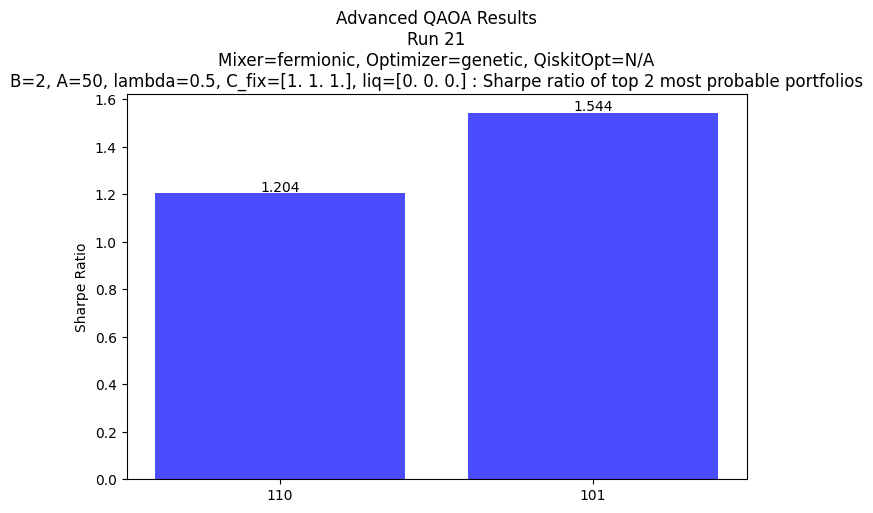

Run 21: best bitstring=110, selected assets=['BTC-USD', 'ETH-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


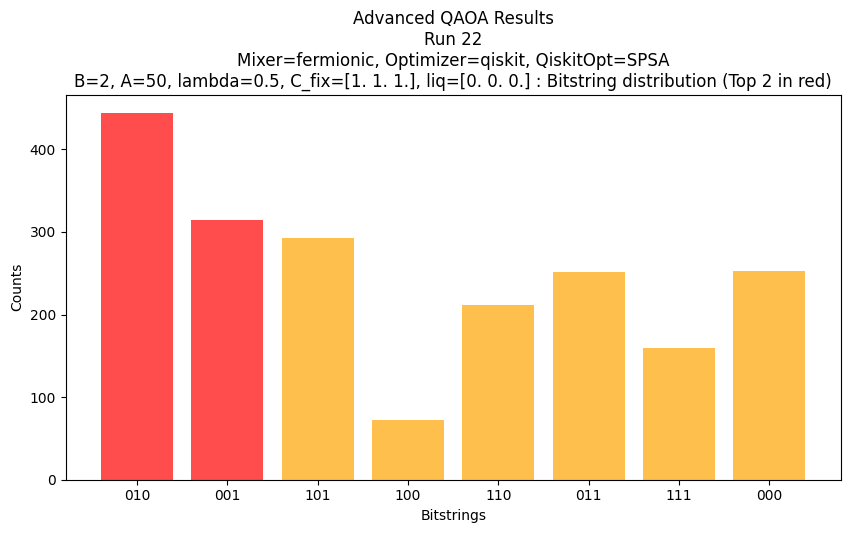

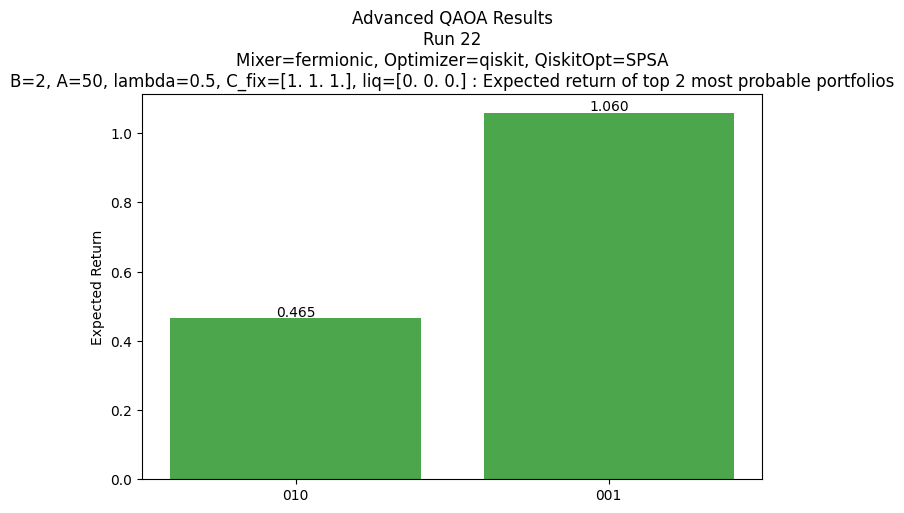

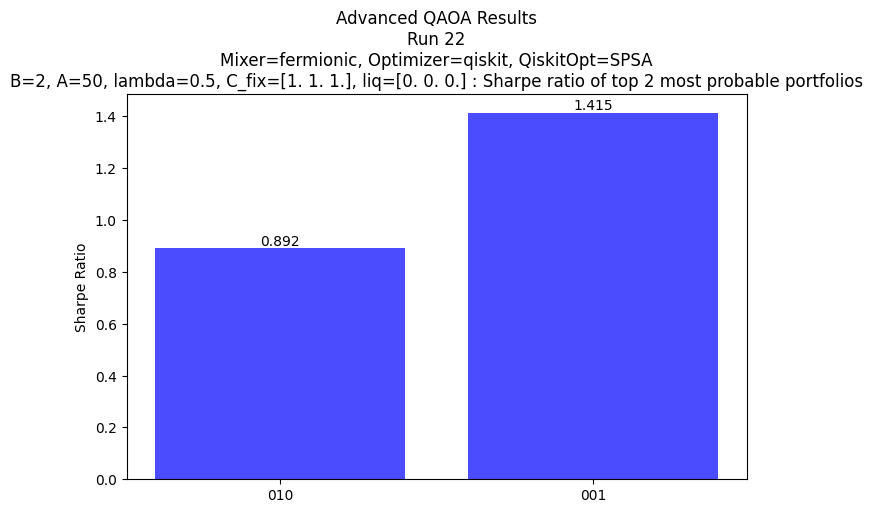

Run 22: best bitstring=010, selected assets=['ETH-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


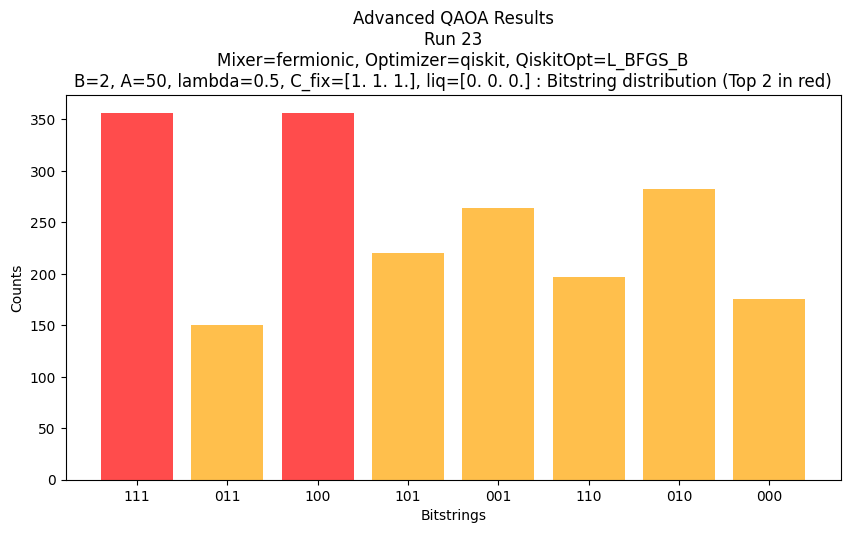

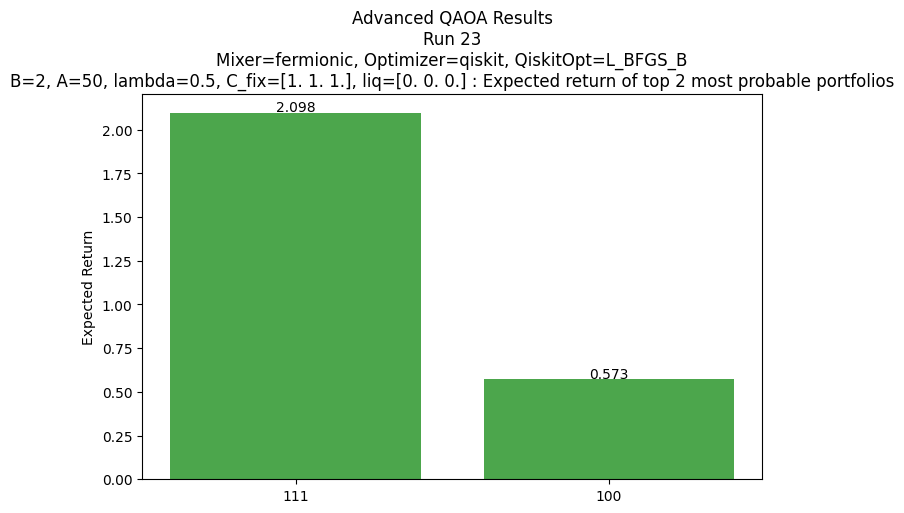

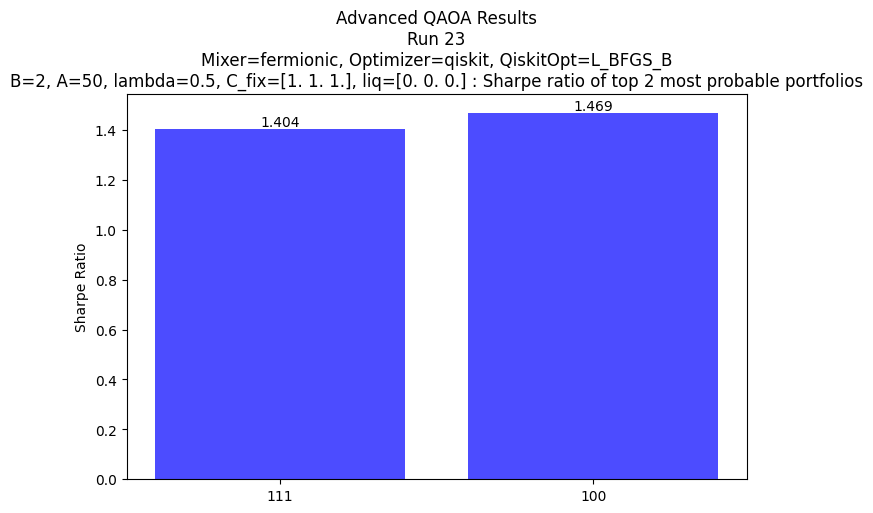

Run 23: best bitstring=111, selected assets=['BTC-USD', 'ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


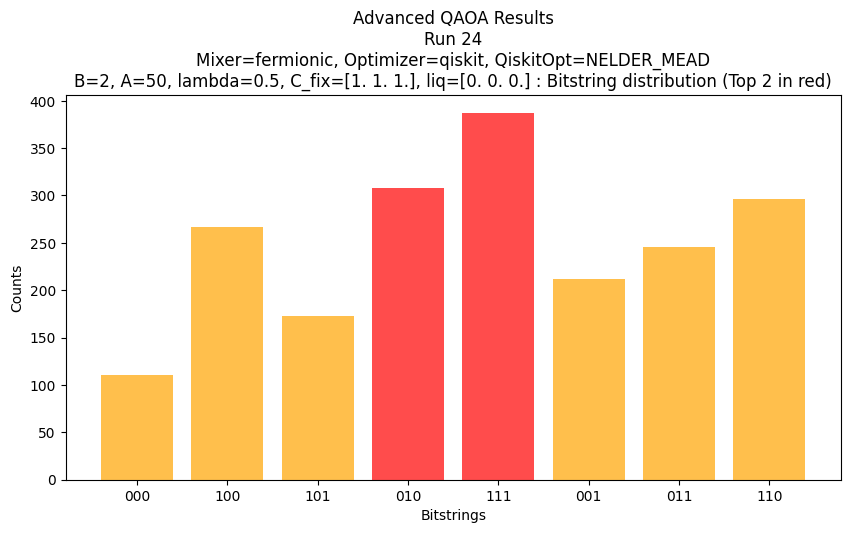

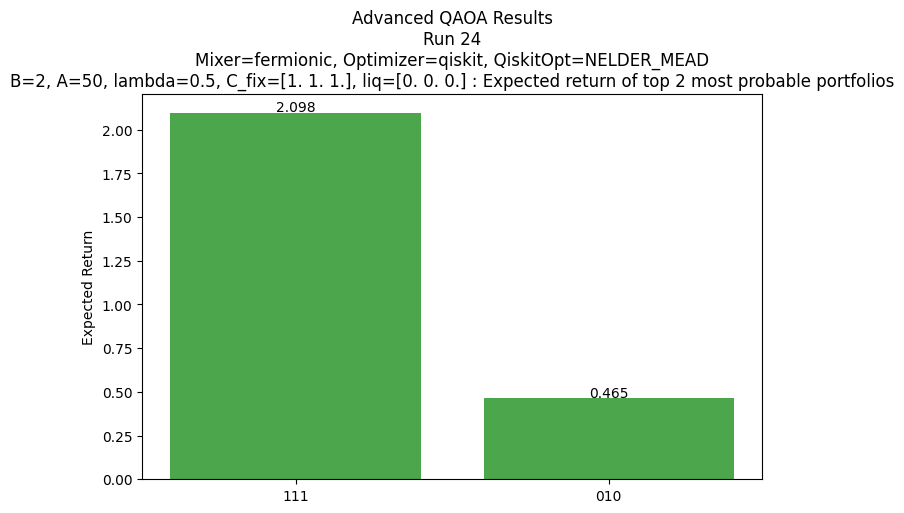

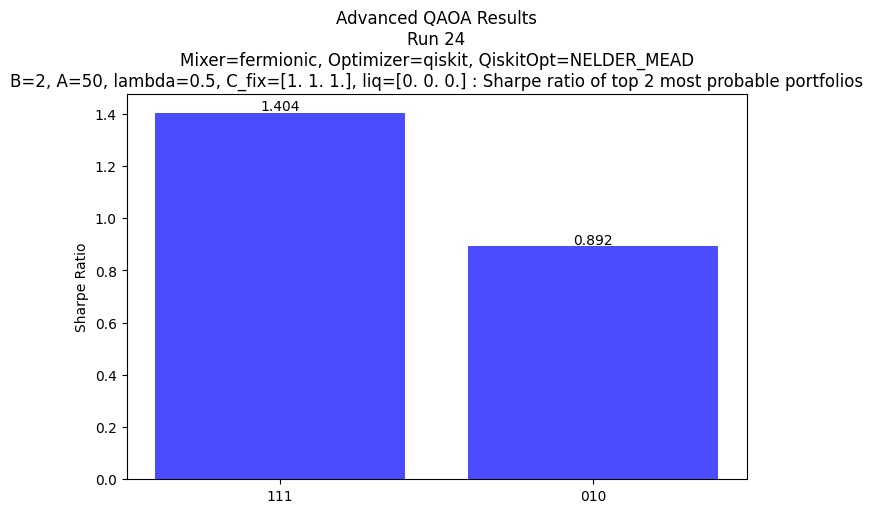

Run 24: best bitstring=111, selected assets=['BTC-USD', 'ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


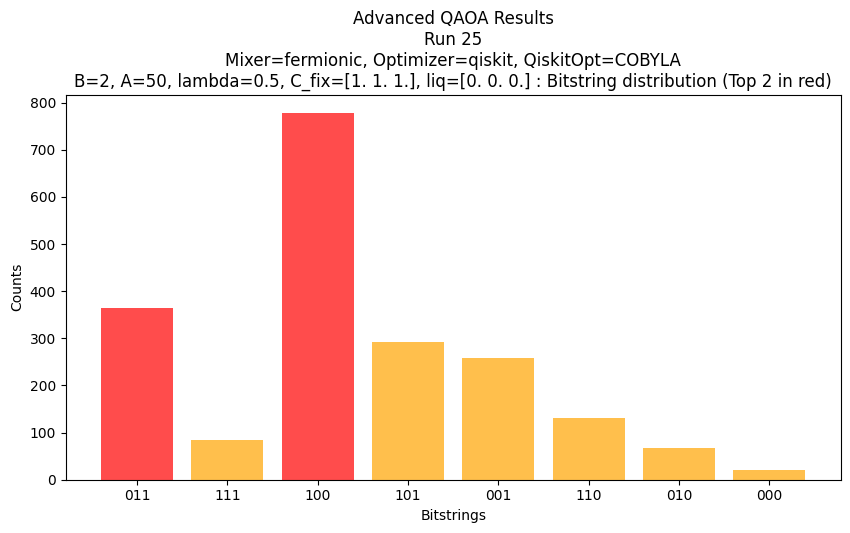

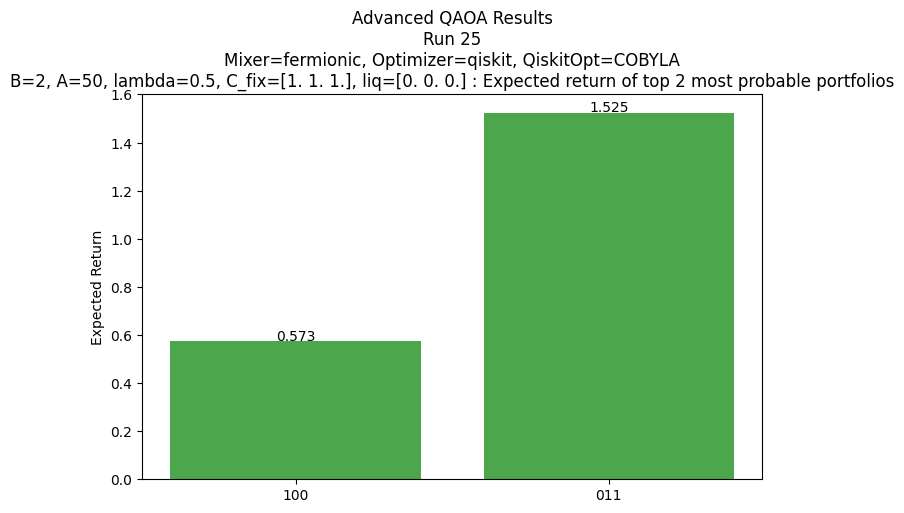

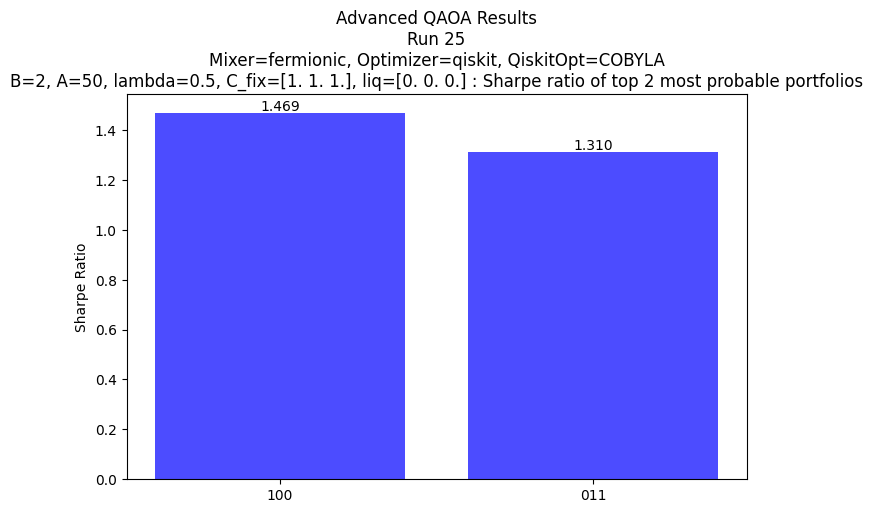

Run 25: best bitstring=100, selected assets=['BTC-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])
Generation 1/50, Best Energy = 26.633221
Generation 2/50, Best Energy = 26.633221
Generation 3/50, Best Energy = 17.480240
Generation 4/50, Best Energy = 17.480240
Generation 5/50, Best Energy = 17.480240
Generation 6/50, Best Energy = 17.480240
Generation 7/50, Best Energy = 16.796310
Generation 8/50, Best Energy = 16.796310
Generation 9/50, Best Energy = 16.796310
Generation 10/50, Best Energy = 13.030539
Generation 11/50, Best Energy = 13.030539
Generation 12/50, Best Energy = 13.030539
Generation 13/50, Best Energy = 13.030539
Generation 14/50, Best Energy = 13.030539
Generation 15/50, Best Energy = 13.030539
Generation 16/50, Best Energy = 13.030539
Generation 17/50, Best Energy = 13.030539
G

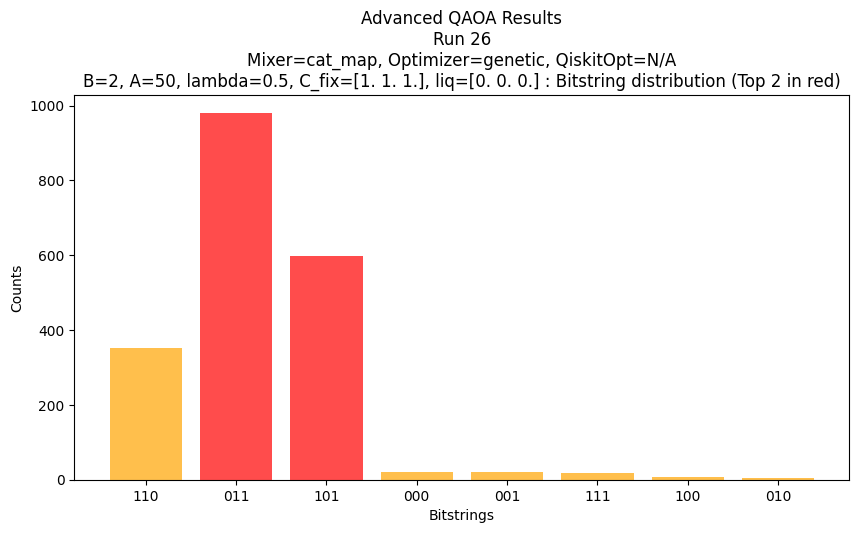

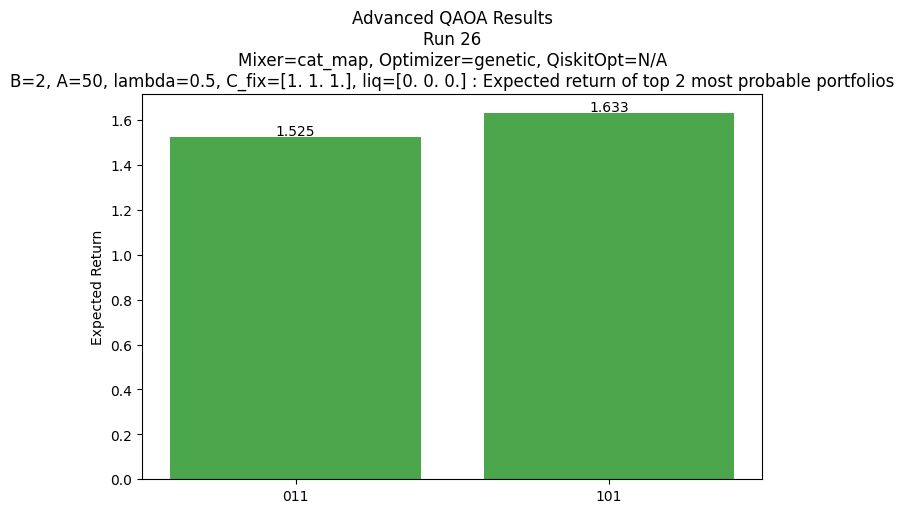

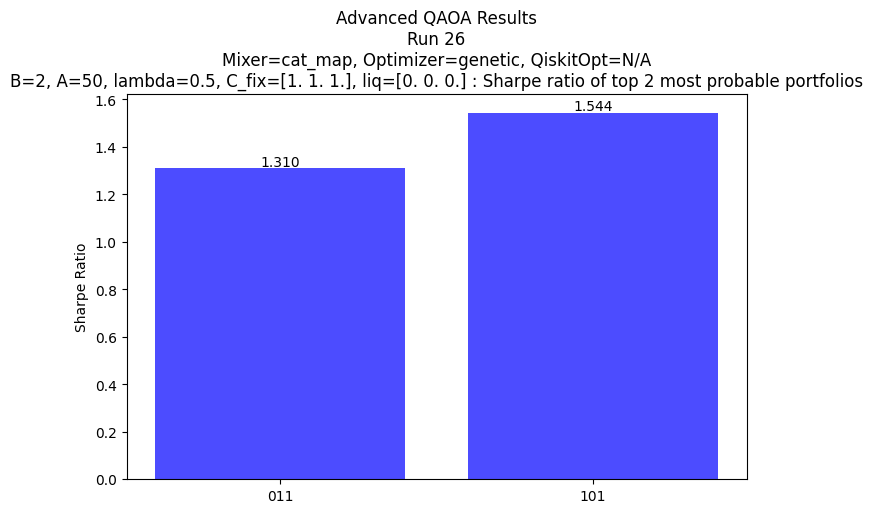

Run 26: best bitstring=011, selected assets=['ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


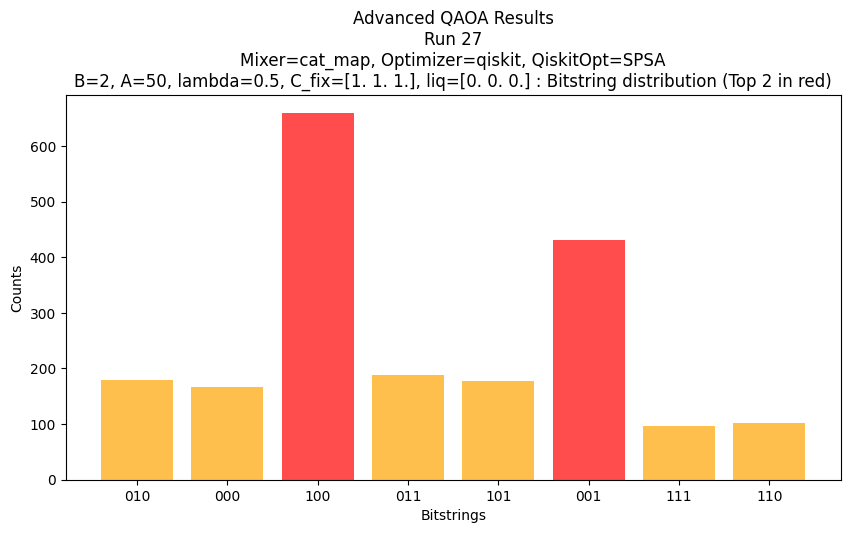

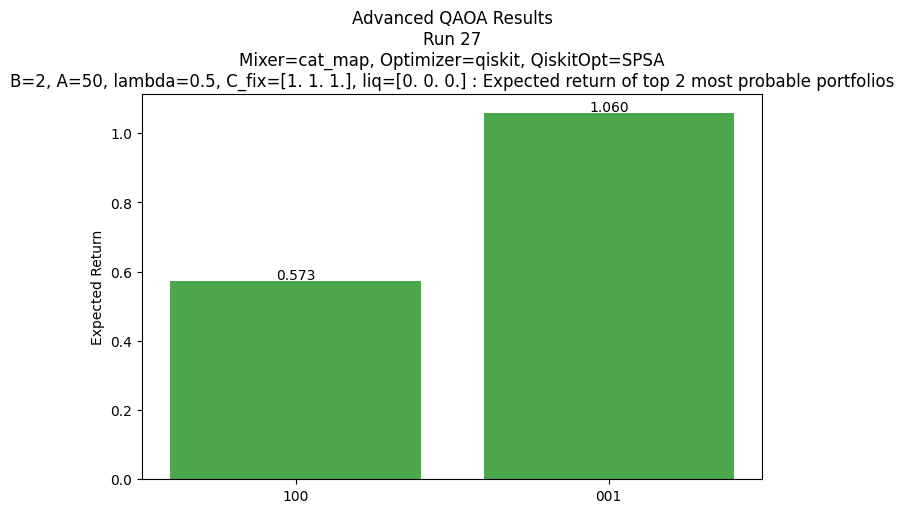

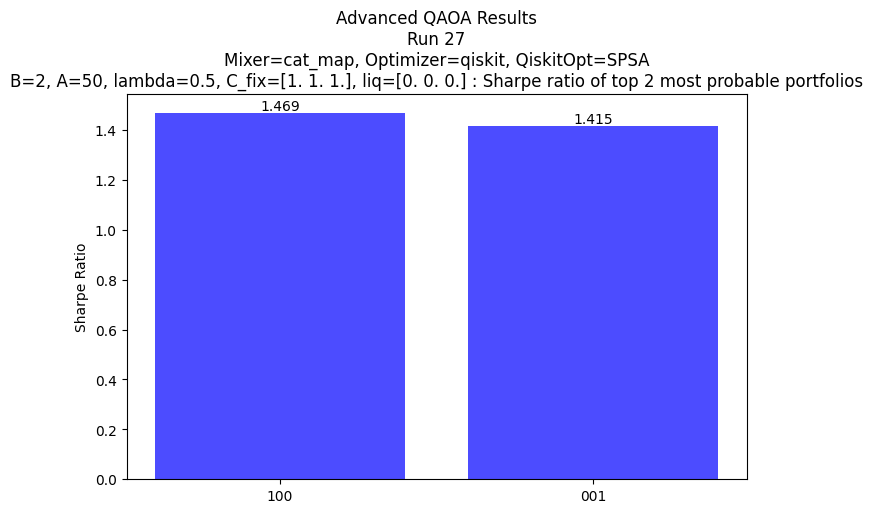

Run 27: best bitstring=100, selected assets=['BTC-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


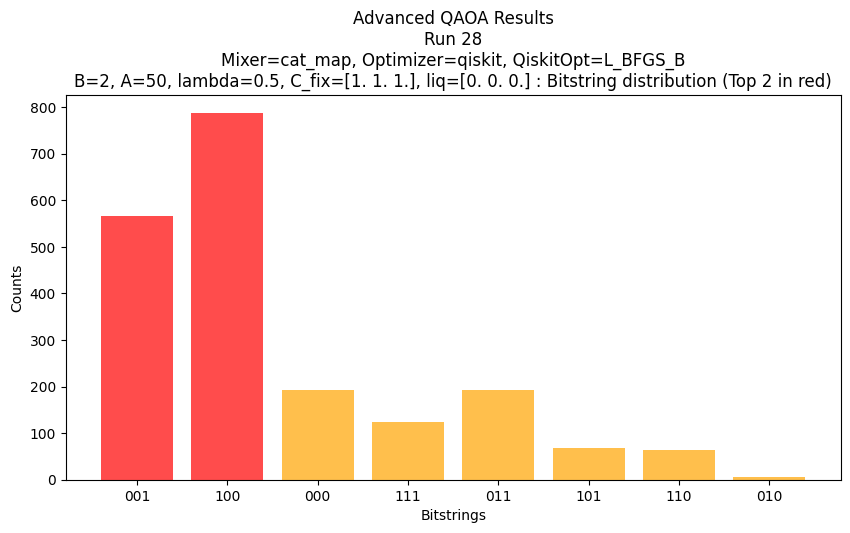

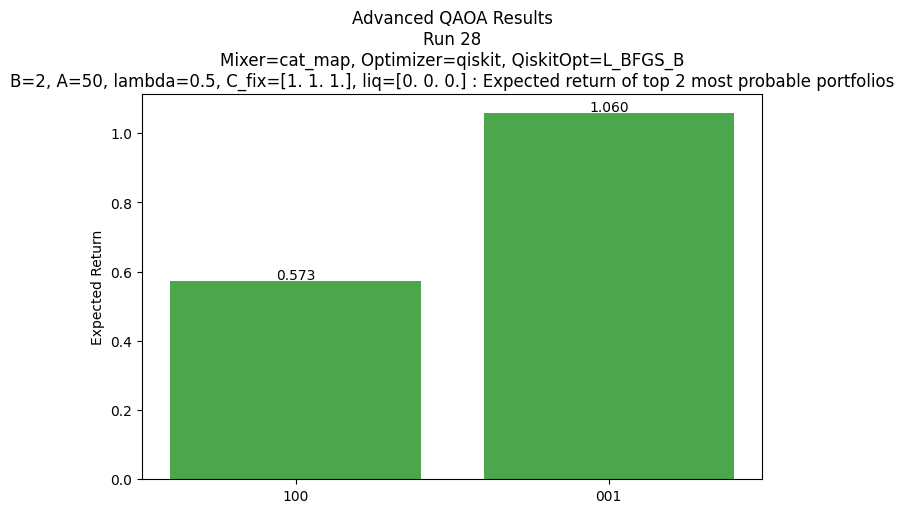

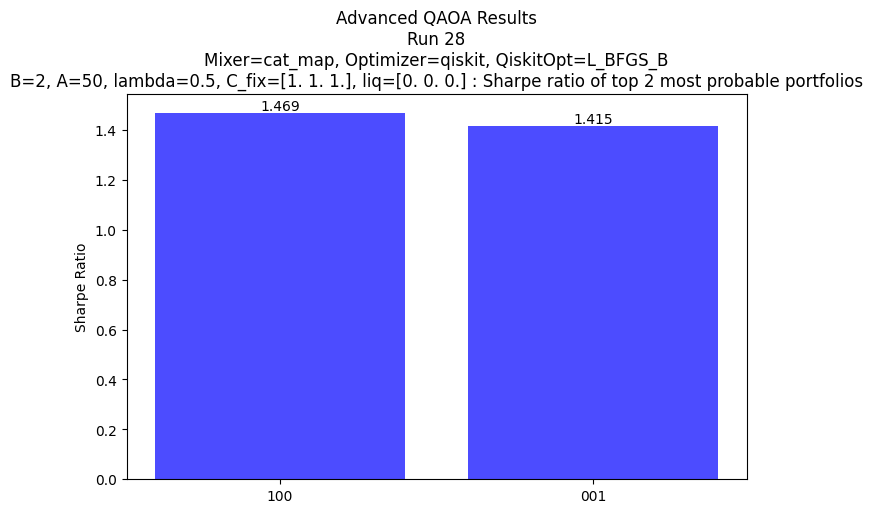

Run 28: best bitstring=100, selected assets=['BTC-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


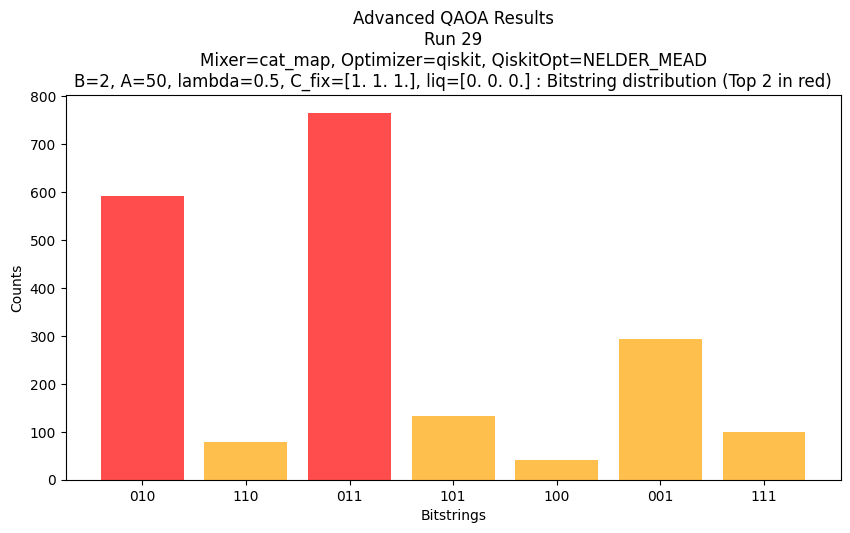

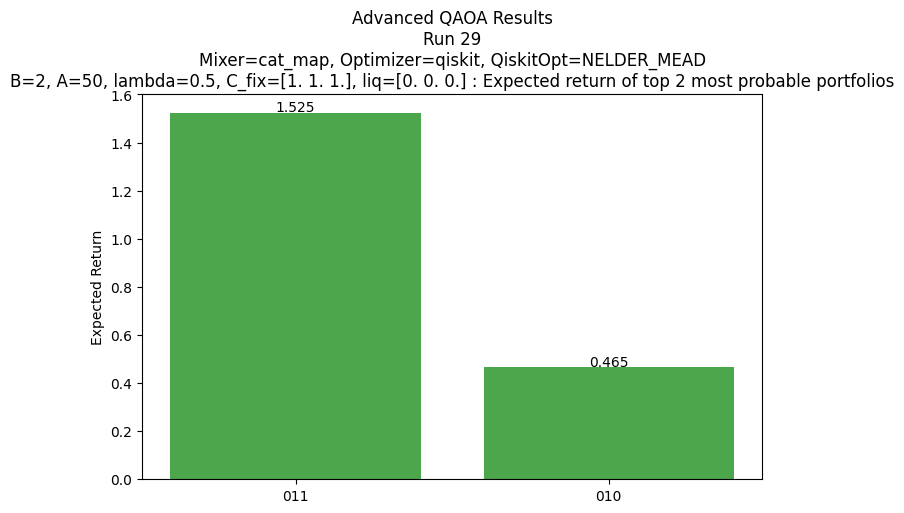

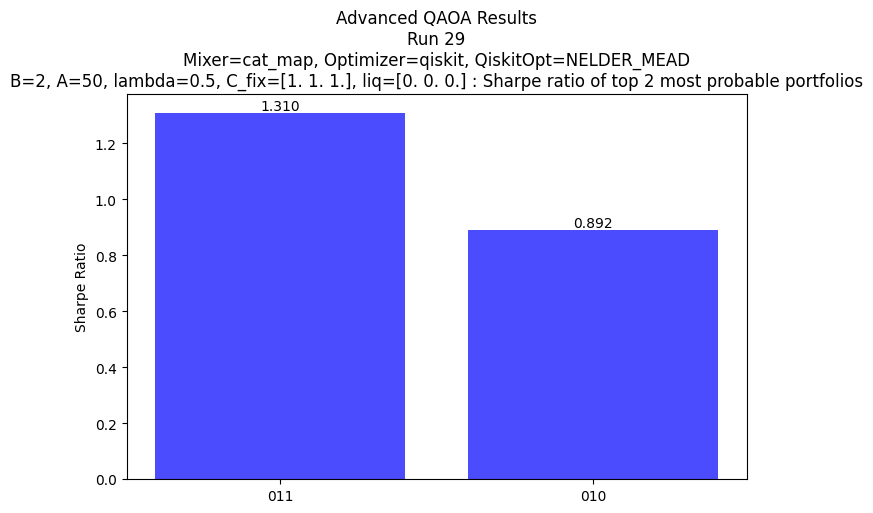

Run 29: best bitstring=011, selected assets=['ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[53.25901863+0.j, 25.81746635+0.j, 25.7040377 +0.j, 25.9078651 +0.j,
 25.07987796+0.j, 25.1011182 +0.j, 25.13061606+0.j])


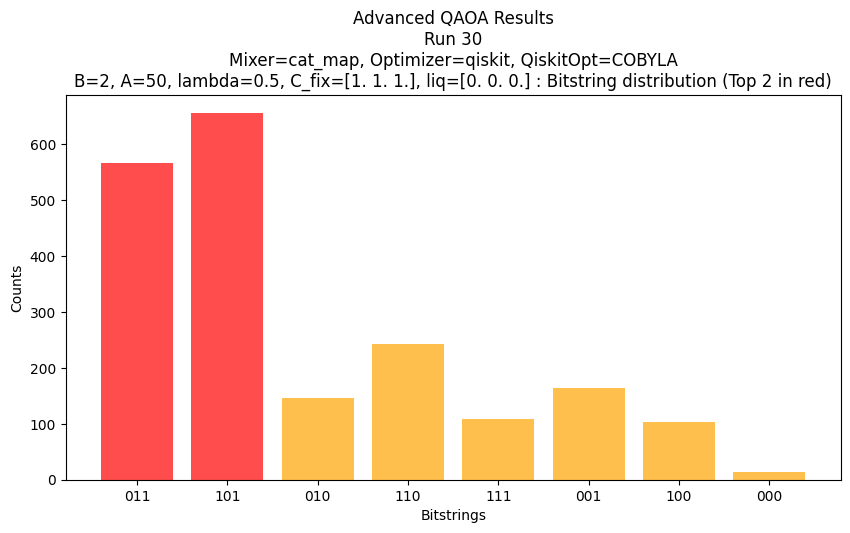

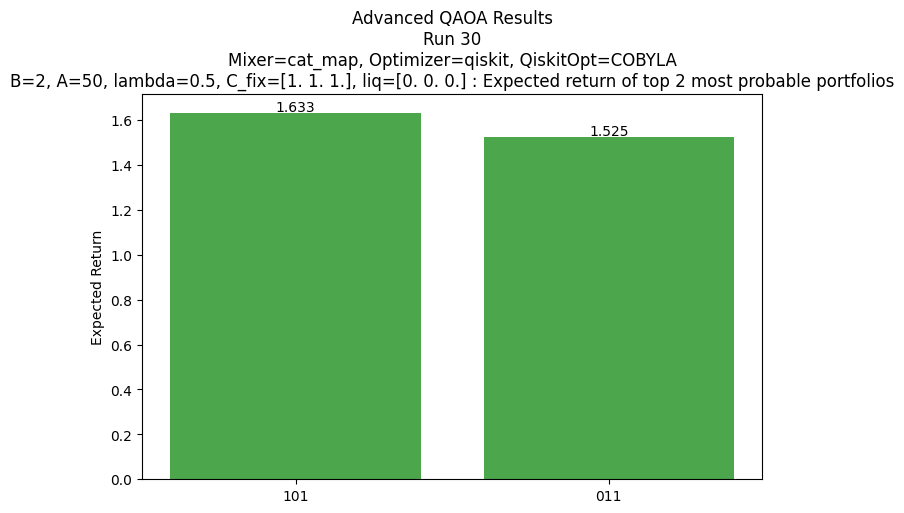

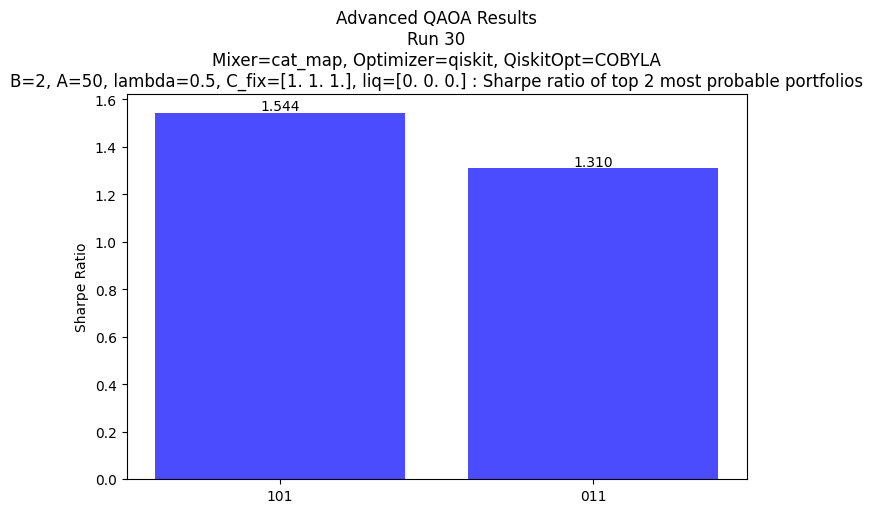

Run 30: best bitstring=101, selected assets=['BTC-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])
Generation 1/50, Best Energy = 11.094867
Generation 2/50, Best Energy = 11.094867
Generation 3/50, Best Energy = 11.094867
Generation 4/50, Best Energy = 11.094867
Generation 5/50, Best Energy = 11.094867
Generation 6/50, Best Energy = 11.094867
Generation 7/50, Best Energy = 11.094867
Generation 8/50, Best Energy = 11.094867
Generation 9/50, Best Energy = 11.094867
Generation 10/50, Best Energy = 11.094867
Generation 11/50, Best Energy = 11.094867
Generation 12/50, Best Energy = 11.094867
Generation 13/50, Best Energy = 10.992533
Generation 14/50, Best Energy = 10.992533
Generation 15/50, Best Energy = 10.992533
Generation 16/50, Best Energy = 10.992533
Generation 17/50, Best En

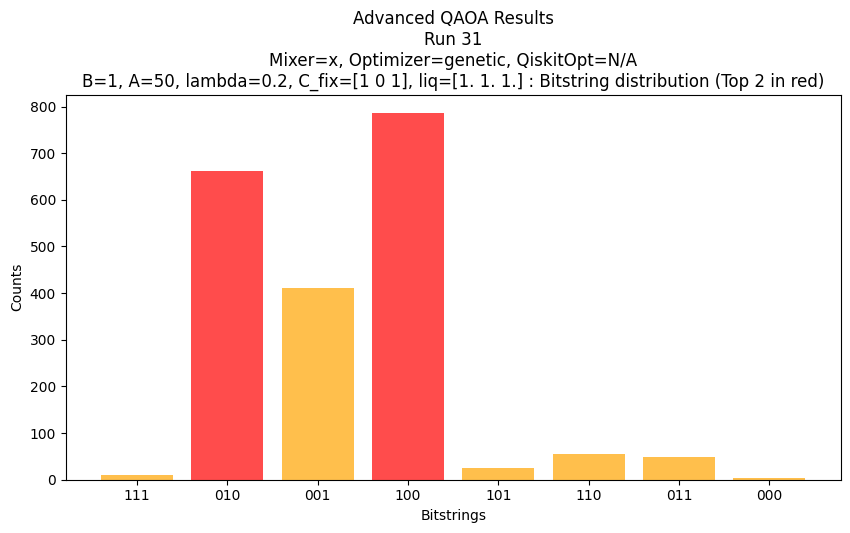

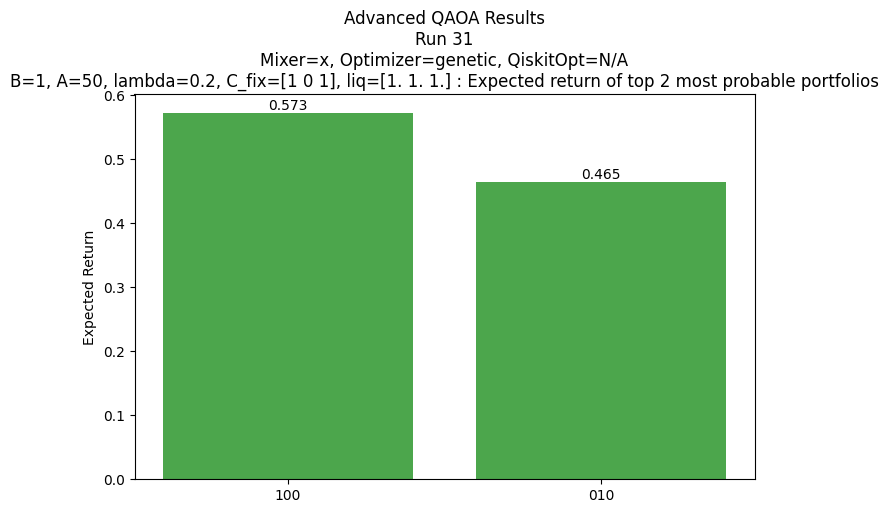

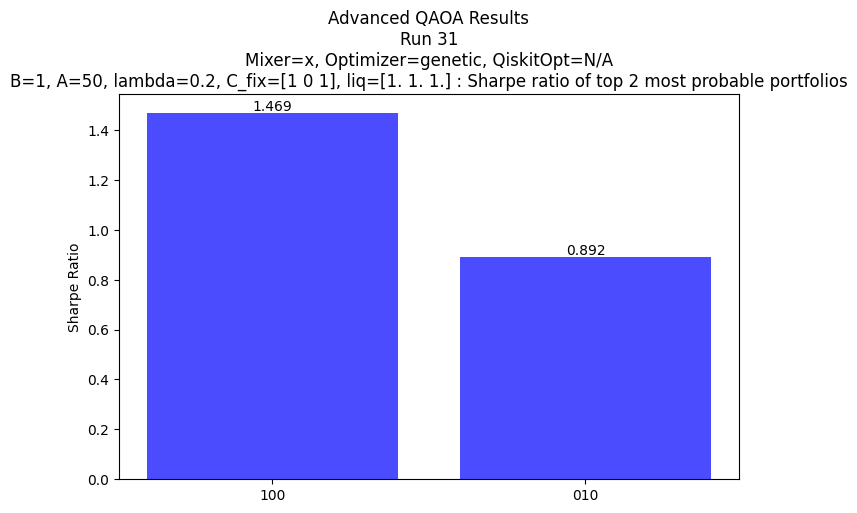

Run 31: best bitstring=100, selected assets=['BTC-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


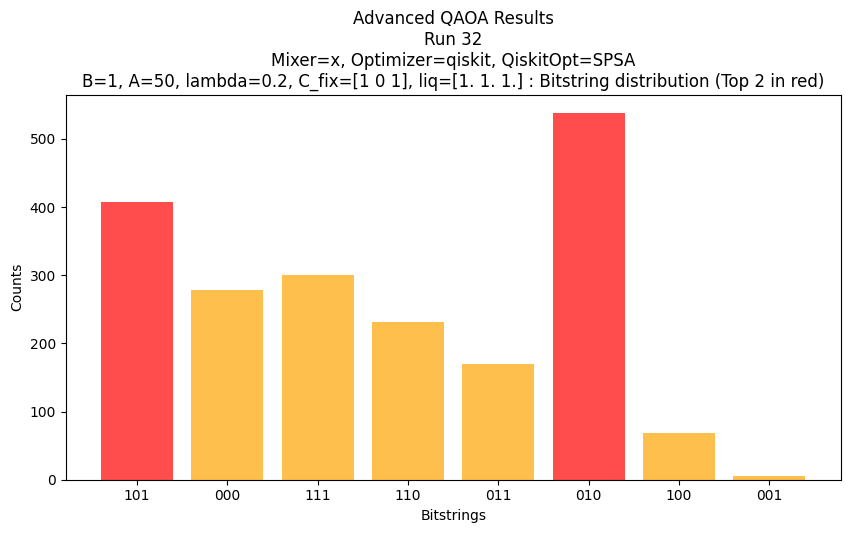

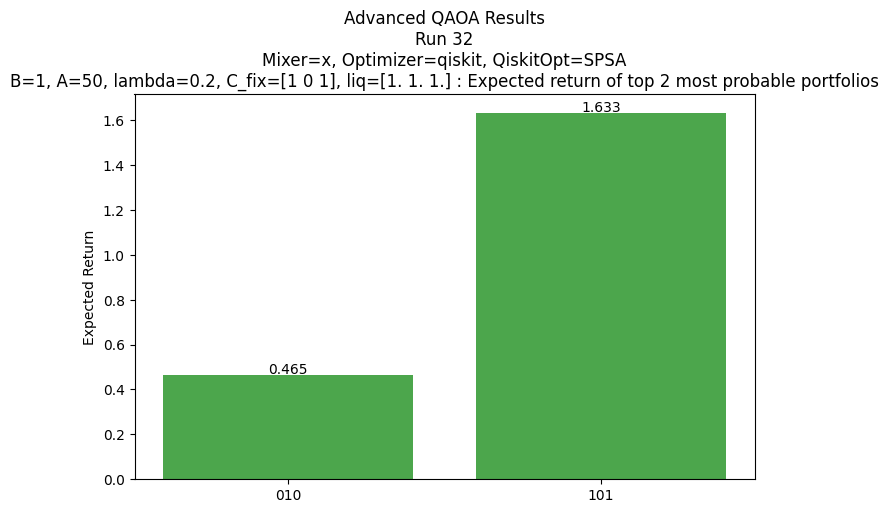

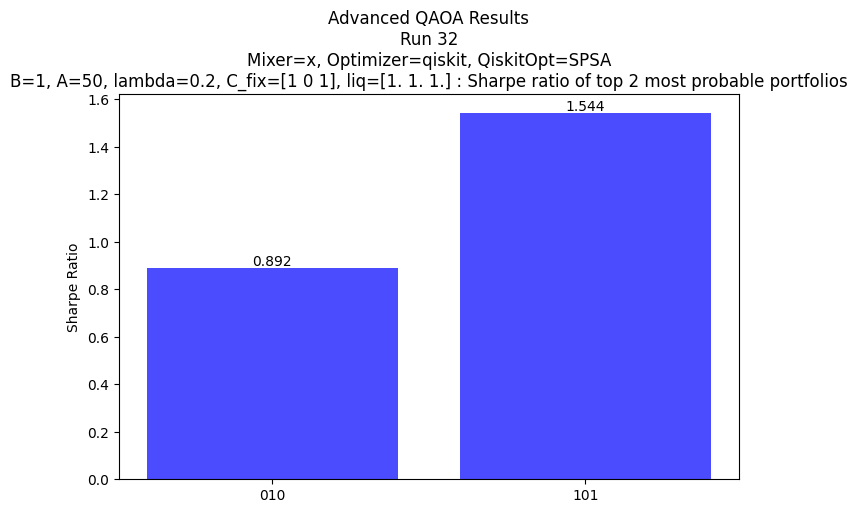

Run 32: best bitstring=010, selected assets=['ETH-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


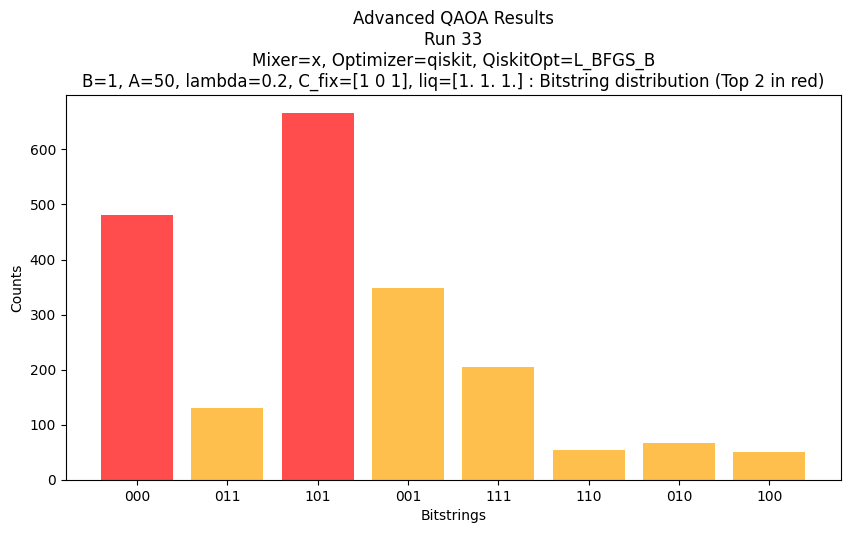

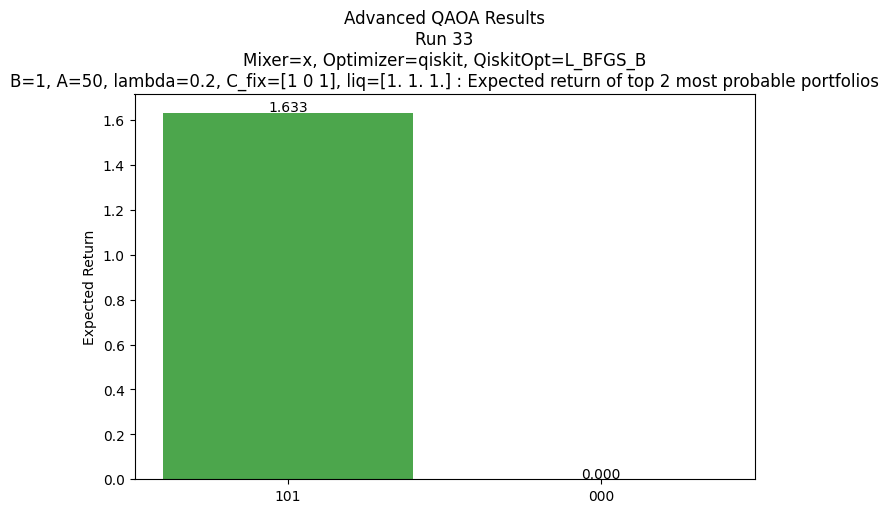

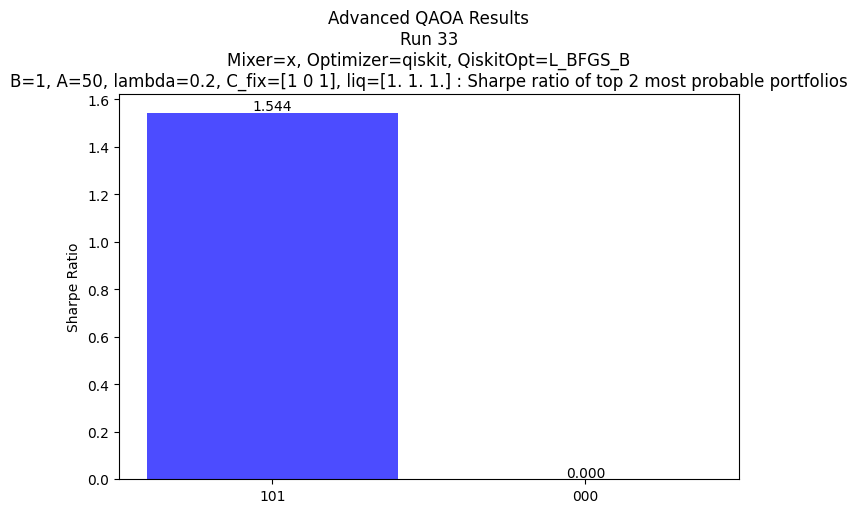

Run 33: best bitstring=101, selected assets=['BTC-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


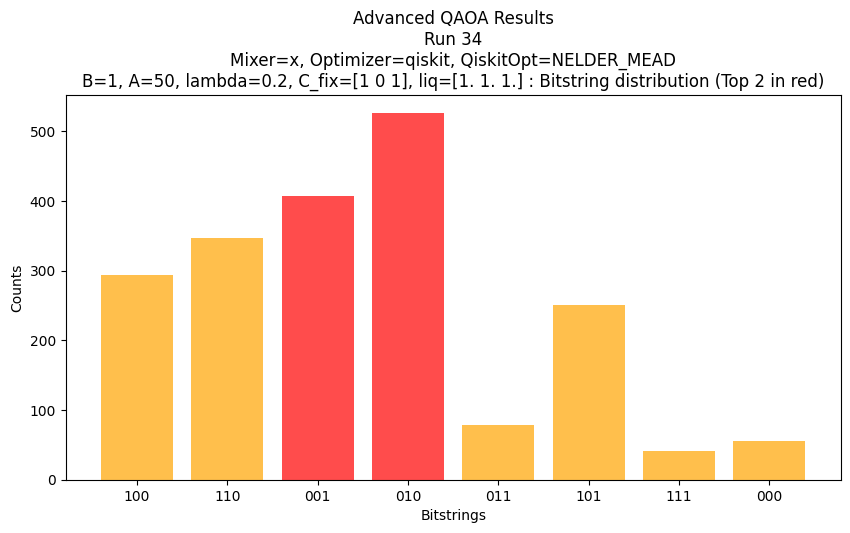

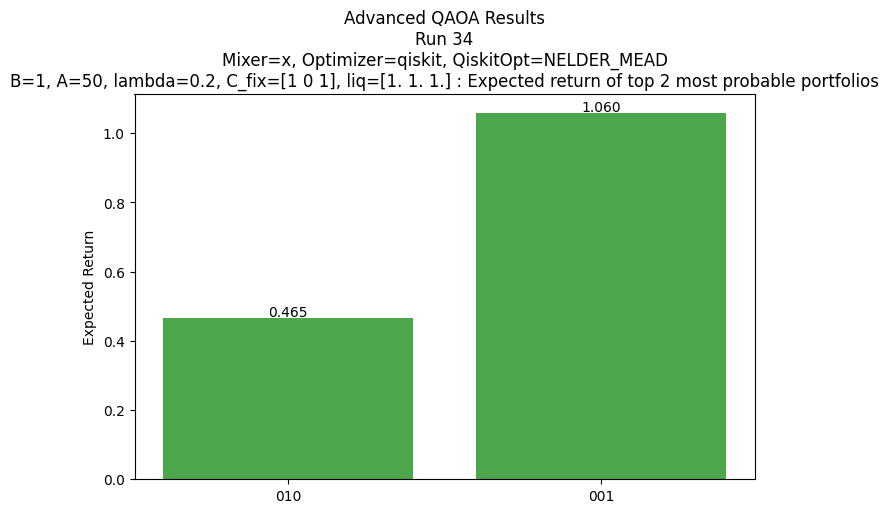

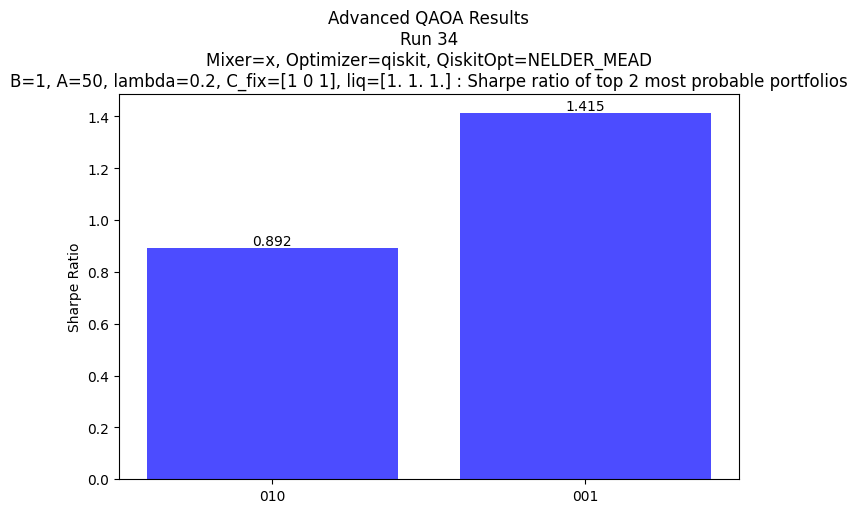

Run 34: best bitstring=010, selected assets=['ETH-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


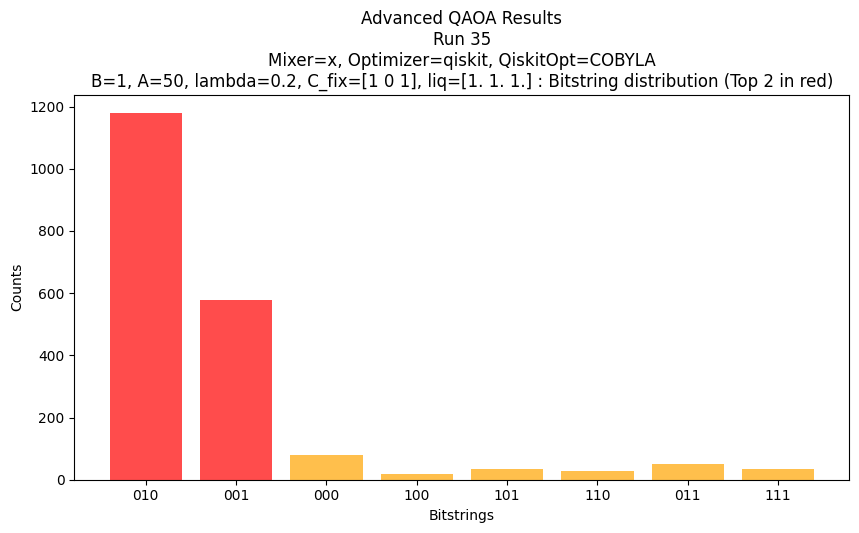

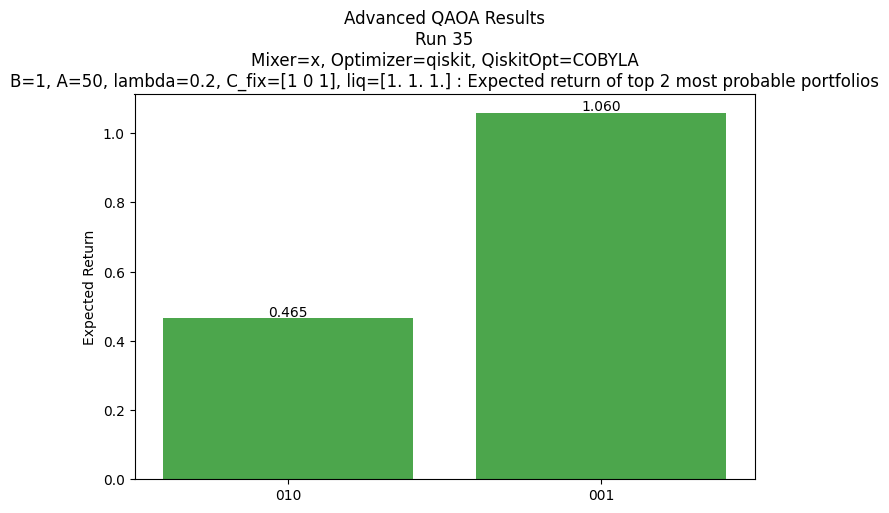

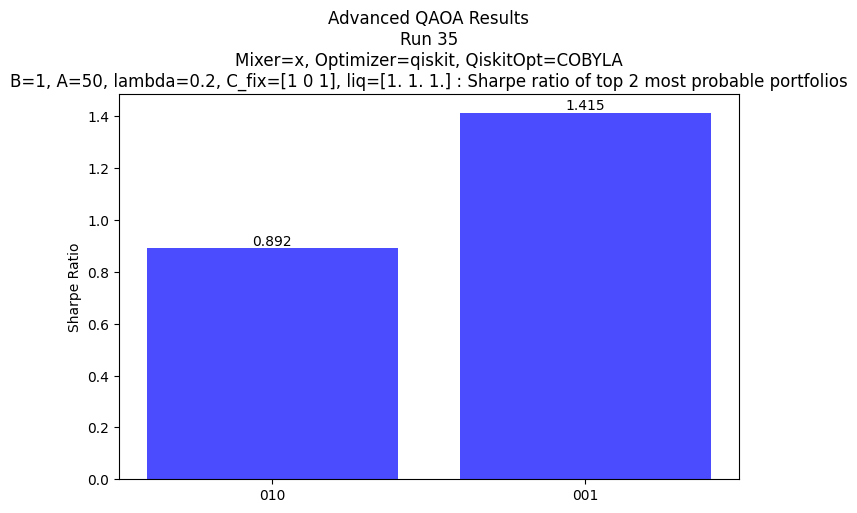

Run 35: best bitstring=010, selected assets=['ETH-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])
Generation 1/50, Best Energy = 20.908464
Generation 2/50, Best Energy = 20.908464
Generation 3/50, Best Energy = 20.908464
Generation 4/50, Best Energy = 20.908464
Generation 5/50, Best Energy = 20.908464
Generation 6/50, Best Energy = 20.908464
Generation 7/50, Best Energy = 20.908464
Generation 8/50, Best Energy = 20.559341
Generation 9/50, Best Energy = 20.559341
Generation 10/50, Best Energy = 20.559341
Generation 11/50, Best Energy = 20.559341
Generation 12/50, Best Energy = 18.704579
Generation 13/50, Best Energy = 18.704579
Generation 14/50, Best Energy = 18.704579
Generation 15/50, Best Energy = 18.704579
Generation 16/50, Best Energy = 18.704579
Generation 17/50, Best Energy = 17.6

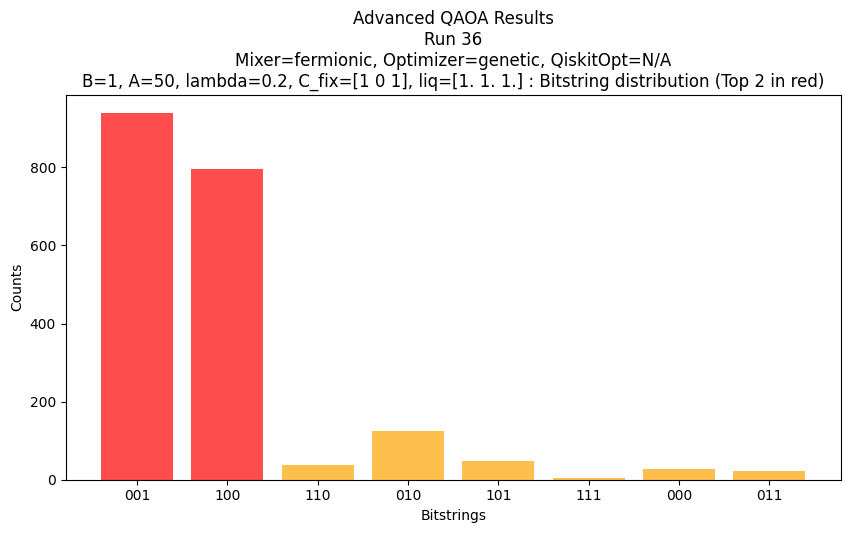

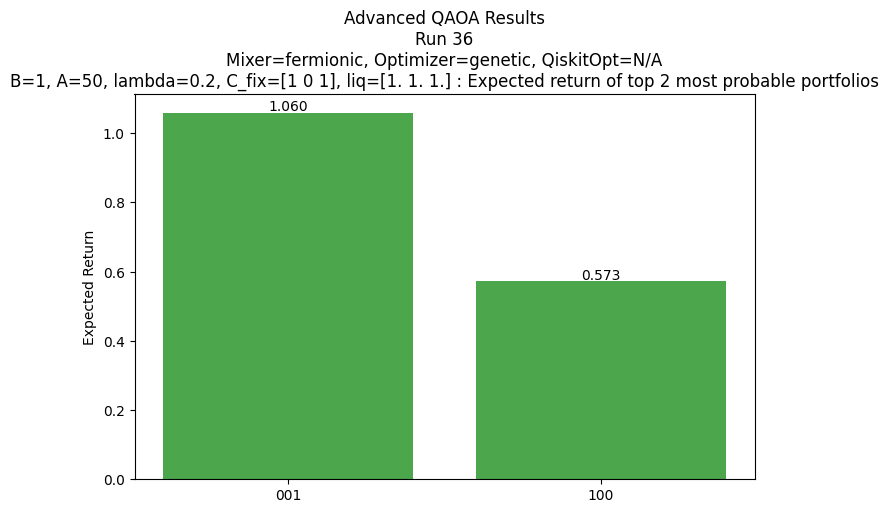

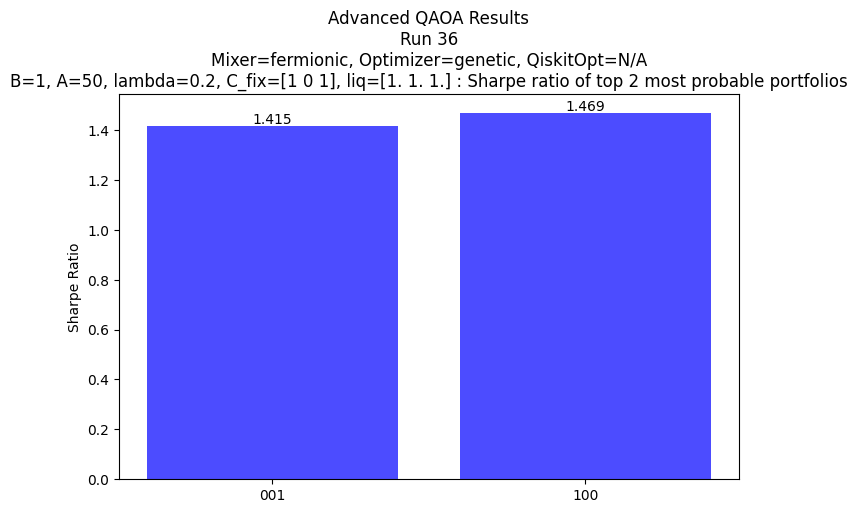

Run 36: best bitstring=001, selected assets=['SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


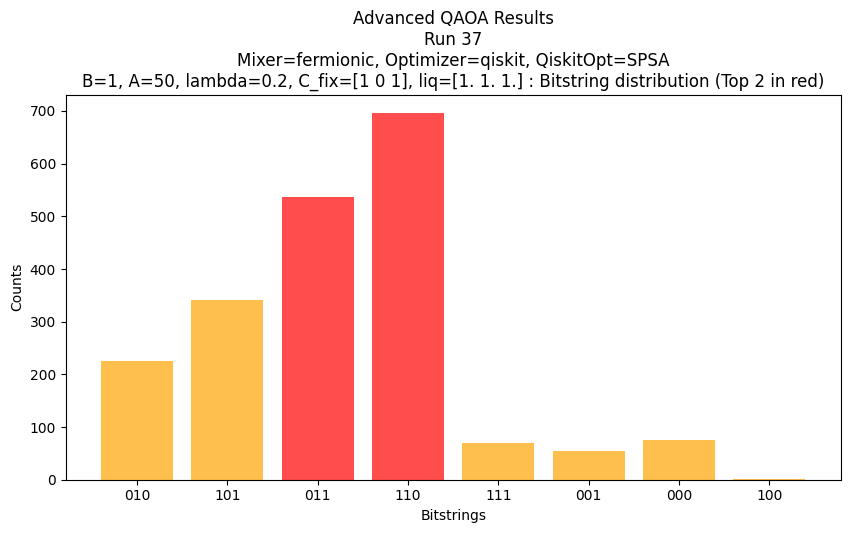

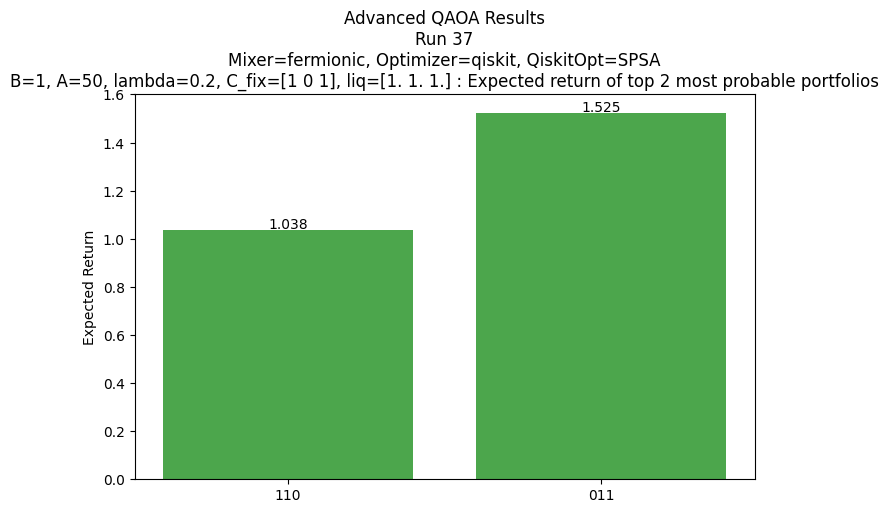

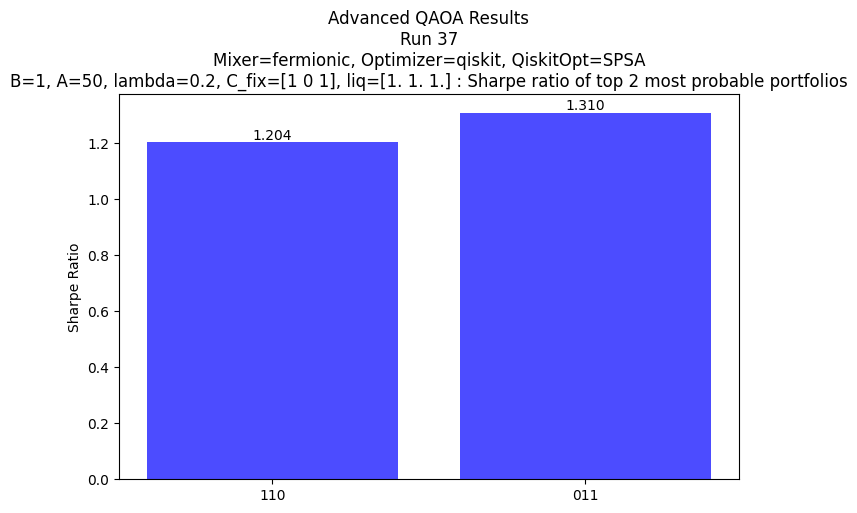

Run 37: best bitstring=110, selected assets=['BTC-USD', 'ETH-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


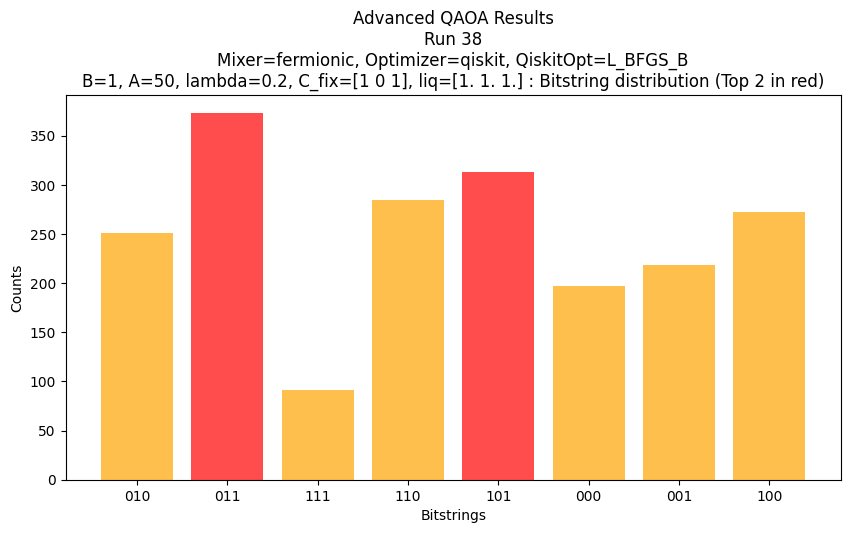

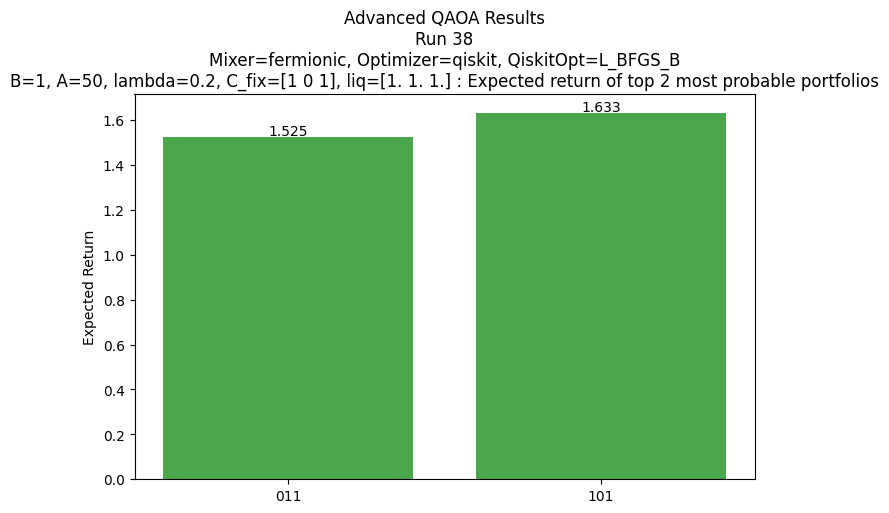

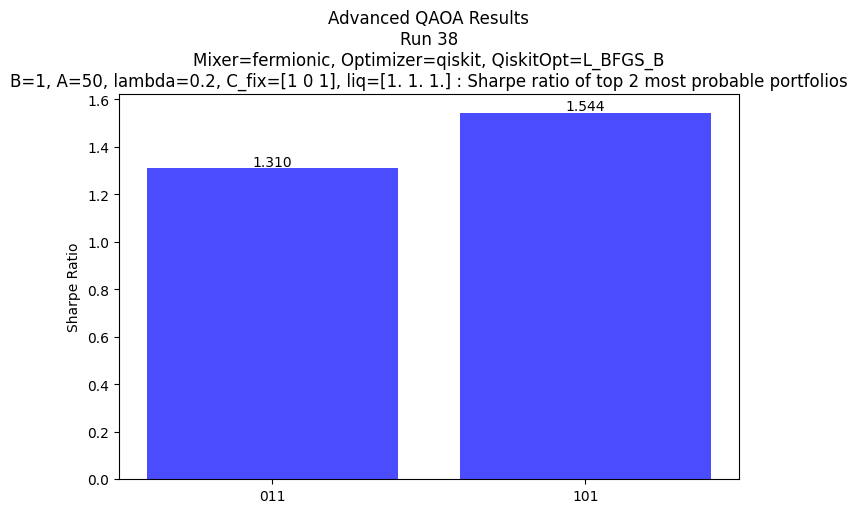

Run 38: best bitstring=011, selected assets=['ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


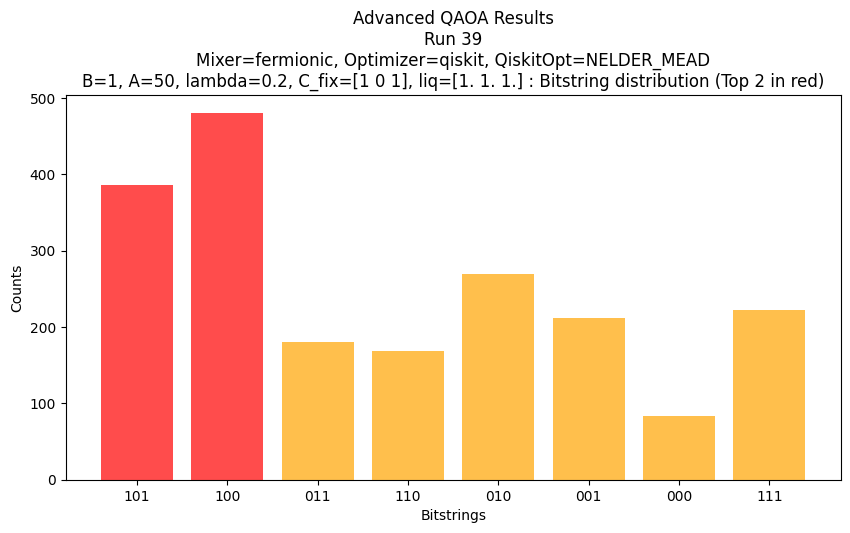

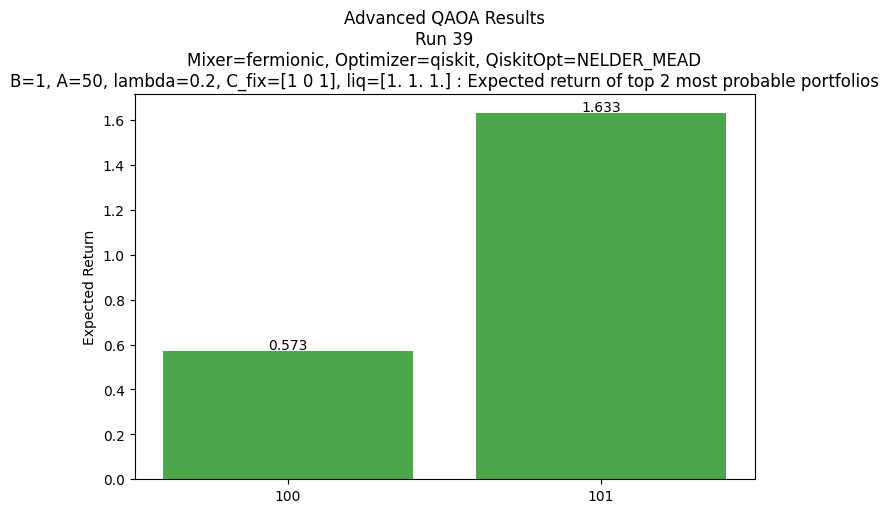

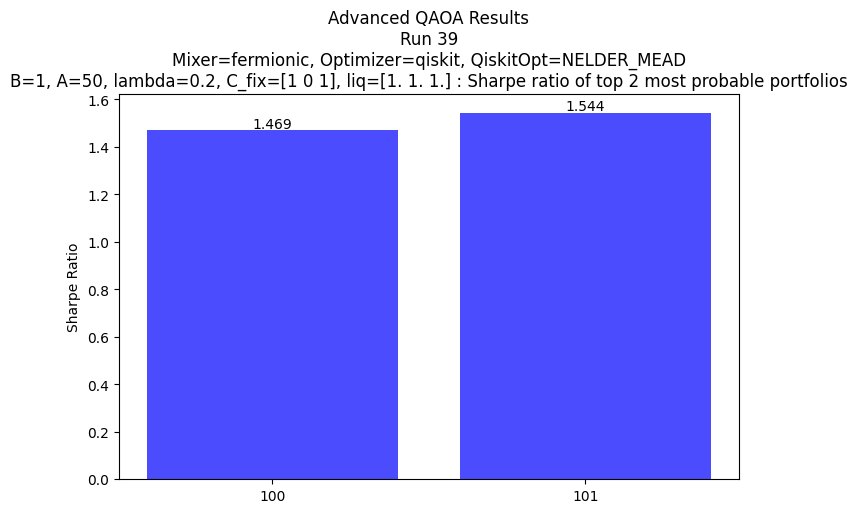

Run 39: best bitstring=100, selected assets=['BTC-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


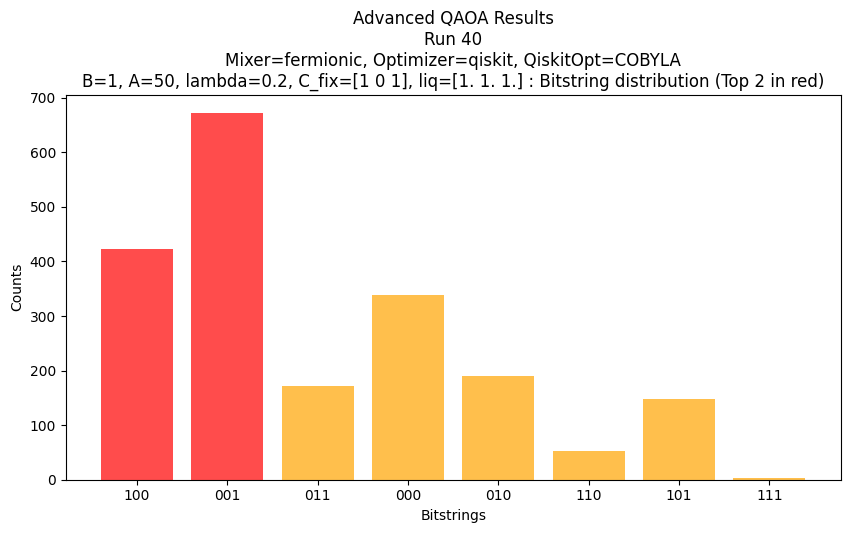

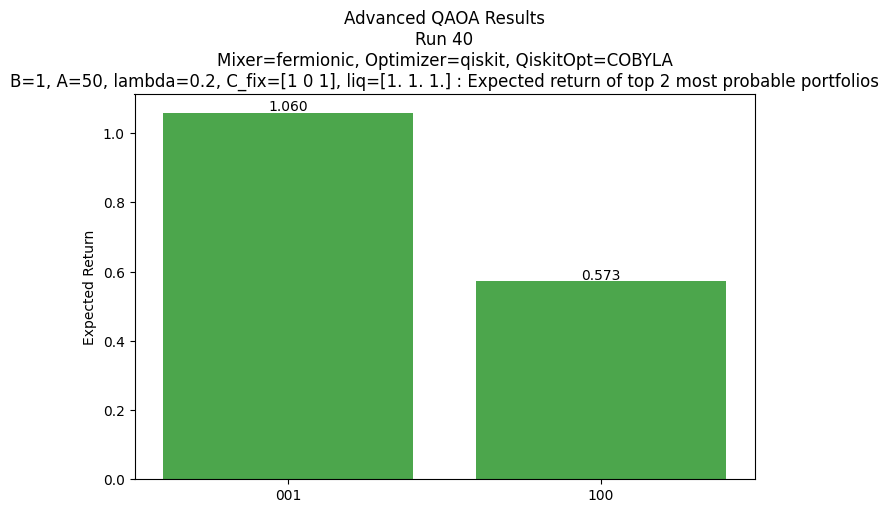

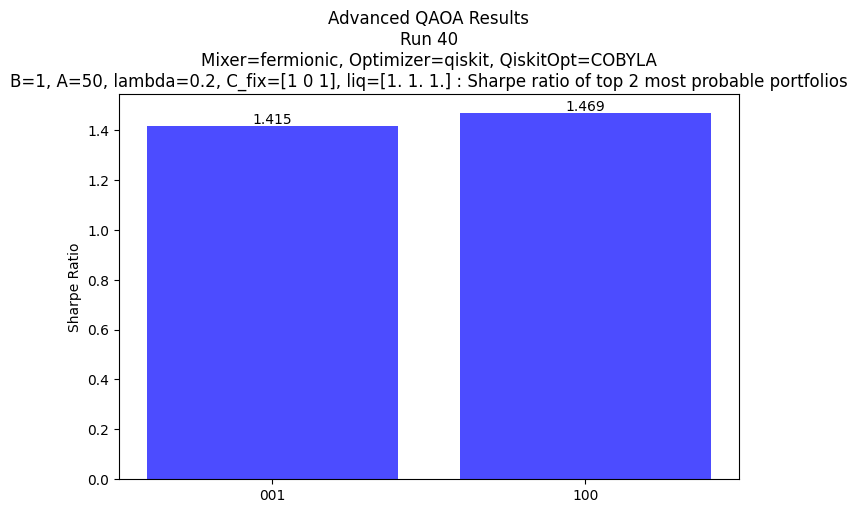

Run 40: best bitstring=001, selected assets=['SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])
Generation 1/50, Best Energy = 20.294682
Generation 2/50, Best Energy = 20.294682
Generation 3/50, Best Energy = 17.959142
Generation 4/50, Best Energy = 17.959142
Generation 5/50, Best Energy = 17.959142
Generation 6/50, Best Energy = 15.138747
Generation 7/50, Best Energy = 12.150530
Generation 8/50, Best Energy = 11.603285
Generation 9/50, Best Energy = 11.603285
Generation 10/50, Best Energy = 11.603285
Generation 11/50, Best Energy = 11.603285
Generation 12/50, Best Energy = 11.603285
Generation 13/50, Best Energy = 11.603285
Generation 14/50, Best Energy = 6.190369
Generation 15/50, Best Energy = 6.190369
Generation 16/50, Best Energy = 6.190369
Generation 17/50, Best Energy = 6.19036

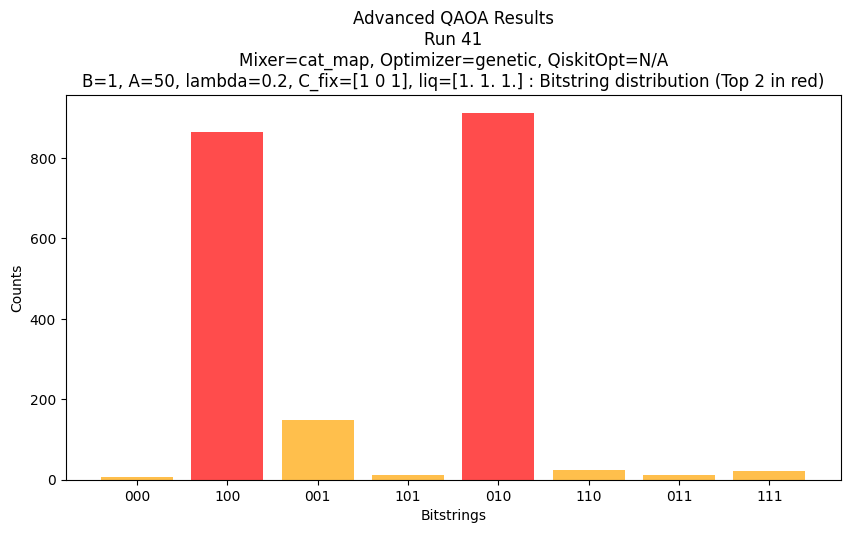

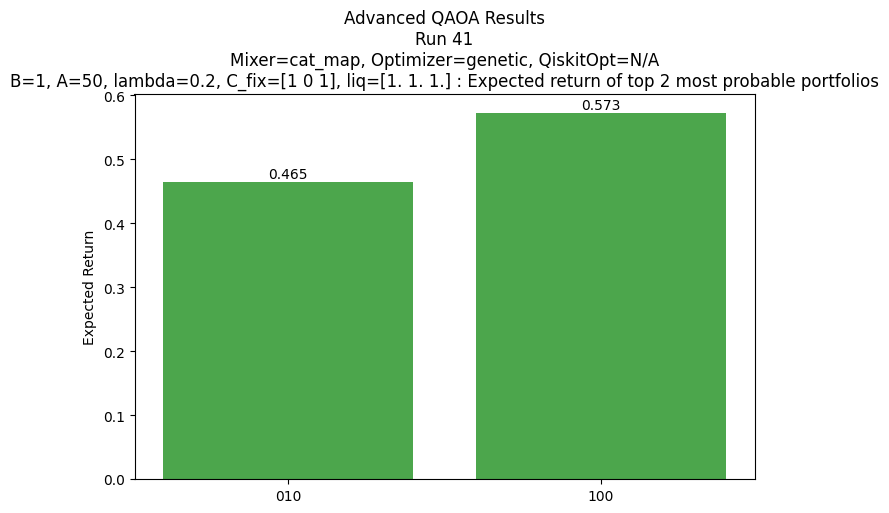

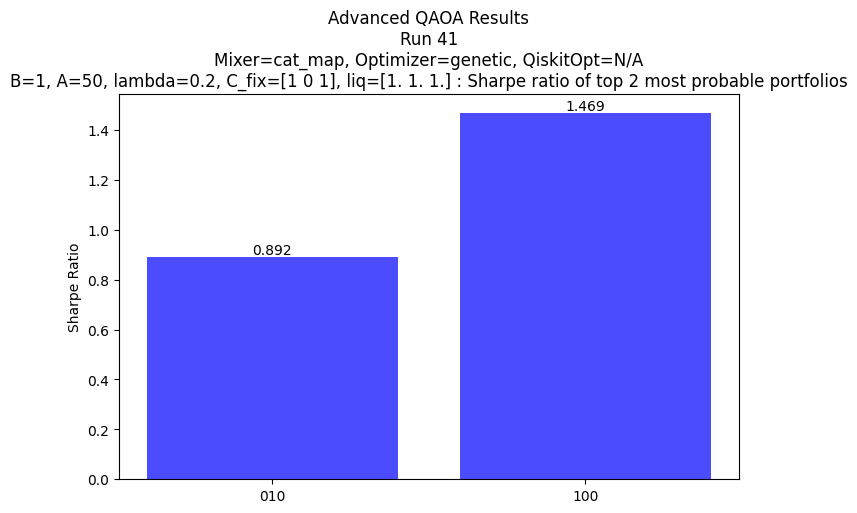

Run 41: best bitstring=010, selected assets=['ETH-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


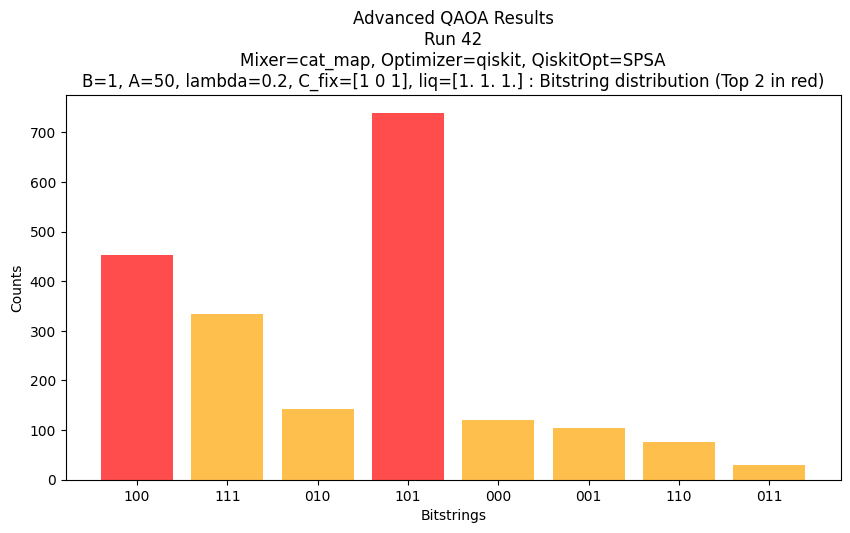

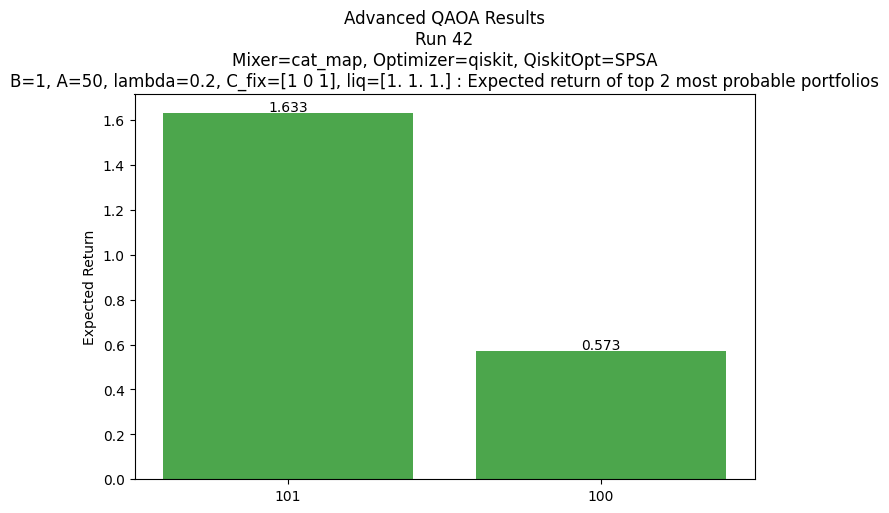

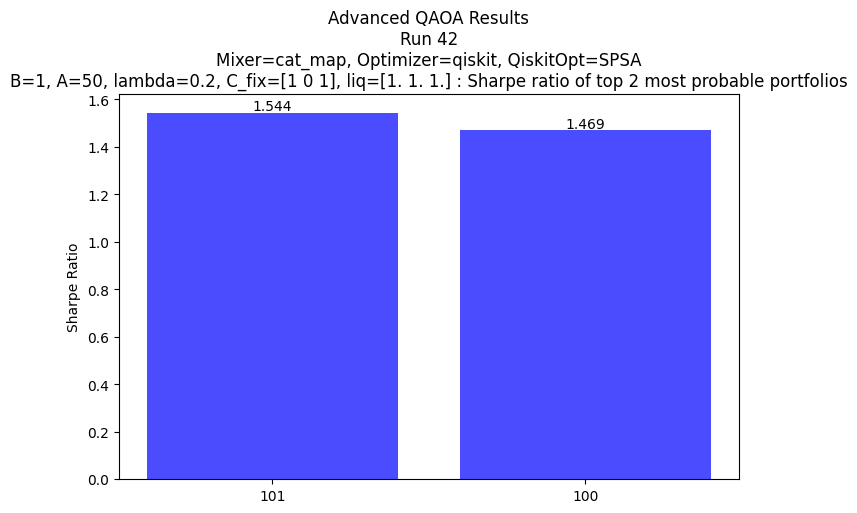

Run 42: best bitstring=101, selected assets=['BTC-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


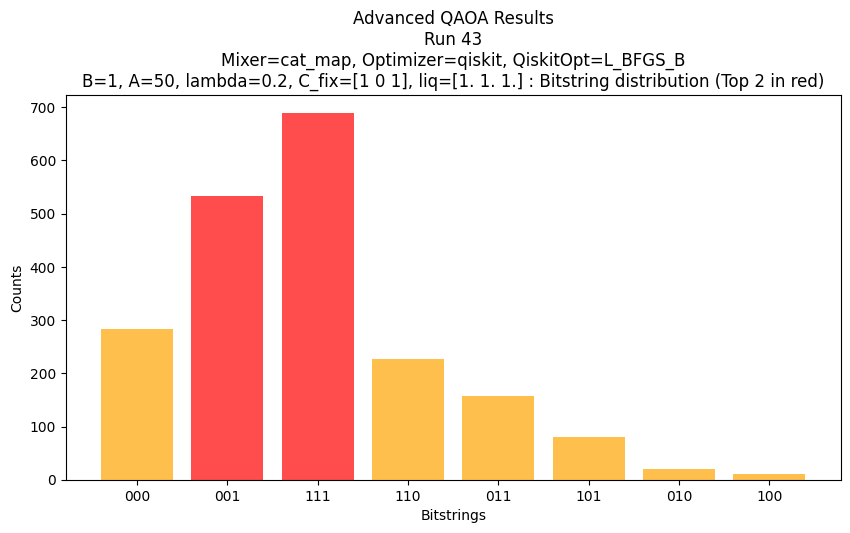

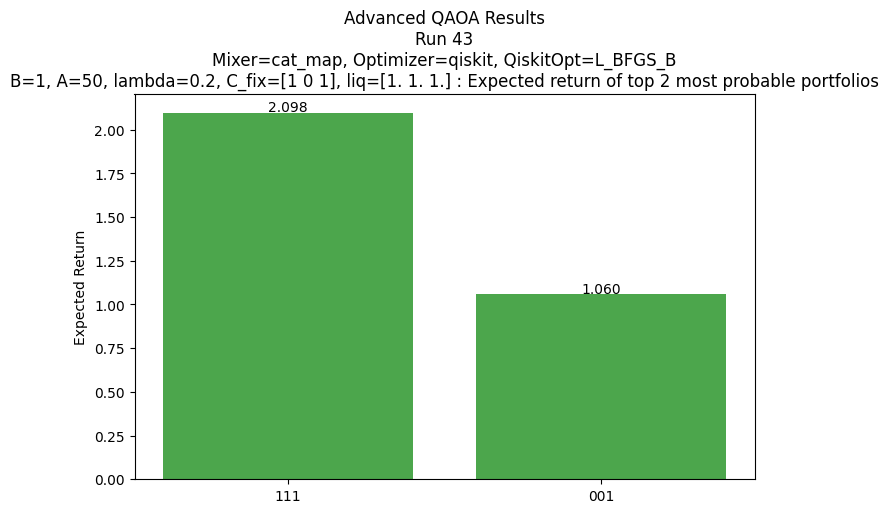

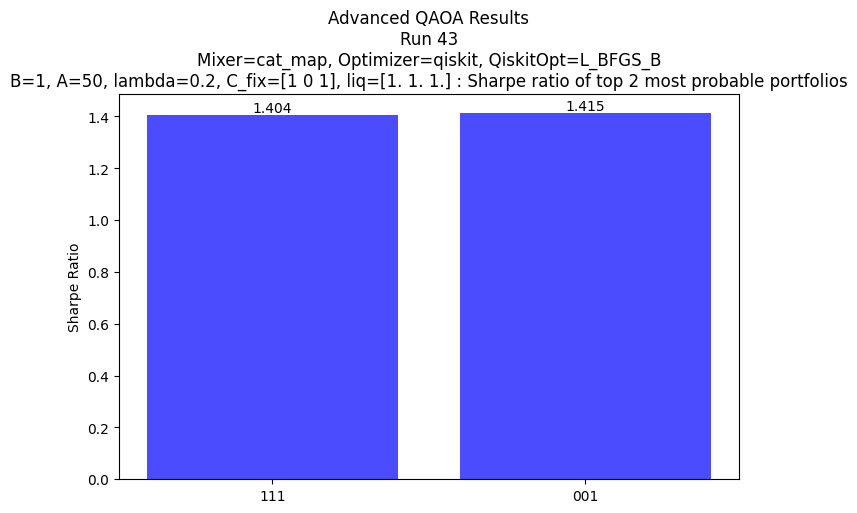

Run 43: best bitstring=111, selected assets=['BTC-USD', 'ETH-USD', 'SOL-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


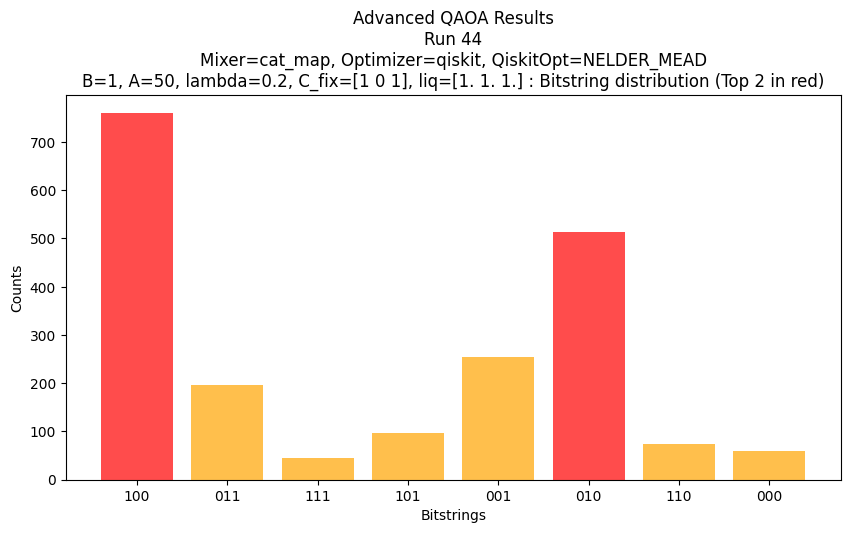

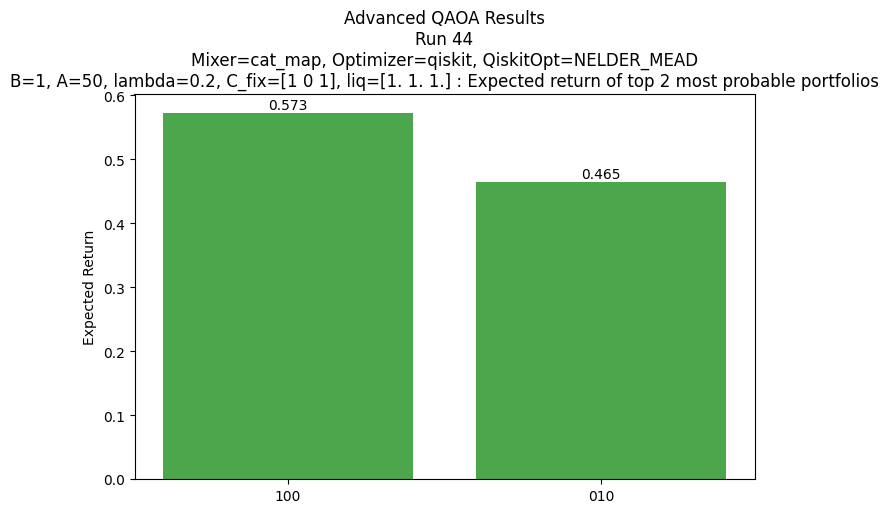

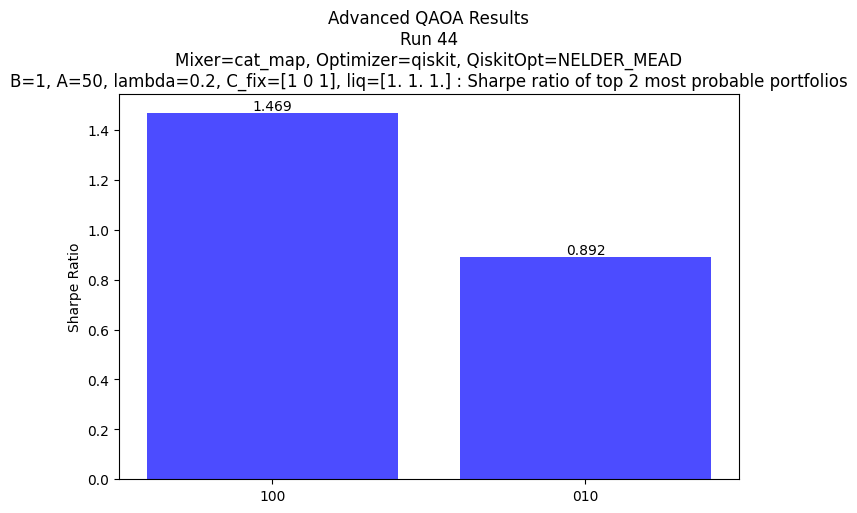

Run 44: best bitstring=100, selected assets=['BTC-USD']
Constructed cost Hamiltonian: SparsePauliOp(['III', 'ZII', 'IZI', 'IIZ', 'ZZI', 'ZIZ', 'IZZ'],
              coeffs=[ 51.50901863+0.j, -23.93253365+0.j, -25.0459623 +0.j, -23.8421349 +0.j,
  25.07987796+0.j,  25.1011182 +0.j,  25.13061606+0.j])


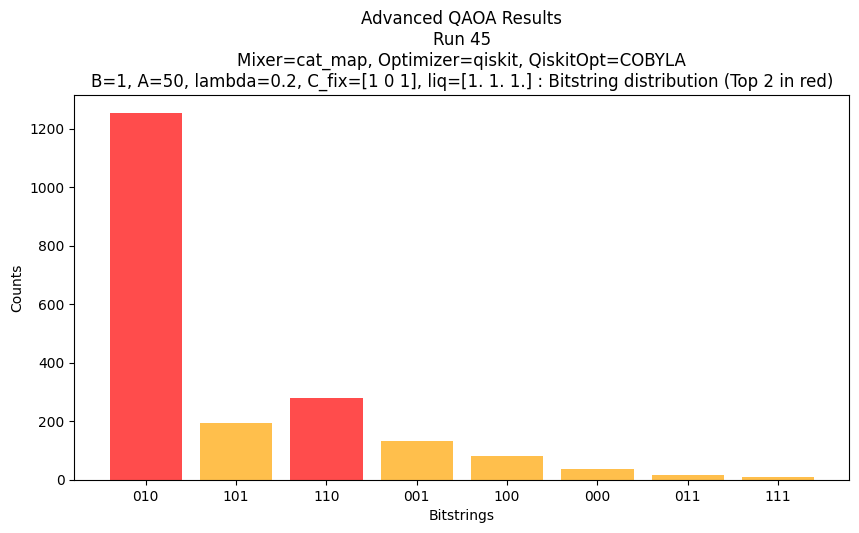

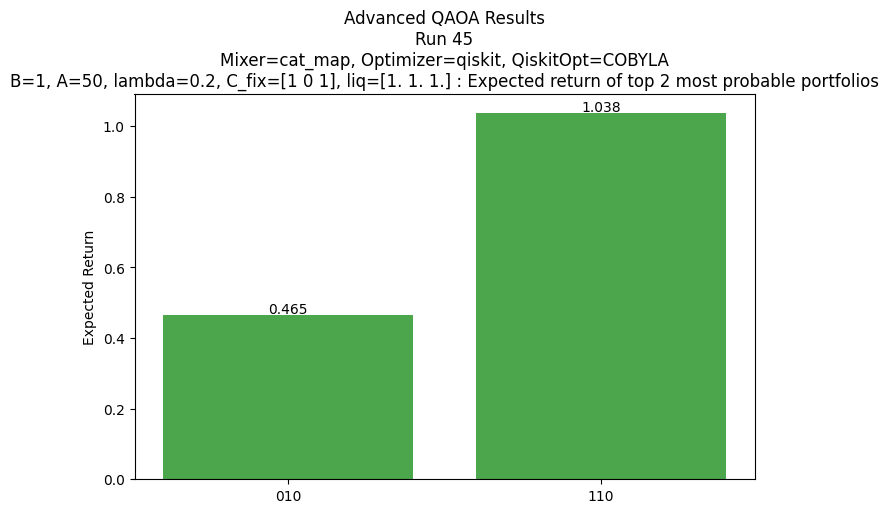

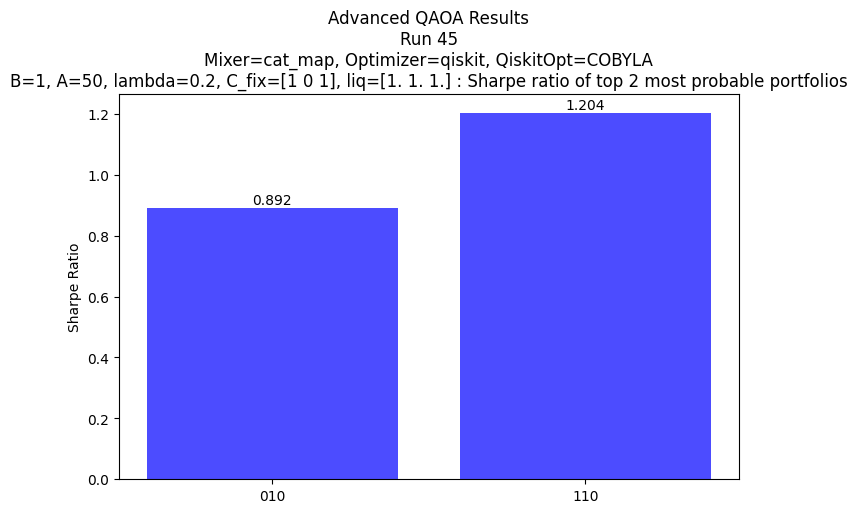

Run 45: best bitstring=010, selected assets=['ETH-USD']


In [ ]:
# -------------------------
# Loop over all combinations
# -------------------------
run_counter = 1

for params in examples_params:
    B = params["B"]
    A = params["A"]
    C_fix = params["C_fix"]
    lambda_l = params["lambda_l"]
    liq = params["liq"]

    for mixer_type in mixer_types:
        for optimizer_type in optimizer_types:
            
            # Only loop over qiskit_opts if optimizer_type is "qiskit"
            qiskit_opts_iter = qiskit_opts if optimizer_type == "qiskit" else [None]

            for qiskit_optimizer in qiskit_opts_iter:
                
                # Build Hamiltonian
                hamiltonian = construct_cost_hamiltonian(
                    num_assets, mu, sigma, q, B, A, C_fix, lambda_l, liq
                )

                # Optimize QAOA
                optimal_params = optimize_qaoa(
                    num_qubits=num_assets,
                    p=p,
                    hamiltonian=hamiltonian,
                    K=K,
                    use_ma_qaoa=True,
                    use_fourier=True,
                    mixer_type=mixer_type,
                    optimizer_type=optimizer_type,
                    qiskit_optimizer=qiskit_optimizer,
                    maxiter=50,
                    add_noise=True,
                    amplitude=10,
                    sigma=0.1,
                    verbose=True
                )

                # Unpack circuit parameters
                gamma_vec, beta_vec = unpack_params(
                    optimal_params, num_assets, p, hamiltonian,
                    use_ma_qaoa=True, use_fourier=True, K=K
                )
                gamma_vec = [[float(np.real(g)) for g in layer] for layer in gamma_vec]
                beta_vec = [[float(np.real(b)) for b in layer] for layer in beta_vec]

                # Build and simulate circuit
                qc = build_qaoa_circuit(num_assets, p, hamiltonian, gamma_vec, beta_vec, mixer_type)
                qc.measure_all()
                backend = AerSimulator()
                result = backend.run(qc, shots=2000).result()
                counts = result.get_counts()

                # Settings for plot annotation
                settings_text = (
                    f"Run {run_counter}\nMixer={mixer_type}, Optimizer={optimizer_type}, "
                    f"QiskitOpt={qiskit_optimizer if optimizer_type=='qiskit' else 'N/A'}\n"
                    f"B={B}, A={A}, lambda={lambda_l}, C_fix={C_fix}, liq={liq}"
                )

                # Plot results
                plot_histogram(counts, title=f"QAOA Counts\n{settings_text}")
                plot_qaoa_bitstrings(
                    counts, mu, sigma, top_k=2,
                    title=f"Advanced QAOA Results\n{settings_text}"
                )

                # Show best portfolio
                best_bitstring = max(counts, key=counts.get)
                portfolio = bitstring_to_portfolio(best_bitstring, assets=assets)
                print(f"Run {run_counter}: best bitstring={best_bitstring}, selected assets={portfolio}")

                run_counter += 1


| Set | Parameters | Why interesting |
|-----|------------|----------------|
| 1   | `B=3`, `A=10`, `C_fix=0`, `lambda_l=0`, `liq=0` | ✅ Simple baseline: no fixed costs, no liquidity penalty. Moderate budget constraint (B=3) and small penalty A=10. Good for testing the basic behavior of QAOA and risk-return trade-off without extra complications. |
| 2   | `B=2`, `A=50`, `C_fix=1`, `lambda_l=0.5`, `liq=0` | ⚡ Strong budget penalty (A=50) forces the algorithm to respect the budget strictly. Non-zero fixed costs (`C_fix=1`) introduce bias in the selection of assets. Moderate liquidity penalty (`lambda_l=0.5`) begins to affect choice of assets with lower liquidity. Shows effect of constraints on the optimal portfolio. |
| 3   | `B=1`, `A=50`, `C_fix=[1,0,1]`, `lambda_l=0.2`, `liq=1` | 🎯 Highly constrained case: very small budget (B=1), strong penalty (A=50). Asymmetric fixed costs favor certain assets (`C_fix=[1,0,1]`). Non-zero liquidity term (`lambda_l=0.2`) with maximum liquidity (`liq=1`) allows testing how small adjustments in liquidity influence selection. Useful for testing QAOA’s sensitivity to heterogeneous constraints. |


Investing in cryptocurrencies, especially Bitcoin, has become increasingly important in today’s financial landscape. Unlike traditional fiat currencies, which lose value as governments print more money, Bitcoin has a fixed supply of 21 million coins, making it a hedge against inflation. Over the long term, Bitcoin has consistently shown growth, earning its reputation as "digital gold." Its decentralized nature ensures that it is not controlled by any central authority, giving individuals full control over their wealth. Additionally, Bitcoin is globally accessible online, allowing fast and low-cost transactions anywhere in the world. By diversifying into cryptocurrencies, investors can protect their portfolios, benefit from long-term appreciation, and participate in the evolving digital economy.


# 🔟 Appendix

## 🔹 Bayesian Black Litterman algorithm for classical portfolio optimization

## 1. Context: Why Black-Litterman?
- In portfolio theory, the **Markowitz Mean-Variance Optimization (MVO)** framework requires **expected returns** as input.  
- But expected returns are very hard to estimate—small changes lead to huge differences in portfolios (**instability problem**).  
- The **Black-Litterman (BL) model** fixes this by:
  - Starting with a "neutral" prior: the **market equilibrium returns** (implied by CAPM or market weights).  
  - Updating this prior using an investor’s **views** (beliefs about assets/portfolios).  
  - Producing a **posterior distribution** of expected returns using **Bayesian updating**.

---

## 2. Step 1: The Prior Distribution of Returns
We assume asset returns vector $r \in \mathbb{R}^N$ (for $N$ assets) follows a multivariate normal:

$$
r \sim \mathcal{N}(\pi, \; \Sigma)
$$

- $\pi$ = prior expected returns (implied equilibrium returns).  
- $\Sigma$ = covariance matrix of asset returns.  

The prior mean $\pi$ is often computed from the market portfolio weights $w_m$:  

$$
\pi = \lambda \, \Sigma \, w_m
$$

where:
- $w_m$ = market-cap weights of assets,  
- $\lambda$ = risk-aversion parameter (scalar).

---

## 3. Step 2: The Investor’s Views
The investor has views like:  
- *"Portfolio of assets $P_i^T R$ will have an expected return of $Q_i$"*  

This can be written in matrix form:

$$
P R \sim \mathcal{N}(Q, \; \Omega)
$$

- $P$ = $K \times N$ "pick matrix" that selects or combines assets for each view,  
- $Q$ = vector of $K$ expected returns according to views,  
- $\Omega$ = covariance (uncertainty) matrix of the views (diagonal if independent).

**Example:**  
If you think *"Asset 1 will outperform Asset 2 by 3%"*, the row in $P$ is:

$$
[1, -1, 0, ..., 0]
$$

and $Q = 0.03$.

---

## 4. Step 3: Bayesian Updating
Now, combine the **prior** (from equilibrium) with the **views** (likelihood).  

The **posterior distribution of returns** is:

$$
R \,|\, Q \sim \mathcal{N}(\mu, \; \Sigma_{BL})
$$

where:

$$
\mu = \Big( (\tau \Sigma)^{-1} + P^T \Omega^{-1} P \Big)^{-1} 
      \Big( (\tau \Sigma)^{-1}\pi + P^T \Omega^{-1} Q \Big)
$$

$$
\Sigma_{BL} = \Big( (\tau \Sigma)^{-1} + P^T \Omega^{-1} P \Big)^{-1}
$$

- $\tau$ = scalar controlling uncertainty in the prior (usually small, like 0.025).  
- $\mu$ = posterior expected returns (new blended estimate).  
- $\Sigma_{BL}$ = posterior covariance matrix.

---

## 5. Intuition
- If views are very uncertain ($\Omega$ large), then the posterior $\mu \approx \pi$ (stay close to equilibrium).  
- If views are very confident ($\Omega$ small), then $\mu \approx q$.  
- If $\tau$ is small, you trust equilibrium strongly; if larger, you allow more deviation.  

This Bayesian blending makes the portfolio more **stable** than MVO with ad-hoc return guesses.

---

## 6. Step 4: Portfolio Optimization
Once we have the posterior mean $\mu$ and covariance $\Sigma_{BL}$, we plug them into the Markowitz optimization:

$$
w_{BL} \propto \Sigma_{BL}^{-1} \mu
$$

This gives the Black-Litterman optimal portfolio weights.

---

## Summary  

1. **Prior (equilibrium returns):**  
   $$
   \pi = \lambda \Sigma w_m
   $$

2. **Views:**  
   $$
   P R \sim \mathcal{N}(Q, \Omega)
   $$

3. **Posterior:**  
   $$
   \mu = \Big( (\tau \Sigma)^{-1} + P^T \Omega^{-1} P \Big)^{-1} 
         \Big( (\tau \Sigma)^{-1}\pi + P^T \Omega^{-1} Q \Big)
   $$

   $$
   \Sigma_{BL} = \Big( (\tau \Sigma)^{-1} + P^T \Omega^{-1} P \Big)^{-1}
   $$

4. **Optimal portfolio:**  
   $$
   w_{BL} \propto \Sigma_{BL}^{-1} \mu
   $$


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np 
from IPython.display import display, Math
from pypfopt.risk_models import CovarianceShrinkage 
from pypfopt.expected_returns import mean_historical_return 
from pypfopt.black_litterman import BlackLittermanModel
from pypfopt.black_litterman import market_implied_risk_aversion
from sklearn.covariance import LedoitWolf
from scipy.optimize import minimize

In [ ]:
# Bayesian Black Litterman

# -------------------------
tickers = ["AAPL", "MSFT", "TSLA", "NVDA"]
data = yf.download(tickers, start="2018-01-01", end="2025-01-01")["Close"]
returns = data.pct_change().dropna()

# Ledoit-Wolf Sigma
lw = LedoitWolf().fit(returns.values)
Sigma = pd.DataFrame(lw.covariance_ * 252, index=tickers, columns=tickers)

# Market-implied pi (reverse optimization) 
market_caps = np.array([3.5, 3.8, 1.3, 4.25])
w_market = market_caps / market_caps.sum()
w_market_s = pd.Series(w_market, index=tickers)

market_returns = (returns @ w_market) # weighted sum of individual stock returns, using market-cap weights
E_Rm = market_returns.mean() * 252 # expected annualized return of the market portfolio
sigma2_m = market_returns.var() * 252 # annualized variance of the market portfolio
risk_free = 0.02 # annual risk-free rate
delta = (E_Rm - risk_free) / sigma2_m # implied risk aversion coefficient of the market
pi = delta * Sigma.dot(w_market_s) # market-implied prior

# -------------------------
# Construct predictive views: example using 12-1 momentum
# Compute 12-month return minus last month (classic 12-1)
mom = (data.pct_change(252).iloc[-1] - data.pct_change(21).iloc[-1]).fillna(0) 
# data.pct_change(252) computes the yearly returns for each stock (252 trading days)
# data.pct_change(21) computes the monthly returns for each stock (21 trading days)
# .iloc[-1] selects the most recent observation of these returns => now have latest 1-year return and latest 1-month return for each stock
# (data.pct_change(252).iloc[-1] - data.pct_change(21).iloc[-1]) computes momentum signal as long-term returns minus short-term return

# Normalize the momentum into a ranked signal
mom_rank = (mom - mom.mean()) / (mom.std() + 1e-12)# normalization (1e-12 avoid division by zero)

# Build P and Q from momentum:
alpha_view_scale = 0.10  # scale to convert rank -> expected annual excess return
P_abs = np.eye(len(tickers)) # each view pertains to a single asset
Q_abs = (alpha_view_scale * mom_rank).values  # vector of view returns per asset

# Momentum definition
momentum = data.pct_change(126).iloc[-1]

# We can add relative views, ex: "Tesla will outperform Apple by 3%"
P_rel = np.array([[-1, 0, 1, 0],[0,1,-1, 0]])   # -1 pour AAPL, +1 pour TSLA
Q_rel = np.array([momentum["TSLA"] - momentum["AAPL"],momentum["MSFT"] - momentum["TSLA"]])

# We don't consider relative views as no algorithm can give proper values based on historical returns

#P = np.vstack([P_abs, P_rel])
#Q = np.concatenate([Q_abs, Q_rel])

P = P_abs
Q = Q_abs

# -------------------------
# Build Omega (uncertainty of views) from equation Omega = diag( P (tau*Sigma) P^T ) * kappa
# tau * Sigma
tau = 0.05 # uncertainty in the prior (pi), usually small 
tauSigma = tau * Sigma.values # scaled prior covariance matrix

# base: views variance
view_vars = np.diag(P.dot(tauSigma).dot(P.T)) # vector of prior-implied variances for your views

# view_vars[i] = how uncertain the model thinks your i-th view is, based on the prior covariance of assets
# It is model-implied uncertainty of each view based purely on the market equilibrium and P!
# If we trust the market alone, this is how uncertain the view is, just based on the underlying asset risks

# Trust in the views 
# ex : 0.1 = very confident, 1.0 = neutral, 2.0 = not confident
kappas = np.array([0.2, 0.5, 1.0, 0.7]) # example

# Omegz built with the trust in the views
Omega_diag = view_vars * kappas # scale the prior-implied uncertainty (view_vars) by the confidence in the views
Omega = np.diag(Omega_diag)

# If some Omega_diag are zero or extremely small we floor them
Omega = np.diag(np.maximum(np.diag(Omega), 1e-8))

# -------------------------
# Black-Litterman posterior mean using formula mu_bl = [ (tau*Sigma)^-1 + P^T Omega^-1 P ]^-1 [ (tau*Sigma)^-1 pi + P^T Omega^-1 Q ]
inv_tauSigma = np.linalg.inv(tauSigma) 
invOmega = np.linalg.inv(Omega) 
M_left = np.linalg.inv(inv_tauSigma + P.T.dot(invOmega).dot(P)) # posterior covariance of the assets
M_right = inv_tauSigma.dot(pi.values) + P.T.dot(invOmega).dot(Q) # weighted combination of the prior returns and the views
mu_bl = M_left.dot(M_right) #posterior expected returns (Black-Litterman solution)
mu_bl = pd.Series(mu_bl, index=tickers)

print("pi (market implied):\n", pi.round(4)*100, "\n")
print("mu_bl (Black-Litterman posterior from momentum views):\n", mu_bl.round(4)*100, "\n")

# -------------------------
# Black-Litterman optimal portfolio weights using formula: w ∝ Σ⁻¹ μ
inv_Sigma = np.linalg.inv(Sigma.values) # we use Sigma and not tauSigma because Sigma is the full annualized covariance
raw_weights = inv_Sigma.dot(mu_bl.values)  # skip 1/delta
w_bl = raw_weights / np.sum(np.abs(raw_weights))  # normalize safely
w_bl = pd.Series(w_bl, index=tickers)
print("Black-Litterman normalized portfolio weights (%):")
print((w_bl*100).round(2))


pi (market implied):
 AAPL    27.68
MSFT    26.19
TSLA    42.83
NVDA    65.26
dtype: float64 

mu_bl (Black-Litterman posterior from momentum views):
 AAPL    -1.98
MSFT    -0.54
TSLA     8.75
NVDA    15.59
dtype: float64 

Black-Litterman normalized portfolio weights (%):
AAPL   -35.41
MSFT   -21.38
TSLA    23.66
NVDA    19.55
dtype: float64


### Long vs Short Positions in Black-Litterman Portfolios

In a portfolio, each asset has a **weight** \(w_i\) which represents how much of the portfolio is allocated to that asset.  

---

### 1. Long Position

A **long position** means you buy the asset, expecting its price to **rise**.

$$
w_i > 0 \quad \Rightarrow \text{ long asset } i
$$

- Positive weight: fraction of total portfolio invested in the asset.  
- Profit if the asset price increases, loss if it decreases.  

**Example:**  

$$
w_{\text{TSLA}} = 0.24 \implies 24\% \text{ of portfolio in TSLA}
$$

---

### 2. Short Position

A **short position** means you **sell an asset you don’t own**, expecting its price to **fall**.

$$
w_i < 0 \quad \Rightarrow \text{ short asset } i
$$

- Negative weight: effectively borrowing and selling the asset.  
- Profit if the asset price decreases, loss if it inc

**Example:**  

$$
w_{\text{AAPL}} = -0.35 \implies \text{ short 35\% of portfolio in AAPL}
$$

---

### 3. Why Negative Weights Appear in Black-Litterman

Black-Litterman solves the **unconstrained mean-variance optimization**:

$$
\max_w \; U(w) = w^\top \mu_{BL} - \frac{\delta}{2} w^\top \Sigma w
$$

- $\mu_{BL}$ = posterior expected returns (from Black-Litterman)  
- $\Sigma$ = covariance matrix of asset returns  
- $\delta$ = risk-aversion parameter  

**Key points:**

- The optimizer **does not require $w_i \ge 0$**.  
- It chooses weights that **maximize risk-adjusted return**.  
- If an asset has a low expected return relative to its risk, the optimizer may **short it** to improve overall portfolio performance.

✅ Therefore, negative weights are **normal** in an unconstrained Black-Litterman portfolio.

---

### 4. Long-Only Portfolios

If short-selling is **not allowed**, we enforce:

$$
w_i \ge 0, \quad \sum_i w_i = 1
$$


## 🔹 Access to a real ibm backend

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService
#QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token="YOUR_IBM_QUANTUM_TOKEN")

from qiskit_ibm_runtime import QiskitRuntimeService

# Supprimer le compte déjà enregistré
QiskitRuntimeService.delete_account()

# Réenregistrer avec le bon channel
QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token="YOUR_IBM_QUANTUM_TOKEN"
)

service = QiskitRuntimeService()
print(service.backends())

## 🔹 Implementation of V-QITE Algorithm

In [ ]:
import numpy as np
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit import QuantumCircuit

# =====================================================
# Ansatz "QAOA-like" avec entanglement
# =====================================================
def make_qaoa_like_ansatz(n, depth, theta):
    """
    Ansatz riche : entanglement + rotations.
    theta est un vecteur de longueur depth * (2n)
    """
    qc = QuantumCircuit(n)
    idx = 0
    for d in range(depth):
        # couche d'entanglement : Rxx(i,i+1)
        for i in range(n-1):
            qc.cx(i, i+1)
            qc.rx(theta[idx], i+1)
            qc.cx(i, i+1)
            idx += 1
        # rotations locales
        for i in range(n):
            qc.rx(theta[idx], i)
            idx += 1
    return qc


# =====================================================
# Énergie
# =====================================================
def energy_from_state(statevec: Statevector, H: SparsePauliOp) -> float:
    return np.real(statevec.expectation_value(H))

def most_probable_bitstring(statevec: Statevector):
    probs = np.abs(statevec.data)**2
    idx = np.argmax(probs)
    bitstring = format(idx, f"0{statevec.num_qubits}b")
    return bitstring, probs[idx]


# =====================================================
# QITE variationnel avec ansatz riche
# =====================================================
def qite_algorithm(H: SparsePauliOp, n_qubits: int, depth=2,
                   n_steps=30, dt=0.05, reg=1e-3, verbose=True):
    n_params = depth * (2*n_qubits - 1)  # nb de paramètres
    theta = 0.5*np.ones(n_params)  # init
    energies = []

    for step in range(n_steps):
        qc = make_qaoa_like_ansatz(n_qubits, depth, theta)
        sv = Statevector.from_instruction(qc)
        E = energy_from_state(sv, H)
        energies.append(E)

        if verbose:
            print(f"Step {step}: Energy = {E:.6f}")

        # Gradient approx (finite diff)
        grad = np.zeros_like(theta)
        for i in range(len(theta)):
            shift = np.zeros_like(theta); shift[i] = dt
            qc_p = make_qaoa_like_ansatz(n_qubits, depth, theta+shift)
            qc_m = make_qaoa_like_ansatz(n_qubits, depth, theta-shift)
            sv_p, sv_m = Statevector.from_instruction(qc_p), Statevector.from_instruction(qc_m)
            E_p, E_m = energy_from_state(sv_p,H), energy_from_state(sv_m,H)
            grad[i] = (E_p - E_m) / (2*dt)

        # update façon QITE (descente imaginaire normalisée)
        theta -= dt * grad / (np.linalg.norm(grad)+reg)

    final_state = Statevector.from_instruction(make_qaoa_like_ansatz(n_qubits, depth, theta))
    return theta, energies, final_state


# =====================================================
# Exemple d’utilisation
# =====================================================
if __name__ == "__main__":
    from qiskit.quantum_info import SparsePauliOp

    # Exemple jouet (Hamiltonien portefeuille déjà construit)
    n = 3
    mu = np.array([0.1, 0., 0.15])
    sigma = np.array([[0.1, 0.01, 0.02],
                      [0.01, 0.2, 0.03],
                      [0.02, 0.03, 0.15]])
    q, B, A = 0.5, 2, 1
    C_fix = [0.1, 0.2, 0.3]
    lambda_l = 0.1
    liq = [0.9, 0.8, 0.85]

    mu = np.array([0.2, 0.1, 0.15])  # Rendements
    sigma = np.array([[0.01, 0.02, -0.035],
                      [0.02, 0.015, 0.003],
                      [-0.035, 0.003, 0.012]])  # Covariance
    sigma2= np.array([[1,0,0],[0,1,0],[0,0,1]])
    
    
    
    
    q = 1  # Facteur de risque
    B = 2  # Nombre actions differetne
    A = 1.0  # Pénalité augmentée
    
    # Normalisation des termes pour équilibrer
    mu = mu / np.max(mu)  # Normaliser les rendements
    sigma = sigma / np.max(sigma)
    
    C_fix=0.00*np.ones(n)   # cout fixe par action. pour le moment je lmets le meme partout
    # Construire ton Hamiltonien enrichi
    lambda_l=0.0
    liq=np.ones(3)*0.0
    # Ton constructeur d’H
    H = construct_cost_hamiltonian(n, mu, sigma, q, B, A, C_fix, lambda_l, liq)

    # QITE avec ansatz riche
    theta_opt, E_hist, final_state = qite_algorithm(H, n, depth=20, n_steps=40, dt=0.05)

    print("Final energy:", E_hist[-1])
    bitstring, prob = most_probable_bitstring(final_state)
    print("Most probable bitstring:", bitstring, "with prob", prob)


## 🔹 Implementation of some classical solvers

In [ ]:
# classical_solvers.py
import numpy as np
#from ortools.sat.python import cp_model
import math
import random
from itertools import product, combinations

# -------------------------
# Objective and helpers
# -------------------------
def objective_x(x, mu, Sigma, q=1.0, B=2, A=1000.0):
    """
    Objective to MINIMIZE:
      f(x) = - mu^T x + q * x^T Sigma x + A * (sum(x) - B)^2
    x: array-like of 0/1 (len n)
    """
    x = np.asarray(x, dtype=float)
    linear = -np.dot(mu, x)
    quad = q * x @ Sigma @ x
    penalty = A * (x.sum() - B)**2
    return float(linear + quad + penalty)

def evaluate_population(pop, mu, Sigma, q=1.0, B=2, A=1000.0):
    return [objective_x(ind, mu, Sigma, q, B, A) for ind in pop]

# -------------------------
# Exact exhaustive (for n small)
# -------------------------
def brute_force_best(n, mu, Sigma, q=1.0, B=2, A=1000.0, enforce_cardinality=True):
    best_val = float('inf')
    best_x = None
    for bits in product([0,1], repeat=n):
        if enforce_cardinality and sum(bits) != B:
            continue
        val = objective_x(bits, mu, Sigma, q, B, A)
        if val < best_val:
            best_val = val
            best_x = np.array(bits, dtype=int)
    return best_x, best_val

# -------------------------
# OR-Tools CP-SAT exact-ish (integer programming)
# -------------------------
def ortools_cpsat(n, mu, Sigma, q=1.0, B=2, A=1000.0, time_limit_seconds=10):
    """
    Formulation using CP-SAT.
    We linearize the quadratic term x_i x_j by introducing product variables y_{ij} = x_i * x_j,
    and enforce y_{ij} <= x_i, y_{ij} <= x_j, y_{ij} >= x_i + x_j -1.
    This is exact because x are binaries.
    Note: number of extra variables ~ O(n^2).
    """
    model = cp_model.CpModel()
    x = [model.NewBoolVar(f"x_{i}") for i in range(n)]
    y = {}
    for i in range(n):
        for j in range(i, n):
            y[(i,j)] = model.NewBoolVar(f"y_{i}_{j}")

            # Linking y(i,j) == x_i AND x_j
            # y <= x_i, y <= x_j
            model.Add(y[(i,j)] <= x[i])
            model.Add(y[(i,j)] <= x[j])
            # y >= x_i + x_j -1
            model.Add(y[(i,j)] >= x[i] + x[j] - 1)

    # Penalty term: (sum x - B)^2 = sum_i x_i^2 + 2 sum_{i<j} x_i x_j - 2B sum_i x_i + B^2
    # but x_i^2 == x_i for binary
    # We'll build linear objective coefficients using y variables for cross terms.
    # Build objective as integer linear combination by scaling floats -> use large multiplier
    SCALE = 10**6  # scale to integers (careful: if coefficients huge, adjust)
    objective_terms = []

    # Linear parts: -mu^T x
    for i in range(n):
        coeff = -mu[i]
        objective_terms.append((coeff, x[i]))

    # Quadratic risk: q * sum_{i,j} Sigma_ij x_i x_j
    # We split i==j and i<j and multiply accordingly. Use y variables.
    for i in range(n):
        # diagonal term Sigma_ii * x_i^2 -> Sigma_ii * x_i
        coeff = q * Sigma[i, i]
        objective_terms.append((coeff, x[i]))
        for j in range(i+1, n):
            coeff = q * (Sigma[i, j] + Sigma[j, i])  # if Sigma symmetric, it's 2*Sigma_ij
            # but since we loop only i<j, use coeff as 2*q*Sigma_ij if Sigma symmetric
            # we will add coeff * y(i,j)
            objective_terms.append((coeff, y[(i,j)]))

    # Penalty expansion
    # A*( sum_i x_i  - B)^2 = A*( sum_i x_i + 2*sum_{i<j} x_i x_j - 2B sum_i x_i + B^2 )
    # linear part from penalty:
    for i in range(n):
        coeff = A * (1 - 2*B)  # since x_i^2 -> x_i
        objective_terms.append((coeff, x[i]))
    # cross terms from penalty: 2A * x_i x_j -> use y(i,j)
    for i in range(n):
        for j in range(i+1, n):
            coeff = 2 * A
            objective_terms.append((coeff, y[(i,j)]))
    # constant A * B^2 ignored (doesn't change argmin)

    # Build objective: sum(coeff * var). CP-SAT requires integer objective -> scale
    linear_expr = cp_model.LinearExpr()
    for coeff, var in objective_terms:
        int_coeff = int(round(coeff * SCALE))
        if int_coeff != 0:
            model.AddHint(var, 0)  # no-op to prevent empty model weirdness
            model.AddLinearConstraint(var, 0, 1)  # force var type sanity
            # Accumulate linear expression by adding int_coeff * var
            linear_expr = linear_expr + int_coeff * var

    # Set objective to minimize
    model.Minimize(linear_expr)

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit_seconds
    solver.parameters.num_search_workers = 8
    res = solver.Solve(model)

    if res in [cp_model.OPTIMAL, cp_model.FEASIBLE]:
        sol_x = np.array([int(solver.Value(v)) for v in x], dtype=int)
        val = objective_x(sol_x, mu, Sigma, q, B, A)
        return sol_x, val
    else:
        return None, float('inf')

# -------------------------
# Greedy heuristic (simple)
# -------------------------
def greedy_build(n, mu, Sigma, q=1.0, B=2, A=1000.0):
    """
    Build a solution greedily: pick asset which gives best marginal decrease in objective
    until we have B assets.
    """
    chosen = set()
    current_x = np.zeros(n, dtype=int)
    for _ in range(B):
        best_gain = float('inf')
        best_i = None
        for i in range(n):
            if i in chosen:
                continue
            cand = current_x.copy()
            cand[i] = 1
            val = objective_x(cand, mu, Sigma, q, B, A)
            if val < best_gain:
                best_gain = val
                best_i = i
        if best_i is None:
            break
        chosen.add(best_i)
        current_x[best_i] = 1
    return current_x, objective_x(current_x, mu, Sigma, q, B, A)

# -------------------------
# Local search (first-improvement / best-improvement)
# -------------------------
def local_search_flip(x0, mu, Sigma, q=1.0, B=2, A=1000.0, max_iter=100, best_improvement=False):
    """
    Bit-flip local search preserving cardinality B (swap a chosen bit with a not chosen bit).
    x0: initial binary vector with sum(x0)==B
    best_improvement: if True, evaluate all swaps and pick best; else pick first improving swap.
    """
    x = x0.copy().astype(int)
    n = len(x)
    assert x.sum() == B, "x0 must have cardinality B"
    val = objective_x(x, mu, Sigma, q, B, A)
    for it in range(max_iter):
        improved = False
        best_swap = None
        best_val = val
        chosen_idx = np.where(x==1)[0]
        unchosen_idx = np.where(x==0)[0]
        # try all swaps (i in chosen, j in unchosen): flip i->0 and j->1
        for i in chosen_idx:
            for j in unchosen_idx:
                cand = x.copy()
                cand[i] = 0
                cand[j] = 1
                cand_val = objective_x(cand, mu, Sigma, q, B, A)
                if cand_val < best_val:
                    best_val = cand_val
                    best_swap = (i,j)
                    if not best_improvement:
                        break
            if (best_swap is not None) and (not best_improvement):
                break
        if best_swap is None:
            break
        # apply swap
        i,j = best_swap
        x[i] = 0; x[j] = 1
        val = best_val
        improved = True
        if not improved:
            break
    return x, val

# -------------------------
# Simulated annealing
# -------------------------
def simulated_annealing(n, mu, Sigma, q=1.0, B=2, A=1000.0,
                        T0=1.0, T_min=1e-3, alpha=0.95, max_iter=1000, seed=None):
    """
    Simple simulated annealing on the space of fixed-cardinality bitstrings (we implement swaps).
    - T0: initial temperature
    - alpha: cooling rate (e.g. 0.95)
    """
    rng = random.Random(seed)
    # initialize randomly with cardinality B
    x = np.zeros(n, dtype=int)
    ones = rng.sample(range(n), B)
    x[ones] = 1
    best_x = x.copy()
    best_val = objective_x(x, mu, Sigma, q, B, A)
    T = T0
    it = 0
    while T > T_min and it < max_iter:
        # propose swap: pick i in chosen, j in unchosen
        chosen = np.where(x==1)[0]
        unchosen = np.where(x==0)[0]
        i = rng.choice(chosen)
        j = rng.choice(unchosen)
        cand = x.copy(); cand[i]=0; cand[j]=1
        cand_val = objective_x(cand, mu, Sigma, q, B, A)
        delta = cand_val - objective_x(x, mu, Sigma, q, B, A)
        if delta < 0 or rng.random() < math.exp(-delta / (T + 1e-12)):
            x = cand
            if cand_val < best_val:
                best_x = cand.copy(); best_val = cand_val
        T *= alpha
        it += 1
    return best_x, best_val

# -------------------------
# Tabu Search
# -------------------------
def tabu_search(n, mu, Sigma, q=1.0, B=2, A=1000.0,
                tabu_tenure=7, max_iter=200, seed=None):
    """
    Tabu search on swaps. Maintain tabu list of recent swaps (i,j) for tenure.
    """
    rng = random.Random(seed)
    # init greedy
    x, val = greedy_build(n, mu, Sigma, q, B, A)
    best_x, best_val = x.copy(), val
    tabu = {}
    it = 0
    while it < max_iter:
        chosen = np.where(x==1)[0]
        unchosen = np.where(x==0)[0]
        best_neighbor = None
        best_neighbor_val = float('inf')
        best_move = None
        for i in chosen:
            for j in unchosen:
                move = (i,j)
                # skip if tabu and does not improve global best
                if move in tabu and tabu[move] > it and best_val >= objective_x(x, mu, Sigma, q, B, A):
                    continue
                cand = x.copy(); cand[i]=0; cand[j]=1
                cand_val = objective_x(cand, mu, Sigma, q, B, A)
                if cand_val < best_neighbor_val:
                    best_neighbor_val = cand_val
                    best_neighbor = cand
                    best_move = move
        if best_neighbor is None:
            break
        x = best_neighbor
        val = best_neighbor_val
        # update tabu: reverse move banned
        rev_move = (best_move[1], best_move[0])
        tabu[rev_move] = it + tabu_tenure
        if val < best_val:
            best_x, best_val = x.copy(), val
        it += 1
    return best_x, best_val

# -------------------------
# Utility: run many heuristics and compare
# -------------------------
def run_all_methods(mu, Sigma, q=1.0, B=2, A=1000.0, time_limit_exact=5):
    n = len(mu)
    results = {}
    # brute force (if n small)
    if n <= 20:
        bf_x, bf_val = brute_force_best(n, mu, Sigma, q, B, A)
        results['brute_force'] = (bf_x, bf_val)
    # OR-Tools
    try:
        or_x, or_val = ortools_cpsat(n, mu, Sigma, q, B, A, time_limit_seconds=time_limit_exact)
        results['ortools'] = (or_x, or_val)
    except Exception as e:
        results['ortools'] = (None, float('inf'))
    # greedy
    g_x, g_val = greedy_build(n, mu, Sigma, q, B, A)
    results['greedy'] = (g_x, g_val)
    # local search from greedy
    ls_x, ls_val = local_search_flip(g_x, mu, Sigma, q, B, A, max_iter=200, best_improvement=True)
    results['local_search'] = (ls_x, ls_val)
    # simulated annealing (couple of restarts)
    sa_best = (None, float('inf'))
    for seed in [0,1,2]:
        sa_x, sa_val = simulated_annealing(n, mu, Sigma, q, B, A, T0=1.0, T_min=1e-3, alpha=0.98, max_iter=5000, seed=seed)
        if sa_val < sa_best[1]:
            sa_best = (sa_x, sa_val)
    results['simulated_annealing'] = sa_best
    # tabu search
    ts_x, ts_val = tabu_search(n, mu, Sigma, q, B, A, tabu_tenure=7, max_iter=500, seed=0)
    results['tabu_search'] = (ts_x, ts_val)
    return results

# -------------------------
# Example usage (if run as script)
# -------------------------
if __name__ == "__main__":
    # small example
    n = 6
    mu = np.array([0.10, 0.05, 0.12, 0.02, 0.08, 0.07])
    Sigma = np.eye(n) * 0.01
    Sigma[0,2] = Sigma[2,0] = 0.002
    q = 1.0; B = 2; A = 1000.0

    res = run_all_methods(mu, Sigma, q, B, A, time_limit_exact=5)
    for k, (x, val) in res.items():
        print(f"{k:20s} val={val:.6f} x={x}")
